# Tarea 2 — Detección de organismos y robustez

**Integrantes:** Diego Muñoz, Benjamín Arguelles, Ignacio Pastén.

Este notebook reúne los tres aportes en un solo archivo. Conserva las particiones de Ignacio
**2.022/454/454**, los dos formatos de checkpoints y la evaluación común de cuatro detectores.

**Recorrido:** configuración → biblioteca técnica → datos → pruebas → aportes → comparación
→ robustez → entrega. Los auxiliares quedan plegados por tema; las arquitecturas están a la vista.
Las funciones siguen comentadas y se pueden expandir. El flujo de trabajo se mantiene en bloques cortos y secuenciales.
Los originales de Ignacio se adjuntan completos dentro del archivo, sin repetirlos en celdas.

Ejecutar de arriba hacia abajo. Las corridas largas parten desactivadas. Los datos y checkpoints
son archivos externos. Diapositivas y video quedan fuera de esta etapa.

**Correcciones del 3 de noviembre — fase 1.** Se conserva el aporte original de Ignacio,
la división 2.022/454/454 (`fc946375…`) y sus protocolos de diez épocas. El flujo nuevo
separa perfil GPU, revisión de presupuesto y cierre del protocolo. La ejecución local
en CPU acredita pruebas técnicas; la calibración y las corridas principales requieren CUDA.

**Fase 2 actualizada:** la carpeta original de parte 1 se perdió. CNN y YOLO desde cero
se vuelven a entrenar como **corridas nuevas**, con el código de Ignacio, diez épocas,
batch 2, semilla 42 y los mismos IDs. No se presentan las salidas anteriores como pesos recuperados.
El estudio nuevo se guarda en `corridas_nuevas_s42`; las carpetas anteriores quedan intactas.

**Ejecución actual: CPU local, por instrucción del usuario.** Colab queda fuera de estas corridas.


## 1. Configuración

Modificar las rutas de esta celda y los interruptores siguientes. `RUTA_APORTE_IGNACIO` apunta
al RUN_ID exportado desde Drive; `RUTA_PERSISTENTE` conserva las corridas entre sesiones.
Mantener el nombre `Tarea_2.ipynb` para verificar código y reproducir evaluaciones.


### Preparación en Colab

Guardar esta versión como **Tarea_2.ipynb** en Drive. Seleccionar una GPU en Colab y ejecutar
desde el inicio. Si aparece una autorización de Drive, debe completarla el usuario.
En Windows esta celda no monta Drive ni cambia las rutas. El dataset se descarga y
extrae en el disco temporal de Colab; los checkpoints quedan en Drive.


In [ ]:
# Solo Colab: montar Drive y localizar el notebook guardado para verificar su código.
# Si hay varias copias, indicar su ruta exacta en NOTEBOOK_EN_DRIVE.
from pathlib import Path
import sys, shutil

try:
    import google.colab

    ENTORNO_COLAB = True
except ImportError:
    ENTORNO_COLAB = False
NOTEBOOK_EN_DRIVE = None
if ENTORNO_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    mi_drive = Path("/content/drive/MyDrive")
    candidatos = (
        [Path(NOTEBOOK_EN_DRIVE)]
        if NOTEBOOK_EN_DRIVE
        else list(mi_drive.rglob("Tarea_2.ipynb"))
    )
    candidatos = [p for p in candidatos if "respald" not in p.name.lower()]
    if len(candidatos) != 1:
        raise RuntimeError(
            "Indica NOTEBOOK_EN_DRIVE con la ruta exacta de Tarea_2.ipynb guardado en Drive; coincidencias: "
            + str(candidatos)
        )
    PROYECTO_COLAB = Path("/content/fjordfish_tarea2")
    PROYECTO_COLAB.mkdir(parents=True, exist_ok=True)
    shutil.copy2(candidatos[0], PROYECTO_COLAB / "Tarea_2.ipynb")
    PERSISTENCIA_COLAB = mi_drive / "Tarea2_DL_corridas_nuevas"
    print(
        "Proyecto local:",
        PROYECTO_COLAB,
        "| resultados persistentes:",
        PERSISTENCIA_COLAB,
    )

In [ ]:
# Rutas, opciones y dependencias: los cambios habituales se hacen en esta celda.
from pathlib import Path
import os, sys, json, importlib.util, subprocess

# Si el kernel parte desde otra carpeta, indicar aquí la raíz que contiene este notebook.
RUTA_PROYECTO = globals().get("PROYECTO_COLAB", None)
BASE_DIR = (
    Path(RUTA_PROYECTO).expanduser().resolve()
    if RUTA_PROYECTO
    else Path.cwd().resolve()
)
if not (BASE_DIR / "Tarea_2.ipynb").is_file():
    raise RuntimeError(
        "Abre el kernel en la carpeta del notebook o define RUTA_PROYECTO"
    )
DATA_DIR = BASE_DIR / "data"
DATASET_DIR = DATA_DIR / "extracted"
RESULTADOS = BASE_DIR / "resultados_etapas_1_2"
PESOS_DIR = RESULTADOS / "pesos"
REVISION = RESULTADOS / "integracion_nacho_s42"

# En Drive, indicar la carpeta RUN_ID que contiene preparacion/, experimentos/ y codigo/.
RUTA_APORTE_IGNACIO = None
MANIFIESTO_COMPARTIDO = None
RUTA_PERSISTENTE = globals().get("PERSISTENCIA_COLAB", None)
ETIQUETA_ESTUDIO = "local_cpu_s42"
RAIZ_ESTUDIO = (
    Path(RUTA_PERSISTENTE) if RUTA_PERSISTENTE else RESULTADOS / "etapas_3_5"
) / ETIQUETA_ESTUDIO
if (BASE_DIR / "datos/manifest.json").is_file():
    MANIFIESTO_COMPARTIDO = BASE_DIR / "datos/manifest.json"
if RUTA_APORTE_IGNACIO is not None:
    raiz_aporte = Path(RUTA_APORTE_IGNACIO)
    MANIFIESTO_COMPARTIDO = raiz_aporte / "preparacion/particiones/manifest.json"
elif (RAIZ_ESTUDIO / "legado/trabajo/cnn_ssd/contrato/manifiesto.json").is_file():
    MANIFIESTO_COMPARTIDO = (
        RAIZ_ESTUDIO / "legado/trabajo/cnn_ssd/contrato/manifiesto.json"
    )
# El coordinador conserva RAIZ_ESTUDIO. Cada sesión nativa escribe en un worker aparte.
ROL_SESION = "coordinador"  # En las sesiones de entrenamiento compartidas: "worker".
NOMBRE_WORKER = (
    "diego"  # El tercer integrante usa otro nombre; misma plantilla cerrada.
)
RAIZ_WORKER = RAIZ_ESTUDIO.parent / f"{ETIQUETA_ESTUDIO}_worker_{NOMBRE_WORKER}"
RAIZ_COORDINADOR = RAIZ_ESTUDIO
if ROL_SESION not in {"coordinador", "worker"}:
    raise ValueError("ROL_SESION debe ser coordinador o worker")
if ROL_SESION == "worker":
    RAIZ_ESTUDIO = (
        RAIZ_WORKER  # Informes y diagnósticos de la sesión también quedan separados.
    )
RUTAS_WORKERS_A_IMPORTAR = []  # Ej.: [RAIZ_WORKER, Path("/ruta/al/worker_otro")]
if (
    MANIFIESTO_COMPARTIDO is None
    and (RAIZ_ESTUDIO / "legado/datos/manifiesto.json").is_file()
):
    MANIFIESTO_COMPARTIDO = RAIZ_ESTUDIO / "legado/datos/manifiesto.json"

In [ ]:
# Activar por pasos: contrato pequeño → perfil GPU → propuesta → cierre → workers.
IMPORTAR_CONTRATO_DATOS = False
EJECUTAR_PERFIL_GPU = False
CERRAR_PROTOCOLO = False  # Cambiar a True después de revisar la propuesta de épocas.
CREAR_PLANTILLA_WORKER = False
IMPORTAR_CORRIDAS_NATIVAS = False
IMPORTAR_IGNACIO = False
REANUDAR_IGNACIO = False
MODELOS_LEGADO_A_REANUDAR = ["yolo_scratch"]
MODELOS_A_EJECUTAR = [
    "yolo_coco"
]  # Diego; el tercer integrante usa ["fasterrcnn_coco"].
LIMITE_SESION_HORAS = 2.0
EJECUTAR_ENTRENAMIENTOS = False
EJECUTAR_COMPARACION = False
EJECUTAR_ROBUSTEZ = False
EJECUTAR_REPRODUCCION = False
EJECUTAR_EMPAQUETADO = False
EJECUTAR_PRUEBAS_NUEVAS = True
INTEGRANTES = ["Diego Muñoz", "Benjamín Arguelles", "Ignacio Pastén"]
RESULTADOS.mkdir(parents=True, exist_ok=True)
(RESULTADOS / "ultralytics" / "Ultralytics").mkdir(parents=True, exist_ok=True)
os.environ.setdefault("YOLO_CONFIG_DIR", str(RESULTADOS / "ultralytics"))
SEED = 42
TAMANO = 512
DESCARGAR_DATASET = (
    bool(globals().get("ENTORNO_COLAB", False)) and not DATASET_DIR.is_dir()
)
INSTALAR_FALTANTES = True
EJECUTAR_SMOKE = True
EJECUTAR_PILOTOS = False
EJECUTAR_MEMORIZACION = False
PASOS_PILOTO = 20
PASOS_MEMORIZACION = 100
GRUPOS_CSV = None
REUTILIZAR_AUDITORIA = True
APLICAR_CURACION = True

# Las rutas y los interruptores están al inicio del notebook.
# Ajustar si se usaron otras herramientas; declarar sus propósitos reales.
DECLARACION_IA = (
    "Se utilizó Codex como asistencia en planificación, diseño, implementación, revisión de código "
    "y elaboración de borradores de análisis. El equipo es responsable de contrastar las conclusiones "
    "con los resultados reales y declarar por separado cualquier otra herramienta generativa utilizada."
)
if ROL_SESION == "worker" and any(
    (
        IMPORTAR_CONTRATO_DATOS,
        IMPORTAR_IGNACIO,
        REANUDAR_IGNACIO,
        EJECUTAR_PERFIL_GPU,
        CERRAR_PROTOCOLO,
        CREAR_PLANTILLA_WORKER,
        IMPORTAR_CORRIDAS_NATIVAS,
        EJECUTAR_COMPARACION,
        EJECUTAR_ROBUSTEZ,
        EJECUTAR_REPRODUCCION,
        EJECUTAR_EMPAQUETADO,
    )
):
    raise ValueError(
        "En worker activa solo el entrenamiento nativo y sus pruebas; el coordinador prepara y consolida"
    )

# La carpeta perdida no se da por recuperada: estos modelos parten desde cero.
PREPARAR_PARTE1_NUEVA = False
ENTRENAR_PARTE1_NUEVA = False
MODELOS_NUEVOS_PARTE1 = ["cnn_ssd", "yolo_scratch"]
if ROL_SESION == "worker" and (PREPARAR_PARTE1_NUEVA or ENTRENAR_PARTE1_NUEVA):
    raise ValueError(
        "Las corridas nuevas de parte 1 se coordinan desde su estudio central"
    )

# Entrenamiento local autorizado: no requiere Colab ni afirma usar CUDA.
EJECUTAR_ENTRENAMIENTO_LOCAL = (
    False  # True para iniciar/retomar; False para ver los resultados.
)
HILOS_CPU = 8
MODELOS_LOCALES = ["cnn_ssd", "yolo_scratch"]

### Dependencias y biblioteca técnica

Se instalan solo los paquetes faltantes; Ultralytics queda fijado en 8.4.174. Las celdas técnicas
están agrupadas por responsabilidad y plegadas para facilitar la lectura de la entrega.
Los algoritmos, las pruebas y los controles de integridad permanecen dentro del notebook.


In [ ]:
dependencias = {
    "numpy": "numpy>=1.26",
    "PIL": "Pillow>=10",
    "yaml": "PyYAML>=6",
    "matplotlib": "matplotlib>=3.8",
    "pycocotools": "pycocotools>=2.0.8",
    "torch": "torch>=2.4",
    "torchvision": "torchvision>=0.19",
    "ultralytics": "ultralytics==8.4.174",
}
faltantes = [
    paquete
    for modulo, paquete in dependencias.items()
    if importlib.util.find_spec(modulo) is None
]
if faltantes:
    if not INSTALAR_FALTANTES:
        raise RuntimeError(f"Instalar dependencias: {faltantes}")
    subprocess.run([sys.executable, "-m", "pip", "install", *faltantes], check=True)
import ultralytics

if ultralytics.__version__ != "8.4.174":
    raise RuntimeError(
        "Este notebook se verificó con ultralytics==8.4.174. Instala esa versión y reinicia el kernel."
    )
print("Proyecto:", BASE_DIR)
print("Resultados:", RESULTADOS)
REUTILIZAR_PILOTOS = True

In [ ]:
import copy
import csv
import hashlib
import importlib.metadata
import io
import json
import numpy as np
import os
import platform
import random
import re
import shutil
import sys
import tempfile
import time
import torch
import urllib.request
import yaml
import zipfile
import ast
import math
import uuid
import unittest
import gc
from PIL import Image, ImageOps, ImageDraw, ImageEnhance, ImageFilter
from collections import Counter, defaultdict, OrderedDict
from concurrent.futures import ThreadPoolExecutor, as_completed
from contextlib import redirect_stdout, contextmanager
from datetime import datetime, timezone
from dataclasses import dataclass
from pathlib import Path
from torch import nn
from torch.utils.data import Dataset
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.anchor_utils import DefaultBoxGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.image_list import ImageList
from torchvision.models.detection.ssd import SSD
from torchvision.ops import FrozenBatchNorm2d
from IPython.display import display, Markdown

# Catálogo de detectores, formatos y procedencia oficial de pesos.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

KINDS = ("cnn_ssd", "yolo_scratch", "yolo_coco", "fasterrcnn_coco")

WEIGHTS = {
    "yolo_coco": (
        "yolo11n.pt",
        "https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt",
    ),
    "fasterrcnn_coco": (
        "fasterrcnn_resnet50_fpn_coco-258fb6c6.pth",
        "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth",
    ),
}

WEIGHT_SHA256 = {
    "yolo_coco": "0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1",
    "fasterrcnn_coco": "258fb6c638b15964ddcdd1ae0748c5eef1be9e732750120cc857feed3faac384",
}

In [ ]:
# Archivos y geometría: funciones agrupadas por responsabilidad.


def leer_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def guardar_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n",
        encoding="utf-8",
    )
    temporary.replace(path)


def calcular_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def yolo_a_cajas(box, width, height):
    cx, cy, w, h = map(float, box)
    return [
        (cx - w / 2) * width,
        (cy - h / 2) * height,
        (cx + w / 2) * width,
        (cy + h / 2) * height,
    ]


def cajas_a_yolo(box, width, height):
    x1, y1, x2, y2 = map(float, box)
    return [
        (x1 + x2) / (2 * width),
        (y1 + y2) / (2 * height),
        (x2 - x1) / width,
        (y2 - y1) / height,
    ]


def iou_cajas(a, b):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    lo = np.maximum(a[:, None, :2], b[None, :, :2])
    hi = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.maximum(hi - lo, 0)
    inter = wh[..., 0] * wh[..., 1]
    area_a = np.prod(np.maximum(a[:, 2:] - a[:, :2], 0), axis=1)
    area_b = np.prod(np.maximum(b[:, 2:] - b[:, :2], 0), axis=1)
    return inter / np.maximum(area_a[:, None] + area_b[None, :] - inter, 1e-12)


def geometria_letterbox(width, height, size):
    scale = min(size / width, size / height)
    rw, rh = max(1, round(width * scale)), max(1, round(height * scale))
    return AjusteImagen(width, height, size, rw, rh, (size - rw) // 2, (size - rh) // 2)


@dataclass(frozen=True)
class AjusteImagen:
    width: int
    height: int
    size: int
    resized_width: int
    resized_height: int
    left: int
    top: int

    def forward_boxes(self, boxes):
        result = np.asarray(boxes, dtype=np.float32).reshape(-1, 4).copy()
        result *= [
            self.resized_width / self.width,
            self.resized_height / self.height,
        ] * 2
        result += [self.left, self.top] * 2
        return result

    def inverse_boxes(self, boxes):
        result = np.asarray(boxes, dtype=np.float32).reshape(-1, 4).copy()
        result -= [self.left, self.top] * 2
        result /= [
            self.resized_width / self.width,
            self.resized_height / self.height,
        ] * 2
        result[:, [0, 2]] = result[:, [0, 2]].clip(0, self.width)
        result[:, [1, 3]] = result[:, [1, 3]].clip(0, self.height)
        return result


def ajustar_imagen(image, size=512):
    width, height = image.size
    mapping = geometria_letterbox(width, height, size)
    rw, rh, left, top = (
        mapping.resized_width,
        mapping.resized_height,
        mapping.left,
        mapping.top,
    )
    result = Image.new("RGB", (size, size), (114, 114, 114))
    result.paste(
        image.convert("RGB").resize((rw, rh), Image.Resampling.BILINEAR), (left, top)
    )
    return (result, mapping)


def reflejar_imagen(image, boxes):
    result = np.asarray(boxes, dtype=np.float32).reshape(-1, 4).copy()
    result[:, [0, 2]] = image.width - result[:, [2, 0]]
    return (ImageOps.mirror(image), result)


def filtrar_detecciones(
    boxes, labels, scores, score_min=0.001, nms_iou=0.5, max_detections=100
):
    """NMS común por clase, estable frente a empates y sin dependencia de torch."""
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    labels = np.asarray(labels, dtype=int).reshape(-1)
    scores = np.asarray(scores, dtype=float).reshape(-1)
    if not len(boxes) == len(labels) == len(scores):
        raise ValueError("Cajas, clases y scores deben tener igual longitud")
    valid = np.isfinite(boxes).all(axis=1) & np.isfinite(scores)
    valid &= (boxes[:, 2:] > boxes[:, :2]).all(axis=1) & (scores >= score_min)
    indices = np.flatnonzero(valid)
    order = indices[np.argsort(-scores[indices], kind="stable")]
    keep = []
    while len(order) and len(keep) < max_detections:
        current, rest = (order[0], order[1:])
        keep.append(current)
        overlaps = iou_cajas(boxes[current : current + 1], boxes[rest])[0]
        order = rest[(labels[rest] != labels[current]) | (overlaps <= nms_iou)]
    return (boxes[keep], labels[keep], scores[keep])

In [ ]:
# Descarga verificable: funciones agrupadas por responsabilidad.


def abrir_url(url, **headers):
    return urllib.request.urlopen(
        urllib.request.Request(
            url, headers={"User-Agent": "FjordFish-course-audit/0.1", **headers}
        ),
        timeout=120,
    )


def descargar_partes(entry, partial, workers):
    """Descarga por partes; cada parte se puede retomar si se corta internet."""
    total, block = (entry["size"], 32 * 1024 * 1024)
    pieces = partial.parent / "download-pieces"
    pieces.mkdir(exist_ok=True)
    jobs = [
        (i, start, min(total - 1, start + block - 1))
        for i, start in enumerate(range(0, total, block))
    ]
    url = (
        entry["links"]["self"]
        .replace("/api/records/", "/records/")
        .removesuffix("/content")
        + "?download=1"
    )

    # Un rango HTTP válido debe coincidir exactamente con el tramo solicitado.
    def fetch(job):
        index, start, end = job
        piece = pieces / f"{index:06d}.bin"
        temporary = piece.with_suffix(".part")
        size = end - start + 1
        if piece.exists() and piece.stat().st_size == size:
            return size
        for attempt in range(3):
            try:
                offset = temporary.stat().st_size if temporary.exists() else 0
                if not 0 <= offset <= size:
                    offset = 0
                if offset < size:
                    with abrir_url(
                        url, Range=f"bytes={start + offset}-{end}"
                    ) as response:
                        if (
                            response.status != 206
                            or response.headers.get("Content-Range")
                            != f"bytes {start + offset}-{end}/{total}"
                        ):
                            raise ValueError("El servidor devolvió un rango incorrecto")
                        with temporary.open("ab" if offset else "wb") as stream:
                            while offset < size:
                                data = response.read(min(1024 * 1024, size - offset))
                                if not data:
                                    raise ValueError("Parte incompleta")
                                stream.write(data)
                                offset += len(data)
                temporary.replace(piece)
                return size
            except Exception:
                if attempt == 2:
                    raise
                time.sleep(attempt + 1)

    # Reunir las partes en orden, aunque hayan terminado en paralelo.
    with ThreadPoolExecutor(max_workers=max(1, min(workers, 16))) as pool:
        complete = 0
        for future in as_completed([pool.submit(fetch, job) for job in jobs]):
            complete += future.result()
            print(f"Descarga: {complete / total:.0%}", flush=True)
    with partial.open("wb") as destination:
        for index, _, _ in jobs:
            with (pieces / f"{index:06d}.bin").open("rb") as stream:
                shutil.copyfileobj(stream, destination, 4 * 1024 * 1024)


def descargar_dataset(output, record="17950781", workers=8):
    """Verifica el archivo oficial y extrae sin alterar los datos originales."""
    output = Path(output).resolve()
    output.mkdir(parents=True, exist_ok=True)
    with abrir_url(f"https://zenodo.org/api/records/{record}") as response:
        metadata = json.load(response)
    entry = next((item for item in metadata["files"] if item["key"] == "FjordFish.zip"))
    archive, partial = (output / "FjordFish.zip", output / "FjordFish.zip.part")
    if not archive.exists():
        if shutil.disk_usage(output).free < entry["size"] * 3:
            raise OSError("Falta espacio para las partes, el ZIP y su contenido")
        descargar_partes(entry, partial, workers)
        partial.replace(archive)
    # Verificar el ZIP completo antes de extraerlo.
    algorithm, expected = entry["checksum"].split(":", 1)
    digest = hashlib.new(algorithm)
    with archive.open("rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    if archive.stat().st_size != entry["size"] or digest.hexdigest() != expected:
        raise ValueError("El ZIP no coincide con el tamaño o checksum oficial")
    destination = output / "extracted"
    marker = destination / ".extraction.json"
    identity = {"checksum": entry["checksum"], "record": record}
    if marker.exists() and leer_json(marker) != identity:
        raise ValueError("La extracción existente corresponde a otra versión")

    # Rechazar rutas que salgan del destino y enlaces simbólicos del ZIP.
    if not marker.exists():
        destination.mkdir(exist_ok=True)
        with zipfile.ZipFile(archive) as archive_file:
            if shutil.disk_usage(output).free < sum(
                (item.file_size for item in archive_file.infolist())
            ):
                raise OSError("Falta espacio para extraer el ZIP")
            for item in archive_file.infolist():
                safe = (
                    (destination / item.filename).resolve().is_relative_to(destination)
                )
                symbolic = item.external_attr >> 16 & 61440 == 40960
                if not safe or symbolic:
                    raise ValueError(f"Ruta insegura en el ZIP: {item.filename}")
            archive_file.extractall(destination)
        guardar_json(marker, identity)
    for piece in (output / "download-pieces").glob("*.bin"):
        piece.unlink()
    guardar_json(
        output / "source.json",
        {
            "record": record,
            "url": f"https://zenodo.org/records/{record}",
            "version": metadata["metadata"].get("version"),
            "file": entry,
            "verified": True,
            "extraction": str(destination),
        },
    )
    return destination

In [ ]:
# Etiquetas, grupos y catálogo: funciones agrupadas por responsabilidad.


def firma_archivos(root):
    import json

    root = Path(root)
    entries = []
    for p in sorted(root.rglob("*")):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS | {
            ".txt",
            ".yaml",
            ".yml",
        }:
            stat = p.stat()
            entries.append(
                (p.relative_to(root).as_posix(), stat.st_size, stat.st_mtime_ns)
            )
    return hashlib.sha256(json.dumps(entries).encode()).hexdigest()


def leer_clases(path):
    config = yaml.safe_load(Path(path).read_text(encoding="utf-8-sig"))
    names = config.get("names")
    if isinstance(names, list):
        names = dict(enumerate(names))
    if not isinstance(names, dict) or not names:
        raise ValueError("El YAML debe declarar names como lista o diccionario")
    names = {
        int(k): re.sub("^\\d+\\s*:\\s*", "", str(v)).strip() for k, v in names.items()
    }
    if sorted(names) != list(range(len(names))):
        raise ValueError("Los IDs del catálogo deben ser contiguos desde cero")
    if len(set(names.values())) != len(names):
        raise ValueError("Nombres de clases duplicados")
    return [names[i] for i in range(len(names))]


def ruta_etiqueta(image_path):
    parts = list(image_path.parts)
    matches = [i for i, part in enumerate(parts) if part.lower() == "images"]
    if not matches:
        raise ValueError(f"La imagen no está bajo un directorio images: {image_path}")
    parts[matches[-1]] = "labels"
    return Path(*parts).with_suffix(".txt")


def leer_etiquetas(path, width, height, num_classes, allow_missing=False):
    if not path.exists():
        if allow_missing:
            return []
        raise ValueError(f"Etiqueta ausente: {path}")
    result = []
    for line_number, line in enumerate(
        path.read_text(encoding="utf-8-sig").splitlines(), 1
    ):
        if not line.strip():
            continue
        tokens = line.split()
        if len(tokens) != 5:
            raise ValueError(f"{path}:{line_number}: se esperan class cx cy w h")
        values = np.asarray([float(x) for x in tokens], dtype=float)
        category = int(values[0]) if np.isfinite(values[0]) else -1
        if (
            not np.isfinite(values).all()
            or category != values[0]
            or (not 0 <= category < num_classes)
        ):
            raise ValueError(f"{path}:{line_number}: clase o valores inválidos")
        cx, cy, w, h = values[1:]
        if not (0 <= cx <= 1 and 0 <= cy <= 1 and (0 < w <= 1) and (0 < h <= 1)):
            raise ValueError(f"{path}:{line_number}: coordenadas YOLO inválidas")
        box = yolo_a_cajas(values[1:], width, height)
        tolerance = 0.0001 * max(width, height)
        if (
            min(box) < -tolerance
            or box[2] > width + tolerance
            or box[3] > height + tolerance
        ):
            raise ValueError(f"{path}:{line_number}: caja fuera de la imagen")
        box = [
            max(0.0, box[0]),
            max(0.0, box[1]),
            min(float(width), box[2]),
            min(float(height), box[3]),
        ]
        result.append({"category_id": category, "bbox_xyxy": box})
    return result


def inspeccionar_imagenes(paths, root, names, allow_missing):
    """Lee dimensiones, hashes y cajas; informa los archivos que no pasan la revisión."""
    rows, errors = [], []
    used_labels = set()
    for path in paths:
        try:
            # No corregir EXIF automáticamente: podría desalinear las cajas.
            with Image.open(path) as raw:
                if raw.getexif().get(274, 1) != 1:
                    raise ValueError(
                        f"{path}: orientación EXIF distinta de 1; revisar coordenadas antes de corregir"
                    )
                image = raw.convert("RGB")
                width, height = image.size
                small = np.asarray(image.convert("L").resize((9, 8)))
                bits = (small[:, 1:] > small[:, :-1]).reshape(-1)
                dhash = int("".join(("1" if b else "0" for b in bits)), 2)
                pixel_hash = hashlib.sha256(
                    f"{width}x{height}".encode() + image.tobytes()
                ).hexdigest()
            # Separar el hash de píxeles de la huella aproximada dHash.
            labels_file = ruta_etiqueta(path)
            annotations = leer_etiquetas(
                labels_file, width, height, len(names), allow_missing
            )
            used_labels.add(labels_file.resolve())
            rows.append(
                {
                    "id": len(rows) + 1,
                    "file_name": path.relative_to(root).as_posix(),
                    "width": width,
                    "height": height,
                    "sha256": calcular_sha256(path),
                    "pixel_sha256": pixel_hash,
                    "dhash": f"{dhash:016x}",
                    "annotations": annotations,
                }
            )
        except (ValueError, OSError) as exc:
            errors.append(str(exc))
    return rows, errors, used_labels


class GruposConectados:

    def __init__(self, size):
        self.parent = list(range(size))

    def find(self, item):
        while self.parent[item] != item:
            self.parent[item] = self.parent[self.parent[item]]
            item = self.parent[item]
        return item

    def union(self, a, b):
        self.parent[self.find(b)] = self.find(a)

In [ ]:
# Etiquetas, grupos y catálogo: funciones agrupadas por responsabilidad.


def agrupar_similares(rows, groups_csv, near_distance, errors, warnings):
    """Une imágenes relacionadas para impedir que un grupo se reparta entre conjuntos."""
    uf = GruposConectados(len(rows))
    exact, near = ([], [])
    seen_hash, seen_dhash = ({}, {})
    for i, row in enumerate(rows):
        sha = row["pixel_sha256"]
        # Mismos píxeles con etiquetas distintas requieren revisión, no una elección arbitraria.
        if sha in seen_hash:
            other = seen_hash[sha]
            exact.append([rows[other]["id"], row["id"]])
            uf.union(i, other)
            a = sorted(
                (
                    (x["category_id"], tuple(np.round(x["bbox_xyxy"], 3)))
                    for x in row["annotations"]
                )
            )
            b = sorted(
                (
                    (x["category_id"], tuple(np.round(x["bbox_xyxy"], 3)))
                    for x in rows[other]["annotations"]
                )
            )
            if a != b:
                errors.append(
                    f"Duplicados con etiquetas diferentes: {row['file_name']} y {rows[other]['file_name']}"
                )
        seen_hash[sha] = i
        dh = int(row["dhash"], 16)
        # dHash detecta similitud visual; no demuestra que sean cuadros de un mismo video.
        if near_distance >= 0:
            for previous, indices in seen_dhash.items():
                if (dh ^ previous).bit_count() <= near_distance:
                    other = indices[0]
                    uf.union(i, other)
                    if rows[other]["pixel_sha256"] != sha:
                        near.append([rows[other]["id"], row["id"]])
            seen_dhash.setdefault(dh, []).append(i)
    # Si existen metadatos de secuencia, sumarlos al agrupamiento visual.
    if groups_csv:
        declared = {}
        covered_paths = set()
        by_path = {r["file_name"]: i for i, r in enumerate(rows)}
        with Path(groups_csv).open(encoding="utf-8-sig", newline="") as stream:
            for row in csv.DictReader(stream):
                key = row["file_name"].replace("\\", "/")
                if key not in by_path or not row.get("group_id"):
                    raise ValueError(f"Grupo inválido: {row}")
                i = by_path[key]
                covered_paths.add(key)
                if row["group_id"] in declared:
                    uf.union(i, declared[row["group_id"]])
                declared[row["group_id"]] = i
        if len(covered_paths) < len(rows):
            warnings.append(
                f"Metadatos de secuencia parciales: {len(covered_paths)}/{len(rows)} imágenes"
            )
    else:
        warnings.append(
            "Sin metadatos de video/secuencia: dHash no garantiza independencia entre escenas"
        )
    components = {}
    for i, row in enumerate(rows):
        component = uf.find(i)
        components[component] = min(components.get(component, row["id"]), row["id"])
    for i, row in enumerate(rows):
        row["group_id"] = f"g{components[uf.find(i)]:06d}"
    return exact, near


def resumir_auditoria(rows, names, exact, near, warnings):
    """Cuenta imágenes, objetos, clases y tamaños de cajas sin modificar las anotaciones."""
    counts = Counter((a["category_id"] for r in rows for a in r["annotations"]))
    image_counts = Counter(
        (c for r in rows for c in {a["category_id"] for a in r["annotations"]})
    )
    group_sizes = Counter((r["group_id"] for r in rows))
    if group_sizes and max(group_sizes.values()) > len(rows) * 0.2:
        warnings.append(
            "Un grupo supera el 20% de las imágenes; revisar pares similares antes de fijar particiones"
        )
    relative_areas = [
        (a["bbox_xyxy"][2] - a["bbox_xyxy"][0])
        * (a["bbox_xyxy"][3] - a["bbox_xyxy"][1])
        / (r["width"] * r["height"])
        for r in rows
        for a in r["annotations"]
    ]
    return {
        "images": len(rows),
        "objects": sum(counts.values()),
        "classes_declared": len(names),
        "classes_observed": len(counts),
        "empty_images": sum((not r["annotations"] for r in rows)),
        "groups": len(group_sizes),
        "exact_duplicate_pairs": len(exact),
        "near_duplicate_pairs": len(near),
        "box_relative_area_quantiles": (
            np.quantile(relative_areas, [0, 0.25, 0.5, 0.75, 1]).tolist()
            if relative_areas
            else []
        ),
        "class_counts": [
            {"id": i, "name": n, "objects": counts[i], "images": image_counts[i]}
            for i, n in enumerate(names)
        ],
    }

In [ ]:
# Auditoría visual y depuración: funciones agrupadas por responsabilidad.


def mostrar_muestra(report, destination, count=12):
    rows = report["images"]
    if not rows:
        return
    indices = np.linspace(0, len(rows) - 1, min(count, len(rows)), dtype=int)
    canvas = Image.new("RGB", (4 * 320, (len(indices) + 3) // 4 * 260), "#202020")
    for pos, index in enumerate(indices):
        row = rows[index]
        with Image.open(Path(report["root"]) / row["file_name"]) as raw:
            image = raw.convert("RGB")
        thumb = ImageOps.contain(image, (320, 230))
        draw = ImageDraw.Draw(thumb)
        sx, sy = (thumb.width / image.width, thumb.height / image.height)
        for ann in row["annotations"]:
            scaled = [v * scale for v, scale in zip(ann["bbox_xyxy"], [sx, sy, sx, sy])]
            draw.rectangle(scaled, outline="yellow", width=2)
            cat = report["categories"][ann["category_id"]]
            draw.text(
                tuple(scaled[:2]),
                f"{cat['id']}: {cat['name']}",
                fill="yellow",
                stroke_width=1,
                stroke_fill="black",
            )
        x, y = (pos % 4 * 320, pos // 4 * 260)
        canvas.paste(thumb, (x, y))
        ImageDraw.Draw(canvas).text(
            (x + 4, y + 235), row["file_name"][-45:], fill="white"
        )
    canvas.save(destination)


def graficar_datos(report, output):
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    rows = report["images"]
    if not rows:
        return
    classes = report["summary"]["class_counts"]
    fig, ax = plt.subplots(figsize=(12, max(5, len(classes) * 0.3)))
    y = np.arange(len(classes))
    ax.barh(y, [r["objects"] for r in classes], color="#247a80")
    ax.set_yticks(y, [f"{r['id']}: {r['name']}" for r in classes])
    ax.invert_yaxis()
    ax.set_xlabel("Objetos anotados")
    ax.set_title("Catálogo declarado y soporte real por clase")
    for i, row in enumerate(classes):
        ax.text(row["objects"], i, f"  {row['objects']}", va="center", fontsize=8)
    ax.margins(x=0.1)
    fig.tight_layout()
    fig.savefig(output / "class_distribution.png", dpi=140)
    plt.close(fig)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    axes[0].scatter(
        [r["width"] for r in rows], [r["height"] for r in rows], alpha=0.25, s=12
    )
    axes[0].set(
        xlabel="Ancho (px)", ylabel="Alto (px)", title="Resoluciones originales"
    )
    counts = [len(r["annotations"]) for r in rows]
    axes[1].hist(counts, bins=np.arange(max(counts) + 2) - 0.5, color="#247a80")
    axes[1].set(
        xlabel="Objetos por imagen", ylabel="Imágenes", title="Multiplicidad de objetos"
    )
    areas = [
        (a["bbox_xyxy"][2] - a["bbox_xyxy"][0])
        * (a["bbox_xyxy"][3] - a["bbox_xyxy"][1])
        / (r["width"] * r["height"])
        for r in rows
        for a in r["annotations"]
    ]
    if areas:
        axes[2].hist(np.log10(np.maximum(areas, 1e-12)), bins=35, color="#247a80")
    axes[2].set(
        xlabel="log10(área caja / área imagen)",
        ylabel="Objetos",
        title="Escala de los objetos",
    )
    fig.tight_layout()
    fig.savefig(output / "data_distributions.png", dpi=140)
    plt.close(fig)


def guardar_auditoria(report, output):
    """Exporta el informe, el catálogo, los pares similares y los gráficos de revisión."""
    rows, near = report["images"], report["near_pairs"]
    warnings, errors = report["warnings"], report["errors"]
    output.mkdir(parents=True, exist_ok=True)
    guardar_json(output / "audit.json", report)
    guardar_json(output / "catalog.json", report["categories"])
    with (output / "classes.csv").open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["id", "name", "objects", "images"])
        writer.writeheader()
        writer.writerows(report["summary"]["class_counts"])
    mostrar_muestra(report, output / "annotations.jpg")
    if near:
        by_id = {r["id"]: r for r in rows}
        pair_rows = [by_id[i] for pair in near[:12] for i in pair]
        mostrar_muestra(
            {**report, "images": pair_rows},
            output / "similarities.jpg",
            count=len(pair_rows),
        )
    with (output / "similarities.csv").open(
        "w", encoding="utf-8", newline=""
    ) as stream:
        writer = csv.writer(stream)
        writer.writerow(["image_a", "image_b", "hamming_distance"])
        by_id = {r["id"]: r for r in rows}
        for a, b in near:
            writer.writerow(
                [
                    by_id[a]["file_name"],
                    by_id[b]["file_name"],
                    (
                        int(by_id[a]["dhash"], 16) ^ int(by_id[b]["dhash"], 16)
                    ).bit_count(),
                ]
            )
    graficar_datos(report, output)
    lines = [
        "# Auditoría de datos",
        "",
        f"Válida: {report['valid']}",
        "",
        "```json",
        __import__("json").dumps(report["summary"], indent=2, ensure_ascii=False),
        "```",
        "",
        "## Advertencias",
    ]
    lines += (
        [f"- {w}" for w in warnings] + ["", "## Errores"] + [f"- {e}" for e in errors]
    )
    (output / "audit.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

In [ ]:
# Auditoría visual y depuración: funciones agrupadas por responsabilidad.


def auditar(
    root, output, yaml_path=None, groups_csv=None, allow_missing=False, near_distance=4
):
    """Coordina la auditoría; los errores quedan registrados y bloquean las particiones."""
    root, output = (Path(root).resolve(), Path(output))
    if not root.is_dir():
        raise ValueError(f"No existe el dataset: {root}")
    yaml_files = (
        sorted(root.rglob("data.y*ml")) if yaml_path is None else [Path(yaml_path)]
    )
    if len(yaml_files) != 1:
        raise ValueError(
            f"Se requiere un único data.yaml o --yaml explícito; encontrados: {yaml_files}"
        )
    yaml_path = yaml_files[0]
    names = leer_clases(yaml_path)
    paths = sorted(
        (
            p
            for p in root.rglob("*")
            if p.suffix.lower() in IMAGE_EXTENSIONS
            and "images" in [s.lower() for s in p.parts]
        )
    )
    if not paths:
        raise ValueError("No se encontraron imágenes bajo images/")
    rows, errors, used_labels = inspeccionar_imagenes(paths, root, names, allow_missing)
    warnings = []
    orphan = [
        p.relative_to(root).as_posix()
        for p in root.rglob("*.txt")
        if "labels" in [s.lower() for s in p.parts] and p.resolve() not in used_labels
    ]
    if orphan:
        errors.append(
            f"{len(orphan)} etiquetas huérfanas o asociadas a imágenes inválidas"
        )
    exact, near = agrupar_similares(rows, groups_csv, near_distance, errors, warnings)
    summary = resumir_auditoria(rows, names, exact, near, warnings)
    report = {
        "schema_version": 1,
        "root": str(root),
        "yaml": str(yaml_path.resolve()),
        "yaml_sha256": calcular_sha256(yaml_path),
        "categories": [{"id": i, "name": name} for i, name in enumerate(names)],
        "images": rows,
        "errors": errors,
        "warnings": warnings,
        "summary": summary,
        "exact_pairs": exact,
        "near_pairs": near,
        "orphan_labels": orphan,
        "valid": not errors,
        "source_files_signature": firma_archivos(root),
    }
    guardar_auditoria(report, output)
    return report


def recuperar_etiquetas(report, source, root):
    """Reasocia una etiqueta solo si existe una coincidencia huérfana inequívoca."""
    known = {r["file_name"] for r in report["images"]}
    recovered = []
    orphan_paths = {str((root / name).resolve()) for name in source["orphan_labels"]}
    for path in sorted(root.rglob("*")):
        if path.suffix.lower() not in IMAGE_EXTENSIONS or "images" not in [
            p.lower() for p in path.parts
        ]:
            continue
        if path.relative_to(root).as_posix() in known:
            continue
        expected = ruta_etiqueta(path)
        if expected.exists():
            raise ValueError(
                f"Imagen inválida por una causa no reparable automáticamente: {path}"
            )
        # Reasociar solo si hay exactamente un archivo huérfano con el mismo identificador.
        candidates = [
            p
            for p in root.rglob(path.stem + ".txt")
            if str(p.resolve()) in orphan_paths
        ]
        if len(candidates) != 1:
            raise ValueError(f"No hay sidecar huérfano único para {path}")
        with Image.open(path) as raw:
            if raw.getexif().get(274, 1) != 1:
                raise ValueError("No se corrige automáticamente orientación EXIF")
            image = raw.convert("RGB")
            width, height = image.size
            small = np.asarray(image.convert("L").resize((9, 8)))
            dhash = int(
                "".join(
                    (
                        "1" if b else "0"
                        for b in (small[:, 1:] > small[:, :-1]).reshape(-1)
                    )
                ),
                2,
            )
            pixel_hash = hashlib.sha256(
                f"{width}x{height}".encode() + image.tobytes()
            ).hexdigest()
        identifier = max((r["id"] for r in report["images"])) + 1
        row = {
            "id": identifier,
            "file_name": path.relative_to(root).as_posix(),
            "width": width,
            "height": height,
            "sha256": calcular_sha256(path),
            "pixel_sha256": pixel_hash,
            "dhash": f"{dhash:016x}",
            "group_id": f"g{identifier:06d}",
            "annotations": leer_etiquetas(
                candidates[0], width, height, len(report["categories"])
            ),
        }
        # La imagen recuperada también debe respetar los grupos de imágenes relacionadas.
        related = {
            r["group_id"]
            for r in report["images"]
            if r["pixel_sha256"] == pixel_hash
            or (int(r["dhash"], 16) ^ dhash).bit_count() <= 4
        }
        if related:
            group = min(related | {row["group_id"]})
            for previous in report["images"]:
                if previous["group_id"] in related:
                    previous["group_id"] = group
            row["group_id"] = group
        report["images"].append(row)
        recovered.append(
            {
                "image": row["file_name"],
                "original_expected_label": expected.relative_to(root).as_posix(),
                "resolved_label": candidates[0].relative_to(root).as_posix(),
                "reason": "unique_orphan_sidecar_same_stem",
            }
        )
        orphan_paths.remove(str(candidates[0].resolve()))
    if orphan_paths:
        raise ValueError(f"Persisten etiquetas huérfanas no resueltas: {orphan_paths}")
    return recovered


def excluir_contradictorios(report):
    """Aparta todas las copias con píxeles idénticos y anotaciones contradictorias."""
    by_pixels = {}
    for row in report["images"]:
        by_pixels.setdefault(row["pixel_sha256"], []).append(row)
    excluded = []
    for same_image in by_pixels.values():
        signatures = {
            tuple(
                sorted(
                    (
                        (a["category_id"], tuple(np.round(a["bbox_xyxy"], 3)))
                        for a in r["annotations"]
                    )
                )
            )
            for r in same_image
        }
        # Se excluyen todas las copias del conflicto; no se decide qué etiqueta es correcta.
        if len(signatures) > 1:
            excluded.extend(
                (
                    {
                        "id": r["id"],
                        "file_name": r["file_name"],
                        "pixel_sha256": r["pixel_sha256"],
                        "annotations": r["annotations"],
                        "reason": "identical_pixels_conflicting_annotations",
                    }
                    for r in same_image
                )
            )
    excluded_ids = {r["id"] for r in excluded}
    report["images"] = [r for r in report["images"] if r["id"] not in excluded_ids]
    return excluded, excluded_ids

In [ ]:
# Auditoría visual y depuración: funciones agrupadas por responsabilidad.


def actualizar_resumen(report):
    """Vuelve a contar el dataset después de recuperar etiquetas y excluir conflictos."""
    counts = Counter(
        (a["category_id"] for r in report["images"] for a in r["annotations"])
    )
    image_counts = Counter(
        (
            c
            for r in report["images"]
            for c in {a["category_id"] for a in r["annotations"]}
        )
    )
    areas = [
        (a["bbox_xyxy"][2] - a["bbox_xyxy"][0])
        * (a["bbox_xyxy"][3] - a["bbox_xyxy"][1])
        / (r["width"] * r["height"])
        for r in report["images"]
        for a in r["annotations"]
    ]
    report["summary"] = {
        "images": len(report["images"]),
        "objects": sum(counts.values()),
        "classes_declared": len(report["categories"]),
        "classes_observed": len(counts),
        "empty_images": sum((not r["annotations"] for r in report["images"])),
        "groups": len({r["group_id"] for r in report["images"]}),
        "exact_duplicate_pairs": len(report["exact_pairs"]),
        "near_duplicate_pairs": len(report["near_pairs"]),
        "box_relative_area_quantiles": np.quantile(
            areas, [0, 0.25, 0.5, 0.75, 1]
        ).tolist(),
        "class_counts": [
            {**cat, "objects": counts[cat["id"]], "images": image_counts[cat["id"]]}
            for cat in report["categories"]
        ],
    }


def depurar(source, output):
    """Aplica la política de depuración y deja trazabilidad; los originales quedan intactos."""
    report = copy.deepcopy(source)
    root, output = Path(source["root"]), Path(output)
    recovered = recuperar_etiquetas(report, source, root)
    allowed_prefixes = ("Etiqueta ausente:", "Duplicados con etiquetas diferentes:")
    unexplained = [
        e
        for e in source["errors"]
        if not e.startswith(allowed_prefixes) and "etiquetas huérfanas" not in e
    ]
    if unexplained:
        raise ValueError(f"Errores que requieren revisión: {unexplained}")
    excluded, excluded_ids = excluir_contradictorios(report)
    report["source_errors"] = source["errors"]
    report["errors"], report["orphan_labels"], report["valid"] = ([], [], True)
    report["curation"] = {
        "policy": "unique-sidecar reassociation; quarantine every conflicting-pixel duplicate",
        "recovered_labels": recovered,
        "excluded_images": excluded,
        "originals_modified": False,
    }
    report["warnings"] += [
        f"Curación explícita: {len(recovered)} sidecars reasociados y {len(excluded)} imágenes en cuarentena; originales intactos"
    ]
    report["exact_pairs"] = [
        p for p in source["exact_pairs"] if not set(p) & excluded_ids
    ]
    report["near_pairs"] = [
        p for p in source["near_pairs"] if not set(p) & excluded_ids
    ]
    actualizar_resumen(report)
    output.mkdir(parents=True, exist_ok=True)
    guardar_json(output / "audit.json", report)
    guardar_json(output / "curation.json", report["curation"])
    guardar_json(output / "catalog.json", report["categories"])
    mostrar_muestra(report, output / "annotations.jpg")
    graficar_datos(report, output)
    return report

In [ ]:
# Identidad y diagnóstico de particiones: funciones agrupadas por responsabilidad.


def huella_dataset(auditoria):
    content = {
        "categories": auditoria["categories"],
        "images": [
            (r["file_name"], r["sha256"], r["annotations"], r["group_id"])
            for r in auditoria["images"]
        ],
    }
    return hashlib.sha256(
        __import__("json").dumps(content, sort_keys=True).encode()
    ).hexdigest()


def revisar_manifiesto(auditoria, manifest):
    if (
        not auditoria["valid"]
        or huella_dataset(auditoria) != manifest["dataset_fingerprint"]
    ):
        raise ValueError(
            "La auditoría y las particiones no corresponden al mismo dataset/catálogo"
        )
    if "partitions_fingerprint" in manifest:
        if manifest["partitions_fingerprint"] != huella_particiones(
            manifest["partitions"]
        ):
            raise ValueError("La huella de las particiones no coincide con sus IDs")
    return revisar_particiones(auditoria, manifest["partitions"])


def formato_coco(auditoria, image_ids):
    chosen = set(image_ids)
    images, annotations = ([], [])
    for row in auditoria["images"]:
        if row["id"] not in chosen:
            continue
        images.append({k: row[k] for k in ("id", "file_name", "width", "height")})
        for ann in row["annotations"]:
            x1, y1, x2, y2 = ann["bbox_xyxy"]
            annotations.append(
                {
                    "id": len(annotations) + 1,
                    "image_id": row["id"],
                    "category_id": ann["category_id"],
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "area": (x2 - x1) * (y2 - y1),
                    "iscrowd": 0,
                }
            )
    return {
        "info": {"description": "FjordFish common evaluation"},
        "licenses": [],
        "images": images,
        "annotations": annotations,
        "categories": auditoria["categories"],
    }


def huella_particiones(partitions):
    contenido = {name: sorted(partitions[name]) for name in ("train", "val", "test")}
    return hashlib.sha256(json.dumps(contenido, sort_keys=True).encode()).hexdigest()


def identidad_train(auditoria, manifest, size):
    """Cambiar datos, train o preprocesamiento invalida los resultados derivados."""
    revisar_manifiesto(auditoria, manifest)
    contenido = dict(
        dataset_fingerprint=manifest["dataset_fingerprint"],
        train_ids=sorted(manifest["partitions"]["train"]),
        size=size,
        preprocessing="rgb_letterbox_bilinear_fill114_round_v1",
    )
    firma = hashlib.sha256(json.dumps(contenido, sort_keys=True).encode()).hexdigest()
    return dict(
        dataset_fingerprint=contenido["dataset_fingerprint"],
        partitions_fingerprint=huella_particiones(manifest["partitions"]),
        training_fingerprint=firma,
        preprocessing=contenido["preprocessing"],
        size=size,
        split="train",
    )


def cache_train_valida(reporte, auditoria, manifest, size):
    esperada = identidad_train(auditoria, manifest, size)
    return bool(reporte) and all(reporte.get(k) == v for k, v in esperada.items())


def resultado_train(ruta, calcular, auditoria, manifest, size):
    """Una caché antigua sin identidad se recalcula; nunca se etiqueta como nueva."""
    reporte = leer_json(ruta) if Path(ruta).exists() else None
    if not cache_train_valida(reporte, auditoria, manifest, size):
        reporte = calcular(auditoria, manifest, size)
        guardar_json(ruta, reporte)
    return reporte


def asignacion_inicial(auditoria, ratios, seed):
    """Asigna grupos completos buscando equilibrar imágenes y presencia de clases."""
    groups = defaultdict(list)
    for row in auditoria["images"]:
        groups[row["group_id"]].append(row)
    if len(groups) < 3:
        raise ValueError("Hay menos de tres grupos independientes; revisar auditoría")
    c = len(auditoria["categories"])
    vectors = {
        g: np.bincount(
            [a["category_id"] for row in rows for a in row["annotations"]], minlength=c
        )
        for g, rows in groups.items()
    }
    total = sum(vectors.values(), np.zeros(c))
    support = np.sum([v > 0 for v in vectors.values()], axis=0)
    # La semilla resuelve empates de manera repetible.
    keys = sorted(groups)
    random.Random(seed).shuffle(keys)
    keys.sort(
        key=lambda g: (
            min(
                (support[i] for i in np.flatnonzero(vectors[g])),
                default=len(groups) + 1,
            ),
            -len(groups[g]),
        )
    )
    target_n = np.asarray(ratios) * len(auditoria["images"])
    target_c = np.asarray(ratios)[:, None] * total
    sizes, class_counts = (np.zeros(3), np.zeros((3, c)))
    assigned = [[], [], []]
    for pos, g in enumerate(keys):
        n, v = (len(groups[g]), vectors[g])
        empty = [i for i in range(3) if not assigned[i]]
        if len(keys) - pos == len(empty):
            candidates = empty
        # Una clase presente en un solo grupo se prioriza para entrenamiento.
        elif any((support[i] == 1 for i in np.flatnonzero(v))):
            candidates = [0]
        else:
            candidates = range(3)
        # Balancear cantidad de imágenes y objetos sin romper los grupos.
        costs = []
        for index in candidates:
            image_delta = (
                (sizes[index] + n - target_n[index]) ** 2
                - (sizes[index] - target_n[index]) ** 2
            ) / max(target_n[index], 1)
            class_delta = np.sum(
                (
                    (class_counts[index] + v - target_c[index]) ** 2
                    - (class_counts[index] - target_c[index]) ** 2
                )
                / np.maximum(total, 1)
            )
            costs.append((float(image_delta + 0.3 * class_delta), index))
        _, index = min(costs)
        assigned[index].extend((row["id"] for row in groups[g]))
        sizes[index] += n
        class_counts[index] += v
    names = ["train", "val", "test"]
    partitions = dict(zip(names, [sorted(ids) for ids in assigned]))
    return partitions

In [ ]:
# Identidad y diagnóstico de particiones: funciones agrupadas por responsabilidad.


def preparar_reequilibrio(auditoria, partitions, ratios):
    """Cuenta grupos independientes, no objetos: un grupo nunca se divide."""
    revisar_particiones(auditoria, partitions)
    groups = defaultdict(list)
    for row in auditoria["images"]:
        groups[row["group_id"]].append(row)
    labels = {
        g: {a["category_id"] for r in rows for a in r["annotations"]}
        for g, rows in groups.items()
    }
    support = {
        c["id"]: {g for g in groups if c["id"] in labels[g]}
        for c in auditoria["categories"]
    }
    names = ("train", "val", "test")
    by_id = {r["id"]: r["group_id"] for r in auditoria["images"]}
    assigned = {by_id[i]: s for s, name in enumerate(names) for i in partitions[name]}
    # Con dos grupos priorizamos train y val; con uno, solo train es defendible.
    roles = {c: set(range(min(3, len(gs)))) for c, gs in support.items()}
    counts = Counter((c, assigned[g]) for g in groups for c in labels[g])
    sizes = [len(partitions[n]) for n in names]
    targets = [len(auditoria["images"]) * x for x in ratios]
    return groups, labels, support, assigned, roles, counts, sizes, targets


def reequilibrar_grupos(auditoria, partitions, ratios=(0.7, 0.15, 0.15)):
    groups, labels, support, assigned, roles, counts, sizes, targets = (
        preparar_reequilibrio(auditoria, partitions, ratios)
    )

    def permitido(g, destino):
        origen = assigned[g]
        return origen != destino and all(
            origen not in roles[c] or counts[c, origen] > 1 for c in labels[g]
        )

    def costo(g, destino):
        return sum(
            abs(
                sizes[s]
                + len(groups[g]) * (int(s == destino) - int(s == assigned[g]))
                - targets[s]
            )
            for s in range(3)
        )

    def mover(g, destino):
        origen = assigned[g]
        sizes[origen] -= len(groups[g])
        sizes[destino] += len(groups[g])
        for c in labels[g]:
            counts[c, origen] -= 1
            counts[c, destino] += 1
        assigned[g] = destino

    # Resolver primero las clases con menos grupos; desempatar siempre por ID de grupo.
    for c in sorted(support, key=lambda k: (len(support[k]), k)):
        for destino in sorted(roles[c]):
            if counts[c, destino]:
                continue
            candidates = [g for g in support[c] if permitido(g, destino)]
            if not candidates:
                raise ValueError(
                    f"Cobertura no resuelta para clase {c}; revisar grupos multiclase"
                )
            elegido = min(
                candidates,
                key=lambda g: (
                    -sum(
                        not counts[k, destino] and destino in roles[k]
                        for k in labels[g]
                    ),
                    costo(g, destino),
                    len(groups[g]),
                    g,
                ),
            )
            mover(elegido, destino)

    # Acercar tamaños a 70/15/15 sin perder ninguna cobertura ya alcanzada.
    while True:
        candidates = [
            (costo(g, s), len(groups[g]), g, s)
            for g in groups
            for s in range(3)
            if permitido(g, s)
        ]
        if not candidates:
            break
        best = min(candidates)
        if best[0] >= sum(abs(sizes[s] - targets[s]) for s in range(3)) - 1e-9:
            break
        mover(best[2], best[3])
    names = ("train", "val", "test")
    return {
        name: sorted(r["id"] for g in groups if assigned[g] == s for r in groups[g])
        for s, name in enumerate(names)
    }


def asignar_grupos(auditoria, ratios, seed):
    return reequilibrar_grupos(
        auditoria, asignacion_inicial(auditoria, ratios, seed), ratios
    )


def informe_reequilibrio(auditoria, anteriores, nuevas):
    by_id = {r["id"]: r for r in auditoria["images"]}
    origins = {
        by_id[i]["group_id"]: name for name, ids in anteriores.items() for i in ids
    }
    destinations = {
        by_id[i]["group_id"]: name for name, ids in nuevas.items() for i in ids
    }
    moves = [
        dict(group_id=g, origen=origins[g], destino=destinations[g])
        for g in sorted(origins)
        if origins[g] != destinations[g]
    ]
    _, _, support, _, roles, counts, _, _ = preparar_reequilibrio(
        auditoria, nuevas, (0.7, 0.15, 0.15)
    )
    coverage = [
        dict(
            category_id=c,
            grupos=len(support[c]),
            requeridos=[("train", "val", "test")[s] for s in sorted(roles[c])],
            presentes=[
                n for s, n in enumerate(("train", "val", "test")) if counts[c, s]
            ],
        )
        for c in sorted(support)
    ]
    if any(not set(r["requeridos"]).issubset(r["presentes"]) for r in coverage):
        raise ValueError("Se perdió una cobertura de clases requerida")
    return dict(
        base_fingerprint=huella_particiones(anteriores),
        moved_groups=len(moves),
        movements=moves,
        coverage=coverage,
    )

In [ ]:
# Exportaciones y normalización: funciones agrupadas por responsabilidad.


def exportar_particiones(auditoria, partitions, output):
    """Genera COCO y YOLO con las mismas imágenes y las etiquetas corregidas."""
    c = len(auditoria["categories"])
    names = list(partitions)
    by_id = {r["id"]: r for r in auditoria["images"]}
    stats = {}
    export_counts = {"hardlinked": 0, "copied": 0, "reused": 0}
    for name, ids in partitions.items():
        guardar_json(output / f"{name}.coco.json", formato_coco(auditoria, ids))
        import os
        import shutil

        paths = []
        for identifier in ids:
            row = by_id[identifier]
            source = Path(auditoria["root"]) / row["file_name"]
            image_path = (
                output
                / "yolo/images"
                / name
                / f"{identifier:06d}{source.suffix.lower()}"
            )
            labels_path = output / "yolo/labels" / name / f"{identifier:06d}.txt"
            image_path.parent.mkdir(parents=True, exist_ok=True)
            labels_path.parent.mkdir(parents=True, exist_ok=True)
            if image_path.exists() and (not image_path.samefile(source)):
                if calcular_sha256(image_path) != row["sha256"]:
                    image_path.unlink()
            if not image_path.exists():
                try:
                    # El enlace duro evita duplicar las imágenes; si falla, se copia el archivo.
                    os.link(source, image_path)
                    export_counts["hardlinked"] += 1
                except OSError:
                    shutil.copy2(source, image_path)
                    export_counts["copied"] += 1
            else:
                export_counts["reused"] += 1
            # Exportar las cajas de la auditoría depurada, no las etiquetas originales conflictivas.
            labels_path.write_text(
                "\n".join(
                    (
                        str(a["category_id"])
                        + " "
                        + " ".join(
                            (
                                f"{v:.10f}"
                                for v in cajas_a_yolo(
                                    a["bbox_xyxy"], row["width"], row["height"]
                                )
                            )
                        )
                        for a in row["annotations"]
                    )
                )
                + "\n",
                encoding="utf-8",
            )
            paths.append(image_path.resolve().as_posix())
        (output / f"{name}.txt").write_text("\n".join(paths) + "\n", encoding="utf-8")
        class_objects = Counter(
            (a["category_id"] for i in ids for a in by_id[i]["annotations"])
        )
        stats[name] = {
            "images": len(ids),
            "groups": len({by_id[i]["group_id"] for i in ids}),
            "objects_by_class": {str(k): class_objects[k] for k in range(c)},
            "classes_without_gt": [k for k in range(c) if not class_objects[k]],
        }
    data = {
        "path": str((output / "yolo").resolve()),
        **{n: str((output / f"{n}.txt").resolve()) for n in names},
        "names": {cat["id"]: cat["name"] for cat in auditoria["categories"]},
        "nc": c,
    }
    (output / "data.yaml").write_text(
        yaml.safe_dump(data, allow_unicode=True, sort_keys=False), encoding="utf-8"
    )
    return stats, export_counts


def crear_particiones(auditoria, output, ratios=(0.7, 0.15, 0.15), seed=42):
    """Valida la entrada, crea la división común y guarda su huella reproducible."""
    if not auditoria["valid"]:
        raise ValueError("La auditoría tiene errores: no se crearán particiones")
    if (
        len(ratios) != 3
        or any((x <= 0 for x in ratios))
        or abs(sum(ratios) - 1) > 1e-08
    ):
        raise ValueError("Se requieren tres proporciones positivas que sumen uno")
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    iniciales = asignacion_inicial(auditoria, ratios, seed)
    partitions = reequilibrar_grupos(auditoria, iniciales, ratios)
    revision = informe_reequilibrio(auditoria, iniciales, partitions)
    previous = output / "manifest.json"
    if previous.exists() and leer_json(previous)["partitions"] != partitions:
        raise ValueError(
            "Esta carpeta contiene otra división; usa una carpeta nueva para conservarla"
        )
    revisar_particiones(auditoria, partitions)
    stats, export_counts = exportar_particiones(auditoria, partitions, output)
    fingerprint = huella_dataset(auditoria)
    manifest = {
        "schema_version": 2,
        "partitions_fingerprint": huella_particiones(partitions),
        "rebalance": revision,
        "seed": seed,
        "ratios_requested": list(ratios),
        "dataset_fingerprint": fingerprint,
        "partitions": partitions,
        "statistics": stats,
        "warnings": auditoria["warnings"],
        "yolo_export": export_counts,
        "method": "rare-class grouped coverage, then image balance; deterministic group-ID ties",
    }
    guardar_json(output / "manifest.json", manifest)
    return manifest


def revisar_particiones(auditoria, partitions):
    by_id = {r["id"]: r for r in auditoria["images"]}
    if set(partitions) != {"train", "val", "test"}:
        raise ValueError("Se requieren train, val y test")
    seen_ids, seen_groups = (set(), set())
    for name, ids in partitions.items():
        if not ids or len(ids) != len(set(ids)):
            raise ValueError(f"Partición vacía o IDs repetidos: {name}")
        if set(ids) - set(by_id) or seen_ids & set(ids):
            raise ValueError("IDs desconocidos o compartidos entre particiones")
        current_groups = {by_id[i]["group_id"] for i in ids}
        if seen_groups & current_groups:
            raise ValueError("Filtración de grupos entre particiones")
        seen_ids.update(ids)
        seen_groups.update(current_groups)
    if seen_ids != set(by_id):
        raise ValueError("Hay imágenes no asignadas")
    return True


def calcular_normalizacion(auditoria, manifest, size=512):
    """Estadísticas por píxel de las entradas letterbox, SOLO de train."""
    revisar_manifiesto(auditoria, manifest)
    ids = set(manifest["partitions"]["train"])
    count, sums, squares = (
        0,
        np.zeros(3, dtype=np.float64),
        np.zeros(3, dtype=np.float64),
    )
    for row in auditoria["images"]:
        if row["id"] not in ids:
            continue
        with Image.open(Path(auditoria["root"]) / row["file_name"]) as raw:
            image, _ = ajustar_imagen(raw, size)
        array = np.asarray(image, dtype=np.float64).reshape(-1, 3) / 255
        sums += array.sum(axis=0)
        squares += (array * array).sum(axis=0)
        count += len(array)
    mean = sums / count
    std = np.sqrt(np.maximum(squares / count - mean**2, 1e-12))
    return {
        "mean": mean.tolist(),
        "std": std.tolist(),
        "split": "train",
        "size": size,
        "images": len(ids),
        "pixels": count,
        **identidad_train(auditoria, manifest, size),
    }

In [ ]:
# Evaluador y entorno: funciones agrupadas por responsabilidad.


def validar_predicciones(ground_truth, predictions):
    images = {i["id"]: i for i in ground_truth["images"]}
    classes = {c["id"] for c in ground_truth["categories"]}
    for p in predictions:
        if p["image_id"] not in images or p["category_id"] not in classes:
            raise ValueError("Predicción con imagen o clase desconocida")
        values = np.asarray([*p["bbox"], p["score"]], dtype=float)
        if len(p["bbox"]) != 4 or not np.isfinite(values).all():
            raise ValueError("Predicción no finita o caja mal formada")
        x, y, w, h = p["bbox"]
        image = images[p["image_id"]]
        if (
            w <= 0
            or h <= 0
            or min(x, y) < -0.001
            or (x + w > image["width"] + 0.001)
            or (y + h > image["height"] + 0.001)
        ):
            raise ValueError("Caja predicha fuera de límites o degenerada")
        if not 0 <= p["score"] <= 1:
            raise ValueError("El score debe estar entre cero y uno")


def calcular_metricas(ground_truth, predictions, threshold=0.5, iou_threshold=0.5):
    validar_predicciones(ground_truth, predictions)
    gt = defaultdict(list)
    for ann in ground_truth["annotations"]:
        if not ann.get("iscrowd", 0):
            x, y, w, h = ann["bbox"]
            gt[ann["image_id"], ann["category_id"]].append([x, y, x + w, y + h])
    matched = defaultdict(set)
    tp = fp = 0
    for p in sorted(
        (p for p in predictions if p["score"] >= threshold), key=lambda p: -p["score"]
    ):
        key = (p["image_id"], p["category_id"])
        x, y, w, h = p["bbox"]
        overlaps = iou_cajas([[x, y, x + w, y + h]], gt[key])[0]
        eligible = [
            i
            for i in range(len(overlaps))
            if i not in matched[key] and overlaps[i] >= iou_threshold
        ]
        if eligible:
            matched[key].add(max(eligible, key=lambda i: overlaps[i]))
            tp += 1
        else:
            fp += 1
    fn = sum(map(len, gt.values())) - tp
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "threshold": float(threshold),
        "iou": iou_threshold,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": (
            2 * precision * recall / (precision + recall) if precision + recall else 0.0
        ),
    }


def elegir_umbral(ground_truth, predictions, split):
    if split != "val":
        raise ValueError("La calibración de umbral solo se permite en validación")
    candidates = [
        calcular_metricas(ground_truth, predictions, t / 100) for t in range(5, 100, 5)
    ]
    best = max(candidates, key=lambda r: (r["f1"], r["threshold"]))
    return {"selected": best, "candidates": candidates, "split": "val"}


def evaluar(ground_truth, predictions, threshold=0.5):
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    validar_predicciones(ground_truth, predictions)
    if not ground_truth["images"]:
        raise ValueError("El conjunto de evaluación está vacío")
    capture = io.StringIO()
    with redirect_stdout(capture):
        gt = COCO()
        gt.dataset = copy.deepcopy(ground_truth)
        gt.createIndex()
        if predictions:
            dt = gt.loadRes(copy.deepcopy(predictions))
        else:
            dt = COCO()
            dt.dataset = {**copy.deepcopy(ground_truth), "annotations": []}
            dt.createIndex()
        evaluator = COCOeval(gt, dt, "bbox")
        evaluator.params.imgIds = sorted((i["id"] for i in ground_truth["images"]))
        evaluator.params.catIds = sorted((c["id"] for c in ground_truth["categories"]))
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    precision = evaluator.eval["precision"]
    per_class = []
    for k, cat in enumerate(sorted(ground_truth["categories"], key=lambda c: c["id"])):
        values = precision[:, :, k, 0, -1]
        valid = values[values >= 0]
        per_class.append(
            {
                **cat,
                "ap": float(valid.mean()) if valid.size else None,
                "objects": sum(
                    (a["category_id"] == cat["id"] for a in ground_truth["annotations"])
                ),
            }
        )
    return {
        "map_50_95": float(evaluator.stats[0]) if evaluator.stats[0] >= 0 else None,
        "ap_50": float(evaluator.stats[1]) if evaluator.stats[1] >= 0 else None,
        "per_class": per_class,
        "per_size": metricas_por_tamano(evaluator, ground_truth),
        "size_protocol": "COCO: área en píxeles originales; rangos inclusivos [0,1024], [1024,9216], [9216,1e10]; los bordes se solapan",
        "operating_point": calcular_metricas(ground_truth, predictions, threshold),
        "max_detections": 100,
        "coco_summary": capture.getvalue(),
        "images": len(ground_truth["images"]),
        "predictions": len(predictions),
    }


def fijar_semilla(seed=42):
    import torch

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [ ]:
# Evaluador y entorno: funciones agrupadas por responsabilidad.


def revisar_entorno(output=None, require_gpu=False):
    packages = {}
    for name in (
        "torch",
        "torchvision",
        "ultralytics",
        "numpy",
        "Pillow",
        "PyYAML",
        "pycocotools",
        "pytest",
    ):
        try:
            packages[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            packages[name] = None
    report = {
        "python": sys.version,
        "platform": platform.platform(),
        "packages": packages,
        "cuda_available": False,
        "gpu_test_passed": False,
        "status": "cpu_only",
        "devices": [],
    }
    import torch
    from torchvision.ops import nms

    try:
        nms(torch.tensor([[0.0, 0.0, 1.0, 1.0]]), torch.tensor([0.9]), 0.5)
        report["torchvision_nms_cpu"] = True
        report["cuda_available"] = torch.cuda.is_available()
        if torch.cuda.is_available():
            for index in range(torch.cuda.device_count()):
                p = torch.cuda.get_device_properties(index)
                report["devices"].append(
                    {"name": p.name, "memory_bytes": p.total_memory}
                )
            x = torch.randn(128, 128, device="cuda", requires_grad=True)
            x.square().mean().backward()
            nms(
                torch.tensor([[0.0, 0.0, 1.0, 1.0]], device="cuda"),
                torch.tensor([0.9], device="cuda"),
                0.5,
            )
            torch.cuda.synchronize()
            report["gpu_test_passed"] = bool(torch.isfinite(x.grad).all())
            report["status"] = (
                "gpu_verified" if report["gpu_test_passed"] else "gpu_failed"
            )
            report["cuda_runtime"] = torch.version.cuda
    except Exception as exc:
        report["status"], report["error"] = ("failed", repr(exc))
    report["timestamp_unix"] = time.time()
    if output:
        guardar_json(output, report)
    if report["status"] == "failed" or (
        require_gpu and (not report["gpu_test_passed"])
    ):
        raise RuntimeError(f"Entorno no cumple el diagnóstico solicitado: {report}")
    return report


def descargar_pesos(directory):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    entries = {}
    for kind, (name, url) in WEIGHTS.items():
        path = directory / name
        if not path.exists():
            temporary = path.with_suffix(path.suffix + ".part")
            print(f"Descargando {name}", flush=True)
            with abrir_url(url) as response, temporary.open("wb") as stream:
                for chunk in iter(lambda: response.read(1024 * 1024), b""):
                    stream.write(chunk)
            temporary.replace(path)
        digest = calcular_sha256(path)
        if digest != WEIGHT_SHA256[kind]:
            raise ValueError(f"Hash inesperado para el checkpoint fijado: {name}")
        entries[kind] = {
            "path": str(path.resolve()),
            "url": url,
            "sha256": digest,
            "source_dataset": "COCO",
        }
    guardar_json(directory / "provenance.json", entries)
    return entries

In [ ]:
# Arquitecturas y transferencia: funciones agrupadas por responsabilidad.


class ExtractorPropio(nn.Module):
    out_channels = [128, 192, 256, 256]

    def __init__(self):
        super().__init__()
        blocks = []
        previous = 3
        for channels in (32, 64, 128, 192, 256, 256):
            blocks.append(
                nn.Sequential(
                    nn.Conv2d(previous, channels, 3, stride=2, padding=1, bias=False),
                    nn.BatchNorm2d(channels),
                    nn.ReLU(inplace=True),
                    nn.Conv2d(channels, channels, 3, padding=1, bias=False),
                    nn.BatchNorm2d(channels),
                    nn.ReLU(inplace=True),
                )
            )
            previous = channels
        self.blocks = nn.ModuleList(blocks)
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(
                    module.weight, mode="fan_in", nonlinearity="relu"
                )

    def forward(self, x):
        result = OrderedDict()
        for index, block in enumerate(self.blocks):
            x = block(x)
            if index >= 2:
                result[str(index - 2)] = x
        return result


class ControlDetector(nn.Module):
    """Controla las fases y qué parámetros pueden aprender."""

    def __init__(self, network, kind, num_classes, size, provenance):
        super().__init__()
        self.network = network
        self.kind, self.num_classes, self.size = (kind, num_classes, size)
        self.provenance = provenance
        self.phase = "full"

    def set_phase(self, phase):
        if phase not in {"full", "frozen", "finetune"}:
            raise ValueError("Fase desconocida")
        self.phase = phase
        for parameter in self.network.parameters():
            parameter.requires_grad_(True)
        if self.kind.startswith("yolo"):
            for module in self.network.model:
                frozen = phase == "frozen" and module.i <= 10
                for parameter in module.parameters():
                    parameter.requires_grad_(not frozen)
            for name, parameter in self.network.named_parameters():
                if ".dfl." in name:
                    parameter.requires_grad_(False)
        elif self.kind == "fasterrcnn_coco":
            for name, parameter in self.network.backbone.body.named_parameters():
                parameter.requires_grad_(
                    phase == "full"
                    or (phase == "finetune" and name.startswith("layer4."))
                )
        self.train(self.training)
        return self.parameter_report()

    def train(self, mode=True):
        super().train(mode)
        # requires_grad=False no basta: BatchNorm también actualiza estadísticas en modo train.
        if mode and self.phase == "frozen" and self.kind.startswith("yolo"):
            for module in self.network.model:
                if module.i <= 10:
                    module.eval()
        return self

    def parameter_report(self):
        return {
            "total": sum((p.numel() for p in self.parameters())),
            "trainable": sum((p.numel() for p in self.parameters() if p.requires_grad)),
            "trainable_names": [
                n for n, p in self.named_parameters() if p.requires_grad
            ],
            "frozen_names": [
                n for n, p in self.named_parameters() if not p.requires_grad
            ],
            "phase": self.phase,
            "provenance": self.provenance,
        }


class Detector(ControlDetector):
    """Adapta pérdidas y predicciones a una interfaz común para los cuatro modelos."""

    def loss(self, images, targets):
        self.train()
        # Torchvision reserva la clase 0 para fondo; nuestro catálogo comienza en 0.
        if not self.kind.startswith("yolo"):
            native = [{"boxes": t["boxes"], "labels": t["labels"] + 1} for t in targets]
            losses = self.network(images, native)
            return (sum(losses.values()), losses)
        image_batch = torch.stack(images)
        indices, labels, boxes = ([], [], [])
        for index, target in enumerate(targets):
            b = target["boxes"]
            xywh = (
                torch.cat(((b[:, :2] + b[:, 2:]) / 2, b[:, 2:] - b[:, :2]), dim=1)
                / self.size
            )
            boxes.append(xywh)
            labels.append(target["labels"].reshape(-1, 1).float())
            indices.append(torch.full((len(b),), index, device=b.device))
        batch = {
            "img": image_batch,
            "batch_idx": torch.cat(indices),
            "cls": torch.cat(labels),
            "bboxes": torch.cat(boxes),
        }
        loss, components = self.network(batch)
        return (loss.sum(), components)

    @torch.no_grad()
    def predict(self, images):
        self.eval()
        device = next(self.parameters()).device
        prepared, mappings = ([], [])
        for image in images:
            processed, mapping = ajustar_imagen(image, self.size)
            prepared.append(
                torch.from_numpy(np.asarray(processed).copy())
                .permute(2, 0, 1)
                .float()
                .div(255)
                .to(device)
            )
            mappings.append(mapping)
        if not prepared:
            return []
        # YOLO y Torchvision decodifican distinto; ambas salidas se llevan al mismo formato.
        if self.kind.startswith("yolo"):
            predictions = self.network(torch.stack(prepared))
            decoded = predictions[0] if isinstance(predictions, tuple) else predictions
            candidates = []
            for raw in decoded:
                raw = raw.detach().float().cpu().numpy()
                location, label = np.where(raw[4:].T >= 0.001)
                xywh = raw[:4, location].T
                boxes = np.concatenate(
                    (xywh[:, :2] - xywh[:, 2:] / 2, xywh[:, :2] + xywh[:, 2:] / 2),
                    axis=1,
                )
                candidates.append((boxes, label, raw[4 + label, location]))
        else:
            candidates = [
                (
                    p["boxes"].cpu().numpy(),
                    p["labels"].cpu().numpy() - 1,
                    p["scores"].cpu().numpy(),
                )
                for p in self.network(prepared)
            ]
        result = []
        for (boxes, labels, scores), mapping in zip(candidates, mappings):
            # Evaluar en coordenadas originales y aplicar el mismo filtro por clase.
            boxes = mapping.inverse_boxes(boxes)
            boxes, labels, scores = filtrar_detecciones(boxes, labels, scores)
            result.append(
                {
                    "boxes": boxes.tolist(),
                    "labels": labels.tolist(),
                    "scores": scores.tolist(),
                }
            )
        return result

In [ ]:
# Arquitecturas y transferencia: funciones agrupadas por responsabilidad.


def crear_cnn_ssd(num_classes, size, statistics):
    """Combina el extractor propio con los cabezales y las pérdidas SSD de Torchvision."""
    provenance = {"initialization": "random", "pretrained": False}
    mean = statistics["mean"] if statistics else [0.5] * 3
    std = statistics["std"] if statistics else [0.25] * 3
    network = SSD(
        ExtractorPropio(),
        DefaultBoxGenerator([[2, 3]] * 4, scales=[0.04, 0.1, 0.25, 0.55, 0.9]),
        (size, size),
        num_classes + 1,
        image_mean=mean,
        image_std=std,
        score_thresh=0.001,
        nms_thresh=0.5,
        detections_per_img=100,
        topk_candidates=400,
    )
    provenance["normalization"] = "train" if statistics else "synthetic_smoke_defaults"
    return network, provenance


def crear_yolo(kind, num_classes, weights_dir):
    """Usa la misma arquitectura YOLO11n para estudiar el efecto del preentrenamiento."""
    provenance = {"initialization": "random", "pretrained": False}
    config_root = (BASE_DIR / "resultados_etapas_1_2/ultralytics").resolve()
    (config_root / "Ultralytics").mkdir(parents=True, exist_ok=True)
    os.environ.setdefault("YOLO_CONFIG_DIR", str(config_root))
    os.environ.setdefault("YOLO_AUTOINSTALL", "false")
    import ultralytics
    import yaml
    from ultralytics.nn.tasks import DetectionModel
    from ultralytics.cfg import get_cfg

    cfg = yaml.safe_load(
        (Path(ultralytics.__file__).parent / "cfg/models/11/yolo11.yaml").read_text()
    )
    cfg["scale"], cfg["nc"] = ("n", num_classes)
    network = DetectionModel(cfg, nc=num_classes, verbose=False)
    network.args = get_cfg()
    # El cabezal adaptado puede reinicializar tensores; preentrenar no conserva las clases COCO.
    if kind == "yolo_coco":
        path = Path(weights_dir) / WEIGHTS[kind][0]
        if not path.is_file():
            raise FileNotFoundError(
                f"Falta checkpoint COCO: {path}. Ejecutar download-weights."
            )
        if calcular_sha256(path) != WEIGHT_SHA256[kind]:
            raise ValueError(
                "El checkpoint YOLO no corresponde al archivo oficial fijado"
            )
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
        source = checkpoint["model"].float().state_dict()
        destination = network.state_dict()
        transferred = [
            n
            for n, p in destination.items()
            if n in source and source[n].shape == p.shape
        ]
        network.load(checkpoint["model"], verbose=False)
        provenance = {
            "initialization": "COCO",
            "pretrained": True,
            "path": str(path.resolve()),
            "sha256": calcular_sha256(path),
            "transferred_tensors": len(transferred),
            "model_tensors": len(destination),
            "reinitialized_tensors": [n for n in destination if n not in transferred],
        }
    return network, provenance


def crear_fasterrcnn(kind, num_classes, size, weights_dir):
    """Carga COCO y reemplaza el predictor final para el catálogo de esta tarea."""
    path = Path(weights_dir) / WEIGHTS[kind][0]
    if not path.is_file():
        raise FileNotFoundError(
            f"Falta checkpoint COCO: {path}. Ejecutar download-weights."
        )
    if calcular_sha256(path) != WEIGHT_SHA256[kind]:
        raise ValueError(
            "El checkpoint Faster R-CNN no corresponde al archivo oficial fijado"
        )
    network = fasterrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None,
        num_classes=91,
        min_size=size,
        max_size=size,
        box_score_thresh=0.001,
        box_nms_thresh=0.5,
        box_detections_per_img=100,
    )

    # Mantener la normalización congelada utilizada por el checkpoint oficial.
    def replace_batchnorm(module):
        for name, child in list(module.named_children()):
            if isinstance(child, nn.BatchNorm2d):
                setattr(module, name, FrozenBatchNorm2d(child.num_features, eps=0.0))
            else:
                replace_batchnorm(child)

    replace_batchnorm(network)
    network.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    # El predictor nuevo incluye una clase de fondo adicional.
    features = network.roi_heads.box_predictor.cls_score.in_features
    network.roi_heads.box_predictor = FastRCNNPredictor(features, num_classes + 1)
    provenance = {
        "initialization": "COCO",
        "pretrained": True,
        "path": str(path.resolve()),
        "sha256": calcular_sha256(path),
    }
    return network, provenance


def crear_detector(
    kind,
    num_classes,
    size=512,
    weights_dir="resultados_etapas_1_2/pesos",
    statistics=None,
):
    """Construye el modelo pedido y configura su fase inicial de entrenamiento."""
    if kind not in KINDS or num_classes < 1 or size < 64 or size % 64:
        raise ValueError(
            "Modelo/clases inválidos o tamaño no múltiplo de 64 (mínimo 64)"
        )
    if kind == "cnn_ssd":
        network, provenance = crear_cnn_ssd(num_classes, size, statistics)
    elif kind.startswith("yolo"):
        network, provenance = crear_yolo(kind, num_classes, weights_dir)
    else:
        network, provenance = crear_fasterrcnn(kind, num_classes, size, weights_dir)
    detector = Detector(network, kind, num_classes, size, provenance)
    detector.set_phase("full" if kind in {"cnn_ssd", "yolo_scratch"} else "frozen")
    return detector

In [ ]:
# Datos, checkpoints y pilotos: funciones agrupadas por responsabilidad.


class DatosDeteccion(Dataset):

    def __init__(self, auditoria, image_ids, size=512, augment=False):
        ids = set(image_ids)
        self.rows = [r for r in auditoria["images"] if r["id"] in ids]
        if len(self.rows) != len(ids):
            raise ValueError("IDs desconocidos en el dataset")
        self.root, self.size, self.augment = (Path(auditoria["root"]), size, augment)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(self.root / row["file_name"]) as raw:
            if raw.size != (row["width"], row["height"]):
                raise ValueError(
                    "La imagen cambió de dimensiones después de la auditoría"
                )
            image = raw.convert("RGB")
        boxes = np.asarray(
            [a["bbox_xyxy"] for a in row["annotations"]], dtype=np.float32
        ).reshape(-1, 4)
        labels = torch.tensor(
            [a["category_id"] for a in row["annotations"]], dtype=torch.int64
        )
        if self.augment:
            politica = (
                self.augment if isinstance(self.augment, dict) else politica_aumento()
            )
            image, boxes = aumentar_entrenamiento(image, boxes, politica)
        image, mapping = ajustar_imagen(image, self.size)
        boxes = torch.tensor(mapping.forward_boxes(boxes), dtype=torch.float32)
        tensor = (
            torch.from_numpy(np.asarray(image).copy()).permute(2, 0, 1).float() / 255
        )
        return (
            tensor,
            {"boxes": boxes, "labels": labels, "image_id": torch.tensor(row["id"])},
        )


def guardar_checkpoint(
    path, detector, optimizer, step, huella_dataset, training_identity=None
):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    numpy_state = np.random.get_state()
    # Incluir los generadores evita cambiar el siguiente lote aleatorio al reanudar.
    state = {
        "schema_version": 1,
        "training_identity": training_identity,
        "model": detector.state_dict(),
        "optimizer": optimizer.state_dict(),
        "kind": detector.kind,
        "num_classes": detector.num_classes,
        "size": detector.size,
        "phase": detector.phase,
        "step": step,
        "dataset_fingerprint": huella_dataset,
        "rng": {
            "python": random.getstate(),
            "torch": torch.get_rng_state(),
            "numpy": [numpy_state[0], numpy_state[1].tolist(), *numpy_state[2:]],
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
        },
    }
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(state, temporary)
    temporary.replace(path)


def recuperar_checkpoint(path, detector, optimizer, huella_dataset):
    device = next(detector.parameters()).device
    state = torch.load(path, map_location=device, weights_only=True)
    for key, expected in {
        "kind": detector.kind,
        "num_classes": detector.num_classes,
        "size": detector.size,
        "phase": detector.phase,
        "dataset_fingerprint": huella_dataset,
    }.items():
        if state[key] != expected:
            raise ValueError(f"Checkpoint incompatible: {key}")
    detector.load_state_dict(state["model"])
    optimizer.load_state_dict(state["optimizer"])
    rng = state["rng"]
    random.setstate(rng["python"])
    npstate = rng["numpy"]
    np.random.set_state(
        (npstate[0], np.asarray(npstate[1], dtype=np.uint32), *npstate[2:])
    )
    torch.set_rng_state(rng["torch"].cpu())
    if rng["cuda"]:
        if (
            not torch.cuda.is_available()
            or len(rng["cuda"]) != torch.cuda.device_count()
        ):
            raise ValueError(
                "Para restaurar RNG CUDA se requiere la misma cantidad de GPUs"
            )
        torch.cuda.set_rng_state_all([x.cpu() for x in rng["cuda"]])
    return {
        key: state[key]
        for key in (
            "kind",
            "num_classes",
            "size",
            "phase",
            "step",
            "dataset_fingerprint",
        )
    }


def adamw(detector, learning_rate=0.001):
    groups = {True: [], False: []}
    for name, parameter in detector.named_parameters():
        if parameter.requires_grad:
            groups[parameter.ndim > 1 and (not name.endswith("bias"))].append(parameter)
    return torch.optim.AdamW(
        [
            {"params": groups[True], "weight_decay": 0.0001},
            {"params": groups[False], "weight_decay": 0.0},
        ],
        lr=learning_rate,
    )


def paso_entrenamiento(detector, optimizer, images, targets):
    """Un solo paso compartido por pruebas, pilotos y fine-tuning."""
    optimizer.zero_grad(set_to_none=True)
    loss, _ = detector.loss(images, targets)
    if not torch.isfinite(loss):
        raise RuntimeError("La pérdida no es finita")
    loss.backward()
    gradients = [
        p.grad for p in detector.parameters() if p.requires_grad and p.grad is not None
    ]
    if not gradients or not all((bool(torch.isfinite(g).all()) for g in gradients)):
        raise RuntimeError("Faltan gradientes o hay valores no finitos")
    optimizer.step()
    return float(loss.detach())


def revisar_congelados(detector, saved):
    current = {**dict(detector.named_parameters()), **dict(detector.named_buffers())}
    if any((not torch.equal(value, current[name]) for name, value in saved.items())):
        raise RuntimeError("Cambió un peso o una estadística que debía estar congelada")


def predicciones_coco(image_ids, outputs):
    result = []
    for image_id, output in zip(image_ids, outputs):
        for box, label, score in zip(
            output["boxes"], output["labels"], output["scores"]
        ):
            x1, y1, x2, y2 = box
            result.append(
                {
                    "image_id": image_id,
                    "category_id": label,
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "score": score,
                }
            )
    return result

In [ ]:
# Datos, checkpoints y pilotos: funciones agrupadas por responsabilidad.


def comprobar_un_modelo(
    kind, num_classes, size, weights_dir, statistics, device, steps
):
    """Revisa actualización de pesos, inferencia, congelación y recuperación exacta."""
    detector = crear_detector(kind, num_classes, size, weights_dir, statistics).to(
        device
    )
    optimizer = adamw(detector)
    images = [torch.rand(3, size, size, device=device) for _ in range(2)]
    targets = [
        {
            "boxes": torch.tensor([[0.2, 0.2, 0.7, 0.7]], device=device) * size,
            "labels": torch.tensor([0], device=device),
        }
        for _ in images
    ]
    # Conservar una copia permite demostrar que los parámetros congelados no cambiaron.
    frozen = {
        n: p.detach().clone()
        for n, p in detector.named_parameters()
        if not p.requires_grad
    }
    if kind == "yolo_coco":
        frozen.update(
            {
                n: b.clone()
                for n, b in detector.named_buffers()
                if "running_" in n and int(n.split(".")[2]) <= 10
            }
        )
    name, parameter = next(
        ((n, p) for n, p in detector.named_parameters() if p.requires_grad)
    )
    before = parameter.detach().clone()
    losses = [
        paso_entrenamiento(detector, optimizer, images, targets) for _ in range(steps)
    ]
    revisar_congelados(detector, frozen)
    if torch.equal(before, parameter):
        raise RuntimeError("Los pesos entrenables no se actualizaron")
    original = Image.new("RGB", (143, 87), (90, 90, 90))
    predictions = detector.predict([original])
    validar_predicciones(
        {
            "images": [{"id": 1, "width": 143, "height": 87}],
            "categories": [{"id": i} for i in range(num_classes)],
        },
        predicciones_coco([1], predictions),
    )
    # Alterar un peso y restaurar el checkpoint comprueba una recuperación real.
    with tempfile.TemporaryDirectory() as temporary:
        path = Path(temporary) / "checkpoint.pt"
        guardar_checkpoint(path, detector, optimizer, steps, "prueba-sintetica")
        with torch.no_grad():
            parameter.add_(1)
        recuperar_checkpoint(path, detector, optimizer, "prueba-sintetica")
        if detector.predict([original]) != predictions:
            raise RuntimeError("La recuperación cambió las predicciones")
    # Una imagen sin objetos no debería provocar errores ni valores no finitos.
    empty = [
        {
            "boxes": torch.empty(0, 4, device=device),
            "labels": torch.empty(0, dtype=torch.long, device=device),
        }
        for _ in images
    ]
    empty_loss = paso_entrenamiento(detector, optimizer, images, empty)
    details = {
        "passed": True,
        "losses": losses,
        "empty_loss": empty_loss,
        "checkpoint_restored": True,
        "frozen_unchanged": True,
        "trainable_updated": True,
        "parameters": detector.parameter_report(),
    }
    # Al habilitar fine-tuning, verificar que el backbone vuelva a actualizarse.
    if kind.endswith("coco"):
        detector.set_phase("finetune")
        name, parameter = next(
            (
                (n, p)
                for n, p in detector.named_parameters()
                if p.requires_grad and n in frozen
            )
        )
        before = parameter.detach().clone()
        details["finetune_loss"] = paso_entrenamiento(
            detector, adamw(detector, 0.0001), images, targets
        )
        if torch.equal(before, parameter):
            raise RuntimeError("Fine-tuning no actualizó el backbone")
        details["finetune_updated"] = name
    return details


def probar_modelos(
    output,
    kinds=KINDS,
    weights_dir="resultados_etapas_1_2/pesos",
    device="cpu",
    size=128,
    steps=2,
    num_classes=2,
    statistics=None,
):
    """Comprueba entrenamiento, congelación, predicción y recuperación."""
    if steps < 1 or (device.startswith("cuda") and (not torch.cuda.is_available())):
        raise ValueError("Revisar los pasos o la disponibilidad de CUDA")
    report = {
        "scope": "synthetic_integration_not_fjordfish_training",
        "device": device,
        "size": size,
        "steps": steps,
        "models": {},
        "passed": True,
    }
    for kind in kinds:
        fijar_semilla()
        started = time.perf_counter()
        print("Prueba breve:", kind, flush=True)
        try:
            details = comprobar_un_modelo(
                kind, num_classes, size, weights_dir, statistics, device, steps
            )
        except Exception as error:
            details = {"passed": False, "error": str(error)}
            report["passed"] = False
        report["models"][kind] = {**details, "seconds": time.perf_counter() - started}
        guardar_json(output, report)
    return report


def identidad_piloto(auditoria, manifest, statistics, size):
    if statistics is not None and not cache_train_valida(
        statistics, auditoria, manifest, size
    ):
        raise ValueError(
            "La normalización del piloto pertenece a otro train o preprocesamiento"
        )
    contenido = dict(
        train=identidad_train(auditoria, manifest, size),
        normalizacion=statistics,
        protocolo="ocho_train_s42_batch2_v2",
    )
    return hashlib.sha256(json.dumps(contenido, sort_keys=True).encode()).hexdigest()

In [ ]:
# Datos, checkpoints y pilotos: funciones agrupadas por responsabilidad.


def ejecutar_piloto(
    auditoria,
    manifest,
    kind,
    output,
    statistics=None,
    steps=20,
    size=512,
    device="cpu",
    weights_dir="resultados_etapas_1_2/pesos",
    batch=2,
):
    """Diagnóstico sobre ocho imágenes de train; no mide generalización."""
    revisar_manifiesto(auditoria, manifest)
    if steps < 1 or batch < 1:
        raise ValueError("Los pasos y el batch deben ser positivos")
    firma = identidad_piloto(auditoria, manifest, statistics, size)
    if kind == "cnn_ssd" and statistics is None:
        raise ValueError("La CNN necesita estadísticas del mismo train y tamaño")
    fijar_semilla()
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    ids = [
        r["id"]
        for r in auditoria["images"]
        if r["id"] in manifest["partitions"]["train"] and r["annotations"]
    ][:8]
    if not ids:
        raise ValueError("Train no tiene imágenes con objetos")
    data = DatosDeteccion(auditoria, ids, size=size, augment=False)
    originals = []
    for row in data.rows:
        with Image.open(Path(auditoria["root"]) / row["file_name"]) as image:
            originals.append(image.convert("RGB"))
    detector = crear_detector(
        kind, len(auditoria["categories"]), size, weights_dir, statistics
    ).to(device)
    optimizer = adamw(detector)
    gt = formato_coco(auditoria, ids)
    # Medir antes y después en las mismas imágenes controla el diagnóstico de memorización.
    before = evaluar(gt, predicciones_coco(ids, detector.predict(originals)))
    losses, started = ([], time.perf_counter())
    # Recorrer el pequeño subconjunto de forma cíclica sin usar validación ni test.
    for step in range(steps):
        examples = [data[(step * batch + i) % len(data)] for i in range(batch)]
        images = [image.to(device) for image, _ in examples]
        targets = [
            {k: v.to(device) for k, v in target.items()} for _, target in examples
        ]
        losses.append(paso_entrenamiento(detector, optimizer, images, targets))
        if (step + 1) % 10 == 0:
            print(
                f"{kind}: paso {step + 1}/{steps}, pérdida {losses[-1]:.4f}", flush=True
            )
    after = evaluar(gt, predicciones_coco(ids, detector.predict(originals)))
    report = {
        "scope": "train_eight_image_diagnostic",
        "training_identity": firma,
        "train_provenance": identidad_train(auditoria, manifest, size),
        "kind": kind,
        "image_ids": ids,
        "size": size,
        "device": device,
        "steps": steps,
        "losses": losses,
        "seconds": time.perf_counter() - started,
        "before": before,
        "after": after,
        "ap_improved": after["ap_50"] > before["ap_50"],
        "parameters": detector.parameter_report(),
        "dataset_fingerprint": manifest["dataset_fingerprint"],
    }
    guardar_checkpoint(
        output / "pilot.pt",
        detector,
        optimizer,
        steps,
        manifest["dataset_fingerprint"],
        firma,
    )
    guardar_json(output / "pilot.json", report)
    return report


def piloto_guardado(
    auditoria,
    manifest,
    kind,
    output,
    statistics,
    steps,
    size,
    device,
    weights_dir,
    reuse=True,
):
    """Reutiliza resultados solo si coinciden datos, configuración y checkpoint."""
    output = Path(output)
    firma = identidad_piloto(auditoria, manifest, statistics, size)
    expected_ids = [
        r["id"]
        for r in auditoria["images"]
        if r["id"] in manifest["partitions"]["train"] and r["annotations"]
    ][:8]
    if reuse and (output / "pilot.json").is_file() and (output / "pilot.pt").is_file():
        report = leer_json(output / "pilot.json")
        checkpoint = torch.load(
            output / "pilot.pt", map_location="cpu", weights_only=True
        )
        expected = {
            "training_identity": firma,
            "kind": kind,
            "size": size,
            "num_classes": len(auditoria["categories"]),
            "step": steps,
            "dataset_fingerprint": manifest["dataset_fingerprint"],
        }
        valid = all((checkpoint.get(key) == value for key, value in expected.items()))
        valid &= all(
            (
                report.get(key) == value
                for key, value in {
                    "training_identity": firma,
                    "kind": kind,
                    "size": size,
                    "steps": steps,
                    "device": device,
                    "image_ids": expected_ids,
                }.items()
            )
        )
        if valid:
            print("Piloto guardado reutilizado:", kind)
            return {**report, "reused": True}
    report = ejecutar_piloto(
        auditoria, manifest, kind, output, statistics, steps, size, device, weights_dir
    )
    return {**report, "reused": False}


def crear_datos_prueba(root, count=40, seed=123):
    root = Path(root)
    (root / "images").mkdir(parents=True, exist_ok=True)
    (root / "labels").mkdir(exist_ok=True)
    (root / "data.yaml").write_text(
        "names: [rectangle, ellipse]\nnc: 2\n", encoding="utf-8"
    )
    rng = np.random.default_rng(seed)
    for index in range(count):
        width, height = (96 + index % 3 * 16, 64 + index % 4 * 8)
        pixels = rng.integers(0, 70, (height, width, 3), dtype=np.uint8)
        image = Image.fromarray(pixels)
        draw = ImageDraw.Draw(image)
        labels = []
        for obj in range(0 if index % 11 == 0 else 1 + index % 2):
            x1, y1 = (8 + obj * width // 2, 8 + index % 5)
            x2, y2 = (
                min(width - 2, x1 + width // 3),
                min(height - 2, y1 + height // 2),
            )
            category = (index + obj) % 2
            method = draw.rectangle if category == 0 else draw.ellipse
            method(
                (x1, y1, x2, y2), fill=(220, 50, 40) if category == 0 else (40, 220, 50)
            )
            labels.append(
                f"{category} {(x1 + x2) / (2 * width):.8f} {(y1 + y2) / (2 * height):.8f} {(x2 - x1) / width:.8f} {(y2 - y1) / height:.8f}"
            )
        image.save(root / "images" / f"{index:04d}.png")
        (root / "labels" / f"{index:04d}.txt").write_text(
            "\n".join(labels), encoding="utf-8"
        )
    return root

In [ ]:
# Datos, checkpoints y pilotos: funciones agrupadas por responsabilidad.


def revisar_anclas(auditoria, manifest, size=512):
    revisar_manifiesto(auditoria, manifest)
    if size % 64:
        raise ValueError("El tamaño debe ser múltiplo de 64")
    generator = DefaultBoxGenerator([[2, 3]] * 4, scales=[0.04, 0.1, 0.25, 0.55, 0.9])
    features = [
        torch.zeros(1, 1, size // stride, size // stride) for stride in (8, 16, 32, 64)
    ]
    anchors = generator(
        ImageList(torch.zeros(1, 3, size, size), [(size, size)]), features
    )[0].numpy()
    ids = set(manifest["partitions"]["train"])
    values, categories = ([], [])
    for row in auditoria["images"]:
        if row["id"] not in ids or not row["annotations"]:
            continue
        # Solo necesitamos la geometría: no crear una imagen gigante por cada fila.
        mapping = geometria_letterbox(row["width"], row["height"], size)
        boxes = mapping.forward_boxes([a["bbox_xyxy"] for a in row["annotations"]])
        values.extend(iou_cajas(boxes, anchors).max(axis=1).tolist())
        categories.extend((a["category_id"] for a in row["annotations"]))
    values, categories = (np.asarray(values), np.asarray(categories))
    if not len(values):
        raise ValueError("No hay cajas de entrenamiento")
    return {
        "split": "train",
        "size": size,
        "anchors": len(anchors),
        "objects": len(values),
        **identidad_train(auditoria, manifest, size),
        "mean_best_iou": float(values.mean()),
        "recall_iou_50": float((values >= 0.5).mean()),
        "recall_iou_75": float((values >= 0.75).mean()),
        "best_iou_quantiles": np.quantile(values, [0, 0.25, 0.5, 0.75, 1]).tolist(),
        "per_class": [
            {
                **cat,
                "objects": int((categories == cat["id"]).sum()),
                "recall_iou_50": (
                    float((values[categories == cat["id"]] >= 0.5).mean())
                    if (categories == cat["id"]).any()
                    else None
                ),
            }
            for cat in auditoria["categories"]
        ],
    }

In [ ]:
# Contrato e importación de Ignacio: funciones agrupadas por responsabilidad.


def localizar_aporte_ignacio(ruta):
    """Acepta la carpeta RUN_ID exportada por Ignacio o su carpeta contenedora."""
    if ruta is None:
        return None
    root = Path(ruta).expanduser().resolve()
    candidatos = (
        [root]
        if (root / "preparacion/particiones/manifest.json").is_file()
        else [
            p.parent.parent.parent
            for p in root.rglob("preparacion/particiones/manifest.json")
        ]
    )
    if len(candidatos) != 1:
        raise ValueError(
            "Indica una sola corrida de Ignacio: carpeta con preparacion/ y experimentos/"
        )
    return candidatos[0]


def fuentes_legado_incluidas(notebook=None):
    """Fuentes históricas UTF-8 adjuntas al notebook; no requieren otro .ipynb."""
    nb = leer_json(Path(notebook) if notebook else BASE_DIR / "Tarea_2.ipynb")
    adjunto = nb.get("metadata", {}).get("tarea2_legado", {})
    fuentes = dict(adjunto.get("fuentes", {}))
    if not fuentes:  # Compatibilidad de lectura con el respaldo anterior.
        for cell in nb["cells"]:
            nombre = cell.get("metadata", {}).get("fuente_ignacio")
            if nombre:
                node = ast.parse("".join(cell["source"])).body[0]
                fuentes[nombre] = fuentes.get(nombre, "") + ast.literal_eval(node.value)
    requeridas = {
        "base_parte1.py",
        "ejecucion_parte1.py",
        "preparacion_parte1.py",
        "descarga_fjordfish.py",
    }
    if set(fuentes) != requeridas:
        raise ValueError("Falta una fuente histórica adjunta al notebook")
    for nombre, contenido in fuentes.items():
        ast.parse(contenido)
        esperado = adjunto.get("sha256", {}).get(nombre)
        if (
            esperado
            and hashlib.sha256(contenido.encode("utf-8")).hexdigest() != esperado
        ):
            raise ValueError(f"Fuente histórica adjunta alterada: {nombre}")
    return fuentes


def seleccionar_fuentes_legado(contexto, respaldo=None):
    """Los hashes del experimento son la autoridad; nunca se relaja su validación."""
    fuentes = fuentes_legado_incluidas()
    if respaldo is not None:
        carpeta = Path(respaldo)
        for nombre in fuentes:
            if (carpeta / nombre).is_file():
                fuentes[nombre] = (carpeta / nombre).read_bytes().decode("utf-8")
    for nombre, esperado in contexto["sources_sha256"].items():
        if (
            nombre not in fuentes
            or hashlib.sha256(fuentes[nombre].encode("utf-8")).hexdigest() != esperado
        ):
            raise ValueError(
                f"Fuente incompatible: {nombre}. Exporta codigo/ de la corrida original"
            )
    return fuentes


@contextmanager
def modulos_legado(fuentes):
    """Aísla los nombres del código histórico del espacio de nombres del notebook."""
    import importlib

    nombres = [n.removesuffix(".py") for n in fuentes]
    anteriores = {n: sys.modules.get(n) for n in nombres}
    ruta_anterior_sys = list(sys.path)
    try:
        with tempfile.TemporaryDirectory(prefix="fjordfish-legado-") as tmp:
            for nombre, contenido in fuentes.items():
                (Path(tmp) / nombre).write_bytes(contenido.encode("utf-8"))
                sys.modules.pop(nombre.removesuffix(".py"), None)
            sys.path.insert(0, tmp)
            importlib.invalidate_caches()
            yield importlib.import_module("base_parte1"), importlib.import_module(
                "ejecucion_parte1"
            )
    finally:
        sys.path[:] = ruta_anterior_sys
        for nombre, anterior in anteriores.items():
            if anterior is None:
                sys.modules.pop(nombre, None)
            else:
                sys.modules[nombre] = anterior


def comprobar_auditoria_compartida(actual, original):
    """Incluye IDs, catálogo, geometría, contenido, grupos y anotaciones; ignora solo rutas."""
    if (
        not actual["valid"]
        or not original["valid"]
        or actual["categories"] != original["categories"]
    ):
        raise ValueError("Cambió el catálogo o la auditoría no es válida")
    campos = ("id", "file_name", "width", "height", "sha256", "group_id", "annotations")
    firma = lambda a: sorted(
        [{k: r[k] for k in campos} for r in a["images"]], key=lambda r: r["id"]
    )
    if firma(actual) != firma(original) or huella_dataset(actual) != huella_dataset(
        original
    ):
        raise ValueError("El aporte tiene otros IDs, imágenes, grupos o anotaciones")
    return True


def cargar_particiones_compartidas(auditoria, ruta, salida, referencia=None):
    """Importa IDs existentes: esta integración nunca vuelve a repartir los grupos."""
    fuente = (
        Path(ruta) if ruta is not None else (Path(referencia) if referencia else None)
    )
    if fuente is None or not fuente.is_file():
        raise FileNotFoundError(
            "Falta MANIFIESTO_COMPARTIDO; exporta preparacion/particiones/manifest.json"
        )
    original = leer_json(fuente)
    revisar_manifiesto(auditoria, original)
    # Preservar el manifiesto original por separado; enriquecer solo la representación nueva.
    manifest = copy.deepcopy(original)
    manifest["partitions_fingerprint"] = huella_particiones(original["partitions"])
    manifest["origen_compartido"] = dict(
        exportado_ignacio=ruta is not None,
        aviso=(
            "Requiere contrato exportado de Ignacio antes de entrenar"
            if ruta is None
            else "IDs importados"
        ),
    )
    salida = Path(salida)
    previa = salida / "manifest.json"
    if previa.exists() and leer_json(previa)["partitions"] != original["partitions"]:
        raise ValueError(
            "Esta carpeta ya usa otra división; conserva el estudio y usa otra etiqueta"
        )
    stats, exportacion = exportar_particiones(auditoria, original["partitions"], salida)
    manifest["statistics"], manifest["yolo_export"] = stats, exportacion
    guardar_json(previa, manifest)
    return manifest


def leer_contrato_ignacio(aporte, auditoria, manifiesto, estadisticas):
    """Verifica la exportación original antes de asociarle resultados de entrenamiento."""
    root = localizar_aporte_ignacio(aporte)
    if root is None:
        raise FileNotFoundError(
            "Define RUTA_APORTE_IGNACIO con el RUN_ID exportado desde Drive"
        )
    rutas = dict(
        auditoria="preparacion/curacion/audit.json",
        manifiesto="preparacion/particiones/manifest.json",
        estadisticas="preparacion/particiones/train_statistics.json",
    )
    faltantes = [p for p in rutas.values() if not (root / p).is_file()]
    if faltantes:
        raise FileNotFoundError("Faltan archivos del aporte: " + ", ".join(faltantes))
    raw = {k: leer_json(root / p) for k, p in rutas.items()}
    comprobar_auditoria_compartida(auditoria, raw["auditoria"])
    revisar_manifiesto(auditoria, raw["manifiesto"])
    if raw["manifiesto"]["partitions"] != manifiesto["partitions"]:
        raise ValueError(
            "Las particiones activas difieren de la exportación de Ignacio"
        )
    verificar_estadisticas_legado(
        raw["estadisticas"], estadisticas, auditoria, manifiesto
    )
    return root, raw, rutas


def verificar_estadisticas_legado(originales, actuales, auditoria, manifiesto):
    if not cache_train_valida(actuales, auditoria, manifiesto, originales["size"]):
        raise ValueError("Las estadísticas nuevas no corresponden al train activo")
    for clave in ("split", "size", "dataset_fingerprint", "images", "pixels"):
        if originales.get(clave) != actuales.get(clave):
            raise ValueError(f"Estadística original incompatible: {clave}")
    for clave in ("mean", "std"):
        if not np.allclose(originales[clave], actuales[clave], rtol=0, atol=1e-12):
            raise ValueError(
                f"La normalización recalculada no reproduce {clave} original"
            )
    return True

In [ ]:
# Contrato e importación de Ignacio: funciones agrupadas por responsabilidad.


def verificar_experimento_legado(
    experimento, auditoria, manifiesto, estadisticas, permitir_diagnostico=False
):
    """Conserva la firma histórica y agrega por fuera la identidad que antes faltaba."""
    identidad = {k: v for k, v in experimento.items() if k != "signature"}
    firma = hashlib.sha256(
        json.dumps(identidad, sort_keys=True, allow_nan=False).encode()
    ).hexdigest()
    if firma != experimento["signature"]:
        raise ValueError("La firma histórica del experimento no coincide")
    ctx = experimento["context"]
    diagnostico = (
        permitir_diagnostico and ctx["data_scope"] == "synthetic_diagnostic_only"
    )
    if (
        ctx["classes"] != auditoria["categories"]
        or ctx["dataset_fingerprint"] != huella_dataset(auditoria)
        or (not diagnostico and not alcance_parte1_valido(ctx))
    ):
        raise ValueError(
            "El experimento no acredita FjordFish en CUDA o CPU local declarada"
        )
    verificar_estadisticas_legado(
        ctx["statistics"], estadisticas, auditoria, manifiesto
    )
    cfg = experimento["configuration"]
    esperado = dict(
        epochs=10, batch_size=2, learning_rate=0.001, weight_decay=0.0001, augment=False
    )
    if not diagnostico and (
        cfg != esperado
        or ctx["size"] != 512
        or ctx["seed"] != 42
        or ctx["selection_metric"] != "map_50_95"
        or ctx["eval_batch_size"] != 2
        or ctx["postprocess"] != dict(score_min=0.001, nms_iou=0.5, max_detections=100)
    ):
        raise ValueError(
            "El protocolo exportado difiere de las diez épocas acordadas; usa otro estudio"
        )
    if not diagnostico and not particiones_parte1_validas(manifiesto):
        raise ValueError(
            "El aporte no usa los IDs 2022/454/454 acordados; no se integra con esta división"
        )
    return ctx


def configuracion_legado(nombre):
    """Vista para tablas y registro; no cambia ni convierte el checkpoint v1."""
    if nombre not in ("cnn_ssd", "yolo_scratch"):
        raise ValueError("Ignacio aporta CNN y YOLO desde cero")
    return dict(
        origen="ignacio_v1",
        modelo=nombre,
        modo="principal",
        semilla=42,
        tamano=512,
        epocas=10,
        batch_fisico=2,
        acumulacion=1,
        amp=False,
        aumento=False,
        tasa=0.001,
        weight_decay=0.0001,
        etiqueta="ignacio_" + nombre,
    )


def ruta_legado(raiz, nombre, original=False):
    if nombre not in ("cnn_ssd", "yolo_scratch"):
        raise ValueError("Modelo ajeno al aporte de Ignacio")
    return Path(raiz) / "legado" / ("original" if original else "trabajo") / nombre


def verificar_checkpoint_legado(state, experimento):
    ctx, cfg = experimento["context"], experimento["configuration"]
    if (
        state.get("schema_version") != 1
        or state["kind"] != experimento["kind"]
        or state["num_classes"] != len(ctx["classes"])
        or state["size"] != ctx["size"]
        or state["phase"] != "full"
        or state["dataset_fingerprint"] != ctx["dataset_fingerprint"]
    ):
        raise ValueError("Checkpoint histórico incompatible con su experimento")
    meta = state["training"]
    hist = meta["history"]
    if (
        meta["signature"] != experimento["signature"]
        or meta["epoch"] != len(hist)
        or not 1 <= meta["epoch"] <= cfg["epochs"]
        or [r["epoch"] for r in hist] != list(range(1, len(hist) + 1))
        or meta["global_step"] != state["step"]
        or hist[-1]["global_step"] != state["step"]
    ):
        raise ValueError(
            "El historial o los pasos del checkpoint no corresponden a épocas completas"
        )
    scores = [r["val_" + ctx["selection_metric"]] for r in hist]
    best = max(range(len(scores)), key=lambda i: scores[i])
    if (
        not all(math.isfinite(x) for x in scores)
        or meta["best_epoch"] != best + 1
        or meta["best_score"] != scores[best]
    ):
        raise ValueError("La selección histórica no coincide con su validación")
    return meta


def renovar_registro_legado(run, auditoria, manifiesto, estadisticas):
    """Publica una vista verificable después de importar o terminar una continuación."""
    run = Path(run)
    exp = leer_json(run / "experiment.json")
    verificar_experimento_legado(exp, auditoria, manifiesto, estadisticas)
    estados = {}
    for nombre in ("best.pt", "last.pt"):
        if (run / nombre).is_file():
            st = torch.load(run / nombre, map_location="cpu", weights_only=True)
            estados[nombre] = verificar_checkpoint_legado(st, exp)
            del st
    if "best.pt" not in estados:
        raise ValueError("Falta best.pt: no se puede recuperar la selección histórica")
    ultimo = max(estados.values(), key=lambda x: x["epoch"])
    mejor = estados["best.pt"]
    if (
        mejor["epoch"] != ultimo["best_epoch"]
        or mejor["best_score"] != ultimo["best_score"]
    ):
        raise ValueError(
            "best.pt no coincide con la mejor época del último estado recuperable"
        )
    resumen = run / "training_summary.json"
    completo = ultimo["epoch"] == exp["configuration"]["epochs"] and resumen.is_file()
    if resumen.is_file():
        r = leer_json(resumen)
        if (
            r["signature"] != exp["signature"]
            or r["epochs_completed"] != ultimo["epoch"]
            or r["best_checkpoint_sha256"] != calcular_sha256(run / "best.pt")
        ):
            raise ValueError("El resumen histórico no corresponde a los checkpoints")
    archivos = [
        p
        for p in run.rglob("*")
        if p.is_file()
        and (
            p.name
            in {
                "experiment.json",
                "best.pt",
                "last.pt",
                "history.json",
                "training_summary.json",
                "parameters.json",
                "procedencia_corrida.json",
            }
            or "contrato" in p.relative_to(run).parts
            or "codigo" in p.relative_to(run).parts
        )
    ]
    registro = dict(
        origen="ignacio_v1",
        modelo=exp["kind"],
        signature=exp["signature"],
        train=identidad_train(auditoria, manifiesto, exp["context"]["size"]),
        configuracion=configuracion_legado(exp["kind"]),
        completo=completo,
        ultima_epoca=ultimo["epoch"],
        mejor_epoca=ultimo["best_epoch"],
        historial_confirmado=ultimo["history"],
        archivos={p.relative_to(run).as_posix(): calcular_sha256(p) for p in archivos},
    )
    guardar_json(run / "integracion.json", registro)
    return registro


def verificar_registro_legado(run, auditoria, manifiesto, estadisticas):
    run = Path(run)
    registro = leer_json(run / "integracion.json")
    if registro["train"] != identidad_train(
        auditoria, manifiesto, registro["train"]["size"]
    ):
        raise ValueError("El aporte registrado corresponde a otras particiones")
    for nombre, sha in registro["archivos"].items():
        p = (run / nombre).resolve()
        if (
            not p.is_relative_to(run.resolve())
            or not p.is_file()
            or calcular_sha256(p) != sha
        ):
            raise ValueError(f"Archivo histórico alterado: {nombre}")
    exp = leer_json(run / "experiment.json")
    verificar_experimento_legado(exp, auditoria, manifiesto, estadisticas)
    comprobar_auditoria_compartida(
        auditoria, leer_json(run / "contrato/auditoria.json")
    )
    if (
        leer_json(run / "contrato/manifiesto.json")["partitions"]
        != manifiesto["partitions"]
    ):
        raise ValueError("Cambió el manifiesto original")
    if exp["signature"] != registro["signature"] or registro[
        "configuracion"
    ] != configuracion_legado(exp["kind"]):
        raise ValueError("El registro y el experimento no coinciden")
    seleccionar_fuentes_legado(exp["context"], run / "codigo")
    return registro, exp


def recuperar_registro_legado(run, auditoria, manifiesto, estadisticas):
    """Una caída puede dejar un checkpoint válido más nuevo que el registro externo."""
    run = Path(run)
    anterior = leer_json(run / "integracion.json")
    mutables = {
        "best.pt",
        "last.pt",
        "history.json",
        "training_summary.json",
        "parameters.json",
    }
    for nombre, sha in anterior["archivos"].items():
        if nombre not in mutables and calcular_sha256(run / nombre) != sha:
            raise ValueError(
                f"No se recupera una corrida con evidencia original alterada: {nombre}"
            )
    exp = leer_json(run / "experiment.json")
    verificar_experimento_legado(exp, auditoria, manifiesto, estadisticas)
    comprobar_auditoria_compartida(
        auditoria, leer_json(run / "contrato/auditoria.json")
    )
    if (
        leer_json(run / "contrato/manifiesto.json")["partitions"]
        != manifiesto["partitions"]
    ):
        raise ValueError("No se recupera una corrida con otras particiones")
    seleccionar_fuentes_legado(exp["context"], run / "codigo")
    for nombre in ("best.pt", "last.pt"):
        if (run / nombre).is_file():
            estado = torch.load(run / nombre, map_location="cpu", weights_only=True)
            hist = verificar_checkpoint_legado(estado, exp)["history"]
            n = min(len(hist), len(anterior["historial_confirmado"]))
            if hist[:n] != anterior["historial_confirmado"][:n]:
                raise ValueError("La continuación cambió el historial ya confirmado")
    epocas = [
        torch.load(run / n, map_location="cpu", weights_only=True)["training"]["epoch"]
        for n in ("best.pt", "last.pt")
        if (run / n).is_file()
    ]
    if not epocas or max(epocas) < anterior["ultima_epoca"]:
        raise ValueError("Se perdió una época confirmada; revisar los respaldos")
    return renovar_registro_legado(run, auditoria, manifiesto, estadisticas)

In [ ]:
# Contrato e importación de Ignacio: funciones agrupadas por responsabilidad.


def importar_aporte_ignacio(aporte, auditoria, manifiesto, estadisticas, raiz):
    """Copia evidencia original y crea otra copia para continuar, sin tocar Drive."""
    root, raw, rutas = leer_contrato_ignacio(
        aporte, auditoria, manifiesto, estadisticas
    )
    importar_contrato_datos(aporte, auditoria, manifiesto, estadisticas, raiz)
    resultados = {}
    with acceso_exclusivo(Path(raiz) / "bloqueos/importacion"):
        for nombre in ("cnn_ssd", "yolo_scratch"):
            fuente = root / "experimentos" / nombre
            if not (fuente / "experiment.json").is_file():
                raise FileNotFoundError(f"Falta experimentos/{nombre}/experiment.json")
            exp = leer_json(fuente / "experiment.json")
            if exp["kind"] != nombre:
                raise ValueError("El directorio y el modelo exportado no coinciden")
            verificar_experimento_legado(exp, auditoria, manifiesto, estadisticas)
            if exp["context"]["statistics"] != raw["estadisticas"]:
                raise ValueError(
                    "El contexto usa estadísticas distintas del archivo original exportado"
                )
            fuentes = seleccionar_fuentes_legado(exp["context"], root / "codigo")
            original = ruta_legado(raiz, nombre, original=True)
            if original.exists():
                verificar_registro_legado(original, auditoria, manifiesto, estadisticas)
                for f, sha in leer_json(original / "integracion.json")[
                    "archivos"
                ].items():
                    if (fuente / f).is_file() and calcular_sha256(fuente / f) != sha:
                        raise ValueError(
                            "El aporte cambió; conserva esta importación y usa otro estudio"
                        )
            else:
                originales = {k: root / p for k, p in rutas.items()}
                importar_corrida_legado(
                    fuente,
                    original,
                    fuentes,
                    originales,
                    auditoria,
                    manifiesto,
                    estadisticas,
                )
            trabajo = ruta_legado(raiz, nombre)
            if not trabajo.exists():
                shutil.copytree(original, trabajo)
            resultados[nombre] = verificar_registro_legado(
                trabajo, auditoria, manifiesto, estadisticas
            )[0]
    actualizar_registro_integrado(raiz, auditoria, manifiesto, estadisticas)
    return resultados


def importar_corrida_legado(
    fuente, destino, fuentes, originales, auditoria, manifiesto, estadisticas
):
    """Una importación interrumpida no deja una carpeta parcial publicada."""
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(dir=destino.parent, prefix="importando-") as tmp:
        copia = Path(tmp) / "corrida"
        shutil.copytree(
            fuente,
            copia,
            ignore=shutil.ignore_patterns("*.tmp", "EN_USO.lock", "__pycache__"),
        )
        for nombre, texto in fuentes.items():
            (copia / "codigo").mkdir(exist_ok=True)
            (copia / "codigo" / nombre).write_bytes(texto.encode("utf-8"))
        (copia / "contrato").mkdir(exist_ok=True)
        for nombre, archivo in originales.items():
            shutil.copy2(archivo, copia / "contrato" / f"{nombre}.json")
        renovar_registro_legado(copia, auditoria, manifiesto, estadisticas)
        copia.replace(destino)


def exigir_contrato_compartido(raiz, auditoria, manifiesto, estadisticas):
    """Contrato de datos independiente de la disponibilidad de los cuatro modelos."""
    ruta = Path(raiz) / "legado/contrato_compartido.json"
    if not ruta.is_file():
        raise ValueError("Primero importa el contrato de datos de Ignacio")
    contrato = leer_json(ruta)
    if contrato["train"] != identidad_train(
        auditoria, manifiesto, estadisticas["size"]
    ):
        raise ValueError("El contrato importado usa otro train o preprocesamiento")
    if contrato.get("version") != 2:
        raise ValueError(
            "Reimporta los archivos pequeños en el estudio nuevo; contrato v2 requerido"
        )
    datos = Path(raiz) / "legado/datos"
    for nombre, sha in contrato["archivos_datos"].items():
        ruta = datos / nombre
        if not ruta.is_file() or calcular_sha256(ruta) != sha:
            raise ValueError(f"Contrato de datos incompleto o alterado: {nombre}")
    raw = {
        n: leer_json(datos / f"{n}.json")
        for n in ("auditoria", "manifiesto", "estadisticas")
    }
    comprobar_auditoria_compartida(auditoria, raw["auditoria"])
    if raw["manifiesto"]["partitions"] != manifiesto["partitions"]:
        raise ValueError("Las particiones del contrato cambiaron")
    verificar_estadisticas_legado(
        raw["estadisticas"], estadisticas, auditoria, manifiesto
    )
    return True

In [ ]:
# Continuación y evaluación de Ignacio: funciones agrupadas por responsabilidad.


def codigo_continuacion_legado():
    """Proceso separado: usa entrenar_modelo, que no evalúa test automáticamente."""
    return """
import json, sys
from pathlib import Path
p = json.loads(Path(sys.argv[1]).read_text(encoding="utf-8"))
sys.path.insert(0, p["codigo"])
import torch
import base_parte1 as b
import ejecucion_parte1 as e
torch.set_num_threads(p.get("hilos", 1))
run = Path(p["run"])
exp = b.leer_json(run / "experiment.json")
ctx = exp["context"]
audit = b.leer_json(run / "contrato/auditoria.json")
audit["root"] = p["dataset"]
manifest = b.leer_json(run / "contrato/manifiesto.json")
env = b.revisar_entorno(require_gpu=str(ctx["device"]).startswith("cuda"))
actual = e.crear_contexto(audit, manifest, ctx["statistics"], ctx["size"], ctx["seed"],
    ctx["device"], env, ctx["selection_metric"], ctx["eval_batch_size"], ctx["data_scope"])
if actual != ctx:
    diferencias = [k for k in ctx if actual.get(k) != ctx[k]]
    raise ValueError("Recupera el entorno original antes de reanudar. Diferencias: " + str(diferencias))
e.entrenar_modelo(audit, manifest, ctx, exp["kind"], exp["configuration"], run, resume=True)
"""


def reanudar_aporte_ignacio(nombres, auditoria, manifiesto, estadisticas, raiz):
    """Recupera épocas completas; una época interrumpida se vuelve a ejecutar."""
    elegidos = seleccion_modelos(
        nombres, {n: None for n in ("cnn_ssd", "yolo_scratch")}
    )
    reubicar_auditoria(auditoria, auditoria["root"], verificar=True)
    resultados = {}
    for nombre in elegidos:
        run = ruta_legado(raiz, nombre)
        # El lock vive fuera del directorio que valida el entrenador histórico.
        with acceso_exclusivo(Path(raiz) / "bloqueos" / nombre):
            recuperar_registro_legado(run, auditoria, manifiesto, estadisticas)
            exigir_contrato_compartido(raiz, auditoria, manifiesto, estadisticas)
            registro, exp = verificar_registro_legado(
                run, auditoria, manifiesto, estadisticas
            )
            if registro["completo"]:
                resultados[nombre] = registro
                continue
            fuentes = seleccionar_fuentes_legado(exp["context"], run / "codigo")
            with tempfile.TemporaryDirectory(prefix="continuar-ignacio-") as tmp:
                for archivo, texto in fuentes.items():
                    (Path(tmp) / archivo).write_bytes(texto.encode("utf-8"))
                entrada = Path(tmp) / "entrada.json"
                guardar_json(
                    entrada,
                    dict(codigo=tmp, run=str(run.resolve()), dataset=auditoria["root"]),
                )
                try:
                    ejecutar_proceso_visible(
                        [
                            sys.executable,
                            "-X",
                            "utf8",
                            "-u",
                            "-c",
                            codigo_continuacion_legado(),
                            str(entrada),
                        ],
                        run / "continuacion.log",
                    )
                finally:
                    # Incluso si la sesión termina, conservar solo checkpoints con épocas completas.
                    resultados[nombre] = renovar_registro_legado(
                        run, auditoria, manifiesto, estadisticas
                    )
    actualizar_registro_integrado(raiz, auditoria, manifiesto, estadisticas)
    return resultados


def ejecutar_proceso_visible(comando, log, al_avanzar=None):
    """Muestra el avance del hijo y conserva su salida sin ocultar errores."""
    log = Path(log)
    log.parent.mkdir(parents=True, exist_ok=True)
    with log.open("a", encoding="utf-8") as archivo:
        proceso = subprocess.Popen(
            comando,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            encoding="utf-8",
            errors="replace",
            bufsize=1,
        )
        guardar_json(
            log.with_suffix(".proceso.json"),
            dict(
                pid=proceso.pid,
                fecha_utc=datetime.now(timezone.utc).isoformat(),
                ejecutable=comando[0],
            ),
        )
        try:
            for linea in proceso.stdout:
                print(linea, end="", flush=True)
                archivo.write(linea)
                archivo.flush()
                if al_avanzar is not None and "val AP50" in linea:
                    al_avanzar()
            if proceso.wait():
                raise RuntimeError(f"La continuación falló; revisar {log}")
        except BaseException:
            if proceso.poll() is None:
                proceso.terminate()
                try:
                    proceso.wait(timeout=15)
                except subprocess.TimeoutExpired:
                    proceso.kill()
                    proceso.wait()
            raise
        finally:
            proceso.stdout.close()


def informe_legado(raiz, nombre, auditoria, manifiesto, estadisticas):
    run = ruta_legado(raiz, nombre)
    registro, exp = verificar_registro_legado(run, auditoria, manifiesto, estadisticas)
    states = [
        torch.load(run / n, map_location="cpu", weights_only=True)
        for n in ("best.pt", "last.pt")
        if (run / n).is_file()
    ]
    state = max(states, key=lambda s: s["training"]["epoch"])
    meta = state["training"]
    history = [
        dict(
            epoca=r["epoch"],
            perdida=r["mean_batch_loss"],
            map_50_95=r["val_map_50_95"],
            ap_50=r["val_ap_50"],
            tasa=exp["configuration"]["learning_rate"],
            fase="full",
        )
        for r in meta["history"]
    ]
    params = (
        leer_json(run / "parameters.json")["total"]
        if (run / "parameters.json").is_file()
        else None
    )
    return dict(
        origen="ignacio_v1",  # Formato y motor; no implica que estos pesos sean los perdidos.
        procedencia=(
            leer_json(run / "procedencia_corrida.json")
            if (run / "procedencia_corrida.json").exists()
            else dict(origen="exportacion_original")
        ),
        modo="principal",
        modelo=nombre,
        configuracion=registro["configuracion"],
        identidad=dict(signature=exp["signature"], train=registro["train"]),
        estado="completado" if registro["completo"] else "pausado",
        causa="epocas" if registro["completo"] else "epoca_completa_recuperable",
        epocas=meta["epoch"],
        pasos=meta["global_step"],
        segundos=meta["training_seconds"],
        segundos_validacion=meta["validation_seconds"],
        alcance_tiempo="solo entrenamiento; validación separada; sin guardados",
        mejor_epoca=meta["best_epoch"],
        mejor_map=meta["best_score"],
        limitado_por_recursos=False,
        parametros=params,
        historial=history,
        sesiones=[
            dict(
                hardware=dict(
                    gpu="; ".join(d["name"] for d in exp["context"]["hardware"]),
                    dispositivo=exp["context"]["device"],
                )
            )
        ],
    )


def cargar_detector_integrado(
    path, auditoria, manifiesto, estadisticas, pesos, dispositivo="cpu"
):
    """Despacha por formato real; el estado v1 nunca se convierte artificialmente a v2."""
    path = Path(path)
    if not (path.parent / "integracion.json").is_file():
        return cargar_detector_v2(
            path, auditoria, manifiesto, estadisticas, pesos, dispositivo
        )
    registro, exp = verificar_registro_legado(
        path.parent, auditoria, manifiesto, estadisticas
    )
    if path.name not in {"best.pt", "last.pt"}:
        raise ValueError("Checkpoint histórico no registrado")
    state = torch.load(path, map_location="cpu", weights_only=True)
    verificar_checkpoint_legado(state, exp)
    fuentes = seleccionar_fuentes_legado(exp["context"], path.parent / "codigo")
    with modulos_legado(fuentes) as (base, _):
        detector = base.crear_detector(
            exp["kind"],
            len(auditoria["categories"]),
            exp["context"]["size"],
            statistics=exp["context"]["statistics"],
        )
        detector.set_phase(state["phase"])
        detector.load_state_dict(state["model"], strict=True)
    return detector.to(dispositivo).eval(), state


def reproducir_validacion_legado(detector, run, auditoria, manifiesto, state):
    """Primero reproduce batch 2 histórico; la comparación común usa batch 1 después."""
    exp = leer_json(Path(run) / "experiment.json")
    ctx = exp["context"]
    fuentes = seleccionar_fuentes_legado(ctx, Path(run) / "codigo")
    with modulos_legado(fuentes) as (base, motor):
        pred, tiempo = motor.predecir_particion(
            detector, auditoria, manifiesto, "val", ctx["eval_batch_size"]
        )
        metricas = base.evaluar(
            base.formato_coco(auditoria, manifiesto["partitions"]["val"]), pred
        )
    esperadas = state["training"]["history"][state["training"]["epoch"] - 1]
    for clave in ("map_50_95", "ap_50"):
        if abs(metricas[clave] - esperadas["val_" + clave]) > 1e-5:
            raise ValueError(
                f"No reproduce la validación histórica de {exp['kind']}/{clave}; revisar entorno"
            )
    return dict(
        batch=ctx["eval_batch_size"],
        metricas=metricas,
        tiempo=tiempo,
        checkpoint_sha256=calcular_sha256(Path(run) / "best.pt"),
    )

In [ ]:
# Continuación y evaluación de Ignacio: funciones agrupadas por responsabilidad.


def cerrar_modelo_legado(
    cfg, auditoria, manifiesto, estadisticas, pesos, raiz, dispositivo
):
    nombre = cfg["modelo"]
    run = ruta_legado(raiz, nombre)
    registro, exp = verificar_registro_legado(run, auditoria, manifiesto, estadisticas)
    if cfg != registro["configuracion"] or not registro["completo"]:
        raise ValueError(f"Falta completar la corrida original: {nombre}")
    best = run / "best.pt"
    detector, state = cargar_detector_integrado(
        best, auditoria, manifiesto, estadisticas, pesos, dispositivo
    )
    historica = reproducir_validacion_legado(
        detector, run, auditoria, manifiesto, state
    )
    ids = manifiesto["partitions"]["val"]
    pred = predecir_conjunto(detector, auditoria, ids)
    gt = formato_coco(auditoria, ids)
    umbral = elegir_umbral(gt, pred, "val")
    metrics = metricas_completas(gt, pred, umbral["selected"]["threshold"])
    guardar_json(
        Path(raiz) / f"comparacion/{nombre}_validacion_historica.json", historica
    )
    guardar_json(
        Path(raiz) / f"comparacion/{nombre}_validacion.json",
        dict(image_ids=ids, predictions=pred, metrics=metrics, calibracion=umbral),
    )
    return dict(
        origen="ignacio_v1",
        configuracion=cfg,
        checkpoint=best.relative_to(raiz).as_posix(),
        checkpoint_sha256=calcular_sha256(best),
        umbral=umbral["selected"]["threshold"],
        validacion=metrics,
        validacion_historica=historica,
        parametros=detector.parameter_report()["total"],
        entrenamiento=informe_legado(raiz, nombre, auditoria, manifiesto, estadisticas),
        identidad_original=exp["signature"],
        identidad_particiones=registro["train"],
    )


def evidencia_legado(cfg, auditoria, manifiesto, estadisticas, raiz):
    try:
        registro, _ = verificar_registro_legado(
            ruta_legado(raiz, cfg["modelo"]), auditoria, manifiesto, estadisticas
        )
        return dict(
            completo=registro["completo"] and registro["configuracion"] == cfg,
            fases_completas=True,
            motivo=(
                "10 épocas originales" if registro["completo"] else "Corrida incompleta"
            ),
            epocas=registro["ultima_epoca"],
            origen="ignacio_v1",
        )
    except (OSError, ValueError, KeyError, RuntimeError, EOFError) as error:
        return dict(completo=False, motivo=str(error), origen="ignacio_v1")


def actualizar_registro_integrado(raiz, auditoria, manifiesto, estadisticas):
    entradas = {}
    protocolo = Path(raiz) / "protocolo_estudio.json"
    elegidas = (
        leer_json(protocolo)["configuraciones_elegidas"] if protocolo.is_file() else {}
    )
    for nombre in KINDS:
        if nombre in ("cnn_ssd", "yolo_scratch"):
            cfg = configuracion_legado(nombre)
            entradas[nombre] = dict(
                configuracion=cfg,
                **evidencia_legado(cfg, auditoria, manifiesto, estadisticas, raiz),
            )
            run = ruta_legado(raiz, nombre)
            if (run / "integracion.json").is_file():
                registro, exp = verificar_registro_legado(
                    run, auditoria, manifiesto, estadisticas
                )
                entradas[nombre].update(
                    checkpoint=(run / "best.pt").relative_to(raiz).as_posix(),
                    sha256=calcular_sha256(run / "best.pt"),
                    formato_checkpoint=1,
                    identidad_original=exp["signature"],
                    entorno_original=dict(
                        paquetes=exp["context"]["packages"],
                        hardware=exp["context"]["hardware"],
                    ),
                    configuracion_original=exp["configuration"],
                    ultima_epoca=registro["ultima_epoca"],
                )
        else:
            cfg = elegidas.get(nombre, configuracion_experimento(nombre))
            run = Path(raiz) / "entrenamientos" / cfg["etiqueta"]
            entradas[nombre] = dict(
                origen="nativo_v2",
                formato_checkpoint=2,
                configuracion=cfg,
                disponible=(run / "entrenamiento.json").is_file(),
                checkpoint=(run / "mejor.pt").relative_to(raiz).as_posix(),
            )
            if (run / "entrenamiento.json").is_file():
                reporte = leer_json(run / "entrenamiento.json")
                if reporte["identidad"] != identidad_experimento(
                    cfg, auditoria, manifiesto, estadisticas
                ):
                    raise ValueError(f"Informe nativo incompatible: {nombre}")
                entradas[nombre].update(
                    estado=reporte["estado"],
                    identidad=reporte["identidad"],
                    sesiones=reporte.get("sesiones", []),
                    completo=evidencia_entrenamientos(
                        {nombre: cfg}, auditoria, manifiesto, estadisticas, raiz
                    )[nombre]["completo"],
                )
                if (run / "mejor.pt").is_file():
                    leer_checkpoint_verificado(run / "mejor.pt")
                    entradas[nombre]["sha256"] = calcular_sha256(run / "mejor.pt")
    report = dict(
        version=1,
        train=identidad_train(auditoria, manifiesto, estadisticas["size"]),
        codigo_evaluacion=huella_codigo_notebook(),
        modelos=entradas,
    )
    guardar_json(Path(raiz) / "registro_modelos.json", report)
    return report


def pendientes_integracion(raiz, aporte=None):
    """Lista concreta de insumos, sin inventar resultados a partir de los logs."""
    pendientes = []
    root = localizar_aporte_ignacio(aporte) if aporte is not None else None
    if root is None and not (Path(raiz) / "legado/contrato_compartido.json").is_file():
        pendientes += [
            "Exportar el RUN_ID de Ignacio desde Drive y definir RUTA_APORTE_IGNACIO",
            "Incluir preparacion/curacion/audit.json y particiones/{manifest,train_statistics}.json",
            "Incluir codigo/ y experimentos/{cnn_ssd,yolo_scratch}/ con experiment.json, best.pt, last.pt e historiales",
        ]
    for nombre in ("cnn_ssd", "yolo_scratch"):
        p = ruta_legado(raiz, nombre) / "integracion.json"
        if not p.is_file():
            pendientes.append(f"Importar la corrida {nombre}")
        elif not leer_json(p)["completo"]:
            pendientes.append(f"Reanudar {nombre} hasta las 10 épocas originales")
    for nombre in ("yolo_coco", "fasterrcnn_coco"):
        p = Path(raiz) / "entrenamientos" / f"{nombre}_s42/entrenamiento.json"
        if not p.is_file() or leer_json(p).get("estado") != "completado":
            pendientes.append(f"Completar entrenamiento real de {nombre}")
    return pendientes

In [ ]:
# Ubicación de imágenes: funciones agrupadas por responsabilidad.


def reubicar_auditoria(auditoria, root, verificar=False):
    """Cambia solo la ubicación; las imágenes, grupos y anotaciones conservan su identidad."""
    root = Path(root).resolve()
    result = copy.deepcopy(auditoria)
    for row in result["images"]:
        path = (root / row["file_name"]).resolve()
        if not path.is_relative_to(root) or not path.is_file():
            raise ValueError(
                f"Falta una imagen dentro de la nueva raíz: {row['file_name']}"
            )
        if verificar and calcular_sha256(path) != row["sha256"]:
            raise ValueError(f"Cambió el contenido de {row['file_name']}")
    result["root"] = str(root)
    return result

In [ ]:
# Configuración y recuperación nativa: funciones agrupadas por responsabilidad.


def configuracion_experimento(nombre, **cambios):
    """Una configuración explícita por corrida; sus valores quedan en el checkpoint."""
    if nombre not in KINDS:
        raise ValueError(f"Detector desconocido: {nombre}")
    config = dict(
        modelo=nombre,
        semilla=42,
        tamano=512,
        batch_fisico=2,
        acumulacion=4,
        epocas=(
            20 if nombre == "yolo_coco" else 15 if nombre == "fasterrcnn_coco" else 60
        ),
        horas=6.0,
        tasa=1e-3,
        tasa_fina=1e-4,
        epocas_congeladas=5 if nombre.endswith("coco") else 0,
        paciencia=5,
        minimo_epocas=10,
        amp=True,
        aumento=True,
        politica_aumento=politica_aumento(),
        guardar_pasos=200,
        guardar_segundos=300.0,
        dispositivo="cuda",
        modo="principal",
        etiqueta=f"{nombre}_s42",
    )
    if set(cambios) - set(config):
        raise ValueError(f"Opciones desconocidas: {set(cambios) - set(config)}")
    config.update(cambios)
    config["politica_aumento"] = validar_politica_aumento(config["politica_aumento"])
    if config["modo"] not in {"principal", "calibracion", "diagnostico"}:
        raise ValueError("Modo de ejecución inválido")
    for key in [
        "batch_fisico",
        "acumulacion",
        "epocas",
        "paciencia",
        "guardar_pasos",
        "tamano",
    ]:
        if not isinstance(config[key], int) or config[key] < 1:
            raise ValueError(f"{key} debe ser un entero positivo")
    if config["epocas_congeladas"] < 0 or config["minimo_epocas"] < 1:
        raise ValueError("Revisar las épocas de congelación y de detención")
    for key in ["horas", "tasa", "tasa_fina", "guardar_segundos"]:
        if not math.isfinite(config[key]) or config[key] <= 0:
            raise ValueError(f"{key} debe ser positivo y finito")
    if (
        not config["etiqueta"]
        or config["etiqueta"] in {".", ".."}
        or config["etiqueta"] != Path(config["etiqueta"]).name
        or any(c in config["etiqueta"] for c in "/\\:")
    ):
        raise ValueError("La etiqueta debe ser un nombre de carpeta simple")
    return config


def huella_documento(documento):
    return hashlib.sha256(
        json.dumps(documento, sort_keys=True, allow_nan=False).encode()
    ).hexdigest()


def identidad_experimento(config, auditoria, manifiesto, estadisticas):
    # Las rutas absolutas se excluyen: el mismo estudio se puede trasladar de equipo.
    revisar_manifiesto(auditoria, manifiesto)
    if not cache_train_valida(estadisticas, auditoria, manifiesto, config["tamano"]):
        raise ValueError(
            "La normalización no corresponde al train y tamaño de esta corrida"
        )
    return dict(
        configuracion=huella_documento(config),
        datos=huella_documento(
            {
                "dataset": manifiesto["dataset_fingerprint"],
                "particiones": manifiesto["partitions"],
                "estadisticas": estadisticas,
            }
        ),
        pesos_iniciales=WEIGHT_SHA256.get(config["modelo"], "aleatorios"),
        codigo=huella_codigo_notebook(),
    )


def comprobar_dispositivo(config):
    device = torch.device(config["dispositivo"])
    if config["modo"] != "diagnostico" and device.type != "cuda":
        raise RuntimeError(
            "Las corridas principales y la calibración requieren CUDA comprobada"
        )
    if device.type == "cuda":
        if not torch.cuda.is_available():
            raise RuntimeError(
                "CUDA no está disponible; usar CPU solo para diagnóstico"
            )
        # Backward y NMS deben funcionar en el dispositivo elegido.
        x = torch.ones(2, device=device, requires_grad=True)
        x.square().sum().backward()
        from torchvision.ops import nms

        nms(
            torch.tensor([[0.0, 0.0, 2.0, 2.0]], device=device),
            torch.ones(1, device=device),
            0.5,
        )
    return device


@contextmanager
def acceso_exclusivo(directorio):
    """Evita que dos kernels sobrescriban una misma corrida."""
    directorio = Path(directorio)
    directorio.mkdir(parents=True, exist_ok=True)
    lock = directorio / "EN_USO.lock"
    try:
        fd = os.open(lock, os.O_CREAT | os.O_EXCL | os.O_WRONLY)
    except FileExistsError:
        raise RuntimeError(
            f"Otro proceso usa {directorio}. Si la sesión murió, revisar y retirar {lock.name}."
        )
    try:
        with os.fdopen(fd, "w") as stream:
            stream.write(
                f"pid={os.getpid()} utc={datetime.now(timezone.utc).isoformat()}"
            )
        yield
    finally:
        lock.unlink(missing_ok=True)


def ruta_anterior(path):
    path = Path(path)
    return path.with_name(
        "anterior.pt" if path.stem == "ultimo" else path.stem + "_anterior.pt"
    )


def leer_checkpoint_verificado(path):
    path = Path(path)
    checksum = leer_json(path.with_suffix(".sha256.json"))["sha256"]
    if calcular_sha256(path) != checksum:
        raise ValueError(f"Checkpoint incompleto o alterado: {path}")
    state = torch.load(path, map_location="cpu", weights_only=True)
    if state.get("schema_version") != 2:
        raise ValueError(
            "Se requiere checkpoint v2; los pilotos v1 no reanudan este entrenador"
        )
    return state


def guardar_checkpoint_v2(path, state):
    """Publica el nuevo archivo después de conservar una generación válida."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".pt.part")
    torch.save(state, temporary)
    digest = calcular_sha256(temporary)
    if path.exists():
        try:
            leer_checkpoint_verificado(path)
            valido = True
        except (OSError, ValueError, KeyError, RuntimeError, EOFError):
            valido = False
        if valido:
            previous = ruta_anterior(path)
            previous_tmp = previous.with_suffix(".pt.part")
            shutil.copyfile(path, previous_tmp)
            previous_hash = calcular_sha256(previous_tmp)
            previous_tmp.replace(previous)
            guardar_json(
                previous.with_suffix(".sha256.json"), {"sha256": previous_hash}
            )
    temporary.replace(path)
    guardar_json(path.with_suffix(".sha256.json"), {"sha256": digest})


def recuperar_generacion(directorio):
    failures = []
    for path in [Path(directorio) / "ultimo.pt", Path(directorio) / "anterior.pt"]:
        if path.exists():
            try:
                return leer_checkpoint_verificado(path), path
            except (OSError, ValueError, KeyError, RuntimeError, EOFError) as error:
                failures.append(f"{path.name}: {error}")
    if failures:
        raise RuntimeError("No queda una generación válida: " + "; ".join(failures))
    return None, None

In [ ]:
# Configuración y recuperación nativa: funciones agrupadas por responsabilidad.


def capturar_azar():
    n = np.random.get_state()
    return dict(
        python=random.getstate(),
        numpy=[n[0], n[1].tolist(), *n[2:]],
        torch=torch.get_rng_state(),
        cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
    )


def restaurar_azar(rng):
    random.setstate(rng["python"])
    n = rng["numpy"]
    np.random.set_state((n[0], np.asarray(n[1], dtype=np.uint32), *n[2:]))
    torch.set_rng_state(rng["torch"].cpu())
    if rng["cuda"]:
        if (
            not torch.cuda.is_available()
            or len(rng["cuda"]) != torch.cuda.device_count()
        ):
            raise ValueError("La recuperación CUDA requiere la misma cantidad de GPUs")
        torch.cuda.set_rng_state_all([x.cpu() for x in rng["cuda"]])


def fase_en_epoca(config, epoca):
    if not config["modelo"].endswith("coco"):
        return "full"
    return "frozen" if epoca < config["epocas_congeladas"] else "finetune"


def componentes_fase(detector, config, fase):
    detector.set_phase(fase)
    tasa = config["tasa_fina"] if fase == "finetune" else config["tasa"]
    epochs = config["epocas"]
    if fase == "frozen":
        epochs = min(epochs, config["epocas_congeladas"])
    elif fase == "finetune":
        epochs -= config["epocas_congeladas"]
    optimizer = adamw(detector, tasa)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1, epochs), eta_min=tasa * 0.01
    )
    return optimizer, scheduler


def estado_inicial(config):
    return dict(
        epoca=0,
        cursor=0,
        orden=[],
        pasos=0,
        fase=fase_en_epoca(config, 0),
        mejor_metrica=-1.0,
        mejor_epoca=None,
        sin_mejora=0,
        historial=[],
        suma_perdida=0.0,
        ejemplos_epoca=0,
        segundos=0.0,
        estado="en_curso",
        causa=None,
    )


def preparar_entrenamiento(
    config, auditoria, manifiesto, estadisticas, pesos, directorio
):
    identidad = identidad_experimento(config, auditoria, manifiesto, estadisticas)
    device = comprobar_dispositivo(config)
    saved, recovered = recuperar_generacion(directorio)
    if saved is not None and saved["identidad"] != identidad:
        raise ValueError(
            "La corrida guardada tiene otra configuración, datos o pesos iniciales"
        )
    fijar_semilla(config["semilla"])
    detector = crear_detector(
        config["modelo"],
        len(auditoria["categories"]),
        config["tamano"],
        pesos,
        estadisticas,
    ).to(device)
    estado = saved["entrenamiento"] if saved else estado_inicial(config)
    optimizer, scheduler = componentes_fase(detector, config, estado["fase"])
    scaler = torch.amp.GradScaler(
        "cuda", enabled=device.type == "cuda" and config["amp"]
    )
    if saved:
        detector.load_state_dict(saved["modelo"])
        optimizer.load_state_dict(saved["optimizador"])
        scheduler.load_state_dict(saved["planificador"])
        scaler.load_state_dict(saved["escalador"])
        restaurar_azar(saved["azar"])
        recuperar_tiempos(directorio, estado, recovered)
        if estado["cursor"] == 0 and estado["mejor_epoca"] == estado["epoca"]:
            best = Path(directorio) / "mejor.pt"
            try:
                best_epoch = leer_checkpoint_verificado(best)["entrenamiento"][
                    "mejor_epoca"
                ]
            except (OSError, ValueError, KeyError, RuntimeError, EOFError):
                best_epoch = None
            if best_epoch != estado["mejor_epoca"]:
                guardar_checkpoint_v2(best, saved)
        print(
            "Recuperado:",
            recovered.name,
            "época",
            estado["epoca"],
            "cursor",
            estado["cursor"],
        )
    return detector, optimizer, scheduler, scaler, estado, identidad

In [ ]:
# Motor de entrenamiento: funciones agrupadas por responsabilidad.


def calcular_gradientes_ventana(detector, optimizer, scaler, dataset, indices, config):
    """Calcula gradientes ponderados; todavía no actualiza los parámetros."""
    optimizer.zero_grad(set_to_none=True)
    device = next(detector.parameters()).device
    acumulada = 0.0
    for start in range(0, len(indices), config["batch_fisico"]):
        muestras = [dataset[i] for i in indices[start : start + config["batch_fisico"]]]
        images = [image.to(device) for image, _ in muestras]
        targets = [
            {k: v.to(device) for k, v in target.items()} for _, target in muestras
        ]
        with torch.autocast(device_type=device.type, enabled=scaler.is_enabled()):
            loss, _ = detector.loss(images, targets)
            # Ultralytics devuelve pérdida multiplicada por el batch; convertirla a media.
            if detector.kind.startswith("yolo"):
                loss = loss / len(muestras)
            if loss.ndim != 0 or not bool(torch.isfinite(loss)):
                raise RuntimeError("La pérdida no es escalar o no es finita")
            ponderada = loss * len(muestras) / len(indices)
        scaler.scale(ponderada).backward()
        acumulada += float(loss.detach()) * len(muestras)
    scaler.unscale_(optimizer)
    return acumulada / len(indices)


def entrenar_ventana(detector, optimizer, scaler, dataset, indices, config):
    """Reintenta un overflow AMP con menor escala y el mismo azar y BatchNorm."""
    if not indices:
        raise ValueError("La ventana debe contener ejemplos")
    rng = capturar_azar()
    buffers = {n: b.detach().clone() for n, b in detector.named_buffers()}
    for intento in range(20):
        loss = calcular_gradientes_ventana(
            detector, optimizer, scaler, dataset, indices, config
        )
        gradients = [
            p.grad
            for p in detector.parameters()
            if p.requires_grad and p.grad is not None
        ]
        finite = bool(gradients) and all(
            bool(torch.isfinite(g).all()) for g in gradients
        )
        if finite:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            return loss
        if not scaler.is_enabled() or not gradients:
            raise RuntimeError(
                "Gradientes ausentes o no finitos; conservar el último checkpoint válido"
            )
        # GradScaler detectó inf al desescalar: omite la actualización y reduce su escala.
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        current = dict(detector.named_buffers())
        with torch.no_grad():
            for name, value in buffers.items():
                current[name].copy_(value)
        restaurar_azar(rng)
    raise RuntimeError("AMP sigue desbordándose después de veinte intentos")


def predecir_conjunto(detector, auditoria, image_ids, condicion=None):
    by_id = {r["id"]: r for r in auditoria["images"]}
    if len(image_ids) != len(set(image_ids)):
        raise ValueError("Hay imágenes repetidas en la evaluación")
    predictions = []
    for identifier in image_ids:
        row = by_id[identifier]
        with Image.open(Path(auditoria["root"]) / row["file_name"]) as raw:
            image = raw.convert("RGB")
        if image.size != (row["width"], row["height"]):
            raise ValueError("Cambió una imagen después de la auditoría")
        if condicion is not None:
            image = degradar_imagen(image, condicion, identifier)
        predictions.extend(predicciones_coco([identifier], detector.predict([image])))
    return predictions


def registrar_tiempo(estado, reloj):
    now = time.perf_counter()
    estado["segundos"] += now - reloj[0]
    reloj[0] = now


def guardar_avance(
    directorio, detector, optimizer, scheduler, scaler, estado, identidad, config, reloj
):
    registrar_tiempo(estado, reloj)
    state = dict(
        schema_version=2,
        configuracion=config,
        identidad=identidad,
        entrenamiento=copy.deepcopy(estado),
        modelo=detector.state_dict(),
        optimizador=optimizer.state_dict(),
        planificador=scheduler.state_dict(),
        escalador=scaler.state_dict(),
        azar=capturar_azar(),
    )
    inicio_guardado = time.perf_counter()
    guardar_checkpoint_v2(Path(directorio) / "ultimo.pt", state)
    epoca = (
        estado["epoca"]
        if estado["epoca"] and not estado["cursor"]
        else estado["epoca"] + 1
    )
    sumar_tiempo_epoca(estado, "guardado", time.perf_counter() - inicio_guardado, epoca)
    registrar_tiempo(estado, reloj)
    publicar_tiempos(directorio, estado)
    return state


def cerrar_epoca(detector, auditoria, manifiesto, estado, scheduler, directorio):
    inicio_validacion = time.perf_counter()
    predictions = predecir_conjunto(
        detector, auditoria, manifiesto["partitions"]["val"]
    )
    metrics = evaluar(
        formato_coco(auditoria, manifiesto["partitions"]["val"]), predictions
    )
    sumar_tiempo_epoca(estado, "validacion", time.perf_counter() - inicio_validacion)
    score = metrics["map_50_95"]
    if score is None:
        raise ValueError(
            "Validación no tiene AP definida; revisar el soporte de sus anotaciones"
        )
    mejora = score > estado["mejor_metrica"]
    epoca = estado["epoca"] + 1
    estado["historial"].append(
        dict(
            epoca=epoca,
            fase=estado["fase"],
            perdida=estado["suma_perdida"] / estado["ejemplos_epoca"],
            map_50_95=score,
            ap_50=metrics["ap_50"],
            tasa=scheduler.get_last_lr()[0],
        )
    )
    if mejora:
        estado["mejor_metrica"], estado["mejor_epoca"] = score, epoca
        estado["sin_mejora"] = 0
    else:
        estado["sin_mejora"] += 1
    scheduler.step()
    estado.update(epoca=epoca, cursor=0, orden=[], suma_perdida=0.0, ejemplos_epoca=0)
    print(
        f'Época {epoca}: mAP50–95={score:.4f}, pérdida={estado["historial"][-1]["perdida"]:.4f}'
    )
    guardar_json(Path(directorio) / "historial.json", estado["historial"])
    return mejora

In [ ]:
# Motor de entrenamiento: funciones agrupadas por responsabilidad.


def recorrer_ventanas(
    detector,
    optimizer,
    scheduler,
    scaler,
    estado,
    config,
    identidad,
    dataset,
    directorio,
    pausar_despues,
    reloj,
    deadline=None,
):
    ultima_escritura, pasos_guardados = time.perf_counter(), estado["pasos"]
    while estado["cursor"] < len(dataset):
        registrar_tiempo(estado, reloj)
        if estado["segundos"] >= config["horas"] * 3600:
            estado.update(estado="completado", causa="presupuesto")
            break
        if deadline is not None and time.perf_counter() >= deadline:
            estado.update(estado="pausado", causa="limite_sesion")
            break
        start = estado["cursor"]
        ids = estado["orden"][
            start : start + config["batch_fisico"] * config["acumulacion"]
        ]
        inicio_train = time.perf_counter()
        loss = entrenar_ventana(detector, optimizer, scaler, dataset, ids, config)
        sumar_tiempo_epoca(estado, "train", time.perf_counter() - inicio_train)
        estado["cursor"] += len(ids)
        estado["pasos"] += 1
        estado["suma_perdida"] += loss * len(ids)
        estado["ejemplos_epoca"] += len(ids)
        if pausar_despues is not None and estado["pasos"] >= pausar_despues:
            estado.update(estado="pausado", causa="pausa_solicitada")
            break
        if (
            estado["pasos"] - pasos_guardados >= config["guardar_pasos"]
            or time.perf_counter() - ultima_escritura >= config["guardar_segundos"]
        ):
            guardar_avance(
                directorio,
                detector,
                optimizer,
                scheduler,
                scaler,
                estado,
                identidad,
                config,
                reloj,
            )
            ultima_escritura, pasos_guardados = time.perf_counter(), estado["pasos"]


def ejecutar_epocas(
    detector,
    optimizer,
    scheduler,
    scaler,
    estado,
    config,
    identidad,
    auditoria,
    manifiesto,
    dataset,
    directorio,
    pausar_despues=None,
    deadline=None,
):
    reloj = [time.perf_counter()]
    estado.update(estado="en_curso", causa=None)
    while estado["epoca"] < config["epocas"]:
        fase = fase_en_epoca(config, estado["epoca"])
        if fase != estado["fase"]:
            optimizer, scheduler = componentes_fase(detector, config, fase)
            estado["fase"] = fase
        guardar_json(
            Path(directorio) / f"fase_{fase}.json", detector.parameter_report()
        )
        if not estado["orden"]:
            estado["orden"] = random.Random(config["semilla"] + estado["epoca"]).sample(
                range(len(dataset)), len(dataset)
            )
        recorrer_ventanas(
            detector,
            optimizer,
            scheduler,
            scaler,
            estado,
            config,
            identidad,
            dataset,
            directorio,
            pausar_despues,
            reloj,
            deadline,
        )
        if estado["estado"] != "en_curso":
            break
        mejora = cerrar_epoca(
            detector, auditoria, manifiesto, estado, scheduler, directorio
        )
        snapshot = guardar_avance(
            directorio,
            detector,
            optimizer,
            scheduler,
            scaler,
            estado,
            identidad,
            config,
            reloj,
        )
        if mejora:
            inicio_guardado = time.perf_counter()
            guardar_checkpoint_v2(Path(directorio) / "mejor.pt", snapshot)
            sumar_tiempo_epoca(
                estado,
                "guardado",
                time.perf_counter() - inicio_guardado,
                estado["epoca"],
            )
            registrar_tiempo(estado, reloj)
            publicar_tiempos(directorio, estado)
        if (
            estado["epoca"] >= config["minimo_epocas"]
            and estado["sin_mejora"] >= config["paciencia"]
        ):
            estado.update(estado="completado", causa="paciencia")
            break
    if estado["estado"] == "en_curso":
        estado.update(estado="completado", causa="epocas")
    guardar_avance(
        directorio,
        detector,
        optimizer,
        scheduler,
        scaler,
        estado,
        identidad,
        config,
        reloj,
    )
    registrar_tiempo(estado, reloj)
    return estado

In [ ]:
# Motor de entrenamiento: funciones agrupadas por responsabilidad.


def entrenar_experimento(
    config,
    auditoria,
    manifiesto,
    estadisticas,
    pesos,
    salida,
    pausar_despues=None,
    limite_sesion_horas=None,
):
    """Entrena o recupera una corrida. Las etiquetas distintas mantienen separados los estudios."""
    config = configuracion_experimento(
        config["modelo"], **{k: v for k, v in config.items() if k != "modelo"}
    )
    if limite_sesion_horas is not None and (
        not math.isfinite(limite_sesion_horas) or limite_sesion_horas <= 0
    ):
        raise ValueError("La duración de sesión debe ser positiva y finita")
    deadline = (
        time.perf_counter() + limite_sesion_horas * 3600
        if limite_sesion_horas is not None
        else None
    )
    directorio = Path(salida) / config["etiqueta"]
    with acceso_exclusivo(directorio):
        registrar_sesion(directorio, config)
        partes = preparar_entrenamiento(
            config, auditoria, manifiesto, estadisticas, pesos, directorio
        )
        detector, optimizer, scheduler, scaler, estado, identidad = partes
        if estado["estado"] == "completado":
            previous_report = directorio / "entrenamiento.json"
            if previous_report.exists():
                report = leer_json(previous_report)
                if (
                    report["identidad"] == identidad
                    and report["pasos"] == estado["pasos"]
                ):
                    return report
            return informe_entrenamiento(
                config, estado, identidad, directorio, detector
            )
        dataset = DatosDeteccion(
            auditoria,
            manifiesto["partitions"]["train"],
            size=config["tamano"],
            augment=config["politica_aumento"] if config["aumento"] else False,
        )
        if not len(dataset) or not manifiesto["partitions"]["val"]:
            raise ValueError("Train y validación deben contener imágenes")
        guardar_json(directorio / "configuracion.json", config)
        # Antes de empezar queda un estado íntegro, aun si falla el primer batch.
        guardar_avance(
            directorio,
            detector,
            optimizer,
            scheduler,
            scaler,
            estado,
            identidad,
            config,
            [time.perf_counter()],
        )
        try:
            estado = ejecutar_epocas(
                detector,
                optimizer,
                scheduler,
                scaler,
                estado,
                config,
                identidad,
                auditoria,
                manifiesto,
                dataset,
                directorio,
                pausar_despues,
                deadline,
            )
        except (KeyboardInterrupt, Exception) as error:
            # Un batch interrumpido puede haber alterado BatchNorm: no publicar ese estado parcial.
            guardar_json(
                directorio / "interrupcion.json",
                dict(
                    tipo=type(error).__name__,
                    detalle=str(error),
                    accion="Retomar el último checkpoint verificado",
                ),
            )
            raise
        return informe_entrenamiento(config, estado, identidad, directorio, detector)


def informe_entrenamiento(config, estado, identidad, directorio, detector):
    report = dict(
        origen="nativo_v2",
        alcance_tiempo="entrenamiento, validación y guardados; sin inicialización ni calibración",
        sesiones=[
            leer_json(p) for p in sorted((Path(directorio) / "sesiones").glob("*.json"))
        ],
        modo=config["modo"],
        modelo=config["modelo"],
        configuracion=config,
        identidad=identidad,
        estado=estado["estado"],
        causa=estado["causa"],
        epocas=estado["epoca"],
        pasos=estado["pasos"],
        segundos=estado["segundos"],
        mejor_epoca=estado["mejor_epoca"],
        mejor_map=estado["mejor_metrica"],
        limitado_por_recursos=estado["causa"] == "presupuesto",
        parametros=detector.parameter_report()["total"],
        historial=estado["historial"],
        tiempos_por_epoca=tabla_tiempos_epocas(estado),
    )
    guardar_tabla_csv(
        Path(directorio) / "tiempos_epocas.csv", report["tiempos_por_epoca"]
    )
    guardar_json(Path(directorio) / "entrenamiento.json", report)
    return report

In [ ]:
# Calibración de ambas fases: funciones agrupadas por responsabilidad.


def medir_fase_calibracion(base, fase, auditoria, manifiesto, estadisticas, pesos):
    """Prueba de recursos; sus métricas no seleccionan modelos ni checkpoints finales."""
    identidad_experimento(base, auditoria, manifiesto, estadisticas)
    device = comprobar_dispositivo(base)
    fijar_semilla(base["semilla"])
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    detector = crear_detector(
        base["modelo"],
        len(auditoria["categories"]),
        base["tamano"],
        pesos,
        estadisticas,
    ).to(device)
    # En fine-tuning la prueba debe observar un peso que antes estaba congelado.
    detector.set_phase("frozen" if base["modelo"].endswith("coco") else "full")
    congelados = {n for n, p in detector.named_parameters() if not p.requires_grad}
    optimizer, scheduler = componentes_fase(detector, base, fase)
    name, parameter = next(
        (n, p)
        for n, p in detector.named_parameters()
        if p.requires_grad and (fase != "finetune" or n in congelados)
    )
    before = parameter.detach().clone()
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and base["amp"])
    dataset = DatosDeteccion(
        auditoria,
        manifiesto["partitions"]["train"],
        size=base["tamano"],
        augment=base["politica_aumento"] if base["aumento"] else False,
    )
    order = torch.randperm(len(dataset)).tolist()
    window = base["batch_fisico"] * base["acumulacion"]
    started, losses = time.perf_counter(), []
    for start in range(0, len(order), window):
        losses.append(
            entrenar_ventana(
                detector,
                optimizer,
                scaler,
                dataset,
                order[start : start + window],
                base,
            )
        )
    updated = not torch.equal(before, parameter.detach())
    if not updated or not bool(torch.isfinite(parameter).all()):
        raise RuntimeError(
            f"No se comprobó una actualización finita en {name}, fase {fase}"
        )
    segundos_train = time.perf_counter() - started
    inicio_val = time.perf_counter()
    predictions = predecir_conjunto(
        detector, auditoria, manifiesto["partitions"]["val"]
    )
    evaluar(formato_coco(auditoria, manifiesto["partitions"]["val"]), predictions)
    segundos_val = time.perf_counter() - inicio_val
    inicio_guardado = time.perf_counter()
    with tempfile.TemporaryDirectory(prefix="perfil-checkpoint-") as temporal:
        estado = dict(
            schema_version=2,
            modelo=detector.state_dict(),
            optimizador=optimizer.state_dict(),
            planificador=scheduler.state_dict(),
            escalador=scaler.state_dict(),
            azar=capturar_azar(),
            configuracion=base,
            entrenamiento=dict(fase=fase),
            identidad=dict(perfil=True),
        )
        # Simular la rotación de ultimo y mejor, incluyendo hashes y copia anterior.
        for nombre in ("ultimo", "ultimo", "mejor", "mejor"):
            guardar_checkpoint_v2(Path(temporal) / f"{nombre}.pt", estado)
    segundos_guardado = time.perf_counter() - inicio_guardado
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    reporte = dict(
        modelo=base["modelo"],
        fase=fase,
        batch_fisico=base["batch_fisico"],
        acumulacion=base["acumulacion"],
        imagenes_train=len(dataset),
        pasos=len(losses),
        segundos=time.perf_counter() - started,
        perdida_media=float(np.mean(losses)),
        segundos_train=segundos_train,
        segundos_validacion=segundos_val,
        segundos_guardado=segundos_guardado,
        amp=scaler.is_enabled(),
        parametro_verificado=name,
        parametro_actualizado=updated,
        parametro_antes_congelado=name in congelados,
        dispositivo=str(device),
        max_allocated=(
            torch.cuda.max_memory_allocated(device) if device.type == "cuda" else None
        ),
        max_reserved=(
            torch.cuda.max_memory_reserved(device) if device.type == "cuda" else None
        ),
    )
    del detector, optimizer, scaler, before, parameter
    return reporte


def hardware_calibracion(config):
    device = comprobar_dispositivo(config)
    if device.type != "cuda":
        raise RuntimeError("La elección de batch común requiere medición real en CUDA")
    return dict(
        gpu=torch.cuda.get_device_name(device),
        memoria=torch.cuda.get_device_properties(device).total_memory,
        cantidad=torch.cuda.device_count(),
        torch=str(torch.__version__),
        cuda=torch.version.cuda,
        dispositivo=str(device),
    )


def identidad_calibracion(configuraciones, auditoria, manifiesto, estadisticas):
    base = next(iter(configuraciones.values()))
    return dict(
        protocolo="epoca_train_val_metricas_guardado_amp_v3",
        hardware=hardware_calibracion(base),
        software=software_sesion(),
        codigo=huella_codigo_notebook(),
        train=identidad_train(auditoria, manifiesto, base["tamano"]),
        estadisticas=huella_documento(estadisticas),
        pesos={n: WEIGHT_SHA256.get(n, "aleatorios") for n in configuraciones},
        configuraciones=configuraciones_para_perfil(configuraciones),
    )


def calibrar_recursos(
    configuraciones, auditoria, manifiesto, estadisticas, pesos, salida
):
    """Acepta un batch común si caben todas las fases nativas solicitadas."""
    identidad = identidad_calibracion(
        configuraciones, auditoria, manifiesto, estadisticas
    )
    ruta = Path(salida) / "recursos.json"
    if ruta.exists():
        saved = leer_json(ruta)
        if saved.get("identidad") == identidad:
            print("Calibración recuperada: mismas fases, datos, código y GPU.")
            # Mantener las decisiones nuevas de épocas/horas; reutilizar solo el batch medido.
            elegidas = {
                n: dict(
                    c,
                    batch_fisico=saved["configuraciones"][n]["batch_fisico"],
                    acumulacion=saved["configuraciones"][n]["acumulacion"],
                )
                for n, c in configuraciones.items()
            }
            saved["configuraciones"] = elegidas
            guardar_json(ruta, saved)
            return elegidas
    intentos = []
    for batch in [2, 1]:
        gc.collect()
        torch.cuda.empty_cache()
        mediciones = []
        try:
            for nombre, base in configuraciones.items():
                fases = ["frozen", "finetune"] if nombre.endswith("coco") else ["full"]
                cfg = dict(
                    base, modo="calibracion", batch_fisico=batch, acumulacion=8 // batch
                )
                for fase in fases:
                    print(
                        f"Calibración: {nombre}, fase {fase}, batch {batch}", flush=True
                    )
                    reporte = medir_fase_calibracion(
                        cfg, fase, auditoria, manifiesto, estadisticas, pesos
                    )
                    mediciones.append(reporte)
                    guardar_json(
                        Path(salida)
                        / "calibracion"
                        / f"{nombre}_{fase}_bs{batch}.json",
                        dict(identidad=identidad, medicion=reporte),
                    )
                    gc.collect()
                    torch.cuda.empty_cache()
            elegidas = {
                n: dict(c, batch_fisico=batch, acumulacion=8 // batch)
                for n, c in configuraciones.items()
            }
            limitante = max(mediciones, key=lambda r: r["max_reserved"])
            guardar_json(
                ruta,
                dict(
                    identidad=identidad,
                    configuraciones=elegidas,
                    mediciones=mediciones,
                    fase_mayor_consumo=limitante,
                    intentos=intentos,
                    batch_efectivo=8,
                ),
            )
            return elegidas
        except torch.cuda.OutOfMemoryError:
            # El siguiente candidato vuelve a medir TODOS los modelos y fases.
            intentos.append(
                dict(batch=batch, resultado="OOM", modelo=nombre, fase=fase)
            )
            guardar_json(Path(salida) / "calibracion/intentos.json", intentos)
    raise RuntimeError("La calibración no cabe en GPU ni con batch físico 1")

In [ ]:
# Validación y cierre de modelos: funciones agrupadas por responsabilidad.


def cargar_detector_v2(
    path, auditoria, manifiesto, estadisticas, pesos, dispositivo="cpu"
):
    state = leer_checkpoint_verificado(path)
    cfg = state["configuracion"]
    if state["identidad"] != identidad_experimento(
        cfg, auditoria, manifiesto, estadisticas
    ):
        raise ValueError(
            "El checkpoint no corresponde al dataset o normalización actual"
        )
    detector = crear_detector(
        cfg["modelo"], len(auditoria["categories"]), cfg["tamano"], pesos, estadisticas
    )
    detector.set_phase(state["entrenamiento"]["fase"])
    detector.load_state_dict(state["modelo"])
    return detector.to(dispositivo).eval(), state


def metricas_completas(gt, predictions, threshold):
    report = evaluar(gt, predictions, threshold)
    for entry in report["per_class"]:
        identifier = entry["id"]
        partial_gt = {
            **gt,
            "categories": [c for c in gt["categories"] if c["id"] == identifier],
            "annotations": [
                a for a in gt["annotations"] if a["category_id"] == identifier
            ],
        }
        partial_pred = [p for p in predictions if p["category_id"] == identifier]
        entry["punto_operativo"] = calcular_metricas(
            partial_gt, partial_pred, threshold
        )
    return report


def curva_pr_coco(gt_data, predictions):
    """Promedio por clase de la curva COCO a IoU 0,5; no mezcla clases sin GT."""
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    with redirect_stdout(io.StringIO()):
        gt = COCO()
        gt.dataset = copy.deepcopy(gt_data)
        gt.createIndex()
        if predictions:
            dt = gt.loadRes(copy.deepcopy(predictions))
        else:
            dt = COCO()
            dt.dataset = {**copy.deepcopy(gt_data), "annotations": []}
            dt.createIndex()
        ev = COCOeval(gt, dt, "bbox")
        ev.params.imgIds = sorted(i["id"] for i in gt_data["images"])
        ev.params.catIds = sorted(c["id"] for c in gt_data["categories"])
        ev.evaluate()
        ev.accumulate()
    values = ev.eval["precision"][0, :, :, 0, -1]
    valid = values >= 0
    average = np.where(valid, values, 0).sum(1) / np.maximum(valid.sum(1), 1)
    return dict(iou=0.5, recall=ev.params.recThrs.tolist(), precision=average.tolist())


def huella_codigo_notebook(path=None):
    """Identidad semántica: agrupar celdas o cambiar comentarios no altera una corrida."""
    path = Path(path) if path else BASE_DIR / "Tarea_2.ipynb"
    notebook = leer_json(path)
    piezas = []
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue
        for node in ast.parse("".join(cell["source"])).body:
            incluir = isinstance(
                node, (ast.FunctionDef, ast.ClassDef, ast.Import, ast.ImportFrom)
            )
            if isinstance(node, ast.Assign):
                incluir = any(
                    isinstance(t, ast.Name)
                    and t.id
                    in {"KINDS", "WEIGHTS", "WEIGHT_SHA256", "IMAGE_EXTENSIONS"}
                    for t in node.targets
                )
            if incluir:
                piezas.append(ast.dump(node, include_attributes=False))
    # Los adjuntos se identifican por sus bytes, no por el número de celdas que antes ocupaban.
    fuentes = fuentes_legado_incluidas(path)
    return huella_documento(
        dict(
            version=3,
            codigo=sorted(set(piezas)),
            legado={
                n: hashlib.sha256(t.encode("utf-8")).hexdigest()
                for n, t in fuentes.items()
            },
        )
    )


def verificar_cierre(
    cierre, auditoria, manifiesto, estadisticas, raiz, permitir_diagnostico=False
):
    if cierre["modo"] == "principal" and set(cierre["modelos"]) != set(KINDS):
        raise ValueError("El cierre principal requiere los cuatro modelos")
    if cierre["modo"] != "principal" and not permitir_diagnostico:
        raise ValueError("Un diagnóstico no se puede presentar como evaluación final")
    if cierre["codigo_sha256"] != huella_codigo_notebook():
        raise ValueError(
            "El código cambió después del cierre; usar otro estudio antes de evaluar test"
        )
    for nombre, entry in cierre["modelos"].items():
        path = Path(raiz) / entry["checkpoint"]
        if calcular_sha256(path) != entry["checkpoint_sha256"]:
            raise ValueError(f"Cambió el checkpoint cerrado: {nombre}")
        if entry.get("origen") == "ignacio_v1":
            registro, exp = verificar_registro_legado(
                path.parent, auditoria, manifiesto, estadisticas
            )
            if (
                not registro["completo"]
                or exp["signature"] != entry["identidad_original"]
                or registro["configuracion"] != entry["configuracion"]
                or registro["train"] != entry["identidad_particiones"]
            ):
                raise ValueError("Cambió la evidencia histórica después del cierre")
            continue
        state = leer_checkpoint_verificado(path)
        if state["identidad"] != identidad_experimento(
            entry["configuracion"], auditoria, manifiesto, estadisticas
        ):
            raise ValueError(
                "Los datos o la configuración cambiaron después del cierre"
            )
    payload = {k: v for k, v in cierre.items() if k != "huella_cierre"}
    if huella_documento(payload) != cierre["huella_cierre"]:
        raise ValueError("Se alteró el documento de cierre")

In [ ]:
# Validación y cierre de modelos: funciones agrupadas por responsabilidad.


def cerrar_configuraciones(
    configuraciones,
    auditoria,
    manifiesto,
    estadisticas,
    pesos,
    raiz,
    dispositivo="cuda",
    permitir_diagnostico=False,
):
    raiz = Path(raiz)
    path = raiz / "comparacion/configuraciones_cerradas.json"
    if set(configuraciones) != set(KINDS) and not permitir_diagnostico:
        raise ValueError("La comparación principal exige los cuatro modelos")
    with acceso_exclusivo(raiz / "comparacion"):
        if path.exists():
            cierre = leer_json(path)
            if {
                n: e["configuracion"] for n, e in cierre["modelos"].items()
            } != configuraciones:
                raise ValueError("El estudio ya fue cerrado con otras configuraciones")
            verificar_cierre(
                cierre, auditoria, manifiesto, estadisticas, raiz, permitir_diagnostico
            )
            return cierre
        entries = {}
        for nombre, cfg in configuraciones.items():
            entries[nombre] = cerrar_un_modelo(
                cfg,
                auditoria,
                manifiesto,
                estadisticas,
                pesos,
                raiz,
                dispositivo,
                permitir_diagnostico,
            )
        # La elección del ganador sucede antes de leer cualquier resultado de test.
        ganador = sorted(
            entries,
            key=lambda n: (
                -entries[n]["validacion"]["map_50_95"],
                -entries[n]["validacion"]["ap_50"],
                entries[n]["parametros"],
                n,
            ),
        )[0]
        modos = {c["modo"] for c in configuraciones.values()}
        cierre = dict(
            version=2,
            modo="principal" if modos == {"principal"} else "diagnostico",
            fecha_utc=datetime.now(timezone.utc).isoformat(),
            codigo_sha256=huella_codigo_notebook(),
            protocolo=dict(
                score_min=0.001,
                nms_iou=0.5,
                max_detecciones=100,
                umbrales=list(range(5, 100, 5)),
                criterio="mAP50-95 de validación",
                image_ids_ejemplos=ids_ejemplos(manifiesto["partitions"]["test"]),
            ),
            modelos=entries,
            ganador_validacion=ganador,
        )
        cierre["huella_cierre"] = huella_documento(cierre)
        guardar_json(path, cierre)
        return cierre


def cerrar_un_modelo(
    cfg,
    auditoria,
    manifiesto,
    estadisticas,
    pesos,
    raiz,
    dispositivo,
    permitir_diagnostico,
):
    if cfg.get("origen") == "ignacio_v1":
        return cerrar_modelo_legado(
            cfg, auditoria, manifiesto, estadisticas, pesos, raiz, dispositivo
        )
    if cfg["modo"] != "principal" and not permitir_diagnostico:
        raise ValueError(
            "Solo los entrenamientos principales pueden entrar en la comparación final"
        )
    run = Path(raiz) / "entrenamientos" / cfg["etiqueta"]
    last, _ = recuperar_generacion(run)
    if not last or last["entrenamiento"]["estado"] != "completado":
        raise ValueError(f'Corrida sin terminar: {cfg["modelo"]}')
    if last["configuracion"] != cfg:
        raise ValueError("La configuración pedida difiere del entrenamiento terminado")
    if not permitir_diagnostico and cfg["modelo"].endswith("coco"):
        fases = {h["fase"] for h in last["entrenamiento"]["historial"]}
        if not {"frozen", "finetune"} <= fases:
            raise ValueError(
                "Faltan épocas completas de frozen y finetune; no se habilita test"
            )
    best = run / "mejor.pt"
    detector, state = cargar_detector_v2(
        best, auditoria, manifiesto, estadisticas, pesos, dispositivo
    )
    if state["entrenamiento"]["mejor_epoca"] != last["entrenamiento"]["mejor_epoca"]:
        raise ValueError(
            "El mejor checkpoint no coincide con la mejor época registrada"
        )
    ids = manifiesto["partitions"]["val"]
    predictions = predecir_conjunto(detector, auditoria, ids)
    gt = formato_coco(auditoria, ids)
    threshold = elegir_umbral(gt, predictions, "val")
    metrics = metricas_completas(gt, predictions, threshold["selected"]["threshold"])
    if abs(metrics["map_50_95"] - state["entrenamiento"]["mejor_metrica"]) > 1e-5:
        raise ValueError(
            "La validación no reproduce el checkpoint; revisar entorno y determinismo"
        )
    guardar_json(
        Path(raiz) / f'comparacion/{cfg["modelo"]}_validacion.json',
        dict(
            image_ids=ids,
            predictions=predictions,
            metrics=metrics,
            calibracion=threshold,
        ),
    )
    return dict(
        configuracion=cfg,
        checkpoint=best.relative_to(raiz).as_posix(),
        checkpoint_sha256=calcular_sha256(best),
        umbral=threshold["selected"]["threshold"],
        validacion=metrics,
        parametros=detector.parameter_report()["total"],
        entrenamiento=leer_json(run / "entrenamiento.json"),
    )

In [ ]:
# Comparación y costo común: funciones agrupadas por responsabilidad.


def firma_evaluacion(cierre, nombre, ids, condicion):
    return dict(
        cierre=cierre["huella_cierre"],
        modelo=nombre,
        checkpoint=cierre["modelos"][nombre]["checkpoint_sha256"],
        image_ids=list(ids),
        split="test",
        condicion=condicion,
    )


def evaluar_condicion(detector, auditoria, ids, umbral, firma, path, condicion=None):
    path = Path(path)
    if path.exists():
        result = leer_json(path)
        if result["firma"] != firma:
            raise ValueError(f"La caché pertenece a otro experimento: {path}")
        validar_predicciones(formato_coco(auditoria, ids), result["predicciones"])
        return result
    predictions = predecir_conjunto(detector, auditoria, ids, condicion)
    gt = formato_coco(auditoria, ids)
    result = dict(
        firma=firma,
        predicciones=predictions,
        metricas=metricas_completas(gt, predictions, umbral),
        curva_pr=curva_pr_coco(gt, predictions),
    )
    guardar_json(path, result)
    return result


def evaluar_comparacion(
    cierre,
    auditoria,
    manifiesto,
    estadisticas,
    pesos,
    raiz,
    dispositivo="cuda",
    permitir_diagnostico=False,
):
    verificar_cierre(
        cierre, auditoria, manifiesto, estadisticas, raiz, permitir_diagnostico
    )
    ids = manifiesto["partitions"]["test"]
    resultados = {}
    with acceso_exclusivo(Path(raiz) / "comparacion"):
        for nombre, entry in cierre["modelos"].items():
            path = Path(raiz) / f"comparacion/{nombre}_test.json"
            detector, _ = cargar_detector_integrado(
                Path(raiz) / entry["checkpoint"],
                auditoria,
                manifiesto,
                estadisticas,
                pesos,
                dispositivo,
            )
            firma = firma_evaluacion(
                cierre, nombre, ids, {"tipo": "limpio", "nivel": 0}
            )
            resultados[nombre] = evaluar_condicion(
                detector, auditoria, ids, entry["umbral"], firma, path
            )
            guardar_ejemplos_comunes(
                detector,
                auditoria,
                ids,
                entry["umbral"],
                Path(raiz) / f"comparacion/{nombre}_ejemplos.jpg",
            )
            del detector
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        exportar_tabla_comparativa(cierre, resultados, Path(raiz) / "comparacion")
    return resultados


def exportar_tabla_comparativa(cierre, resultados, directorio):
    rows = []
    for nombre, result in resultados.items():
        entry, metrics = cierre["modelos"][nombre], result["metricas"]
        point, train = metrics["operating_point"], entry["entrenamiento"]
        rows.append(
            dict(
                modelo=nombre,
                origen=entry.get("origen", "nativo_v2"),
                alcance_tiempo=train.get(
                    "alcance_tiempo", "entrenamiento, validación y guardados"
                ),
                horas_validacion_separadas=(
                    train["segundos_validacion"] / 3600
                    if "segundos_validacion" in train
                    else None
                ),
                tiempos_entrenamiento_directamente_comparables=False,
                map_50_95=metrics["map_50_95"],
                ap_50=metrics["ap_50"],
                precision=point["precision"],
                recall=point["recall"],
                f1=point["f1"],
                umbral=entry["umbral"],
                parametros=entry["parametros"],
                epocas=train["epocas"],
                pasos=train["pasos"],
                horas=train["segundos"] / 3600,
                causa=train["causa"],
                modo=cierre["modo"],
                hardware_entrenamiento="; ".join(
                    sorted(
                        {
                            s["hardware"].get("gpu") or s["hardware"]["dispositivo"]
                            for s in train.get("sesiones", [])
                        }
                    )
                ),
            )
        )
    guardar_json(Path(directorio) / "tabla_comparativa.json", rows)
    with (Path(directorio) / "tabla_comparativa.csv").open(
        "w", encoding="utf-8-sig", newline=""
    ) as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    return rows


def sincronizar_dispositivo(device):
    if torch.device(device).type == "cuda":
        torch.cuda.synchronize(device)


def medir_un_modelo(detector, auditoria, ids, repeticiones=3, calentamiento=10):
    device = next(detector.parameters()).device
    by_id = {r["id"]: r for r in auditoria["images"]}
    with Image.open(Path(auditoria["root"]) / by_id[ids[0]]["file_name"]) as raw:
        warm = raw.convert("RGB")
    for _ in range(calentamiento):
        detector.predict([warm])
    sincronizar_dispositivo(device)
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    times = []
    for _ in range(repeticiones):
        for identifier in ids:
            # Leer y decodificar queda fuera del tiempo; letterbox y NMS quedan dentro.
            with Image.open(
                Path(auditoria["root"]) / by_id[identifier]["file_name"]
            ) as raw:
                image = raw.convert("RGB")
            sincronizar_dispositivo(device)
            start = time.perf_counter()
            detector.predict([image])
            sincronizar_dispositivo(device)
            times.append((time.perf_counter() - start) * 1000)
    return dict(
        mediana_ms=float(np.median(times)),
        p95_ms=float(np.percentile(times, 95)),
        memoria_gpu_bytes=(
            torch.cuda.max_memory_allocated(device) if device.type == "cuda" else None
        ),
        repeticiones=repeticiones,
        calentamiento=calentamiento,
        image_ids=ids,
        batch=1,
        precision="float32",
        incluye="preprocesamiento, red y posprocesamiento; sin lectura de disco",
    )

In [ ]:
# Comparación y costo común: funciones agrupadas por responsabilidad.


def medir_comparacion(
    cierre,
    auditoria,
    manifiesto,
    estadisticas,
    pesos,
    raiz,
    dispositivo="cuda",
    permitir_diagnostico=False,
    repetir=False,
):
    verificar_cierre(
        cierre, auditoria, manifiesto, estadisticas, raiz, permitir_diagnostico
    )
    device = torch.device(dispositivo)
    if cierre["modo"] == "principal" and device.type != "cuda":
        raise ValueError("El benchmark principal se mide en GPU")
    path = Path(raiz) / "comparacion/latencia.json"
    if path.exists() and not repetir:
        report = leer_json(path)
        if report["cierre"] != cierre["huella_cierre"]:
            raise ValueError("La latencia guardada pertenece a otro cierre")
        return report
    ids = random.Random(42).sample(
        list(manifiesto["partitions"]["test"]),
        min(100, len(manifiesto["partitions"]["test"])),
    )
    report = dict(
        cierre=cierre["huella_cierre"],
        modo=cierre["modo"],
        sesion=uuid.uuid4().hex,
        hardware=(
            torch.cuda.get_device_name(device)
            if device.type == "cuda"
            else platform.processor()
        ),
        dispositivo=str(device),
        torch=str(torch.__version__),
        modelos={},
    )
    with acceso_exclusivo(Path(raiz) / "comparacion"):
        for nombre, entry in cierre["modelos"].items():
            detector, _ = cargar_detector_integrado(
                Path(raiz) / entry["checkpoint"],
                auditoria,
                manifiesto,
                estadisticas,
                pesos,
                dispositivo,
            )
            report["modelos"][nombre] = medir_un_modelo(detector, auditoria, ids)
            del detector
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()
        guardar_json(path, report)
    return report

In [ ]:
# Robustez reproducible: funciones agrupadas por responsabilidad.


def condiciones_robustez():
    return [
        dict(tipo="limpio", nivel=0),
        dict(tipo="iluminacion", nivel=0.7),
        dict(tipo="iluminacion", nivel=0.4),
        dict(tipo="desenfoque", nivel=1.0),
        dict(tipo="desenfoque", nivel=2.0),
        dict(tipo="ruido", nivel=0.02),
        dict(tipo="ruido", nivel=0.05),
    ]


def degradar_imagen(image, condicion, image_id):
    """Solo cambia intensidades; las dimensiones y coordenadas siguen siendo las originales."""
    image = image.convert("RGB")
    tipo, nivel = condicion["tipo"], float(condicion["nivel"])
    if not math.isfinite(nivel):
        raise ValueError("La intensidad debe ser finita")
    if tipo == "limpio":
        if nivel != 0:
            raise ValueError("La condición limpia debe tener nivel cero")
        return image.copy()
    if tipo == "iluminacion" and 0 <= nivel <= 1:
        return ImageEnhance.Brightness(image).enhance(nivel)
    if tipo == "desenfoque" and nivel >= 0:
        return image.filter(ImageFilter.GaussianBlur(nivel * max(image.size) / 512))
    if tipo == "ruido" and nivel >= 0:
        if nivel == 0:
            return image.copy()
        data = np.array(image, copy=True)
        rng = np.random.default_rng(2026 + int(image_id))
        # Los bloques limitan la memoria cuando una fotografía tiene resolución muy alta.
        for start in range(0, image.height, 128):
            block = data[start : start + 128].astype(np.float32) / 255
            z = rng.standard_normal(block.shape, dtype=np.float32)
            data[start : start + 128] = np.rint(
                np.clip(block + nivel * z, 0, 1) * 255
            ).astype(np.uint8)
        return Image.fromarray(data)
    raise ValueError(f"Condición no admitida: {condicion}")


def nombre_condicion(condicion):
    return f'{condicion["tipo"]}_{condicion["nivel"]:g}'.replace(".", "_")


def evaluar_robustez(
    cierre,
    auditoria,
    manifiesto,
    estadisticas,
    pesos,
    raiz,
    dispositivo="cuda",
    permitir_diagnostico=False,
    modelo=None,
):
    verificar_cierre(
        cierre, auditoria, manifiesto, estadisticas, raiz, permitir_diagnostico
    )
    nombre = modelo or cierre["ganador_validacion"]
    entry = cierre["modelos"][nombre]
    ids = manifiesto["partitions"]["test"]
    clean_path = Path(raiz) / f"comparacion/{nombre}_test.json"
    if not clean_path.exists():
        raise ValueError(
            "Primero ejecutar la comparación final: falta el test limpio del ganador"
        )
    clean = leer_json(clean_path)
    if clean["firma"] != firma_evaluacion(
        cierre, nombre, ids, {"tipo": "limpio", "nivel": 0}
    ):
        raise ValueError("El test limpio guardado no corresponde al cierre")
    directory = ruta_robustez(raiz, cierre, nombre)
    with acceso_exclusivo(directory):
        detector, _ = cargar_detector_integrado(
            Path(raiz) / entry["checkpoint"],
            auditoria,
            manifiesto,
            estadisticas,
            pesos,
            dispositivo,
        )
        resultados = {"limpio_0": clean}
        # El mismo conjunto y el mismo umbral se usan en las siete condiciones.
        for condicion in condiciones_robustez()[1:]:
            key = nombre_condicion(condicion)
            firma = firma_evaluacion(cierre, nombre, ids, condicion)
            resultados[key] = evaluar_condicion(
                detector,
                auditoria,
                ids,
                entry["umbral"],
                firma,
                directory / f"{key}.json",
                condicion,
            )
            guardar_ejemplos_degradados(
                auditoria,
                ids,
                condicion,
                directory / f"{key}_ejemplos.jpg",
                detector,
                entry["umbral"],
            )
        guardar_json(
            directory / "condiciones.json",
            dict(
                modo=cierre["modo"],
                modelo=nombre,
                checkpoint=entry["checkpoint_sha256"],
                image_ids=ids,
                condiciones=condiciones_robustez(),
                semilla_ruido="2026 + image_id; mismo patrón base en ambos niveles",
                geometria="Se conservan dimensiones, IDs y cajas; degradación antes del letterbox",
            ),
        )
        resumen = resumir_robustez(cierre, resultados, modelo=nombre)
        resumen["seleccion"] = (
            "validacion"
            if nombre == cierre["ganador_validacion"]
            else "secundario_test"
        )
        guardar_json(directory / "resumen.json", resumen)
        with (directory / "resumen.csv").open(
            "w", encoding="utf-8-sig", newline=""
        ) as stream:
            writer = csv.DictWriter(stream, fieldnames=list(resumen["condiciones"][0]))
            writer.writeheader()
            writer.writerows(resumen["condiciones"])
        guardar_tabla_csv(directory / "por_clase.csv", resumen["por_clase"])
        guardar_tabla_csv(directory / "por_tamano.csv", resumen["por_tamano"])
        (directory / "analisis.md").write_text(
            analisis_robustez(resumen), encoding="utf-8"
        )
        graficar_robustez(resumen, directory / "sensibilidad.png")
    return resumen

In [ ]:
# Robustez reproducible: funciones agrupadas por responsabilidad.


def resumir_robustez(cierre, resultados, modelo=None):
    nombre = modelo or cierre["ganador_validacion"]
    baseline = resultados["limpio_0"]["metricas"]["map_50_95"]
    rows = []
    for condicion in condiciones_robustez():
        result = resultados[nombre_condicion(condicion)]["metricas"]
        point = result["operating_point"]
        value = result["map_50_95"]
        rows.append(
            dict(
                condicion=nombre_condicion(condicion),
                tipo=condicion["tipo"],
                nivel=condicion["nivel"],
                map_50_95=value,
                ap_50=result["ap_50"],
                precision=point["precision"],
                recall=point["recall"],
                f1=point["f1"],
                caida_puntos=100 * (baseline - value),
                caida_relativa=(
                    100 * (baseline - value) / baseline if baseline else None
                ),
            )
        )
    per_class = []
    clean_classes = {
        c["id"]: c for c in resultados["limpio_0"]["metricas"]["per_class"]
    }
    for key, result in resultados.items():
        for entry in result["metricas"]["per_class"]:
            clean_ap = clean_classes[entry["id"]]["ap"]
            per_class.append(
                dict(
                    condicion=key,
                    id=entry["id"],
                    nombre=entry["name"],
                    objetos=entry["objects"],
                    precision=entry["punto_operativo"]["precision"],
                    recall=entry["punto_operativo"]["recall"],
                    f1=entry["punto_operativo"]["f1"],
                    ap_limpio=clean_ap,
                    ap=entry["ap"],
                    caida_puntos=(
                        100 * (clean_ap - entry["ap"])
                        if clean_ap is not None and entry["ap"] is not None
                        else None
                    ),
                )
            )
    por_tamano = []
    limpio = {
        r["tamano"]: r for r in resultados["limpio_0"]["metricas"].get("per_size", [])
    }
    for condicion, resultado in resultados.items():
        for r in resultado["metricas"].get("per_size", []):
            base = limpio[r["tamano"]]["ap"]
            actual = r["ap"]
            por_tamano.append(
                dict(
                    condicion=condicion,
                    **r,
                    ap_limpio=base,
                    caida_puntos=(
                        100 * (base - actual)
                        if base is not None and actual is not None
                        else None
                    ),
                    caida_relativa=(
                        100 * (base - actual) / base
                        if base is not None and base > 0 and actual is not None
                        else None
                    ),
                )
            )
    return dict(
        por_tamano=por_tamano,
        por_clase=per_class,
        modo=cierre["modo"],
        modelo=nombre,
        umbral=cierre["modelos"][nombre]["umbral"],
        cierre=cierre["huella_cierre"],
        condiciones=rows,
    )

In [ ]:
# Gráficos y análisis de resultados: funciones agrupadas por responsabilidad.


def dibujar_ejemplo(image, row, prediction=None, umbral=0.5):
    image, mapping = ajustar_imagen(image, 512)
    draw = ImageDraw.Draw(image)
    for ann in row["annotations"]:
        box = mapping.forward_boxes([ann["bbox_xyxy"]])[0].tolist()
        draw.rectangle(box, outline="yellow", width=2)
        draw.text((box[0], box[1]), f'GT {ann["category_id"]}', fill="yellow")
    if prediction:
        for box, label, score in zip(
            prediction["boxes"], prediction["labels"], prediction["scores"]
        ):
            if score >= umbral:
                box = mapping.forward_boxes([box])[0].tolist()
                draw.rectangle(box, outline="lime", width=2)
                draw.text((box[0], box[1] + 12), f"{label}: {score:.2f}", fill="lime")
    return image


def guardar_ejemplos_comunes(detector, auditoria, ids, umbral, path):
    chosen = ids_ejemplos(ids)
    rows = {r["id"]: r for r in auditoria["images"]}
    canvas = Image.new("RGB", (4 * 512, math.ceil(len(chosen) / 4) * 540), (28, 28, 28))
    draw = ImageDraw.Draw(canvas)
    for i, identifier in enumerate(chosen):
        row = rows[identifier]
        with Image.open(Path(auditoria["root"]) / row["file_name"]) as raw:
            image = raw.convert("RGB")
        prediction = detector.predict([image])[0]
        canvas.paste(
            dibujar_ejemplo(image, row, prediction, umbral), (i % 4 * 512, i // 4 * 540)
        )
        draw.text(
            (i % 4 * 512 + 5, i // 4 * 540 + 515),
            f"ID {identifier}: GT amarillo / prediccion verde",
            fill="white",
        )
    canvas.save(path, quality=90)


def guardar_ejemplos_degradados(
    auditoria, ids, condicion, path, detector=None, umbral=0.5
):
    chosen = random.Random(42).sample(list(ids), min(2, len(ids)))
    rows = {r["id"]: r for r in auditoria["images"]}
    canvas = Image.new("RGB", (1024, len(chosen) * 540), (28, 28, 28))
    draw = ImageDraw.Draw(canvas)
    for i, identifier in enumerate(chosen):
        row = rows[identifier]
        with Image.open(Path(auditoria["root"]) / row["file_name"]) as raw:
            image = raw.convert("RGB")
        modified = degradar_imagen(image, condicion, identifier)
        clean_pred = detector.predict([image])[0] if detector is not None else None
        modified_pred = (
            detector.predict([modified])[0] if detector is not None else None
        )
        canvas.paste(dibujar_ejemplo(image, row, clean_pred, umbral), (0, i * 540))
        canvas.paste(
            dibujar_ejemplo(modified, row, modified_pred, umbral), (512, i * 540)
        )
        draw.text(
            (5, i * 540 + 515),
            f"ID {identifier}: limpio / {nombre_condicion(condicion)}",
            fill="white",
        )
    canvas.save(path, quality=90)


def graficar_entrenamientos(configuraciones, raiz, reportes=None):
    import matplotlib.pyplot as plt

    paths = []
    for nombre, cfg in configuraciones.items():
        directory = Path(raiz) / "entrenamientos" / cfg["etiqueta"]
        history_path = directory / "historial.json"
        if cfg.get("origen") == "ignacio_v1":
            if not reportes or nombre not in reportes:
                continue
            history = reportes[nombre]["historial"]
            directory = ruta_legado(raiz, nombre)
        else:
            if not history_path.exists():
                continue
            history = leer_json(history_path)
        fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
        for ax, key, title in zip(
            axes,
            ["perdida", "map_50_95", "tasa"],
            ["Pérdida de train", "mAP50–95 en val", "Tasa de aprendizaje"],
        ):
            ax.plot(
                [r["epoca"] for r in history], [r[key] for r in history], marker="."
            )
            ax.set(xlabel="Época", title=title)
            ax.grid(alpha=0.2)
        fig.suptitle(nombre + " — " + cfg["modo"])
        fig.tight_layout()
        path = directory / "curvas.png"
        fig.savefig(path, dpi=140)
        plt.close(fig)
        paths.append(path)
    return paths


def graficar_comparacion(resultados, directorio):
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    names = list(resultados)
    axes[0].bar(
        names, [resultados[n]["metricas"]["map_50_95"] for n in names], color="#257b80"
    )
    axes[0].set(ylabel="mAP50–95", ylim=(0, 1), title="Evaluación común en test")
    axes[0].tick_params(axis="x", rotation=20)
    for nombre, result in resultados.items():
        curve = result["curva_pr"]
        axes[1].plot(curve["recall"], curve["precision"], label=nombre)
    axes[1].set(
        xlabel="Recall",
        ylabel="Precisión",
        xlim=(0, 1),
        ylim=(0, 1),
        title="COCO: promedio por clase a IoU 0,5",
    )
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    path = Path(directorio) / "comparacion.png"
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path


def graficar_robustez(resumen, path):
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    baseline = resumen["condiciones"][0]["map_50_95"]
    for ax, tipo in zip(axes, ["iluminacion", "desenfoque", "ruido"]):
        rows = [r for r in resumen["condiciones"] if r["tipo"] == tipo]
        ax.plot(
            [0, 1, 2],
            [baseline] + [r["map_50_95"] for r in rows],
            marker="o",
            color="#257b80",
        )
        ax.set(
            xticks=[0, 1, 2],
            xticklabels=["Limpio", "Moderado", "Fuerte"],
            ylim=(0, 1),
            ylabel="mAP50–95",
            title=tipo,
        )
        ax.grid(alpha=0.2)
    fig.suptitle(resumen["modelo"] + " — " + resumen["modo"])
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)

In [ ]:
# Gráficos y análisis de resultados: funciones agrupadas por responsabilidad.


def analisis_entrenamientos(reportes):
    parts = ["### Análisis de los entrenamientos registrados"]
    for nombre, r in reportes.items():
        h = r["historial"]
        if not h:
            parts.append(
                f"- **{nombre}:** todavía no completó una época validada; no hay evidencia de convergencia."
            )
            continue
        parts.append(
            f'- **{nombre} ({r["modo"]}):** {r["epocas"]} épocas, {r["pasos"]} actualizaciones; '
            f'mejor mAP de validación {r["mejor_map"]:.4f} en época {r["mejor_epoca"]}. '
            f'Pérdida de train {h[0]["perdida"]:.4f} → {h[-1]["perdida"]:.4f}. '
            f'Término: {r["causa"]}; tiempo registrado {r["segundos"]/3600:.2f} h.'
        )
        if r["limitado_por_recursos"]:
            parts.append(
                "  Se agotó el presupuesto: no se puede afirmar que este modelo haya convergido."
            )
        if h[-1]["perdida"] < h[0]["perdida"] and h[-1]["map_50_95"] < max(
            x["map_50_95"] for x in h
        ):
            parts.append(
                "  La pérdida baja mientras la validación termina bajo su máximo: es compatible con sobreajuste; revisar la curva completa."
            )
    parts.append(
        "Las pérdidas de arquitecturas diferentes no comparten escala. Una sola semilla no mide variabilidad entre entrenamientos."
    )
    return "\n\n".join(parts)


def analisis_comparativo(cierre, resultados, benchmark=None):
    parts = [
        "### Análisis de la comparación disponible",
        f'**Modo: {cierre["modo"]}.**',
    ]
    for nombre, result in resultados.items():
        m = result["metricas"]
        p = m["operating_point"]
        absent = [c["name"] for c in m["per_class"] if c["ap"] is None]
        parts.append(
            f'- **{nombre}:** mAP50–95={m["map_50_95"]:.4f}; AP50={m["ap_50"]:.4f}; '
            f'P={p["precision"]:.4f}, R={p["recall"]:.4f}, F1={p["f1"]:.4f} '
            f'con umbral {p["threshold"]:.2f}. Clases sin AP definida: {len(absent)}.'
        )
    winner = cierre["ganador_validacion"]
    test_winner = sorted(
        resultados, key=lambda n: (-resultados[n]["metricas"]["map_50_95"], n)
    )[0]
    parts.append(
        f"El modelo fijado para robustez fue **{winner}**, elegido antes de test mediante validación. "
        f"El mayor mAP observado en test corresponde a **{test_winner}**; esto no cambia la selección ya cerrada."
    )
    if benchmark:
        for n, b in benchmark["modelos"].items():
            parts.append(
                f'- Latencia de **{n}**: mediana {b["mediana_ms"]:.2f} ms; p95 {b["p95_ms"]:.2f} ms, '
                f'medida en {benchmark["hardware"]}.'
            )
    parts.append(
        "Revisar también soporte por clase y ejemplos: el promedio omite categorías sin GT. "
        "Una sola corrida no permite afirmar superioridad estadística ni atribuir causalidad a una única decisión."
    )
    return "\n\n".join(parts)


def analisis_robustez(resumen):
    baseline = resumen["condiciones"][0]["map_50_95"]
    rows = resumen["condiciones"][1:]
    worst = max(rows, key=lambda r: r["caida_puntos"])
    parts = [
        f'### Análisis de robustez — {resumen["modo"]}',
        f'Modelo: **{resumen["modelo"]}**, con umbral fijo {resumen["umbral"]:.2f}. '
        f"mAP50–95 limpio: **{baseline:.4f}**.",
    ]
    for r in rows:
        relative = (
            f'{r["caida_relativa"]:.2f}%'
            if r["caida_relativa"] is not None
            else "no definida: base cero"
        )
        parts.append(
            f'- **{r["condicion"]}:** mAP={r["map_50_95"]:.4f}; caída {r["caida_puntos"]:.2f} '
            f'puntos porcentuales; caída relativa {relative}; F1={r["f1"]:.4f}.'
        )
    if baseline:
        parts.append(
            f'La mayor caída observada corresponde a **{worst["condicion"]}** '
            f'({worst["caida_puntos"]:.2f} puntos).'
        )
    else:
        parts.append(
            "Con mAP limpio cero no hay margen para demostrar una pérdida adicional de AP; "
            "no interpretar caídas nulas como robustez."
        )
    losses = sorted(
        [
            r
            for r in resumen["por_clase"]
            if r["condicion"] != "limpio_0"
            and r["caida_puntos"] is not None
            and r["caida_puntos"] > 0
        ],
        key=lambda r: -r["caida_puntos"],
    )[:3]
    for r in losses:
        parts.append(
            f'- Caída por clase: **{r["nombre"]}** en {r["condicion"]}: '
            f'{r["caida_puntos"]:.2f} puntos de AP, con {r["objetos"]} objetos de soporte.'
        )
    parts.append(
        "Una caída negativa representa una mejora observada. No se exige monotonicidad ni se reajusta "
        "el umbral. Estas perturbaciones son controles experimentales; no reproducen toda la variación submarina real."
    )
    return "\n\n".join(parts)

In [ ]:
# Sesiones y reparto de corridas: funciones agrupadas por responsabilidad.


def software_sesion():
    """Versiones efectivas, sin rutas personales ni credenciales de instalación."""
    packages = {}
    for name in (
        "torch",
        "torchvision",
        "ultralytics",
        "numpy",
        "Pillow",
        "PyYAML",
        "pycocotools",
        "matplotlib",
        "pytest",
    ):
        try:
            packages[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            packages[name] = None
    return dict(
        python=platform.python_version(), paquetes=packages, cuda=torch.version.cuda
    )


def hardware_sesion(device):
    device = torch.device(device)
    return dict(
        dispositivo=str(device),
        sistema=platform.platform(),
        gpu=torch.cuda.get_device_name(device) if device.type == "cuda" else None,
        memoria=(
            torch.cuda.get_device_properties(device).total_memory
            if device.type == "cuda"
            else None
        ),
    )


def registrar_sesion(directorio, config):
    """Registra cada reanudación sin mezclar el entorno con el estado aleatorio del modelo."""
    report = dict(
        id=uuid.uuid4().hex,
        fecha_utc=datetime.now(timezone.utc).isoformat(),
        software=software_sesion(),
        hardware=hardware_sesion(config["dispositivo"]),
        modelo=config["modelo"],
        configuracion=huella_documento(config),
    )
    previous = sorted((Path(directorio) / "sesiones").glob("*.json"))
    if previous and leer_json(previous[0])["software"] != report["software"]:
        raise ValueError(
            "Cambió el software de la corrida; recuperar el entorno registrado"
        )
    guardar_json(Path(directorio) / "sesiones" / f"{report['id']}.json", report)
    return report


def seleccion_modelos(nombres, configuraciones):
    if (
        not nombres
        or len(nombres) != len(set(nombres))
        or set(nombres) - set(configuraciones)
    ):
        raise ValueError("Selecciona modelos conocidos, sin repetirlos y al menos uno")
    return {n: configuraciones[n] for n in nombres}


def cargar_reportes(configuraciones, raiz, auditoria, manifiesto, estadisticas):
    """Un JSON de otra corrida no cuenta como entrenamiento disponible."""
    reports = {}
    for nombre, cfg in configuraciones.items():
        if cfg.get("origen") == "ignacio_v1":
            if (ruta_legado(raiz, nombre) / "integracion.json").is_file():
                reports[nombre] = informe_legado(
                    raiz, nombre, auditoria, manifiesto, estadisticas
                )
            continue
        path = Path(raiz) / "entrenamientos" / cfg["etiqueta"] / "entrenamiento.json"
        if not path.exists():
            continue
        report = leer_json(path)
        if report["identidad"] != identidad_experimento(
            cfg, auditoria, manifiesto, estadisticas
        ):
            raise ValueError(f"El informe guardado tiene otra identidad: {nombre}")
        reports[nombre] = report
    return reports


def configuraciones_guardadas(configuraciones, raiz):
    path = Path(raiz) / "protocolo_estudio.json"
    if not path.exists():
        return configuraciones
    report = leer_json(path)
    if report["configuraciones_base"] != configuraciones:
        raise ValueError(
            "El estudio fue fijado con otras configuraciones; usa otra etiqueta"
        )
    return report["configuraciones_elegidas"]


def calibrar_batch_fijo(
    configuraciones, auditoria, manifiesto, estadisticas, pesos, raiz
):
    """Una GPU nueva debe admitir el batch ya fijado; no cambia la corrida al reanudar."""
    hardware = hardware_calibracion(next(iter(configuraciones.values())))
    path = Path(raiz) / "calibracion" / f"gpu_{huella_documento(hardware)[:12]}.json"
    expected = dict(
        hardware=hardware,
        codigo=huella_codigo_notebook(),
        train=identidad_train(
            auditoria, manifiesto, next(iter(configuraciones.values()))["tamano"]
        ),
        configuraciones=configuraciones,
    )
    if path.exists() and leer_json(path).get("identidad") == expected:
        return
    mediciones = []
    try:
        for nombre, cfg in configuraciones.items():
            fases = ["frozen", "finetune"] if nombre.endswith("coco") else ["full"]
            for fase in fases:
                print(f"GPU nueva: comprobar {nombre}, fase {fase}", flush=True)
                mediciones.append(
                    medir_fase_calibracion(
                        dict(cfg, modo="calibracion"),
                        fase,
                        auditoria,
                        manifiesto,
                        estadisticas,
                        pesos,
                    )
                )
                gc.collect()
                torch.cuda.empty_cache()
    except torch.cuda.OutOfMemoryError as error:
        raise RuntimeError(
            "Esta GPU no admite el batch fijado. Retomar en una GPU compatible; "
            "no modificar la configuración del checkpoint."
        ) from error
    guardar_json(path, dict(identidad=expected, mediciones=mediciones))


def preparar_estudio(configuraciones, auditoria, manifiesto, estadisticas, pesos, raiz):
    """Solo abre un protocolo YA cerrado. Perfil y cierre son pasos independientes."""
    ruta = Path(raiz) / "protocolo_estudio.json"
    if not ruta.is_file():
        raise ValueError(
            "Ejecuta perfilar_estudio, revisa la propuesta y luego cerrar_protocolo_estudio"
        )
    guardado = leer_json(ruta)
    if guardado["configuraciones_base"] != configuraciones or guardado[
        "identidad"
    ] != identidad_protocolo(configuraciones, auditoria, manifiesto, estadisticas):
        raise ValueError(
            "Cambió el protocolo o entorno; recupera el original o usa otro estudio"
        )
    if any(c.get("origen") == "ignacio_v1" for c in configuraciones.values()):
        exigir_contrato_compartido(raiz, auditoria, manifiesto, estadisticas)
    elegidas = guardado["configuraciones_elegidas"]
    nativas = {n: c for n, c in elegidas.items() if c.get("origen") != "ignacio_v1"}
    base = next(iter(nativas.values()))
    comprobar_dispositivo(base)
    if hardware_calibracion(base) != guardado["hardware_inicial"]:
        calibrar_batch_fijo(nativas, auditoria, manifiesto, estadisticas, pesos, raiz)
    return elegidas

In [ ]:
# Sesiones y reparto de corridas: funciones agrupadas por responsabilidad.


def ejecutar_modelos(
    configuraciones,
    nombres,
    auditoria,
    manifiesto,
    estadisticas,
    pesos,
    raiz,
    limite_sesion_horas=2.0,
):
    if not math.isfinite(limite_sesion_horas) or limite_sesion_horas <= 0:
        raise ValueError("El límite de sesión debe ser positivo y finito")
    elegidas = seleccion_modelos(nombres, configuraciones)
    if any(c.get("origen") == "ignacio_v1" for c in elegidas.values()):
        raise ValueError(
            "Usa REANUDAR_IGNACIO para conservar el entrenador y batch originales"
        )
    deadline = time.perf_counter() + limite_sesion_horas * 3600
    reports = {}
    for nombre, cfg in elegidas.items():
        remaining = (deadline - time.perf_counter()) / 3600
        if remaining <= 0:
            break
        reports[nombre] = entrenar_experimento(
            cfg,
            auditoria,
            manifiesto,
            estadisticas,
            pesos,
            Path(raiz) / "entrenamientos",
            limite_sesion_horas=remaining,
        )
        if reports[nombre]["estado"] == "pausado":
            break
    return reports

In [ ]:
# Errores, soportes e interpretación: funciones agrupadas por responsabilidad.


def ids_ejemplos(image_ids):
    """Muestra común fijada sin consultar predicciones ni etiquetas de test."""
    return random.Random(42).sample(sorted(image_ids), min(8, len(image_ids)))


def clasificar_falso_positivo(pred, annotations, matched):
    if not annotations:
        return "fondo", None
    overlaps = iou_cajas([pred["bbox_xyxy"]], [a["bbox_xyxy"] for a in annotations])[0]
    same = [
        i for i, a in enumerate(annotations) if a["category_id"] == pred["category_id"]
    ]
    duplicate = [i for i in same if i in matched and overlaps[i] >= 0.5]
    if duplicate:
        return "duplicada", None
    confusion = [
        i
        for i, a in enumerate(annotations)
        if a["category_id"] != pred["category_id"] and overlaps[i] >= 0.5
    ]
    if confusion:
        best = max(confusion, key=lambda i: overlaps[i])
        return "confusion", annotations[best]["category_id"]
    if any(0.1 <= overlaps[i] < 0.5 for i in same):
        return "localizacion", None
    return "fondo", None


def errores_imagen(annotations, predictions, threshold):
    """Atribución descriptiva a IoU 0,5; los errores de clase también pueden generar FN."""
    matched, counts, confusions = set(), Counter(), Counter()
    for p in sorted(predictions, key=lambda p: -p["score"]):
        if p["score"] < threshold:
            continue
        x, y, w, h = p["bbox"]
        pred = dict(p, bbox_xyxy=[x, y, x + w, y + h])
        candidates = [
            i
            for i, a in enumerate(annotations)
            if i not in matched and a["category_id"] == p["category_id"]
        ]
        overlaps = (
            iou_cajas(
                [pred["bbox_xyxy"]], [annotations[i]["bbox_xyxy"] for i in candidates]
            )[0]
            if candidates
            else []
        )
        if len(overlaps) and max(overlaps) >= 0.5:
            matched.add(candidates[int(np.argmax(overlaps))])
            counts["tp"] += 1
        else:
            counts["fp"] += 1
            kind, category = clasificar_falso_positivo(pred, annotations, matched)
            counts[kind] += 1
            if category is not None:
                confusions[category, p["category_id"]] += 1
    counts["fn"] = len(annotations) - len(matched)
    return counts, confusions


def exportar_errores(auditoria, ids, resultado, umbral, directorio):
    by_id = {r["id"]: r for r in auditoria["images"]}
    predictions = defaultdict(list)
    for p in resultado["predicciones"]:
        predictions[p["image_id"]].append(p)
    counts, confusions, rows = Counter(), Counter(), []
    for identifier in ids:
        current, current_confusions = errores_imagen(
            by_id[identifier]["annotations"], predictions[identifier], umbral
        )
        rows.append(dict(image_id=identifier, **dict(current)))
        counts.update(current)
        confusions.update(current_confusions)
    report = dict(
        iou=0.5,
        umbral=umbral,
        totales=dict(counts),
        por_imagen=rows,
        confusiones=[
            dict(real=a, predicha=b, cantidad=n)
            for (a, b), n in sorted(confusions.items())
        ],
        interpretacion="Descomposición de FP; una confusión también deja un FN. "
        "Localización: misma clase con IoU entre 0,1 y 0,5; no prueba causalidad.",
    )
    guardar_json(Path(directorio) / "errores.json", report)
    return report


def guardar_tabla_csv(path, rows):
    if not rows:
        raise ValueError("No se puede exportar una tabla vacía")
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def evidencia_por_clase(resultados, directorio):
    rows = []
    for nombre, result in resultados.items():
        for c in result["metricas"]["per_class"]:
            point = c["punto_operativo"]
            rows.append(
                dict(
                    modelo=nombre,
                    id=c["id"],
                    clase=c["name"],
                    objetos=c["objects"],
                    ap=c["ap"],
                    precision=point["precision"],
                    recall=point["recall"],
                    f1=point["f1"],
                )
            )
    guardar_json(Path(directorio) / "por_clase.json", rows)
    guardar_tabla_csv(Path(directorio) / "por_clase.csv", rows)
    return rows


def graficar_clases(resultados, directorio):
    import matplotlib.pyplot as plt

    nombres = list(resultados)
    classes = resultados[nombres[0]]["metricas"]["per_class"]
    values = [
        [
            np.nan if c["ap"] is None else c["ap"]
            for c in resultados[n]["metricas"]["per_class"]
        ]
        for n in nombres
    ]
    fig, ax = plt.subplots(figsize=(15, 4))
    cm = plt.get_cmap("viridis").copy()
    cm.set_bad("lightgray")
    grid = ax.imshow(values, vmin=0, vmax=1, aspect="auto", cmap=cm)
    ax.set(
        yticks=range(len(nombres)),
        yticklabels=nombres,
        xticks=range(len(classes)),
        xticklabels=[f"{c['name']} (n={c['objects']})" for c in classes],
        title="AP50–95 por clase; gris = sin GT evaluable",
    )
    plt.setp(ax.get_xticklabels(), rotation=65, ha="right", fontsize=8)
    fig.colorbar(grid, ax=ax, label="AP")
    fig.tight_layout()
    path = Path(directorio) / "comparacion_por_clase.png"
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path

In [ ]:
# Errores, soportes e interpretación: funciones agrupadas por responsabilidad.


def graficar_costo(resultados, benchmark, directorio):
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8, 4))
    for nombre, r in resultados.items():
        x = benchmark["modelos"][nombre]["mediana_ms"]
        y = r["metricas"]["map_50_95"]
        ax.scatter(x, y, s=60)
        ax.annotate(nombre, (x, y), xytext=(5, 5), textcoords="offset points")
    ax.set(
        xlabel="Latencia mediana (ms, batch 1)",
        ylabel="mAP50–95 en test",
        ylim=(0, 1),
        title="Calidad y costo en la misma sesión de hardware",
    )
    ax.grid(alpha=0.2)
    fig.tight_layout()
    path = Path(directorio) / "calidad_costo.png"
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path


def modelos_robustez(cierre, resultados):
    if set(resultados) != set(cierre["modelos"]):
        raise ValueError("Primero evaluar todos los modelos cerrados en test")
    winner = min(
        resultados,
        key=lambda n: (
            -resultados[n]["metricas"]["map_50_95"],
            -resultados[n]["metricas"]["ap_50"],
            cierre["modelos"][n]["parametros"],
            n,
        ),
    )
    primary = cierre["ganador_validacion"]
    return [primary] + ([winner] if winner != primary else [])


def ruta_robustez(raiz, cierre, nombre):
    if nombre not in cierre["modelos"]:
        raise ValueError("El modelo de robustez no pertenece al cierre")
    directory = Path(raiz) / "robustez"
    return (
        directory
        if nombre == cierre["ganador_validacion"]
        else directory / f"secundario_{nombre}"
    )


def guardar_justificaciones(raiz):
    notebook = leer_json(BASE_DIR / "Tarea_2.ipynb")
    text = "\n\n".join(
        "".join(c["source"])
        for c in notebook["cells"]
        if c["cell_type"] == "markdown"
        and c.get("metadata", {}).get("tarea2_evidencia") == "justificaciones"
    )
    if not text:
        raise ValueError("Falta el bloque de justificación del notebook")
    path = Path(raiz) / "justificaciones.md"
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding="utf-8")
    return path


def interpretacion_comparacion(cierre, resultados, errores):
    partes = []
    if {"yolo_scratch", "yolo_coco"}.issubset(resultados):
        delta = 100 * (
            resultados["yolo_coco"]["metricas"]["map_50_95"]
            - resultados["yolo_scratch"]["metricas"]["map_50_95"]
        )
        partes.append(
            f"YOLO COCO difiere de YOLO desde cero en **{delta:+.2f} puntos de mAP**. "
            "Ambos usan YOLO11n; también cambian épocas, aumentos, batch, AMP, fases y tasas, por lo que "
            "esta comparación no aísla causalmente la inicialización."
        )
    for nombre, report in errores.items():
        c = report["totales"]
        partes.append(
            f"**{nombre}:** {c.get('fn', 0)} objetos omitidos y {c.get('fp', 0)} FP. "
            f"De esos FP, {c.get('confusion', 0)} son confusiones, "
            f"{c.get('duplicada', 0)} duplicados y {c.get('localizacion', 0)} "
            "casos de localización según la regla diagnóstica a IoU 0,5."
        )
        classes = [
            c
            for c in resultados[nombre]["metricas"]["per_class"]
            if c["ap"] is not None
        ]
        for c in sorted(classes, key=lambda c: (c["ap"], c["id"]))[:3]:
            partes.append(
                f"Clase a revisar en {nombre}: **{c['name']}**, AP {c['ap']:.4f}, "
                f"soporte {c['objects']} objetos. Un soporte pequeño limita la interpretación."
            )
    partes.append(
        "Las ocho imágenes comunes permiten contrastar omisiones, confusiones y cajas. "
        "Las categorías de errores son reglas descriptivas; requieren inspección visual "
        "y no demuestran por sí solas el mecanismo que produjo el error. "
        "La agrupación dHash no reemplaza el video de origen, no hay fondos vacíos "
        "en el conjunto depurado y val/test contienen distintas clases evaluables."
    )
    return "\n\n".join(partes)


def completar_comparacion(cierre, resultados, auditoria, manifiesto, benchmark, raiz):
    directory = Path(raiz) / "comparacion"
    errors = {}
    for nombre, result in resultados.items():
        errors[nombre] = exportar_errores(
            auditoria,
            manifiesto["partitions"]["test"],
            result,
            cierre["modelos"][nombre]["umbral"],
            directory / nombre,
        )
    evidencia_por_clase(resultados, directory)
    paths = [
        graficar_clases(resultados, directory),
        graficar_costo(resultados, benchmark, directory),
    ]
    text = (
        analisis_comparativo(cierre, resultados, benchmark)
        + "\n\n"
        + interpretacion_comparacion(cierre, resultados, errors)
    )
    frontier = frontera_calidad_costo(resultados, benchmark)
    text += (
        "\n\n**Frontera observada calidad/latencia:** "
        + ", ".join(frontier)
        + (
            ". Ningún otro modelo medido mejora simultáneamente su mAP y latencia; "
            "la elección de despliegue depende de la prioridad del caso de uso."
        )
    )
    hardware = {
        s["hardware"].get("gpu") or s["hardware"]["dispositivo"]
        for e in cierre["modelos"].values()
        for s in e["entrenamiento"].get("sesiones", [])
    }
    text += (
        "\n\nLos tiempos de entrenamiento tienen alcances distintos: Ignacio registra "
        "entrenamiento y validación por separado; el motor nuevo acumula entrenamiento, "
        "validación y guardados. No se comparan directamente ni se inventa una corrección. "
        "La tabla conserva el alcance de cada medición."
    )
    if len(hardware) > 1:
        text += (
            " Se usaron familias de hardware distintas al entrenar: sus tiempos brutos "
            "no permiten atribuir diferencias exclusivamente a la arquitectura. "
            "La latencia comparativa sí se mide en una misma sesión y dispositivo."
        )
    (directory / "analisis.md").write_text(text, encoding="utf-8")
    return text, paths

In [ ]:
# Evidencias de la rúbrica: funciones agrupadas por responsabilidad.


def filas_rubrica():
    return [
        ("DC1", 4, "CNN propia y YOLO entrenados desde cero", "modelos_cero"),
        ("DC2", 3, "Mismas particiones en entrenamiento y evaluación", "particiones"),
        (
            "DC3",
            5,
            "Justificar arquitectura y entrenamiento desde cero",
            "justificaciones",
        ),
        ("DC4", 8, "Comparar precisión, mAP y tiempo desde cero", "comparacion"),
        ("TL1", 2, "YOLO y Faster R-CNN inicializados con COCO", "modelos_coco"),
        ("TL2", 5, "Documentar congelamiento y fine-tuning real", "fases"),
        ("TL3", 5, "Justificar entrenamiento con transferencia", "justificaciones"),
        ("TL4", 8, "Comparar los cuatro modelos", "comparacion"),
        ("R1", 4, "Tres degradaciones con dos intensidades", "condiciones"),
        ("R2", 6, "Robustez con mismos pesos, umbral y métricas", "robustez"),
        (
            "R3",
            10,
            "Analizar caídas y errores por condición y clase",
            "analisis_robustez",
        ),
    ]


def evidencia_entrenamientos(configs, auditoria, manifiesto, estadisticas, raiz):
    statuses = {}
    for nombre, cfg in configs.items():
        if cfg.get("origen") == "ignacio_v1":
            statuses[nombre] = evidencia_legado(
                cfg, auditoria, manifiesto, estadisticas, raiz
            )
            continue
        directory = Path(raiz) / "entrenamientos" / cfg["etiqueta"]
        report_path = directory / "entrenamiento.json"
        if not report_path.exists():
            statuses[nombre] = dict(
                completo=False, motivo="Sin entrenamiento principal"
            )
            continue
        try:
            report = leer_json(report_path)
            last, _ = recuperar_generacion(directory)
            best = leer_checkpoint_verificado(directory / "mejor.pt")
            expected = identidad_experimento(cfg, auditoria, manifiesto, estadisticas)
            valid = (
                cfg["modo"] == "principal"
                and report["modo"] == "principal"
                and report["estado"] == "completado"
                and report["identidad"] == expected
                and last["identidad"] == expected
                and best["identidad"] == expected
                and last["entrenamiento"]["estado"] == "completado"
                and report["epocas"] > 0
            )
            phases = {r["fase"] for r in report["historial"]}
            phase_ok = not nombre.endswith("coco") or {"frozen", "finetune"}.issubset(
                phases
            )
            statuses[nombre] = dict(
                completo=valid,
                fases_completas=phase_ok,
                motivo=report["causa"],
                epocas=report["epocas"],
            )
        except (OSError, ValueError, KeyError, RuntimeError, EOFError) as error:
            statuses[nombre] = dict(completo=False, motivo=str(error))
    return statuses


def evidencia_evaluaciones(cierre, auditoria, manifiesto, estadisticas, raiz):
    result = dict(
        comparacion=False, robustez=False, condiciones=False, analisis_robustez=False
    )
    if cierre is None:
        return result
    verificar_cierre(cierre, auditoria, manifiesto, estadisticas, raiz)
    ids = manifiesto["partitions"]["test"]
    expected = {
        n: firma_evaluacion(cierre, n, ids, dict(tipo="limpio", nivel=0))
        for n in cierre["modelos"]
    }
    paths = [Path(raiz) / f"comparacion/{n}_test.json" for n in expected]
    result["comparacion"] = (
        set(cierre["modelos"]) == set(KINDS)
        and all(
            p.exists() and leer_json(p).get("firma") == expected[n]
            for p, n in zip(paths, expected)
        )
        and all(
            (Path(raiz) / "comparacion" / f).exists()
            for f in [
                "latencia.json",
                "por_clase.csv",
                "analisis.md",
                "calidad_costo.png",
            ]
        )
    )
    if not result["comparacion"]:
        return result
    clean = {n: leer_json(Path(raiz) / f"comparacion/{n}_test.json") for n in expected}
    targets = modelos_robustez(cierre, clean)
    statuses = [validar_evidencia_robustez(cierre, n, ids, raiz) for n in targets]
    for key in ["condiciones", "robustez", "analisis_robustez"]:
        result[key] = all(s[key] for s in statuses)
    return result


def auditar_cierre_tecnico(
    configs, auditoria, manifiesto, estadisticas, raiz, pruebas, entorno, cierre=None
):
    train = evidencia_entrenamientos(configs, auditoria, manifiesto, estadisticas, raiz)
    evaluations = evidencia_evaluaciones(
        cierre, auditoria, manifiesto, estadisticas, raiz
    )
    flags = dict(
        evaluations,
        particiones=revisar_manifiesto(auditoria, manifiesto),
        modelos_cero=all(
            train.get(n, {}).get("completo", False) for n in ["cnn_ssd", "yolo_scratch"]
        ),
        modelos_coco=all(
            train.get(n, {}).get("completo", False)
            for n in ["yolo_coco", "fasterrcnn_coco"]
        ),
        fases=all(
            train.get(n, {}).get("completo", False)
            and train[n].get("fases_completas", False)
            for n in ["yolo_coco", "fasterrcnn_coco"]
        ),
        justificaciones=(Path(raiz) / "justificaciones.md").exists(),
    )
    rows = [
        dict(
            id=i,
            puntos_maximos=p,
            criterio=t,
            estado="evidencia disponible" if flags[k] else "pendiente",
            evidencia=k,
        )
        for i, p, t, k in filas_rubrica()
    ]
    gpu_tests = bool(
        pruebas
        and pruebas["passed"]
        and pruebas["omitidas"] == 0
        and entorno.get("gpu_test_passed")
    )
    reproducible = False
    reproduction = Path(raiz) / "evidencias/reproducibilidad.json"
    if cierre is not None and reproduction.exists():
        r = leer_json(reproduction)
        reproducible = (
            r.get("passed")
            and r.get("modo") == "principal"
            and r.get("cierre") == cierre["huella_cierre"]
            and r.get("cuda_verificada") is True
            and r.get("proceso_nuevo") is True
            and r.get("codigo") == cierre["codigo_sha256"]
            and set(r.get("modelos", {})) == set(KINDS)
        )
    ready = all(flags.values()) and gpu_tests and reproducible
    report = dict(
        version=1,
        cierre_tecnico_completo=ready,
        filas=rows,
        puntos_tecnicos_posibles=sum(r["puntos_maximos"] for r in rows),
        calificacion="No asignada: requiere revisión de calidad por el equipo y evaluación docente",
        pruebas_cuda_completas=gpu_tests,
        reproduccion_en_proceso_nuevo=bool(reproducible),
        entrenamientos=train,
        fuera_de_esta_intervencion=["diapositivas", "video"],
        pendientes=[r["id"] for r in rows if r["estado"] == "pendiente"],
    )
    guardar_json(Path(raiz) / "evidencias/estado_rubrica.json", report)
    guardar_tabla_csv(Path(raiz) / "evidencias/matriz_rubrica.csv", rows)
    return report

In [ ]:
# Integridad, paquete y reproducción: funciones agrupadas por responsabilidad.


def manifiesto_paquete(directory):
    return [
        dict(
            ruta=p.relative_to(directory).as_posix(),
            bytes=p.stat().st_size,
            sha256=calcular_sha256(p),
        )
        for p in sorted(Path(directory).rglob("*"))
        if p.is_file() and p.name != "integridad.json"
    ]


def verificar_paquete(directory):
    directory = Path(directory).resolve()
    manifest = leer_json(directory / "integridad.json")
    expected = {r["ruta"] for r in manifest}
    actual = {
        p.relative_to(directory).as_posix()
        for p in directory.rglob("*")
        if p.is_file() and p.name != "integridad.json"
    }
    if actual != expected:
        raise ValueError("El paquete tiene archivos faltantes o no declarados")
    for row in manifest:
        path = (directory / row["ruta"]).resolve()
        if not path.is_relative_to(directory) or calcular_sha256(path) != row["sha256"]:
            raise ValueError(f"Archivo de entrega alterado: {row['ruta']}")
    return True


def preparar_paquete_tecnico(
    estado,
    configs,
    auditoria,
    manifiesto,
    raiz,
    proyecto,
    integrantes,
    declaracion,
    nombre=None,
    estadisticas=None,
):
    """No publica un paquete final si faltan resultados reales o verificaciones CUDA."""
    if not estado["cierre_tecnico_completo"]:
        raise ValueError(
            "Cierre técnico incompleto; revisar evidencias/estado_rubrica.json"
        )
    if set(configs) != set(KINDS) or any(
        c["modo"] != "principal" for c in configs.values()
    ):
        raise ValueError("No se empaquetan diagnósticos como entrega final")
    if (
        len(integrantes) != 3
        or any(not n.strip() for n in integrantes)
        or len(set(integrantes)) != 3
    ):
        raise ValueError("Completar los nombres reales de los tres integrantes")
    if not declaracion.strip():
        raise ValueError("Falta la declaración veraz del uso de herramientas")
    if nombre and (
        nombre != Path(nombre).name
        or nombre in {".", ".."}
        or any(c in nombre for c in "/\\:")
    ):
        raise ValueError("El nombre del paquete debe ser una carpeta simple")
    if estadisticas is None or not cache_train_valida(
        estadisticas, auditoria, manifiesto, 512
    ):
        raise ValueError(
            "Pasa las estadísticas activas de train; no se usa una ruta histórica fija"
        )
    cierre = leer_json(Path(raiz) / "comparacion/configuraciones_cerradas.json")
    verificar_cierre(cierre, auditoria, manifiesto, estadisticas, raiz)
    if {n: e["configuracion"] for n, e in cierre["modelos"].items()} != configs:
        raise ValueError(
            "Las configuraciones del paquete difieren del cierre verificado"
        )
    directory = (
        Path(raiz)
        / "entregas"
        / (nombre or datetime.now(timezone.utc).strftime("tecnica_%Y%m%d_%H%M%S"))
    )
    directory.mkdir(parents=True, exist_ok=False)
    proyecto, raiz = Path(proyecto), Path(raiz)
    shutil.copy2(proyecto / "Tarea_2.ipynb", directory / "Tarea_2.ipynb")
    for name in ["comparacion", "robustez", "evidencias"]:
        shutil.copytree(
            raiz / name,
            directory / "estudio" / name,
            ignore=shutil.ignore_patterns("EN_USO.lock", "*.part"),
        )
    if (raiz / "legado").is_dir():
        shutil.copytree(
            raiz / "legado",
            directory / "estudio/legado",
            ignore=shutil.ignore_patterns("*.tmp", "EN_USO.lock", "__pycache__"),
        )
        shutil.copy2(
            raiz / "registro_modelos.json", directory / "estudio/registro_modelos.json"
        )
    for cfg in configs.values():
        if cfg.get("origen") == "ignacio_v1":
            continue
        source = raiz / "entrenamientos" / cfg["etiqueta"]
        dest = directory / "estudio/entrenamientos" / cfg["etiqueta"]
        shutil.copytree(
            source,
            dest,
            ignore=shutil.ignore_patterns(
                "ultimo*", "anterior*", "mejor_anterior*", "EN_USO.lock", "*.part"
            ),
        )
    for name in ["protocolo_estudio.json", "recursos.json", "justificaciones.md"]:
        shutil.copy2(raiz / name, directory / "estudio" / name)
    guardar_json(directory / "datos/train_statistics.json", estadisticas)
    guardar_json(directory / "datos/manifest.json", manifiesto)
    exportar_listas_particiones(manifiesto, directory / "datos")
    guardar_json(directory / "datos/audit.json", dict(auditoria, root="data/extracted"))
    for name in ["train", "val", "test"]:
        guardar_json(
            directory / f"datos/{name}.coco.json",
            formato_coco(auditoria, manifiesto["partitions"][name]),
        )
    shutil.copy2(proyecto / "data/source.json", directory / "datos/source.json")
    (directory / "DECLARACION_IA.md").write_text(declaracion, encoding="utf-8")
    guardar_json(directory / "integrantes.json", integrantes)
    escribir_instrucciones_paquete(directory, raiz)
    guardar_json(directory / "integridad.json", manifiesto_paquete(directory))
    verificar_paquete(directory)
    archive = shutil.make_archive(str(directory), "zip", root_dir=directory)
    return dict(
        carpeta=str(directory),
        zip=archive,
        sha256=calcular_sha256(Path(archive)),
        alcance="Entrega técnica; diapositivas y video pendientes por decisión del usuario",
    )


def codigo_reproduccion():
    # Un proceso nuevo importa definiciones del notebook guardado, no el estado del kernel actual.
    return """
import ast, json, sys
from pathlib import Path
p = json.loads(Path(sys.argv[1]).read_text(encoding="utf-8"))
base = Path(p["proyecto"])
nb = json.loads((base / "Tarea_2.ipynb").read_text(encoding="utf-8"))
ns = dict(__name__="__main__", BASE_DIR=base, RESULTADOS=base/"resultados_etapas_1_2",
          PESOS_DIR=Path(p["pesos"]), SEED=42, TAMANO=512)
for cell in nb["cells"]:
    if cell["cell_type"] != "code":
        continue
    for node in ast.parse("".join(cell["source"])).body:
        take = isinstance(node, (ast.Import, ast.ImportFrom, ast.FunctionDef, ast.ClassDef))
        if isinstance(node, ast.Assign):
            take = any(isinstance(t, ast.Name) and t.id in
                       {"KINDS", "WEIGHTS", "WEIGHT_SHA256", "IMAGE_EXTENSIONS"} for t in node.targets)
        if take:
            exec(compile(ast.Module(body=[node], type_ignores=[]), "notebook_guardado", "exec"), ns)
ns["torch"].set_num_threads(1)
ns["fijar_semilla"]()
result = ns["comprobar_reproduccion"](p)
ns["guardar_json"](Path(p["raiz"])/"evidencias/reproducibilidad.json", result)
print("Reproducción aislada terminada", flush=True)
"""

In [ ]:
# Integridad, paquete y reproducción: funciones agrupadas por responsabilidad.


def comprobar_reproduccion(payload):
    raiz = Path(payload["raiz"])
    cierre = leer_json(raiz / "comparacion/configuraciones_cerradas.json")
    audit, manifest, stats = (
        payload[k] for k in ("auditoria", "manifiesto", "estadisticas")
    )
    verificar_cierre(cierre, audit, manifest, stats, raiz, payload["diagnostico"])
    device = payload["dispositivo"]
    entorno = revisar_entorno(require_gpu=cierre["modo"] == "principal")
    results = {}
    for nombre, entry in cierre["modelos"].items():
        model, _ = cargar_detector_integrado(
            raiz / entry["checkpoint"], audit, manifest, stats, payload["pesos"], device
        )
        results[nombre] = {}
        if entry.get("origen") == "ignacio_v1":
            reproducir_validacion_legado(
                model, (raiz / entry["checkpoint"]).parent, audit, manifest, _
            )
        for split in ["val", "test"]:
            ids = manifest["partitions"][split]
            pred = predecir_conjunto(model, audit, ids)
            metrics = metricas_completas(
                formato_coco(audit, ids), pred, entry["umbral"]
            )
            expected = (
                entry["validacion"]
                if split == "val"
                else leer_json(raiz / f"comparacion/{nombre}_test.json")["metricas"]
            )
            for key in ["map_50_95", "ap_50"]:
                if abs(metrics[key] - expected[key]) > 1e-5:
                    raise ValueError(f"No reproduce {nombre}/{split}/{key}")
            for key in ["precision", "recall", "f1"]:
                if (
                    abs(
                        metrics["operating_point"][key]
                        - expected["operating_point"][key]
                    )
                    > 1e-5
                ):
                    raise ValueError(f"No reproduce {nombre}/{split}/{key}")
            if len(metrics["per_class"]) != len(expected["per_class"]):
                raise ValueError("Cambió el catálogo en la reproducción")
            for a, b in zip(metrics["per_class"], expected["per_class"]):
                if (
                    a["id"] != b["id"]
                    or a["objects"] != b["objects"]
                    or ((a["ap"] is None) != (b["ap"] is None))
                ):
                    raise ValueError("Cambió el soporte por clase")
                if a["ap"] is not None and abs(a["ap"] - b["ap"]) > 1e-5:
                    raise ValueError(f"No reproduce AP por clase en {nombre}/{split}")
            comprobar_metricas_tamano(metrics["per_size"], expected["per_size"])
            results[nombre][split] = dict(
                imagenes=len(ids), map_50_95=metrics["map_50_95"]
            )
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return dict(
        passed=True,
        modo=cierre["modo"],
        cierre=cierre["huella_cierre"],
        codigo=huella_codigo_notebook(),
        cuda_verificada=entorno["gpu_test_passed"]
        and torch.device(device).type == "cuda",
        software=software_sesion(),
        modelos=results,
        tolerancia=1e-5,
        proceso_nuevo=True,
    )


def verificar_reproduccion(
    auditoria,
    manifiesto,
    estadisticas,
    pesos,
    raiz,
    proyecto,
    dispositivo="cuda",
    permitir_diagnostico=False,
):
    if not permitir_diagnostico and torch.device(dispositivo).type != "cuda":
        raise ValueError(
            "La reproducción final requiere CUDA; CPU solo para diagnóstico"
        )
    payload = dict(
        auditoria=auditoria,
        manifiesto=manifiesto,
        estadisticas=estadisticas,
        pesos=str(Path(pesos).resolve()),
        raiz=str(Path(raiz).resolve()),
        proyecto=str(Path(proyecto).resolve()),
        dispositivo=dispositivo,
        diagnostico=permitir_diagnostico,
    )
    with tempfile.TemporaryDirectory(prefix="tarea2-reproducir-") as tmp:
        path = Path(tmp) / "entrada.json"
        guardar_json(path, payload)
        run = subprocess.run(
            [sys.executable, "-X", "utf8", "-c", codigo_reproduccion(), str(path)],
            cwd=proyecto,
            capture_output=True,
            text=True,
            encoding="utf-8",
            timeout=7200,
        )
    if run.returncode:
        raise RuntimeError(
            "Falló la reproducción en proceso nuevo:\n" + run.stderr[-6000:]
        )
    return leer_json(Path(raiz) / "evidencias/reproducibilidad.json")


def escribir_instrucciones_paquete(directory, raiz):
    software = leer_json(Path(raiz) / "protocolo_estudio.json")["identidad"]["software"]
    guardar_json(Path(directory) / "entorno_referencia.json", software)
    (Path(directory) / "requirements-referencia.txt").write_text(
        "\n".join(f"{n}=={v}" for n, v in software["paquetes"].items() if v is not None)
        + "\n",
        encoding="utf-8",
    )
    texto = """# Reproducir la entrega técnica

1. Instalar las versiones de entorno_referencia.json, con PyTorch compatible con CUDA.
2. Abrir Tarea_2.ipynb en esta carpeta; conservar intactos los archivos del paquete.
3. Verificar integridad.json con verificar_paquete antes de iniciar evaluaciones.
4. Descargar/verificar FjordFish si falta data/extracted. Los 6 GB no están en este ZIP.
5. Configurar RUTA_PERSISTENTE = BASE_DIR y ETIQUETA_ESTUDIO = 'estudio'.
   MANIFIESTO_COMPARTIDO = BASE_DIR / 'datos/manifest.json'. Ejecutar desde el inicio.
   Se recalculan estadísticas sobre el mismo train; nunca se vuelve a repartir el dataset.
6. Mantener IMPORTAR_IGNACIO, REANUDAR_IGNACIO y EJECUTAR_ENTRENAMIENTOS en False.
   Activar comparación, robustez y reproducción aislada para contrastar los resultados.
7. El apéndice contiene el código histórico. Los checkpoints v1 conservan su formato
   y contexto originales; sus fuentes verificadas están además dentro de estudio/legado.
   Reanudar v1 exige el entorno histórico; evaluar exige reproducir su validación.

Se incluyen los mejores checkpoints nativos y las copias original/de trabajo de Ignacio.
No contiene diapositivas ni video, por decisión del usuario.
"""
    (Path(directory) / "LEEME.md").write_text(texto, encoding="utf-8")

In [ ]:
# Criterios de calidad y robustez: funciones agrupadas por responsabilidad.


def frontera_calidad_costo(resultados, benchmark):
    names = sorted(resultados)
    quality = {n: resultados[n]["metricas"]["map_50_95"] for n in names}
    latency = {n: benchmark["modelos"][n]["mediana_ms"] for n in names}
    return [
        n
        for n in names
        if not any(
            quality[m] >= quality[n]
            and latency[m] <= latency[n]
            and (quality[m] > quality[n] or latency[m] < latency[n])
            for m in names
            if m != n
        )
    ]


def validar_evidencia_robustez(cierre, nombre, ids, raiz):
    directory = ruta_robustez(raiz, cierre, nombre)
    result = dict(condiciones=False, robustez=False, analisis_robustez=False)
    path = directory / "resumen.json"
    if not path.exists():
        return result
    summary = leer_json(path)
    conditions = condiciones_robustez()[1:]
    valid = []
    for condition in conditions:
        p = directory / f"{nombre_condicion(condition)}.json"
        if not p.exists():
            valid.append(False)
            continue
        r = leer_json(p)
        valid.append(
            r.get("firma") == firma_evaluacion(cierre, nombre, ids, condition)
            and r["metricas"]["operating_point"]["threshold"]
            == cierre["modelos"][nombre]["umbral"]
        )
    result["condiciones"] = all(valid)
    result["robustez"] = (
        summary.get("modo") == "principal"
        and summary.get("cierre") == cierre["huella_cierre"]
        and summary.get("modelo") == nombre
        and summary.get("umbral") == cierre["modelos"][nombre]["umbral"]
        and len(summary.get("condiciones", [])) == 7
        and result["condiciones"]
    )
    result["analisis_robustez"] = (
        result["robustez"]
        and (directory / "analisis.md").exists()
        and (directory / "por_clase.csv").exists()
        and all(
            (directory / f"{nombre_condicion(c)}_ejemplos.jpg").exists()
            for c in conditions
        )
    )
    return result

In [ ]:
# Correcciones fase 1: funciones con una responsabilidad común.


def politica_aumento():
    """Política nativa compartida; los entrenamientos históricos mantienen la suya."""
    return dict(
        version=1,
        reflexion=0.5,
        fotometria=0.5,
        brillo=[0.85, 1.15],
        contraste=[0.85, 1.15],
        saturacion=[0.85, 1.15],
    )


def validar_politica_aumento(politica):
    if set(politica) != set(politica_aumento()) or politica["version"] != 1:
        raise ValueError("Política de aumento desconocida")
    for k in ("reflexion", "fotometria"):
        if not isinstance(politica[k], (int, float)) or not 0 <= politica[k] <= 1:
            raise ValueError("Probabilidad de aumento inválida")
    for k in ("brillo", "contraste", "saturacion"):
        intervalo = politica[k]
        if len(intervalo) != 2 or not all(math.isfinite(v) for v in intervalo):
            raise ValueError("Intervalo fotométrico inválido")
        if not 0 < intervalo[0] <= intervalo[1]:
            raise ValueError("Factores fotométricos inválidos")
    return copy.deepcopy(politica)


def aumentar_entrenamiento(imagen, cajas, politica):
    """Solo train: reflexión y cambios suaves de color; no elimina objetos pequeños."""
    politica = validar_politica_aumento(politica)
    cajas = np.asarray(cajas, dtype=np.float32).reshape(-1, 4).copy()
    if random.random() < politica["reflexion"]:
        imagen, cajas = reflejar_imagen(imagen, cajas)
    if random.random() < politica["fotometria"]:
        for clase, clave in (
            (ImageEnhance.Brightness, "brillo"),
            (ImageEnhance.Contrast, "contraste"),
            (ImageEnhance.Color, "saturacion"),
        ):
            imagen = clase(imagen).enhance(random.uniform(*politica[clave]))
    return imagen, cajas


def metricas_por_tamano(evaluador, ground_truth):
    """COCO usa área en píxeles originales, con límites inclusivos en cada rango."""
    filas = []
    for indice, nombre in enumerate(("small", "medium", "large"), start=1):
        minimo, maximo = evaluador.params.areaRng[indice]
        soporte = sum(
            not a.get("iscrowd", 0)
            and not a.get("ignore", 0)
            and minimo <= a.get("area", a["bbox"][2] * a["bbox"][3]) <= maximo
            for a in ground_truth["annotations"]
        )
        valores = evaluador.eval["precision"][:, :, :, indice, -1]
        validos = valores[valores >= 0]
        filas.append(
            dict(
                tamano=nombre,
                area_min_px2=minimo,
                area_max_px2=maximo,
                objetos=soporte,
                ap=float(validos.mean()) if validos.size and soporte else None,
                ap_50=(
                    float(valores[0][valores[0] >= 0].mean())
                    if soporte and np.any(valores[0] >= 0)
                    else None
                ),
            )
        )
    return filas


def importar_contrato_datos(
    aporte, auditoria, manifiesto, estadisticas, raiz, permitir_diagnostico=False
):
    """Importa archivos pequeños antes de que terminen de copiarse los checkpoints."""
    root, raw, rutas = leer_contrato_ignacio(
        aporte, auditoria, manifiesto, estadisticas
    )
    destino = Path(raiz) / "legado/datos"
    with acceso_exclusivo(Path(raiz) / "bloqueos/contrato_datos"):
        contenido = {f"{n}.json": (root / p).read_bytes() for n, p in rutas.items()}
        # Las fuentes se conservan byte por byte; los experimentos fijan sus hashes al importar pesos.
        for nombre in fuentes_legado_incluidas():
            archivo = root / "codigo" / nombre
            if not archivo.is_file():
                raise FileNotFoundError(f"Falta codigo/{nombre} del aporte original")
            ast.parse(archivo.read_bytes().decode("utf-8"))
            contenido[f"codigo/{nombre}"] = archivo.read_bytes()
        for nombre in ("cnn_ssd", "yolo_scratch"):
            archivo = root / "experimentos" / nombre / "experiment.json"
            exp = leer_json(archivo)
            if (
                exp["kind"] != nombre
                or exp["context"]["statistics"] != raw["estadisticas"]
            ):
                raise ValueError("El experimento pequeño no corresponde al contrato")
            if permitir_diagnostico:
                verificar_experimento_legado(
                    exp, auditoria, manifiesto, estadisticas, permitir_diagnostico=True
                )
            else:
                verificar_experimento_legado(exp, auditoria, manifiesto, estadisticas)
            seleccionar_fuentes_legado(exp["context"], root / "codigo")
            contenido[f"experimentos/{nombre}/experiment.json"] = archivo.read_bytes()
        hashes = {n: hashlib.sha256(b).hexdigest() for n, b in contenido.items()}
        contrato = dict(
            version=2,
            train=identidad_train(auditoria, manifiesto, estadisticas["size"]),
            archivos_datos=hashes,
        )
        ruta = Path(raiz) / "legado/contrato_compartido.json"
        if ruta.exists() and leer_json(ruta) != contrato:
            raise ValueError("Ya existe otro contrato de datos; usa otro estudio")
        for nombre, datos in contenido.items():
            archivo = destino / nombre
            if archivo.exists() and archivo.read_bytes() != datos:
                raise ValueError("La copia de datos original cambió")
            archivo.parent.mkdir(parents=True, exist_ok=True)
            archivo.write_bytes(datos)
        guardar_json(ruta, contrato)
    return contrato


def comprobar_software_contrato(raiz):
    """Comprueba las bibliotecas del entrenamiento original antes de fijar el entorno común."""
    originales = [
        leer_json(Path(raiz) / f"legado/datos/experimentos/{n}/experiment.json")
        for n in ("cnn_ssd", "yolo_scratch")
    ]
    esperadas = originales[0]["context"]["packages"]
    if originales[1]["context"]["packages"] != esperadas:
        raise ValueError(
            "Los dos entrenamientos originales tienen versiones diferentes"
        )
    diferencias = {}
    for nombre, esperado in esperadas.items():
        try:
            actual = importlib.metadata.version(nombre)
        except importlib.metadata.PackageNotFoundError:
            actual = None
        if esperado != actual:
            diferencias[nombre] = dict(original=esperado, actual=actual)
    if diferencias:
        raise ValueError(
            "Recupera el software original antes de perfilar/cerrar: "
            + json.dumps(diferencias)
        )
    return True

In [ ]:
# Correcciones fase 1: funciones con una responsabilidad común.


def exigir_pruebas_gpu(raiz):
    ruta = Path(raiz) / "evidencias/pruebas_fase1.json"
    if not ruta.is_file():
        raise ValueError(
            "Ejecuta las pruebas del notebook antes de cerrar el protocolo"
        )
    prueba = leer_json(ruta)
    if not (
        prueba.get("passed")
        and prueba.get("iniciales_aprobadas")
        and prueba.get("transferencia_probada")
        and prueba.get("omitidas") == 0
        and prueba.get("cuda_disponible")
        and torch.cuda.is_available()
        and prueba.get("codigo") == huella_codigo_notebook()
        and prueba.get("software") == software_sesion()
    ):
        raise ValueError(
            "Faltan pruebas CUDA/AMP y transferencia aprobadas con el mismo código y software"
        )
    return True


def sumar_tiempo_epoca(estado, componente, segundos, epoca=None):
    """Acumula duración activa: nunca suma las horas entre una pausa y su reanudación."""
    if not math.isfinite(segundos) or segundos < 0:
        raise ValueError("Duración inválida")
    epoca = epoca or estado["epoca"] + 1
    filas = estado.setdefault("tiempos_epocas", {})
    fila = filas.setdefault(str(epoca), dict(train=0.0, validacion=0.0, guardado=0.0))
    fila[componente] += segundos


def publicar_tiempos(directorio, estado):
    """El comprobante vincula tiempos posteriores a la escritura con ultimo.pt exacto."""
    ruta = Path(directorio) / "ultimo.sha256.json"
    if ruta.exists():
        guardar_json(
            Path(directorio) / "tiempos.json",
            dict(
                checkpoint=leer_json(ruta)["sha256"],
                segundos=estado["segundos"],
                epocas=estado.get("tiempos_epocas", {}),
            ),
        )


def recuperar_tiempos(directorio, estado, recuperado):
    ruta = Path(directorio) / "tiempos.json"
    if ruta.exists() and recuperado.name == "ultimo.pt":
        guardados = leer_json(ruta)
        if guardados["checkpoint"] == calcular_sha256(recuperado):
            estado["tiempos_epocas"] = guardados["epocas"]
            estado["segundos"] = max(estado["segundos"], guardados["segundos"])


def tabla_tiempos_epocas(estado):
    return [
        dict(
            epoca=int(n), **t, total=sum(t.values()), completa=int(n) <= estado["epoca"]
        )
        for n, t in sorted(
            estado.get("tiempos_epocas", {}).items(), key=lambda x: int(x[0])
        )
    ]


def configuraciones_para_perfil(configuraciones):
    # Estos valores no alteran el consumo ni el costo de una época por fase.
    decisiones = {
        "epocas",
        "horas",
        "paciencia",
        "minimo_epocas",
        "epocas_congeladas",
        "etiqueta",
    }
    return {
        n: {k: copy.deepcopy(v) for k, v in c.items() if k not in decisiones}
        for n, c in configuraciones.items()
    }


def perfilar_estudio(configuraciones, auditoria, manifiesto, estadisticas, pesos, raiz):
    """Mide recursos, pero NO escribe el protocolo que congela las corridas."""
    nativas = {
        n: c for n, c in configuraciones.items() if c.get("origen") != "ignacio_v1"
    }
    if not nativas:
        raise ValueError("No hay modelos nativos para perfilar")
    if any(c.get("origen") == "ignacio_v1" for c in configuraciones.values()):
        exigir_contrato_compartido(raiz, auditoria, manifiesto, estadisticas)
        comprobar_software_contrato(raiz)
    with acceso_exclusivo(Path(raiz) / "preparacion"):
        calibrar_recursos(nativas, auditoria, manifiesto, estadisticas, pesos, raiz)
    return leer_json(Path(raiz) / "recursos.json")


def proponer_configuraciones(configuraciones, perfil, margen=0.9):
    """Presupuesta en segundos; el coseno se crea después con estas épocas definitivas."""
    if not 0 < margen <= 1:
        raise ValueError("Margen de tiempo inválido")
    elegidas, tabla = copy.deepcopy(configuraciones), []
    for nombre, cfg in elegidas.items():
        if cfg.get("origen") == "ignacio_v1":
            continue  # Los diez ciclos y el batch histórico son inmutables.
        medidas = {m["fase"]: m for m in perfil["mediciones"] if m["modelo"] == nombre}
        if set(medidas) != {"frozen", "finetune"}:
            raise ValueError(f"Faltan ambas fases de {nombre}")
        congeladas = cfg["epocas_congeladas"]
        fijo, fino = medidas["frozen"]["segundos"], medidas["finetune"]["segundos"]
        if not all(math.isfinite(t) and t > 0 for t in (fijo, fino)):
            raise ValueError("La calibración no entrega tiempos válidos")
        posibles = congeladas + math.floor(
            (margen * 3600 * cfg["horas"] - congeladas * fijo) / fino
        )
        epocas = min(cfg["epocas"], posibles)
        if epocas < max(10, congeladas + 1, cfg["minimo_epocas"]):
            raise ValueError(
                f"{nombre}: presupuesto insuficiente para 10 épocas y ambas fases; "
                "ajusta horas o límites antes de cerrar el protocolo"
            )
        calibrada = perfil["configuraciones"][nombre]
        cfg.update(
            epocas=epocas,
            batch_fisico=calibrada["batch_fisico"],
            acumulacion=calibrada["acumulacion"],
        )
        tabla.append(
            dict(
                modelo=nombre,
                epocas=epocas,
                frozen=congeladas,
                segundos_frozen=fijo,
                segundos_finetune=fino,
                horas_estimadas=(congeladas * fijo + (epocas - congeladas) * fino)
                / 3600,
                horas_limite=cfg["horas"],
                margen=margen,
            )
        )
    return elegidas, tabla


def identidad_protocolo(configuraciones, auditoria, manifiesto, estadisticas):
    base = next(c for c in configuraciones.values() if c.get("origen") != "ignacio_v1")
    return dict(
        software=software_sesion(),
        codigo=huella_codigo_notebook(),
        datos=identidad_experimento(base, auditoria, manifiesto, estadisticas)["datos"],
    )


def cerrar_protocolo_estudio(
    configuraciones, auditoria, manifiesto, estadisticas, pesos, raiz
):
    """Paso explícito posterior al perfil; nunca recalibra ni inicia entrenamientos."""
    nativas = {
        n: c for n, c in configuraciones.items() if c.get("origen") != "ignacio_v1"
    }
    if any(c.get("origen") == "ignacio_v1" for c in configuraciones.values()):
        exigir_contrato_compartido(raiz, auditoria, manifiesto, estadisticas)
        comprobar_software_contrato(raiz)
    esperado = identidad_protocolo(configuraciones, auditoria, manifiesto, estadisticas)
    ruta = Path(raiz) / "protocolo_estudio.json"
    with acceso_exclusivo(Path(raiz) / "preparacion"):
        if ruta.exists():
            guardado = leer_json(ruta)
            if (
                guardado["identidad"] != esperado
                or guardado["configuraciones_base"] != configuraciones
            ):
                raise ValueError("Cambió el protocolo o entorno; usa otro estudio")
            return guardado["configuraciones_elegidas"]
        exigir_pruebas_gpu(raiz)
        perfil = leer_json(Path(raiz) / "recursos.json")
        if perfil["identidad"] != identidad_calibracion(
            nativas, auditoria, manifiesto, estadisticas
        ):
            raise ValueError(
                "El perfil no corresponde a estos datos, código, entorno o recursos"
            )
        elegidas, tabla = proponer_configuraciones(configuraciones, perfil)
        guardar_json(
            ruta,
            dict(
                version=3,
                identidad=esperado,
                configuraciones_base=configuraciones,
                configuraciones_elegidas=elegidas,
                hardware_inicial=perfil["identidad"]["hardware"],
                presupuesto=tabla,
            ),
        )
    return elegidas

In [ ]:
# Correcciones fase 1: funciones con una responsabilidad común.


def copiar_plantilla_worker(raiz, destino, auditoria, manifiesto, estadisticas):
    """Cada integrante escribe en una carpeta propia; el coordinador consolida después."""
    raiz, destino = Path(raiz).resolve(), Path(destino).resolve()
    if raiz == destino or raiz.is_relative_to(destino) or destino.is_relative_to(raiz):
        raise ValueError("La carpeta worker debe ser independiente del estudio central")
    protocolo = leer_json(raiz / "protocolo_estudio.json")
    if protocolo["identidad"] != identidad_protocolo(
        protocolo["configuraciones_base"], auditoria, manifiesto, estadisticas
    ):
        raise ValueError("La plantilla corresponde a otro protocolo")
    exigir_contrato_compartido(raiz, auditoria, manifiesto, estadisticas)
    with acceso_exclusivo(destino / "preparacion"):
        for nombre in (
            "protocolo_estudio.json",
            "recursos.json",
            "legado/contrato_compartido.json",
            "evidencias/pruebas_fase1.json",
        ):
            origen, copia = raiz / nombre, destino / nombre
            if copia.exists() and calcular_sha256(copia) != calcular_sha256(origen):
                raise ValueError("El worker ya contiene otra plantilla")
        # Publicar el protocolo al final: una copia interrumpida no habilita entrenamiento.
        for nombre in ("legado/datos",):
            for origen in (raiz / nombre).rglob("*"):
                if origen.is_file():
                    copia = destino / origen.relative_to(raiz)
                    if copia.exists() and calcular_sha256(copia) != calcular_sha256(
                        origen
                    ):
                        raise ValueError("Datos distintos en el worker")
                    copia.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(origen, copia)
        for nombre in (
            "legado/contrato_compartido.json",
            "recursos.json",
            "evidencias/pruebas_fase1.json",
            "protocolo_estudio.json",
        ):
            copia = destino / nombre
            copia.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(raiz / nombre, copia)
    return destino


def archivos_corrida(directorio):
    """Manifiesto de transferencia; rechaza una sesión que todavía esté escribiendo."""
    directorio = Path(directorio)
    if (directorio / "EN_USO.lock").exists():
        raise ValueError(
            "Pausa la corrida y espera a que termine de guardar antes de copiar"
        )
    archivos = {}
    for p in sorted(directorio.rglob("*")):
        if p.is_symlink():
            raise ValueError("No se importan enlaces simbólicos")
        if p.is_file() and not p.name.endswith((".part", ".tmp")):
            archivos[p.relative_to(directorio).as_posix()] = calcular_sha256(p)
    return archivos


def verificar_corrida_nativa(
    directorio, cfg, auditoria, manifiesto, estadisticas, software
):
    directorio = Path(directorio)
    if leer_json(directorio / "configuracion.json") != cfg:
        raise ValueError("La configuración de la corrida difiere de la plantilla")
    estado, _ = recuperar_generacion(directorio)
    identidad = identidad_experimento(cfg, auditoria, manifiesto, estadisticas)
    if (
        estado is None
        or estado["identidad"] != identidad
        or estado["configuracion"] != cfg
    ):
        raise ValueError("Checkpoint de otra corrida, código o datos")
    reporte = leer_json(directorio / "entrenamiento.json")
    if (
        reporte["identidad"] != identidad
        or reporte["configuracion"] != cfg
        or reporte["historial"] != estado["entrenamiento"]["historial"]
        or reporte["pasos"] != estado["entrenamiento"]["pasos"]
        or reporte["estado"] != estado["entrenamiento"]["estado"]
    ):
        raise ValueError("El informe no reproduce el último checkpoint")
    sesiones = list((directorio / "sesiones").glob("*.json"))
    if not sesiones or any(
        leer_json(p)["software"] != software
        or leer_json(p)["configuracion"] != huella_documento(cfg)
        for p in sesiones
    ):
        raise ValueError("Software o configuración incompatible en las sesiones")
    mejor = directorio / "mejor.pt"
    if estado["entrenamiento"]["mejor_epoca"] is not None:
        best = leer_checkpoint_verificado(mejor)
        if (
            best["identidad"] != identidad
            or best["configuracion"] != cfg
            or best["entrenamiento"]["mejor_epoca"]
            != estado["entrenamiento"]["mejor_epoca"]
        ):
            raise ValueError("El mejor checkpoint no corresponde al historial")
    return reporte


def importar_corrida_nativa(worker, nombre, auditoria, manifiesto, estadisticas, raiz):
    """Copia una corrida íntegra; ante diferencias conserva ambos lados sin sobrescribir."""
    worker, raiz = Path(worker).resolve(), Path(raiz).resolve()
    if worker == raiz or worker.is_relative_to(raiz) or raiz.is_relative_to(worker):
        raise ValueError("Origen y destino deben ser carpetas independientes")
    protocolo = leer_json(raiz / "protocolo_estudio.json")
    if leer_json(worker / "protocolo_estudio.json") != protocolo:
        raise ValueError("El worker tiene otra plantilla o protocolo")
    if protocolo["identidad"] != identidad_protocolo(
        protocolo["configuraciones_base"], auditoria, manifiesto, estadisticas
    ):
        raise ValueError("El coordinador tiene otro código, datos o software")
    cfg = protocolo["configuraciones_elegidas"].get(nombre)
    if cfg is None or cfg.get("origen") == "ignacio_v1":
        raise ValueError(
            "Este importador admite solamente corridas nativas del protocolo"
        )
    fuente = worker / "entrenamientos" / cfg["etiqueta"]
    destino = raiz / "entrenamientos" / cfg["etiqueta"]
    with acceso_exclusivo(raiz / "bloqueos/importacion_nativa"):
        # El bloqueo viaja al worker: impide iniciar otra sesión mientras se verifica y copia.
        with acceso_exclusivo(fuente):
            # archivos_corrida rechaza locks externos; aquí el lock es nuestro.
            hashes = {
                p.relative_to(fuente).as_posix(): calcular_sha256(p)
                for p in sorted(fuente.rglob("*"))
                if p.is_file()
                and p.name != "EN_USO.lock"
                and not p.name.endswith((".part", ".tmp"))
            }
            if any(p.is_symlink() for p in fuente.rglob("*")):
                raise ValueError("No se importan enlaces simbólicos")
            verificar_corrida_nativa(
                fuente,
                cfg,
                auditoria,
                manifiesto,
                estadisticas,
                protocolo["identidad"]["software"],
            )
            if destino.exists():
                if archivos_corrida(destino) != hashes:
                    raise ValueError(
                        "Conflicto: destino distinto; conserva la corrida y usa otro estudio"
                    )
                return dict(
                    modelo=nombre, resultado="ya_importada", archivos=len(hashes)
                )
            destino.parent.mkdir(parents=True, exist_ok=True)
            with tempfile.TemporaryDirectory(
                dir=destino.parent, prefix="importando-"
            ) as tmp:
                copia = Path(tmp) / "corrida"
                for nombre_archivo, sha in hashes.items():
                    p = copia / nombre_archivo
                    p.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(fuente / nombre_archivo, p)
                    if calcular_sha256(p) != sha:
                        raise ValueError("El origen cambió durante la transferencia")
                verificar_corrida_nativa(
                    copia,
                    cfg,
                    auditoria,
                    manifiesto,
                    estadisticas,
                    protocolo["identidad"]["software"],
                )
                copia.replace(destino)
        guardar_json(
            raiz / "transferencias" / f'{cfg["etiqueta"]}.json',
            dict(modelo=nombre, archivos=hashes, protocolo=huella_documento(protocolo)),
        )
    return dict(modelo=nombre, resultado="importada", archivos=len(hashes))

In [ ]:
# Correcciones fase 1: funciones con una responsabilidad común.


def exportar_listas_particiones(manifiesto, directorio):
    for nombre in ("train", "val", "test"):
        ids = sorted(manifiesto["partitions"][nombre])
        guardar_json(Path(directorio) / f"{nombre}_ids.json", ids)
        ruta = Path(directorio) / f"{nombre}_ids.txt"
        ruta.parent.mkdir(parents=True, exist_ok=True)
        ruta.write_text("".join(f"{i}\n" for i in ids), encoding="utf-8")


def exportar_metricas_tamano(resultados, salida):
    filas = []
    for nombre, resultado in resultados.items():
        for fila in resultado["metricas"].get("per_size", []):
            filas.append(dict(modelo=nombre, **fila))
    guardar_tabla_csv(Path(salida) / "por_tamano.csv", filas)
    return filas


def comprobar_metricas_tamano(actuales, esperadas, tolerancia=1e-5):
    if len(actuales) != len(esperadas):
        raise ValueError("Cambió la cantidad de rangos de tamaño")
    for a, b in zip(actuales, esperadas):
        for clave in ("tamano", "objetos", "area_min_px2", "area_max_px2"):
            if a[clave] != b[clave]:
                raise ValueError("Cambió el soporte por tamaño")
        for clave in ("ap", "ap_50"):
            if (a[clave] is None) != (b[clave] is None):
                raise ValueError("Cambió la disponibilidad de AP por tamaño")
            if a[clave] is not None and abs(a[clave] - b[clave]) > tolerancia:
                raise ValueError("No reproduce AP por tamaño")


def estado_correcciones_fase1(
    raiz, auditoria, manifiesto, estadisticas, configuraciones
):
    """Distingue código probado en CPU de preparación experimental efectivamente lista."""
    verificaciones = {}
    for nombre, accion in (
        (
            "contrato_datos",
            lambda: exigir_contrato_compartido(
                raiz, auditoria, manifiesto, estadisticas
            ),
        ),
        ("software_original", lambda: comprobar_software_contrato(raiz)),
        ("cuda_amp_y_transferencia", lambda: exigir_pruebas_gpu(raiz)),
    ):
        try:
            accion()
            verificaciones[nombre] = dict(listo=True, detalle="Verificado")
        except (OSError, ValueError, KeyError, RuntimeError) as error:
            verificaciones[nombre] = dict(listo=False, detalle=str(error))
    try:
        perfil = leer_json(Path(raiz) / "recursos.json")
        nativas = {
            n: c for n, c in configuraciones.items() if c.get("origen") != "ignacio_v1"
        }
        if perfil["identidad"] != identidad_calibracion(
            nativas, auditoria, manifiesto, estadisticas
        ):
            raise ValueError(
                "Perfil incompatible con el entorno o la configuración actual"
            )
        verificaciones["perfil_gpu"] = dict(listo=True, detalle="Identidad comprobada")
    except (OSError, ValueError, KeyError, RuntimeError) as error:
        verificaciones["perfil_gpu"] = dict(listo=False, detalle=str(error))
    try:
        protocolo = leer_json(Path(raiz) / "protocolo_estudio.json")
        if (
            protocolo["identidad"]
            != identidad_protocolo(configuraciones, auditoria, manifiesto, estadisticas)
            or protocolo["configuraciones_base"] != configuraciones
        ):
            raise ValueError(
                "Protocolo incompatible con datos, código, software o configuración"
            )
        verificaciones["protocolo_cerrado"] = dict(
            listo=True, detalle="Identidad comprobada"
        )
    except (OSError, ValueError, KeyError, RuntimeError) as error:
        verificaciones["protocolo_cerrado"] = dict(listo=False, detalle=str(error))
    return dict(
        codigo_implementado=True,
        codigo=huella_codigo_notebook(),
        particiones=huella_particiones(manifiesto["partitions"]),
        preparacion_gpu_completa=all(v["listo"] for v in verificaciones.values()),
        verificaciones=verificaciones,
        alcance="Las pruebas sintéticas no acreditan entrenamientos reales",
    )

In [ ]:
# Correcciones fase 1: validaciones y pruebas nuevas.


class PruebasCorreccionesFase1(unittest.TestCase):
    def test_aumento_reproducible_y_cajas_validas_con_objeto_pequeno(self):
        imagen = Image.fromarray(
            np.arange(80 * 60 * 3, dtype=np.uint8).reshape(60, 80, 3)
        )
        cajas = np.array([[0, 0, 80, 60], [3, 4, 3.2, 4.3]], dtype=np.float32)
        politica = dict(politica_aumento(), reflexion=1, fotometria=1)
        fijar_semilla(15)
        a, ca = aumentar_entrenamiento(imagen, cajas, politica)
        fijar_semilla(15)
        b, cb = aumentar_entrenamiento(imagen, cajas, politica)
        np.testing.assert_array_equal(np.asarray(a), np.asarray(b))
        np.testing.assert_array_equal(ca, cb)
        self.assertFalse(np.array_equal(np.asarray(a), np.asarray(imagen)))
        np.testing.assert_allclose(cajas, [[0, 0, 80, 60], [3, 4, 3.2, 4.3]], rtol=1e-6)
        self.assertTrue(np.all(ca[:, 2:] > ca[:, :2]))
        self.assertTrue(np.all(ca >= 0))
        self.assertTrue(np.all(ca <= np.array([80, 60, 80, 60])))
        vacia, cv = aumentar_entrenamiento(imagen, np.empty((0, 4)), politica)
        self.assertEqual(cv.shape, (0, 4))

    def test_dataset_eval_no_aumenta_y_train_conserva_etiquetas(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            ids = manifest["partitions"]["train"]
            evaluacion = DatosDeteccion(audit, ids, 128, augment=False)
            with patch.dict(
                globals(),
                aumentar_entrenamiento=lambda *a: self.fail(
                    "Val/test no debe aumentar"
                ),
            ):
                a, ta = evaluacion[0]
                b, tb = evaluacion[0]
            torch.testing.assert_close(a, b, rtol=0, atol=0)
            train = DatosDeteccion(
                audit,
                ids,
                128,
                augment=dict(politica_aumento(), reflexion=1, fotometria=1),
            )
            _, target = train[0]
            torch.testing.assert_close(target["labels"], ta["labels"])
            self.assertEqual(target["boxes"].shape, ta["boxes"].shape)
            if target["boxes"].numel():
                self.assertTrue(
                    bool((target["boxes"][:, 2:] > target["boxes"][:, :2]).all())
                )

    def test_ap_tamano_sin_soporte_y_limites_coco(self):
        audit = dict(
            categories=[dict(id=0, name="pez")],
            images=[
                dict(
                    id=0,
                    width=200,
                    height=200,
                    file_name="f.jpg",
                    annotations=[
                        dict(category_id=0, bbox_xyxy=[1, 1, 11, 11]),
                        dict(category_id=0, bbox_xyxy=[40, 40, 72, 72]),
                    ],
                )
            ],
        )
        gt = formato_coco(audit, [0])
        pred = [
            dict(image_id=0, category_id=0, bbox=a["bbox"], score=0.9)
            for a in gt["annotations"]
        ]
        reporte = evaluar(gt, pred)
        small, medium, large = reporte["per_size"]
        self.assertEqual(
            [small["objetos"], medium["objetos"], large["objetos"]], [2, 1, 0]
        )
        self.assertAlmostEqual(small["ap"], 1)
        self.assertAlmostEqual(medium["ap_50"], 1)
        self.assertIsNone(large["ap"])
        self.assertIsNone(large["ap_50"])
        comprobar_metricas_tamano(reporte["per_size"], reporte["per_size"])
        alterado = copy.deepcopy(reporte["per_size"])
        alterado[0]["ap"] = 0
        with self.assertRaises(ValueError):
            comprobar_metricas_tamano(reporte["per_size"], alterado)

    def test_contrato_pequeno_habilita_datos_sin_checkpoints(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            audit, manifest, stats, ctx, cfg = fixture_legado_integrado(root / "datos")
            aporte = root / "aporte"
            guardar_json(aporte / "preparacion/curacion/audit.json", audit)
            guardar_json(aporte / "preparacion/particiones/manifest.json", manifest)
            guardar_json(
                aporte / "preparacion/particiones/train_statistics.json", stats
            )
            (aporte / "codigo").mkdir()
            for n, texto in fuentes_legado_incluidas().items():
                (aporte / "codigo" / n).write_bytes(texto.encode("utf-8"))
            for n in ("cnn_ssd", "yolo_scratch"):
                exp = dict(
                    kind=n,
                    configuration=cfg,
                    context=ctx,
                    optimizer="AdamW, weight_decay solo en matrices de pesos; sin scheduler",
                    augmentation="none",
                )
                exp["signature"] = huella_documento(exp)
                guardar_json(aporte / f"experimentos/{n}/experiment.json", exp)
            importar_contrato_datos(
                aporte,
                audit,
                manifest,
                stats,
                root / "estudio",
                permitir_diagnostico=True,
            )
            self.assertTrue(
                exigir_contrato_compartido(root / "estudio", audit, manifest, stats)
            )
            self.assertFalse((root / "estudio/legado/trabajo").exists())
            self.assertTrue(comprobar_software_contrato(root / "estudio"))
            (root / "estudio/legado/datos/codigo/base_parte1.py").write_text(
                "# alterado"
            )
            with self.assertRaises(ValueError):
                exigir_contrato_compartido(root / "estudio", audit, manifest, stats)

    def test_presupuesto_segundos_conserva_legado_y_batch_comun(self):
        configs = {
            n: configuracion_experimento(n, epocas=20 if n == "yolo_coco" else 15)
            for n in ("yolo_coco", "fasterrcnn_coco")
        }
        legado = dict(origen="ignacio_v1", epocas=10, batch_fisico=2)
        configs["cnn_ssd"] = legado
        perfil = dict(
            configuraciones={
                n: dict(c, batch_fisico=1, acumulacion=8)
                for n, c in configs.items()
                if n.endswith("coco")
            },
            mediciones=[
                dict(modelo=n, fase=f, segundos=900 if f == "finetune" else 600)
                for n in ("yolo_coco", "fasterrcnn_coco")
                for f in ("frozen", "finetune")
            ],
        )
        elegidas, tabla = proponer_configuraciones(configs, perfil)
        self.assertEqual(elegidas["yolo_coco"]["epocas"], 20)
        self.assertEqual(elegidas["fasterrcnn_coco"]["epocas"], 15)
        self.assertEqual(elegidas["cnn_ssd"], legado)
        self.assertEqual(elegidas["yolo_coco"]["acumulacion"], 8)
        self.assertLess(tabla[0]["horas_estimadas"], 6)
        configs["yolo_coco"]["horas"] = 0.1
        with self.assertRaises(ValueError):
            proponer_configuraciones(configs, perfil)

    def test_perfil_reutilizable_si_solo_cambian_epocas_y_presupuesto(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            base = {
                n: configuracion_experimento(n, tamano=128)
                for n in ("yolo_coco", "fasterrcnn_coco")
            }
            with patch.dict(
                globals(), hardware_calibracion=lambda c: dict(gpu="prueba")
            ):
                original = identidad_calibracion(base, audit, manifest, stats)
                modificada = {
                    n: dict(c, epocas=15, horas=12, paciencia=5)
                    for n, c in base.items()
                }
                self.assertEqual(
                    original, identidad_calibracion(modificada, audit, manifest, stats)
                )
                modificada["yolo_coco"]["politica_aumento"]["brillo"] = [0.9, 1.1]
                self.assertNotEqual(
                    original, identidad_calibracion(modificada, audit, manifest, stats)
                )

    def test_tiempos_reanudados_no_suman_la_pausa(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            state = estado_inicial(configuracion_diagnostica())
            state["segundos"] = 9
            sumar_tiempo_epoca(state, "train", 7)
            sumar_tiempo_epoca(state, "guardado", 2)
            (root / "ultimo.pt").write_bytes(b"checkpoint-de-prueba")
            guardar_json(
                root / "ultimo.sha256.json",
                dict(sha256=calcular_sha256(root / "ultimo.pt")),
            )
            publicar_tiempos(root, state)
            restaurado = estado_inicial(configuracion_diagnostica())
            with patch("time.perf_counter", return_value=999999999):
                recuperar_tiempos(root, restaurado, root / "ultimo.pt")
            self.assertEqual(restaurado["segundos"], 9)
            self.assertEqual(tabla_tiempos_epocas(restaurado)[0]["total"], 9)
            (root / "ultimo.pt").write_bytes(b"otro-checkpoint")
            incompatible = estado_inicial(configuracion_diagnostica())
            recuperar_tiempos(root, incompatible, root / "ultimo.pt")
            self.assertNotIn("tiempos_epocas", incompatible)

    def test_cache_perfil_reutiliza_medicion_y_no_restaurara_epocas_antiguas(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(Path(tmp) / "datos")
            configs = {
                n: configuracion_experimento(n, tamano=128, epocas=20)
                for n in ("yolo_coco", "fasterrcnn_coco")
            }
            llamadas = []

            def medir(cfg, fase, *args):
                llamadas.append((cfg["modelo"], fase))
                return dict(
                    modelo=cfg["modelo"], fase=fase, max_reserved=1, segundos=10
                )

            with patch.dict(
                globals(),
                hardware_calibracion=lambda c: dict(gpu="prueba"),
                medir_fase_calibracion=medir,
            ):
                calibrar_recursos(configs, audit, manifest, stats, None, tmp)
                nuevas = {n: dict(c, epocas=15, horas=12) for n, c in configs.items()}
                elegidas = calibrar_recursos(nuevas, audit, manifest, stats, None, tmp)
            self.assertEqual(len(llamadas), 4)
            self.assertTrue(
                all(c["epocas"] == 15 and c["horas"] == 12 for c in elegidas.values())
            )

    def test_importacion_worker_reutiliza_y_rechaza_conflictos(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            audit, manifest, stats = fixture_etapas(root / "datos")
            cfg = configuracion_diagnostica("cnn_ssd", aumento=False)
            configs = dict(cnn_ssd=cfg)
            central, worker = root / "central", root / "worker"
            protocolo = dict(
                identidad=identidad_protocolo(configs, audit, manifest, stats),
                configuraciones_base=configs,
                configuraciones_elegidas=configs,
            )
            guardar_json(central / "protocolo_estudio.json", protocolo)
            guardar_json(central / "recursos.json", dict(prueba=True))
            guardar_json(central / "legado/contrato_compartido.json", dict(prueba=True))
            guardar_json(central / "evidencias/pruebas_fase1.json", dict(prueba=True))
            (central / "legado/datos").mkdir()
            with patch.dict(globals(), exigir_contrato_compartido=lambda *a: True):
                copiar_plantilla_worker(central, worker, audit, manifest, stats)
            entrenar_experimento(
                cfg, audit, manifest, stats, PESOS_DIR, worker / "entrenamientos"
            )
            r = importar_corrida_nativa(
                worker, "cnn_ssd", audit, manifest, stats, central
            )
            self.assertEqual(r["resultado"], "importada")
            r = importar_corrida_nativa(
                worker, "cnn_ssd", audit, manifest, stats, central
            )
            self.assertEqual(r["resultado"], "ya_importada")
            destino = central / "entrenamientos" / cfg["etiqueta"]
            sha = calcular_sha256(destino / "mejor.pt")
            (worker / "entrenamientos" / cfg["etiqueta"] / "extra.txt").write_text(
                "conflicto"
            )
            with self.assertRaises(ValueError):
                importar_corrida_nativa(
                    worker, "cnn_ssd", audit, manifest, stats, central
                )
            self.assertEqual(calcular_sha256(destino / "mejor.pt"), sha)
            otro = copy.deepcopy(protocolo)
            otro["identidad"]["software"] = {}
            guardar_json(worker / "protocolo_estudio.json", otro)
            with self.assertRaises(ValueError):
                importar_corrida_nativa(
                    worker, "cnn_ssd", audit, manifest, stats, central
                )

    def test_importacion_no_acepta_checkpoint_alterado_ni_software_distinto(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            audit, manifest, stats = fixture_etapas(root / "datos")
            cfg = configuracion_diagnostica(aumento=False)
            entrenar_experimento(cfg, audit, manifest, stats, PESOS_DIR, root / "runs")
            corrida = root / "runs" / cfg["etiqueta"]
            with self.assertRaises(ValueError):
                verificar_corrida_nativa(
                    corrida, cfg, audit, manifest, stats, dict(otro="software")
                )
            with (corrida / "mejor.pt").open("ab") as stream:
                stream.write(b"alterado")
            with self.assertRaises(ValueError):
                verificar_corrida_nativa(
                    corrida, cfg, audit, manifest, stats, software_sesion()
                )

    def test_listas_de_ids_reproducen_manifiesto(self):
        with tempfile.TemporaryDirectory() as tmp:
            manifest = dict(partitions=dict(train=[3, 1], val=[2], test=[4]))
            exportar_listas_particiones(manifest, tmp)
            self.assertEqual(leer_json(Path(tmp) / "train_ids.json"), [1, 3])
            self.assertEqual((Path(tmp) / "test_ids.txt").read_text(), "4\n")

    def test_cierre_rechaza_pruebas_gpu_ausentes_o_de_otro_codigo(self):
        with tempfile.TemporaryDirectory() as tmp:
            with self.assertRaises(ValueError):
                exigir_pruebas_gpu(tmp)
            guardar_json(
                Path(tmp) / "evidencias/pruebas_fase1.json",
                dict(
                    passed=True,
                    iniciales_aprobadas=True,
                    transferencia_probada=True,
                    omitidas=0,
                    cuda_disponible=True,
                    codigo="otro_codigo",
                    software=software_sesion(),
                ),
            )
            with self.assertRaises(ValueError):
                exigir_pruebas_gpu(tmp)

    @unittest.skipUnless(
        torch.cuda.is_available(),
        "Requiere GPU CUDA real para verificar AMP y ambas fases",
    )
    def test_cuda_amp_en_ambas_fases_de_los_dos_preentrenados(self):
        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            for nombre in ("yolo_coco", "fasterrcnn_coco"):
                cfg = configuracion_diagnostica(nombre, dispositivo="cuda", amp=True)
                for fase in ("frozen", "finetune"):
                    reporte = medir_fase_calibracion(
                        cfg, fase, audit, manifest, stats, PESOS_DIR
                    )
                    self.assertTrue(reporte["amp"])
                    self.assertTrue(reporte["parametro_actualizado"])
                    self.assertEqual(
                        reporte["parametro_antes_congelado"], fase == "finetune"
                    )
                    self.assertGreater(reporte["max_reserved"], 0)
                    self.assertGreater(reporte["segundos_guardado"], 0)
                    gc.collect()
                    torch.cuda.empty_cache()

In [ ]:
# Fase 2: entrenamiento nuevo y evidencia visual.


def manifiesto_incluido(salida):
    """Recupera los IDs acordados sin depender de la carpeta perdida de parte 1."""
    nb = leer_json(BASE_DIR / "Tarea_2.ipynb")
    original = nb["metadata"]["tarea2_particiones"]
    if (
        huella_particiones(original["partitions"])
        != "fc946375c90aed0c484e9eba9e9aacae6d3004b5b0826bd9bc4c7a16d0126409"
    ):
        raise ValueError("Las particiones adjuntas no son las acordadas")
    path = Path(salida) / "manifest_compartido.json"
    if path.exists() and leer_json(path)["partitions"] != original["partitions"]:
        raise ValueError("Ya existe otra división en la carpeta de trabajo")
    guardar_json(path, original)
    return path


def verificar_gpu_corridas(raiz, exigir=True):
    """Comprueba CUDA y una actualización AMP real; no simula CUDA con CPU o DirectML."""
    env = revisar_entorno(require_gpu=False)
    reporte = dict(
        cuda=bool(env["gpu_test_passed"]),
        amp=False,
        dispositivo="cpu",
        software=software_sesion(),
        codigo=huella_codigo_notebook(),
        entorno=env,
        fecha_utc=datetime.now(timezone.utc).isoformat(),
    )
    if reporte["cuda"]:
        with torch.random.fork_rng(devices=[torch.cuda.current_device()]):
            torch.manual_seed(42)
            net = nn.Linear(16, 4).cuda()
            opt = torch.optim.SGD(net.parameters(), lr=0.1)
            scaler = torch.amp.GradScaler("cuda")
            antes = net.weight.detach().clone()
            with torch.autocast("cuda", dtype=torch.float16):
                loss = net(torch.ones(8, 16, device="cuda")).square().mean()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            torch.cuda.synchronize()
            reporte.update(
                amp=not torch.equal(antes, net.weight.detach())
                and bool(torch.isfinite(net.weight).all()),
                dispositivo=torch.cuda.get_device_name(),
                memoria_gb=torch.cuda.get_device_properties(0).total_memory / 1024**3,
            )
            del net, opt, scaler, antes, loss
    guardar_json(Path(raiz) / "evidencias/comprobacion_gpu_corridas.json", reporte)
    if exigir and not (reporte["cuda"] and reporte["amp"]):
        raise RuntimeError(
            "Se requiere una GPU NVIDIA con CUDA, NMS, backward y AMP comprobados"
        )
    return reporte


def preparar_parte1_nueva(
    auditoria, manifiesto, estadisticas, raiz, dispositivo="cuda", hilos_cpu=8
):
    """Declara experimentos NUEVOS con el motor conservado de Ignacio; todavía no crea pesos."""
    if dispositivo == "cpu":
        comprobar_entorno_cpu(raiz, hilos_cpu)
    elif dispositivo == "cuda":
        verificar_gpu_corridas(raiz, exigir=True)
    else:
        raise ValueError("Solo se admite cpu explícita o cuda")
    reubicar_auditoria(auditoria, auditoria["root"], verificar=True)
    revisar_manifiesto(auditoria, manifiesto)
    if (
        huella_particiones(manifiesto["partitions"])
        != "fc946375c90aed0c484e9eba9e9aacae6d3004b5b0826bd9bc4c7a16d0126409"
    ):
        raise ValueError("Las corridas nuevas deben conservar los IDs 2022/454/454")
    if not cache_train_valida(estadisticas, auditoria, manifiesto, 512):
        raise ValueError("Faltan estadísticas del train activo a 512")
    aporte = Path(raiz) / "parte1_nueva"
    fuentes = fuentes_legado_incluidas()
    with acceso_exclusivo(Path(raiz) / "bloqueos/preparar_parte1_nueva"):
        with modulos_legado(fuentes) as (base, motor):
            env = base.revisar_entorno(require_gpu=dispositivo == "cuda")
            contexto = motor.crear_contexto(
                auditoria,
                manifiesto,
                estadisticas,
                512,
                42,
                dispositivo,
                env,
                data_scope=(
                    "fjordfish_v1.1_local_cpu"
                    if dispositivo == "cpu"
                    else "fjordfish_v1.1"
                ),
            )
        cfg = dict(
            epochs=10,
            batch_size=2,
            learning_rate=0.001,
            weight_decay=0.0001,
            augment=False,
        )
        declaraciones = {}
        for nombre in ("cnn_ssd", "yolo_scratch"):
            identidad = dict(
                kind=nombre,
                configuration=cfg,
                context=contexto,
                optimizer="AdamW, weight_decay solo en matrices de pesos; sin scheduler",
                augmentation="none",
            )
            exp = dict(signature=huella_documento(identidad), **identidad)
            ruta = aporte / f"experimentos/{nombre}/experiment.json"
            if ruta.exists() and leer_json(ruta) != exp:
                raise ValueError(
                    "La corrida nueva ya tiene otro entorno o configuración; no se sobrescribe"
                )
            verificar_experimento_legado(exp, auditoria, manifiesto, estadisticas)
            declaraciones[nombre] = (ruta, exp)
        guardar_json(aporte / "preparacion/curacion/audit.json", auditoria)
        guardar_json(aporte / "preparacion/particiones/manifest.json", manifiesto)
        guardar_json(
            aporte / "preparacion/particiones/train_statistics.json", estadisticas
        )
        for archivo, contenido in fuentes.items():
            ruta = aporte / "codigo" / archivo
            if ruta.exists() and ruta.read_bytes() != contenido.encode("utf-8"):
                raise ValueError("El respaldo de código de esta corrida cambió")
            ruta.parent.mkdir(parents=True, exist_ok=True)
            ruta.write_bytes(contenido.encode("utf-8"))
        for nombre, (ruta, exp) in declaraciones.items():
            guardar_json(ruta, exp)
            procedencia = ruta.parent / "procedencia_corrida.json"
            if procedencia.exists():
                previo = leer_json(procedencia)
                if previo.get("dispositivo", "cuda") != dispositivo or (
                    dispositivo == "cpu" and previo.get("hilos_cpu") != hilos_cpu
                ):
                    raise ValueError(
                        "La corrida ya fijó otro dispositivo o número de hilos"
                    )
            if not procedencia.exists():
                guardar_json(
                    procedencia,
                    dict(
                        origen="corrida_nueva",
                        modelo=nombre,
                        motivo="Carpeta original de parte 1 perdida; reentrenamiento autorizado por el usuario",
                        resultados_originales_recuperados=False,
                        codigo_integracion=huella_codigo_notebook(),
                        dispositivo=dispositivo,
                        hilos_cpu=hilos_cpu if dispositivo == "cpu" else None,
                        fecha_utc=datetime.now(timezone.utc).isoformat(),
                    ),
                )
        importar_contrato_datos(aporte, auditoria, manifiesto, estadisticas, raiz)
    return aporte

In [ ]:
# Fase 2: entrenamiento nuevo y evidencia visual.


def tabla_visual(filas, destino, titulo, columnas=None):
    """PNG legible y CSV con los mismos valores; los faltantes se muestran como ND."""
    import matplotlib.pyplot as plt
    import textwrap

    if not filas:
        raise ValueError("No hay filas para mostrar")
    columnas = columnas or list(filas[0])
    texto = []
    for fila in filas:
        valores = []
        for c in columnas:
            v = fila.get(c)
            s = (
                "ND"
                if v is None
                else (
                    ("Sí" if v else "No")
                    if isinstance(v, bool)
                    else f"{v:.4f}" if isinstance(v, float) else str(v)
                )
            )
            valores.append("\n".join(textwrap.wrap(s, 25)) or "")
        texto.append(valores)
    altura = 1.4 + sum(0.35 * max(v.count("\n") + 1 for v in fila) for fila in texto)
    fig, ax = plt.subplots(figsize=(max(9, 1.65 * len(columnas)), altura))
    ax.axis("off")
    t = ax.table(cellText=texto, colLabels=columnas, cellLoc="center", loc="center")
    t.auto_set_font_size(False)
    t.set_fontsize(9)
    lineas = [max(v.count("\n") + 1 for v in fila) for fila in texto]
    total = sum(lineas) + 1.5
    for (r, c), celda in t.get_celld().items():
        celda.set_edgecolor("#dde3e9")
        celda.set_height((1.4 if r == 0 else lineas[r - 1]) / total * 0.85)
        if r == 0:
            celda.set_facecolor("#203c55")
            celda.set_text_props(color="white", weight="bold")
        else:
            celda.set_facecolor("#eef3f7" if r % 2 else "white")
    ax.set_title(titulo, loc="left", weight="bold", pad=14)
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(destino, dpi=150, bbox_inches="tight")
    plt.close(fig)
    guardar_tabla_csv(destino.with_suffix(".csv"), filas)
    return destino


def graficar_historia_nueva(run, titulo=None):
    """Se actualiza al cerrar cada época; solo lee métricas de train y validación."""
    import matplotlib.pyplot as plt

    run = Path(run)
    path = run / "history.json"
    if not path.exists() or not leer_json(path):
        return None
    h = leer_json(path)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    x = [r["epoch"] for r in h]
    axes[0].plot(x, [r["mean_batch_loss"] for r in h], marker="o")
    axes[0].set(title="Pérdida de entrenamiento", xlabel="Época")
    axes[1].plot(x, [r["val_map_50_95"] for r in h], marker="o", label="mAP50–95")
    axes[1].plot(x, [r["val_ap_50"] for r in h], marker="o", label="AP50")
    axes[1].set(title="Validación", xlabel="Época", ylim=(0, 1))
    axes[1].legend()
    axes[2].bar(x, [r["train_seconds"] / 60 for r in h], label="Train")
    if all("validation_seconds" in r for r in h):
        axes[2].bar(
            x,
            [r["validation_seconds"] / 60 for r in h],
            bottom=[r["train_seconds"] / 60 for r in h],
            label="Validación",
        )
    axes[2].set(
        title="Tiempo por época (sin guardado)", xlabel="Época", ylabel="Minutos"
    )
    axes[2].legend()
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.suptitle(titulo or run.name + " — corrida nueva, semilla 42")
    fig.tight_layout()
    path = run / "curvas_nueva.png"
    fig.savefig(path, dpi=150)
    plt.close(fig)
    filas = [
        dict(
            epoca=r["epoch"],
            perdida=r["mean_batch_loss"],
            map_val=r["val_map_50_95"],
            AP50_val=r["val_ap_50"],
            minutos_train=r["train_seconds"] / 60,
        )
        for r in h
    ]
    tabla_visual(filas, run / "tabla_epocas.png", "Resultados por época — validación")
    return path


def lamina_prueba_modelo(detector, auditoria, ids, destino, titulo, umbral=0.25):
    """Mismos IDs de val antes/después; umbral ilustrativo, no selecciona el detector."""
    filas = {r["id"]: r for r in auditoria["images"]}
    if not ids or len(ids) > 4:
        raise ValueError("Selecciona entre una y cuatro imágenes para la lámina")
    canvas = Image.new("RGB", (1024, 560 * len(ids) + 48), "#16212b")
    draw = ImageDraw.Draw(canvas)
    draw.text((10, 10), titulo + " | GT amarillo / predicciones verdes", fill="white")
    azar = capturar_azar()
    modos = [(m, m.training) for m in detector.modules()]
    try:
        for i, identifier in enumerate(ids):
            row = filas[identifier]
            with Image.open(Path(auditoria["root"]) / row["file_name"]) as raw:
                imagen = raw.convert("RGB")
            pred = detector.predict([imagen])[0]
            canvas.paste(dibujar_ejemplo(imagen, row), (0, 48 + i * 560))
            canvas.paste(
                dibujar_ejemplo(imagen, row, pred, umbral), (512, 48 + i * 560)
            )
            total = sum(float(v) >= umbral for v in pred["scores"])
            draw.text(
                (10, 48 + i * 560 + 518),
                f'ID {identifier} | GT {len(row["annotations"])} | predicciones >= {umbral}: {total}',
                fill="white",
            )
    finally:
        restaurar_azar(azar)
        for modulo, modo in modos:
            modulo.training = modo
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    canvas.save(destino, quality=90)
    guardar_json(
        destino.with_suffix(".json"),
        dict(
            image_ids=list(ids),
            umbral_visual=umbral,
            criterio="IDs fijos de validación; nunca seleccionar por test",
            titulo=titulo,
        ),
    )
    return destino

In [ ]:
# Fase 2: entrenamiento nuevo y evidencia visual.


def ejecutar_parte1_nueva(
    nombres, auditoria, manifiesto, estadisticas, raiz, dispositivo="cuda", hilos_cpu=8
):
    """Corre diez épocas nuevas o retoma su último checkpoint; jamás llama al coordinador que evalúa test."""
    nombres = list(
        seleccion_modelos(nombres, {n: None for n in ("cnn_ssd", "yolo_scratch")})
    )
    aporte = preparar_parte1_nueva(
        auditoria, manifiesto, estadisticas, raiz, dispositivo, hilos_cpu
    )
    if dispositivo == "cuda":
        verificar_gpu_corridas(raiz, exigir=True)
    resultados = {}
    ids_visuales = sorted(manifiesto["partitions"]["val"])[:3]
    for nombre in nombres:
        run = aporte / "experimentos" / nombre
        exp = leer_json(run / "experiment.json")
        pantalla = [None]

        def actualizar_curva():
            ruta = graficar_historia_nueva(run)
            if ruta is not None:
                with Image.open(ruta) as imagen:
                    foto = imagen.copy()
                if pantalla[0] is None:
                    pantalla[0] = display(foto, display_id=True)
                else:
                    pantalla[0].update(foto)

        with acceso_exclusivo(Path(raiz) / "bloqueos" / f"nueva_{nombre}"):
            fuentes = seleccionar_fuentes_legado(exp["context"], aporte / "codigo")
            if not (run / "antes.jpg").exists():
                with modulos_legado(fuentes) as (base, motor):
                    base.fijar_semilla(42)
                    detector = base.crear_detector(
                        nombre,
                        len(auditoria["categories"]),
                        512,
                        statistics=exp["context"]["statistics"],
                    ).to(dispositivo)
                    lamina_prueba_modelo(
                        detector,
                        auditoria,
                        ids_visuales,
                        run / "antes.jpg",
                        nombre + " — antes de entrenar",
                    )
                    del detector
                gc.collect()
                torch.cuda.empty_cache()
            # Los archivos de contrato acompañan el checkpoint para reanudar en otra sesión.
            for clave, archivo in (
                ("auditoria", "preparacion/curacion/audit.json"),
                ("manifiesto", "preparacion/particiones/manifest.json"),
                ("estadisticas", "preparacion/particiones/train_statistics.json"),
            ):
                guardar_json(
                    run / f"contrato/{clave}.json", leer_json(aporte / archivo)
                )
            with tempfile.TemporaryDirectory(prefix="parte1-nueva-") as tmp:
                for archivo, contenido in fuentes.items():
                    (Path(tmp) / archivo).write_bytes(contenido.encode("utf-8"))
                entrada = Path(tmp) / "entrada.json"
                guardar_json(
                    entrada,
                    dict(
                        codigo=tmp,
                        run=str(run.resolve()),
                        dataset=auditoria["root"],
                        hilos=hilos_cpu if dispositivo == "cpu" else 1,
                    ),
                )
                ejecutar_proceso_visible(
                    [
                        sys.executable,
                        "-X",
                        "utf8",
                        "-u",
                        "-c",
                        codigo_continuacion_legado(),
                        str(entrada),
                    ],
                    run / "entrenamiento_nuevo.log",
                    al_avanzar=actualizar_curva,
                )
            graficar_historia_nueva(run)
            resultados[nombre] = leer_json(run / "training_summary.json")
    # Importar cada modelo disponible; una corrida nueva no se etiqueta como resultado recuperado.
    incorporar_parte1_nueva(
        aporte, auditoria, manifiesto, estadisticas, raiz, nombres=nombres
    )
    for nombre in nombres:
        run = ruta_legado(raiz, nombre)
        detector, _ = cargar_detector_integrado(
            run / "best.pt", auditoria, manifiesto, estadisticas, PESOS_DIR, dispositivo
        )
        lamina_prueba_modelo(
            detector,
            auditoria,
            ids_visuales,
            run / "despues_mejor.jpg",
            nombre + " — mejor checkpoint por val",
        )
        del detector
        gc.collect()
        torch.cuda.empty_cache()
    actualizar_registro_integrado(raiz, auditoria, manifiesto, estadisticas)
    return resultados


def incorporar_parte1_nueva(
    aporte, auditoria, manifiesto, estadisticas, raiz, nombres=None
):
    """Permite integrar CNN y YOLO por separado, conservando su procedencia real."""
    root, raw, rutas = leer_contrato_ignacio(
        aporte, auditoria, manifiesto, estadisticas
    )
    elegidos = seleccion_modelos(
        nombres or ["cnn_ssd", "yolo_scratch"],
        {n: None for n in ("cnn_ssd", "yolo_scratch")},
    )
    for nombre in elegidos:
        fuente = root / "experimentos" / nombre
        if not (fuente / "best.pt").is_file():
            continue
        with acceso_exclusivo(Path(raiz) / "bloqueos" / f"nueva_{nombre}"):
            destino = ruta_legado(raiz, nombre)
            exp = leer_json(fuente / "experiment.json")
            fuentes = seleccionar_fuentes_legado(exp["context"], root / "codigo")
            if destino.exists():
                reg, _ = verificar_registro_legado(
                    destino, auditoria, manifiesto, estadisticas
                )
                if reg["archivos"].get("last.pt") != calcular_sha256(
                    fuente / "last.pt"
                ):
                    raise ValueError(
                        "Ya se importó otra versión; no se sobrescribe la evidencia"
                    )
            else:
                importar_corrida_legado(
                    fuente,
                    destino,
                    fuentes,
                    {k: root / p for k, p in rutas.items()},
                    auditoria,
                    manifiesto,
                    estadisticas,
                )
    return True


def tablero_corridas(configuraciones, raiz, auditoria, manifiesto, estadisticas):
    reports = cargar_reportes(
        configuraciones, raiz, auditoria, manifiesto, estadisticas
    )
    filas = []
    for nombre, cfg in configuraciones.items():
        r = reports.get(nombre)
        filas.append(
            dict(
                modelo=nombre,
                estado=r["estado"] if r else "Pendiente",
                epocas=r["epocas"] if r else None,
                mejor_epoca=r["mejor_epoca"] if r else None,
                mAP_val=r["mejor_map"] if r else None,
                horas=r["segundos"] / 3600 if r else None,
                termino=r["causa"] if r else "Sin entrenamiento registrado",
            )
        )
    path = tabla_visual(
        filas,
        Path(raiz) / "evidencias/tablero_corridas.png",
        "Avance real de los cuatro modelos — ND significa pendiente",
    )
    guardar_json(Path(raiz) / "evidencias/tablero_corridas.json", filas)
    return path

In [ ]:
# Fase 2: pruebas del flujo nuevo.


class PruebasCorridasNuevas(unittest.TestCase):
    def test_manifiesto_adjunto_conserva_ids(self):
        with tempfile.TemporaryDirectory() as tmp:
            path = manifiesto_incluido(tmp)
            manifest = leer_json(path)
            self.assertEqual(
                [len(manifest["partitions"][n]) for n in ("train", "val", "test")],
                [2022, 454, 454],
            )
            self.assertEqual(
                huella_particiones(manifest["partitions"]),
                "fc946375c90aed0c484e9eba9e9aacae6d3004b5b0826bd9bc4c7a16d0126409",
            )

    def test_tabla_visual_no_inventa_ceros_para_pendientes(self):
        with tempfile.TemporaryDirectory() as tmp:
            filas = [
                dict(modelo="cnn_ssd", estado="Pendiente", map_val=None),
                dict(modelo="yolo_scratch", estado="completado", map_val=0.0),
            ]
            path = tabla_visual(filas, Path(tmp) / "tabla.png", "Control de estados")
            self.assertTrue(path.is_file())
            with path.with_suffix(".csv").open(encoding="utf-8-sig") as archivo:
                datos = list(csv.DictReader(archivo))
            self.assertEqual(datos[0]["map_val"], "")
            self.assertEqual(float(datos[1]["map_val"]), 0.0)

    def test_lamina_restaura_azar_modos_y_no_cambia_pesos(self):
        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            modelo = crear_detector(
                "cnn_ssd", len(audit["categories"]), 128, PESOS_DIR, stats
            )
            modelo.train()
            pesos = {n: p.detach().clone() for n, p in modelo.state_dict().items()}
            azar = capturar_azar()
            modos = [m.training for m in modelo.modules()]
            path = lamina_prueba_modelo(
                modelo,
                audit,
                manifest["partitions"]["val"][:2],
                Path(tmp) / "prueba.jpg",
                "Diagnóstico sintético",
            )
            self.assertTrue(path.is_file())
            self.assertEqual(modos, [m.training for m in modelo.modules()])
            self.assertEqual(azar["python"], random.getstate())
            torch.testing.assert_close(
                azar["torch"], torch.get_rng_state(), rtol=0, atol=0
            )
            for n, p in modelo.state_dict().items():
                torch.testing.assert_close(pesos[n], p, rtol=0, atol=0)

    def test_curvas_solo_usan_train_y_validacion(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            guardar_json(
                root / "history.json",
                [
                    dict(
                        epoch=i,
                        mean_batch_loss=3 / i,
                        val_map_50_95=i / 100,
                        val_ap_50=i / 50,
                        train_seconds=10 * i,
                        validation_seconds=2,
                    )
                    for i in (1, 2)
                ],
            )
            path = graficar_historia_nueva(root)
            self.assertTrue(path.exists())
            self.assertTrue((root / "tabla_epocas.png").exists())

    def test_gpu_no_se_sustituye_por_cpu(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            with patch.dict(
                globals(), revisar_entorno=lambda **k: dict(gpu_test_passed=False)
            ):
                reporte = verificar_gpu_corridas(tmp, exigir=False)
                self.assertFalse(reporte["cuda"])
                self.assertFalse(reporte["amp"])
                with self.assertRaises(RuntimeError):
                    verificar_gpu_corridas(tmp, exigir=True)

    def test_corrida_nueva_no_arranca_si_falla_gpu(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            with patch.dict(
                globals(),
                verificar_gpu_corridas=lambda *a, **k: (_ for _ in ()).throw(
                    RuntimeError("GPU no disponible")
                ),
            ):
                with self.assertRaises(RuntimeError):
                    preparar_parte1_nueva({}, {}, {}, tmp)
            self.assertFalse((Path(tmp) / "parte1_nueva").exists())

    def test_subproceso_no_invoca_evaluacion_test(self):
        texto = codigo_continuacion_legado()
        self.assertIn("e.entrenar_modelo(", texto)
        self.assertNotIn("ejecutar_parte1(", texto)
        self.assertNotIn("predecir_particion(", texto)

    def test_importar_un_modelo_no_copia_otro_que_pueda_seguir_entrenando(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            aporte = root / "aporte"
            for n in ("cnn_ssd", "yolo_scratch"):
                p = aporte / "experimentos" / n
                p.mkdir(parents=True)
                (p / "best.pt").write_bytes(b"fixture")
                guardar_json(p / "experiment.json", dict(context={}))
            copiados = []
            with patch.dict(
                globals(),
                leer_contrato_ignacio=lambda *a: (aporte, {}, {}),
                seleccionar_fuentes_legado=lambda *a: {},
                importar_corrida_legado=lambda fuente, *a: copiados.append(fuente.name),
            ):
                incorporar_parte1_nueva(
                    aporte, {}, {}, {}, root / "central", nombres=["cnn_ssd"]
                )
            self.assertEqual(copiados, ["cnn_ssd"])

In [ ]:
# CPU local: comprobaciones.


def alcance_parte1_valido(contexto):
    """CPU local autorizada y CUDA son procedencias distintas; ninguna se disfraza de la otra."""
    gpu = (
        contexto["data_scope"] == "fjordfish_v1.1"
        and contexto["gpu_verified"]
        and str(contexto["device"]).startswith("cuda")
    )
    cpu = (
        contexto["data_scope"] == "fjordfish_v1.1_local_cpu"
        and contexto["device"] == "cpu"
    )
    return bool(gpu or cpu)


def particiones_parte1_validas(manifiesto):
    return (
        huella_particiones(manifiesto["partitions"])
        == "fc946375c90aed0c484e9eba9e9aacae6d3004b5b0826bd9bc4c7a16d0126409"
    )


def comprobar_entorno_cpu(raiz, hilos=8):
    if not isinstance(hilos, int) or not 1 <= hilos <= (os.cpu_count() or 1):
        raise ValueError("Número de hilos CPU inválido")
    entorno = revisar_entorno(require_gpu=False)
    if entorno.get("status") == "failed":
        raise RuntimeError("Fallaron las operaciones de detección en CPU")
    torch.set_num_threads(hilos)
    x = torch.ones(8, requires_grad=True)
    x.square().mean().backward()
    if not bool(torch.isfinite(x.grad).all()):
        raise RuntimeError("Backward CPU no finito")
    reporte = dict(
        dispositivo="cpu",
        hilos=hilos,
        amp=False,
        cuda_en_uso=False,
        backward_cpu=True,
        entorno=entorno,
        software=software_sesion(),
        codigo=huella_codigo_notebook(),
        fecha_utc=datetime.now(timezone.utc).isoformat(),
    )
    guardar_json(Path(raiz) / "evidencias/comprobacion_cpu.json", reporte)
    return reporte


def entrenar_local_cpu(nombres, auditoria, manifiesto, estadisticas, raiz, hilos=8):
    """Mismo train completo y motor de parte 1, con CPU explícita y diez épocas nuevas."""
    comprobar_entorno_cpu(raiz, hilos)
    return ejecutar_parte1_nueva(
        nombres,
        auditoria,
        manifiesto,
        estadisticas,
        raiz,
        dispositivo="cpu",
        hilos_cpu=hilos,
    )


def ver_avance_local(raiz, auditoria, manifiesto, estadisticas):
    """Consulta archivos publicados sin cargar pesos ni interferir con el entrenamiento."""
    filas = []
    for nombre in ("cnn_ssd", "yolo_scratch"):
        run = Path(raiz) / "parte1_nueva/experimentos" / nombre
        historia = (
            leer_json(run / "history.json") if (run / "history.json").is_file() else []
        )
        resumen = (
            leer_json(run / "training_summary.json")
            if (run / "training_summary.json").is_file()
            else None
        )
        filas.append(
            dict(
                modelo=nombre,
                dispositivo="CPU",
                epocas=len(historia),
                objetivo=10,
                estado=(
                    "Completado"
                    if resumen
                    else (
                        "En entrenamiento"
                        if (
                            Path(raiz) / "bloqueos" / f"nueva_{nombre}" / "EN_USO.lock"
                        ).exists()
                        else (
                            "Preparado / recuperable"
                            if (run / "experiment.json").is_file()
                            else "Pendiente"
                        )
                    )
                ),
                mejor_mAP_val=max((r["val_map_50_95"] for r in historia), default=None),
            )
        )
    guardar_json(Path(raiz) / "evidencias/avance_local.json", filas)
    return tabla_visual(
        filas,
        Path(raiz) / "evidencias/avance_local.png",
        "Corridas locales reales — CPU, sin AMP",
    )


class PruebasEntrenamientoLocal(unittest.TestCase):
    def test_cpu_explicita_no_equivale_a_gpu(self):
        contexto = dict(
            data_scope="fjordfish_v1.1_local_cpu", device="cpu", gpu_verified=False
        )
        self.assertTrue(alcance_parte1_valido(contexto))
        self.assertFalse(
            alcance_parte1_valido(dict(contexto, data_scope="fjordfish_v1.1"))
        )
        self.assertFalse(alcance_parte1_valido(dict(contexto, device="cuda")))
        self.assertTrue(
            alcance_parte1_valido(
                dict(
                    contexto,
                    data_scope="fjordfish_v1.1",
                    device="cuda",
                    gpu_verified=True,
                )
            )
        )

    def test_mismo_catalogo_ids_y_configuracion_en_cpu(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats, ctx, cfg = fixture_legado_integrado(
                Path(tmp) / "fixture"
            )
            stats = calcular_normalizacion(audit, manifest, 512)
            ctx = dict(
                ctx,
                data_scope="fjordfish_v1.1_local_cpu",
                device="cpu",
                size=512,
                statistics=stats,
                gpu_verified=False,
            )
            cfg = dict(
                epochs=10,
                batch_size=2,
                learning_rate=0.001,
                weight_decay=0.0001,
                augment=False,
            )
            exp = dict(
                kind="cnn_ssd",
                configuration=cfg,
                context=ctx,
                optimizer="AdamW, weight_decay solo en matrices de pesos; sin scheduler",
                augmentation="none",
            )
            exp["signature"] = huella_documento(exp)
            with patch.dict(globals(), particiones_parte1_validas=lambda *a: True):
                self.assertEqual(
                    verificar_experimento_legado(exp, audit, manifest, stats)["device"],
                    "cpu",
                )
                cambiado = copy.deepcopy(exp)
                cambiado["configuration"]["epochs"] = 1
                cambiado["signature"] = huella_documento(
                    {k: v for k, v in cambiado.items() if k != "signature"}
                )
                with self.assertRaises(ValueError):
                    verificar_experimento_legado(cambiado, audit, manifest, stats)

### Casos de prueba conservados

Se verifican geometría, AP, imágenes vacías, ausencia de filtraciones, acumulación, AMP,
recuperación de ambos formatos y flujo mixto completo. Aquí se definen los casos; se ejecutan
en la sección de verificación. Dibujos sintéticos no se presentan como resultados de FjordFish.


In [ ]:
# Pruebas automatizadas: funciones agrupadas por responsabilidad.


class PruebasGeometria(unittest.TestCase):
    def test_conversion_cajas(self):
        b = [0.4, 0.6, 0.2, 0.3]
        np.testing.assert_allclose(cajas_a_yolo(yolo_a_cajas(b, 127, 81), 127, 81), b)

    def test_letterbox_y_reflexion(self):
        image = Image.new("RGB", (127, 81))
        boxes = [[0, 0, 127, 81], [10, 4, 50, 60]]
        _, mapping = ajustar_imagen(image, 128)
        np.testing.assert_allclose(
            mapping.inverse_boxes(mapping.forward_boxes(boxes)), boxes, atol=2e-05
        )
        reflected, changed = reflejar_imagen(image, boxes)
        _, restored = reflejar_imagen(reflected, changed)
        np.testing.assert_allclose(restored, boxes)
        self.assertEqual(mapping.forward_boxes([]).shape, (0, 4))

    def test_nms_por_clase(self):
        _, labels, scores = filtrar_detecciones(
            [[0, 0, 10, 10]] * 3, [0, 0, 1], [0.9, 0.8, 0.7]
        )
        self.assertEqual(labels.tolist(), [0, 1])


class CasosEvaluador(unittest.TestCase):
    def gt(self):
        return {
            "info": {},
            "images": [
                {"id": 1, "file_name": "a.png", "width": 100, "height": 100},
                {"id": 2, "file_name": "empty.png", "width": 100, "height": 100},
            ],
            "categories": [{"id": 0, "name": "fish"}, {"id": 1, "name": "absent"}],
            "annotations": [
                {
                    "id": 1,
                    "image_id": 1,
                    "category_id": 0,
                    "bbox": [10, 10, 20, 20],
                    "area": 400,
                    "iscrowd": 0,
                }
            ],
        }

    def pred(self, **kw):
        return {
            "image_id": 1,
            "category_id": 0,
            "bbox": [10, 10, 20, 20],
            "score": 0.9,
            **kw,
        }


class PruebasEvaluador(CasosEvaluador):
    def test_ap_perfecta_y_categoria_ausente(self):
        result = evaluar(self.gt(), [self.pred()])
        self.assertAlmostEqual(result["map_50_95"], 1.0)
        self.assertIsNone(result["per_class"][1]["ap"])

    def test_sin_detecciones_clase_y_caja_incorrectas(self):
        for predictions in [
            [],
            [self.pred(category_id=1)],
            [self.pred(bbox=[70, 70, 10, 10])],
        ]:
            result = evaluar(self.gt(), predictions)
            self.assertEqual(result["ap_50"], 0.0)
            self.assertEqual(result["operating_point"]["fn"], 1)

    def test_duplicados_y_falsos_positivos_en_imagen_vacia(self):
        result = calcular_metricas(
            self.gt(), [self.pred(), self.pred(score=0.8), self.pred(image_id=2)]
        )
        self.assertEqual((result["tp"], result["fp"], result["fn"]), (1, 2, 0))

    def test_matching_uno_a_uno(self):
        gt = self.gt()
        gt["annotations"].append(
            {
                "id": 2,
                "image_id": 1,
                "category_id": 0,
                "bbox": [12, 10, 20, 20],
                "area": 400,
                "iscrowd": 0,
            }
        )
        self.assertEqual(
            calcular_metricas(gt, [self.pred(), self.pred(score=0.8)])["tp"], 2
        )

    def test_no_calibrar_en_test(self):
        with self.assertRaises(ValueError):
            elegir_umbral(self.gt(), [self.pred()], "test")
        self.assertEqual(
            elegir_umbral(self.gt(), [self.pred()], "val")["selected"]["f1"], 1.0
        )

    def test_predicciones_invalidas(self):
        for prediction in [
            self.pred(image_id=99),
            self.pred(category_id=99),
            self.pred(score=float("nan")),
        ]:
            with self.assertRaises(ValueError):
                evaluar(self.gt(), [prediction])


class PruebasDatos(unittest.TestCase):
    def test_auditoria_particiones_y_estadisticas(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            data = crear_datos_prueba(root / "source", count=20)
            shutil.copy2(data / "images/0001.png", data / "images/copy.png")
            shutil.copy2(data / "labels/0001.txt", data / "labels/copy.txt")
            report = auditar(data, root / "audit", near_distance=-1)
            self.assertTrue(report["valid"])
            first = crear_particiones(report, root / "a")
            second = crear_particiones(report, root / "b")
            self.assertEqual(first, second)
            self.assertTrue(revisar_manifiesto(report, first))
            duplicate_ids = report["exact_pairs"][0]
            self.assertTrue(
                any(
                    (
                        set(duplicate_ids).issubset(ids)
                        for ids in first["partitions"].values()
                    )
                )
            )
            for row in report["images"]:
                if row["id"] not in first["partitions"]["train"]:
                    (data / row["file_name"]).unlink()
            stats = calcular_normalizacion(report, first, 64)
            self.assertEqual(stats["images"], len(first["partitions"]["train"]))
            report["categories"][0]["name"] = "changed"
            with self.assertRaises(ValueError):
                revisar_manifiesto(report, first)

    def test_etiquetas_invalidas_y_faltantes(self):
        with tempfile.TemporaryDirectory() as tmp:
            path = Path(tmp) / "label.txt"
            with self.assertRaises(ValueError):
                leer_etiquetas(path, 100, 100, 2)
            for line in ["99 .5 .5 .2 .2", "0 nan .5 .2 .2", "0 .99 .5 .5 .2"]:
                path.write_text(line)
                with self.assertRaises(ValueError):
                    leer_etiquetas(path, 100, 100, 2)


class PruebasEntrenamiento(unittest.TestCase):
    def test_dimensiones_extractor_propio(self):
        backbone = ExtractorPropio().eval()
        with torch.no_grad():
            maps = backbone(torch.zeros(1, 3, 512, 512))
        self.assertEqual(
            [tuple(t.shape[1:]) for t in maps.values()],
            [(128, 64, 64), (192, 32, 32), (256, 16, 16), (256, 8, 8)],
        )

    def test_recuperacion_exacta_del_siguiente_paso(self):
        fijar_semilla(SEED)
        detector = crear_detector("cnn_ssd", 1, 128)
        optimizer = adamw(detector)

        def step():
            images = [torch.rand(3, 128, 128) for _ in range(2)]
            targets = [
                {
                    "boxes": torch.tensor([[20.0, 20.0, 80.0, 80.0]]),
                    "labels": torch.tensor([0]),
                }
                for _ in images
            ]
            return paso_entrenamiento(detector, optimizer, images, targets)

        step()
        with tempfile.TemporaryDirectory() as tmp:
            path = Path(tmp) / "resume.pt"
            guardar_checkpoint(path, detector, optimizer, 1, "fixture")
            expected_random = (random.random(), np.random.rand())
            expected_loss = step()
            expected = {k: v.clone() for k, v in detector.state_dict().items()}
            recuperar_checkpoint(path, detector, optimizer, "fixture")
            self.assertEqual((random.random(), np.random.rand()), expected_random)
            self.assertAlmostEqual(step(), expected_loss)
            self.assertTrue(
                all(
                    (
                        torch.equal(v, detector.state_dict()[k])
                        for k, v in expected.items()
                    )
                )
            )


class PruebasEtapasIniciales(
    PruebasGeometria, PruebasEvaluador, PruebasDatos, PruebasEntrenamiento
):
    pass


def fixture_etapas(directorio):
    root = Path(directorio)
    source = crear_datos_prueba(root / "fuente", count=20)
    audit = auditar(source, root / "auditoria", near_distance=-1)
    manifest = crear_particiones(audit, root / "particiones")
    stats = calcular_normalizacion(audit, manifest, 128)
    return audit, manifest, stats

In [ ]:
# Pruebas automatizadas: funciones agrupadas por responsabilidad.


def configuracion_diagnostica(nombre="cnn_ssd", **cambios):
    opciones = dict(
        modo="diagnostico",
        dispositivo="cpu",
        tamano=128,
        epocas=2,
        minimo_epocas=2,
        epocas_congeladas=1 if nombre.endswith("coco") else 0,
        batch_fisico=2,
        acumulacion=4,
        amp=False,
        guardar_pasos=1,
        etiqueta=nombre + "_diagnostico",
    )
    opciones.update(cambios)
    return configuracion_experimento(nombre, **opciones)


class PruebasAcumulacion(unittest.TestCase):
    def test_ultima_ventana_es_media_real(self):
        class ModeloMedia(nn.Module):
            kind = "cnn_ssd"

            def __init__(self):
                super().__init__()
                self.linear = nn.Linear(2, 1)

            def loss(self, images, targets):
                output = self.linear(torch.stack(images)).flatten()
                expected = torch.stack([t["valor"] for t in targets])
                loss = (output - expected).square().mean()
                return loss, {}

        for count in [3, 5]:
            fijar_semilla(17)
            first = ModeloMedia()
            reference = copy.deepcopy(first)
            data = [
                (torch.tensor([i / 10.0, 0.4]), {"valor": torch.tensor(i / 7.0)})
                for i in range(count)
            ]
            opt = torch.optim.SGD(first.parameters(), lr=0.05)
            refopt = torch.optim.SGD(reference.parameters(), lr=0.05)
            scaler = torch.amp.GradScaler("cuda", enabled=False)
            entrenar_ventana(
                first, opt, scaler, data, list(range(count)), {"batch_fisico": 2}
            )
            loss, _ = reference.loss([p[0] for p in data], [p[1] for p in data])
            loss.backward()
            refopt.step()
            for a, b in zip(first.parameters(), reference.parameters()):
                torch.testing.assert_close(a, b, atol=1e-7, rtol=1e-6)

    def test_principal_rechaza_cpu(self):
        with self.assertRaises(RuntimeError):
            comprobar_dispositivo(
                configuracion_experimento("cnn_ssd", dispositivo="cpu")
            )

    def test_configuracion_rechaza_ruta_y_pasos_invalidos(self):
        for changes in [
            dict(etiqueta="../otra"),
            dict(acumulacion=0),
            dict(horas=float("nan")),
        ]:
            with self.assertRaises(ValueError):
                configuracion_experimento("cnn_ssd", **changes)


class PruebasArchivosV2(unittest.TestCase):
    def test_generacion_anterior_sobrevive_corrupcion(self):
        with tempfile.TemporaryDirectory() as tmp:
            path = Path(tmp) / "ultimo.pt"
            guardar_checkpoint_v2(path, dict(schema_version=2, paso=1))
            guardar_checkpoint_v2(path, dict(schema_version=2, paso=2))
            path.write_bytes(b"archivo cortado")
            recovered, location = recuperar_generacion(tmp)
            self.assertEqual(recovered["paso"], 1)
            self.assertEqual(location.name, "anterior.pt")
            guardar_checkpoint_v2(path, dict(schema_version=2, paso=3))
            self.assertEqual(leer_checkpoint_verificado(path)["paso"], 3)

    def test_v1_no_es_recuperacion_completa(self):
        with tempfile.TemporaryDirectory() as tmp:
            path = Path(tmp) / "viejo.pt"
            torch.save({"schema_version": 1}, path)
            guardar_json(
                path.with_suffix(".sha256.json"), {"sha256": calcular_sha256(path)}
            )
            with self.assertRaises(ValueError):
                leer_checkpoint_verificado(path)

    def test_escritor_unico_y_liberacion(self):
        with tempfile.TemporaryDirectory() as tmp:
            with acceso_exclusivo(tmp):
                with self.assertRaises(RuntimeError):
                    with acceso_exclusivo(tmp):
                        pass
            self.assertFalse((Path(tmp) / "EN_USO.lock").exists())


class PruebasRecuperacionV2(unittest.TestCase):
    def test_reanudar_reproduce_pesos_optimizador_y_metricas(self):
        for nombre in ["cnn_ssd", "yolo_coco"]:
            with self.subTest(modelo=nombre), tempfile.TemporaryDirectory() as tmp:
                root = Path(tmp)
                audit, manifest, stats = fixture_etapas(root)
                cfg = configuracion_diagnostica(nombre)
                full = entrenar_experimento(
                    cfg, audit, manifest, stats, PESOS_DIR, root / "continua"
                )
                # Tres actualizaciones quedan dentro de la segunda época y su fase nueva.
                pause = entrenar_experimento(
                    cfg,
                    audit,
                    manifest,
                    stats,
                    PESOS_DIR,
                    root / "retomada",
                    pausar_despues=3,
                )
                self.assertEqual(pause["estado"], "pausado")
                resumed = entrenar_experimento(
                    cfg, audit, manifest, stats, PESOS_DIR, root / "retomada"
                )
                one = leer_checkpoint_verificado(
                    root / "continua" / cfg["etiqueta"] / "ultimo.pt"
                )
                two = leer_checkpoint_verificado(
                    root / "retomada" / cfg["etiqueta"] / "ultimo.pt"
                )
                for key, value in one["modelo"].items():
                    torch.testing.assert_close(
                        value, two["modelo"][key], rtol=0, atol=0
                    )
                self.assertEqual(full["historial"], resumed["historial"])
                self.assertEqual(one["planificador"], two["planificador"])
                self.assertEqual(
                    one["entrenamiento"]["orden"], two["entrenamiento"]["orden"]
                )
                self.assertEqual(
                    one["optimizador"]["param_groups"],
                    two["optimizador"]["param_groups"],
                )
                for key, state in one["optimizador"]["state"].items():
                    for name, value in state.items():
                        torch.testing.assert_close(
                            value,
                            two["optimizador"]["state"][key][name],
                            rtol=0,
                            atol=0,
                        )
                with self.assertRaises(ValueError):
                    entrenar_experimento(
                        dict(cfg, semilla=43),
                        audit,
                        manifest,
                        stats,
                        PESOS_DIR,
                        root / "retomada",
                    )

In [ ]:
# Pruebas automatizadas: funciones agrupadas por responsabilidad.


class PruebasDetectoresV2(unittest.TestCase):
    def test_actualizacion_y_congelacion_en_los_cuatro(self):
        for nombre in KINDS:
            fijar_semilla()
            detector = crear_detector(nombre, 2, 128, PESOS_DIR)
            cfg = configuracion_diagnostica(nombre)
            images = [torch.rand(3, 128, 128) for _ in range(3)]
            targets = [
                {
                    "boxes": torch.tensor([[20.0, 20.0, 80.0, 80.0]]),
                    "labels": torch.tensor([0]),
                }
                for _ in images
            ]
            data = list(zip(images, targets))
            optimizer, _ = componentes_fase(detector, cfg, fase_en_epoca(cfg, 0))
            frozen = {
                n: p.clone()
                for n, p in detector.named_parameters()
                if not p.requires_grad
            }
            name, parameter = next(
                (n, p) for n, p in detector.named_parameters() if p.requires_grad
            )
            before = parameter.detach().clone()
            scaler = torch.amp.GradScaler("cuda", enabled=False)
            loss = entrenar_ventana(detector, optimizer, scaler, data, [0, 1, 2], cfg)
            self.assertTrue(math.isfinite(loss))
            self.assertFalse(torch.equal(before, parameter))
            revisar_congelados(detector, frozen)
            if nombre.endswith("coco"):
                optimizer, _ = componentes_fase(detector, cfg, "finetune")
                name, parameter = next(
                    (n, p)
                    for n, p in detector.named_parameters()
                    if p.requires_grad and n in frozen
                )
                before = parameter.detach().clone()
                entrenar_ventana(detector, optimizer, scaler, data, [0, 1, 2], cfg)
                self.assertFalse(torch.equal(before, parameter))
            del detector, optimizer
            gc.collect()

    @unittest.skipUnless(
        torch.cuda.is_available(), "CUDA no disponible: precisión mixta pendiente"
    )
    def test_amp_cuda_en_los_cuatro(self):
        for nombre in KINDS:
            detector = crear_detector(nombre, 2, 128, PESOS_DIR).cuda()
            cfg = configuracion_experimento(nombre, tamano=128)
            data = [
                (
                    torch.rand(3, 128, 128),
                    {
                        "boxes": torch.tensor([[20.0, 20.0, 80.0, 80.0]]),
                        "labels": torch.tensor([0]),
                    },
                )
                for _ in range(2)
            ]
            fases = ["frozen", "finetune"] if nombre.endswith("coco") else ["full"]
            for fase in fases:
                optimizer, _ = componentes_fase(detector, cfg, fase)
                scaler = torch.amp.GradScaler("cuda", enabled=True)
                self.assertTrue(
                    math.isfinite(
                        entrenar_ventana(detector, optimizer, scaler, data, [0, 1], cfg)
                    )
                )
            del detector, optimizer
            torch.cuda.empty_cache()


class PruebasDegradaciones(unittest.TestCase):
    def test_identidad_geometria_reproducibilidad(self):
        image = Image.fromarray(
            np.random.default_rng(8).integers(0, 256, (41, 67, 3), dtype=np.uint8)
        )
        before = np.array(image)
        for condition in condiciones_robustez():
            a = degradar_imagen(image, condition, 12)
            b = degradar_imagen(image, condition, 12)
            self.assertEqual(a.size, image.size)
            np.testing.assert_array_equal(a, b)
        np.testing.assert_array_equal(image, before)
        for condition in [
            dict(tipo="limpio", nivel=0),
            dict(tipo="iluminacion", nivel=1),
            dict(tipo="desenfoque", nivel=0),
            dict(tipo="ruido", nivel=0),
        ]:
            np.testing.assert_array_equal(degradar_imagen(image, condition, 12), before)
        self.assertFalse(
            np.array_equal(
                degradar_imagen(image, dict(tipo="ruido", nivel=0.05), 12),
                degradar_imagen(image, dict(tipo="ruido", nivel=0.05), 13),
            )
        )

    def test_niveles_no_validos(self):
        for condition in [
            dict(tipo="otro", nivel=1),
            dict(tipo="ruido", nivel=-1),
            dict(tipo="iluminacion", nivel=2),
            dict(tipo="limpio", nivel=1),
        ]:
            with self.assertRaises(ValueError):
                degradar_imagen(Image.new("RGB", (32, 32)), condition, 1)


class PruebasFlujoFinal(unittest.TestCase):
    def test_flujo_completo_sintetico_y_cierre_inmutable(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            audit, manifest, stats = fixture_etapas(root)
            cfg = configuracion_diagnostica()
            train = entrenar_experimento(
                cfg, audit, manifest, stats, PESOS_DIR, root / "entrenamientos"
            )
            configs = {"cnn_ssd": cfg}
            self.assertEqual(train["estado"], "completado")
            cierre = cerrar_configuraciones(
                configs, audit, manifest, stats, PESOS_DIR, root, "cpu", True
            )
            with self.assertRaises(ValueError):
                verificar_cierre(cierre, audit, manifest, stats, root)
            results = evaluar_comparacion(
                cierre, audit, manifest, stats, PESOS_DIR, root, "cpu", True
            )
            first_hash = calcular_sha256(root / "comparacion/cnn_ssd_test.json")
            again = evaluar_comparacion(
                cierre, audit, manifest, stats, PESOS_DIR, root, "cpu", True
            )
            self.assertEqual(results, again)
            self.assertEqual(
                first_hash, calcular_sha256(root / "comparacion/cnn_ssd_test.json")
            )
            timing = medir_comparacion(
                cierre, audit, manifest, stats, PESOS_DIR, root, "cpu", True
            )
            summary = evaluar_robustez(
                cierre, audit, manifest, stats, PESOS_DIR, root, "cpu", True
            )
            self.assertEqual(len(summary["condiciones"]), 7)
            model, _ = cargar_detector_v2(
                root / cierre["modelos"]["cnn_ssd"]["checkpoint"],
                audit,
                manifest,
                stats,
                PESOS_DIR,
            )
            identity = predecir_conjunto(
                model,
                audit,
                manifest["partitions"]["test"],
                dict(tipo="limpio", nivel=0),
            )
            self.assertEqual(identity, results["cnn_ssd"]["predicciones"])
            self.assertIn("diagnostico", analisis_comparativo(cierre, results, timing))
            self.assertIn("diagnostico", analisis_robustez(summary))
            graficar_entrenamientos(configs, root)
            graph = graficar_comparacion(results, root / "comparacion")
            # Conservar solo evidencia del diagnóstico: no son métricas reales de FjordFish.
            evidence = RESULTADOS / "etapas_3_5/diagnosticos"
            evidence.mkdir(parents=True, exist_ok=True)
            shutil.copyfile(graph, evidence / "comparacion_sintetica.png")
            shutil.copyfile(
                root / "robustez/sensibilidad.png", evidence / "robustez_sintetica.png"
            )
            guardar_json(
                evidence / "flujo_sintetico.json",
                dict(
                    modo="diagnostico",
                    entrenamiento=train,
                    evaluacion={n: r["metricas"] for n, r in results.items()},
                    robustez=summary,
                    latencia=timing,
                ),
            )
            altered = copy.deepcopy(cierre)
            altered["modelos"]["cnn_ssd"]["umbral"] = 0.123
            with self.assertRaises(ValueError):
                verificar_cierre(altered, audit, manifest, stats, root, True)

In [ ]:
# Pruebas automatizadas: funciones agrupadas por responsabilidad.


class EscaladorControlado:
    def __init__(self, fallar=False):
        self.fallar = fallar
        self.intentos = 0

    def is_enabled(self):
        return True

    def scale(self, loss):
        return loss

    def unscale_(self, optimizer):
        if self.fallar and self.intentos == 0:
            for group in optimizer.param_groups:
                for parameter in group["params"]:
                    if parameter.grad is not None:
                        parameter.grad.fill_(float("inf"))

    def step(self, optimizer):
        if all(
            bool(torch.isfinite(p.grad).all())
            for group in optimizer.param_groups
            for p in group["params"]
            if p.grad is not None
        ):
            optimizer.step()

    def update(self):
        self.intentos += 1


class PruebasAmpYHuellas(unittest.TestCase):
    def test_overflow_restaura_batchnorm_y_azar(self):
        class ModeloEnsayo(nn.Module):
            kind = "cnn_ssd"

            def __init__(self):
                super().__init__()
                self.net = nn.Sequential(
                    nn.Linear(2, 4),
                    nn.BatchNorm1d(4),
                    nn.Dropout(0.25),
                    nn.Linear(4, 1),
                )

            def loss(self, images, targets):
                self.train()
                loss = self.net(torch.stack(images)).square().mean()
                return loss, {}

        fijar_semilla(14)
        reference = ModeloEnsayo()
        retried = copy.deepcopy(reference)
        data = [(torch.tensor([i / 5.0, 0.4]), {}) for i in range(4)]
        for model, fail in [(reference, False), (retried, True)]:
            fijar_semilla(18)
            opt = torch.optim.SGD(model.parameters(), lr=0.01)
            scaler = EscaladorControlado(fail)
            entrenar_ventana(
                model, opt, scaler, data, [0, 1, 2, 3], {"batch_fisico": 2}
            )
            self.assertEqual(scaler.intentos, 2 if fail else 1)
        for key, value in reference.state_dict().items():
            torch.testing.assert_close(value, retried.state_dict()[key], rtol=0, atol=0)

    def test_botones_no_cambian_huella_pero_funciones_si(self):
        notebook = leer_json(BASE_DIR / "Tarea_2.ipynb")
        expected = huella_codigo_notebook()
        with tempfile.TemporaryDirectory() as tmp:
            path = Path(tmp) / "copia.ipynb"
            notebook["cells"].append(
                dict(cell_type="code", source=["EJECUTAR_ROBUSTEZ = True\n"])
            )
            guardar_json(path, notebook)
            self.assertEqual(expected, huella_codigo_notebook(path))
            notebook["cells"].append(
                dict(
                    cell_type="code",
                    source=["def cambiar_protocolo():\n    return 7\n"],
                )
            )
            guardar_json(path, notebook)
            self.assertNotEqual(expected, huella_codigo_notebook(path))


@unittest.skipUnless(
    torch.cuda.is_available(), "CUDA no disponible: recuperación GPU pendiente"
)
class PruebasRecuperacionCUDA(unittest.TestCase):
    def test_reanudar_con_tolerancia_numerica(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            audit, manifest, stats = fixture_etapas(root)
            cfg = configuracion_diagnostica(dispositivo="cuda", amp=True)
            full = entrenar_experimento(
                cfg, audit, manifest, stats, PESOS_DIR, root / "continua"
            )
            entrenar_experimento(
                cfg,
                audit,
                manifest,
                stats,
                PESOS_DIR,
                root / "retomada",
                pausar_despues=1,
            )
            resumed = entrenar_experimento(
                cfg, audit, manifest, stats, PESOS_DIR, root / "retomada"
            )
            one = leer_checkpoint_verificado(
                root / "continua" / cfg["etiqueta"] / "ultimo.pt"
            )
            two = leer_checkpoint_verificado(
                root / "retomada" / cfg["etiqueta"] / "ultimo.pt"
            )
            for key, value in one["modelo"].items():
                torch.testing.assert_close(
                    value, two["modelo"][key], rtol=2e-4, atol=2e-5
                )
            self.assertAlmostEqual(full["mejor_map"], resumed["mejor_map"], places=4)


class PruebasRevisionParticiones(unittest.TestCase):
    def test_cobertura_grupos_y_determinismo(self):
        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            iniciales = asignacion_inicial(audit, (0.7, 0.15, 0.15), 42)
            nueva = reequilibrar_grupos(audit, iniciales)
            self.assertEqual(nueva, reequilibrar_grupos(audit, iniciales))
            self.assertTrue(revisar_particiones(audit, nueva))
            for row in informe_reequilibrio(audit, iniciales, nueva)["coverage"]:
                self.assertTrue(set(row["requeridos"]).issubset(row["presentes"]))

    def test_otro_train_invalida_estadisticas_anclas_y_piloto(self):
        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            anchors = revisar_anclas(audit, manifest, 128)
            old = copy.deepcopy(manifest)
            changed = copy.deepcopy(manifest)
            # Mover un grupo completo conserva la auditoría y cambia el train.
            row = next(
                r for r in audit["images"] if r["id"] in changed["partitions"]["train"]
            )
            ids = {r["id"] for r in audit["images"] if r["group_id"] == row["group_id"]}
            changed["partitions"]["train"] = [
                i for i in changed["partitions"]["train"] if i not in ids
            ]
            changed["partitions"]["val"] += sorted(ids)
            changed["partitions_fingerprint"] = huella_particiones(
                changed["partitions"]
            )
            self.assertEqual(old["dataset_fingerprint"], changed["dataset_fingerprint"])
            self.assertNotEqual(
                identidad_train(audit, old, 128), identidad_train(audit, changed, 128)
            )
            for cached in (
                stats,
                anchors,
                {k: v for k, v in stats.items() if k != "training_fingerprint"},
            ):
                self.assertFalse(cache_train_valida(cached, audit, changed, 128))
            with self.assertRaises(ValueError):
                identidad_piloto(audit, changed, stats, 128)
            with self.assertRaises(ValueError):
                identidad_experimento(
                    configuracion_diagnostica("cnn_ssd"), audit, changed, stats
                )
            bad = copy.deepcopy(old)
            bad["partitions"] = changed["partitions"]
            with self.assertRaises(ValueError):
                revisar_manifiesto(audit, bad)

In [ ]:
# Pruebas automatizadas: funciones agrupadas por responsabilidad.


class PruebasCalibracionFases(unittest.TestCase):
    def test_fine_tuning_actualiza_parametro_antes_congelado_en_cpu(self):
        # Diagnóstico pequeño: no acredita memoria ni AMP en GPU.
        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            for nombre in ("yolo_coco", "fasterrcnn_coco"):
                cfg = configuracion_diagnostica(nombre)
                for fase in ("frozen", "finetune"):
                    reporte = medir_fase_calibracion(
                        cfg, fase, audit, manifest, stats, PESOS_DIR
                    )
                    self.assertTrue(reporte["parametro_actualizado"])
                    self.assertEqual(
                        reporte["parametro_antes_congelado"], fase == "finetune"
                    )
                    self.assertEqual(
                        reporte["imagenes_train"], len(manifest["partitions"]["train"])
                    )

    def test_oom_fine_tuning_repite_todos_con_batch_uno(self):
        from unittest.mock import patch

        configs = {n: configuracion_experimento(n) for n in KINDS}
        llamados = []

        def medicion(cfg, fase, *args):
            llamados.append((cfg["modelo"], fase, cfg["batch_fisico"]))
            if fase == "finetune" and cfg["batch_fisico"] == 2:
                raise torch.cuda.OutOfMemoryError("OOM controlado")
            return dict(
                modelo=cfg["modelo"],
                fase=fase,
                batch_fisico=cfg["batch_fisico"],
                max_reserved=20 if fase == "finetune" else 10,
            )

        with tempfile.TemporaryDirectory() as tmp:
            with patch.dict(
                globals(),
                identidad_calibracion=lambda *a: {"prueba": True},
                medir_fase_calibracion=medicion,
            ):
                elegidas = calibrar_recursos(configs, None, None, None, None, tmp)
            self.assertTrue(
                all(
                    c["batch_fisico"] == 1 and c["acumulacion"] == 8
                    for c in elegidas.values()
                )
            )
            self.assertEqual(len([x for x in llamados if x[2] == 1]), 6)
            reporte = leer_json(Path(tmp) / "recursos.json")
            self.assertEqual(reporte["fase_mayor_consumo"]["fase"], "finetune")


class PruebasProtocoloSesion(unittest.TestCase):
    def test_perfil_no_cierra_y_otra_gpu_conserva_batch(self):
        from unittest.mock import patch

        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            configs = {
                n: configuracion_experimento(n, tamano=128, epocas=15)
                for n in ("yolo_coco", "fasterrcnn_coco")
            }
            software = dict(prueba="version_fijada")

            def medir(configs, *args):
                perfil = dict(
                    identidad=identidad_calibracion(configs, audit, manifest, stats),
                    configuraciones={
                        n: dict(c, batch_fisico=1, acumulacion=8)
                        for n, c in configs.items()
                    },
                    mediciones=[
                        dict(modelo=n, fase=f, segundos=10)
                        for n in configs
                        for f in ("frozen", "finetune")
                    ],
                )
                guardar_json(Path(tmp) / "recursos.json", perfil)
                return perfil["configuraciones"]

            with patch.dict(
                globals(),
                comprobar_dispositivo=lambda c: None,
                software_sesion=lambda: software,
                hardware_calibracion=lambda c: dict(gpu="A"),
                calibrar_recursos=medir,
                exigir_pruebas_gpu=lambda r: True,
            ):
                with self.assertRaises(ValueError):
                    preparar_estudio(configs, audit, manifest, stats, None, tmp)
                perfil = perfilar_estudio(configs, audit, manifest, stats, None, tmp)
                self.assertFalse((Path(tmp) / "protocolo_estudio.json").exists())
                first = cerrar_protocolo_estudio(
                    configs, audit, manifest, stats, None, tmp
                )
                self.assertEqual(
                    first, preparar_estudio(configs, audit, manifest, stats, None, tmp)
                )
                self.assertTrue(all(c["batch_fisico"] == 1 for c in first.values()))
            with patch.dict(
                globals(),
                comprobar_dispositivo=lambda c: None,
                software_sesion=lambda: software,
                hardware_calibracion=lambda c: dict(gpu="B"),
                calibrar_batch_fijo=lambda cs, *a: self.assertEqual(cs, first),
            ):
                self.assertEqual(
                    first, preparar_estudio(configs, audit, manifest, stats, None, tmp)
                )
            with patch.dict(
                globals(), software_sesion=lambda: dict(prueba="otra_version")
            ):
                with self.assertRaises(ValueError):
                    preparar_estudio(configs, audit, manifest, stats, None, tmp)


class PruebasContinuidad(unittest.TestCase):
    def test_reubicar_no_cambia_huellas_y_rechaza_imagen_alterada(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            audit, manifest, stats = fixture_etapas(root / "original")
            new = root / "nueva_fuente"
            shutil.copytree(audit["root"], new)
            relocated = reubicar_auditoria(audit, new, verificar=True)
            self.assertEqual(huella_dataset(audit), huella_dataset(relocated))
            self.assertEqual(
                identidad_train(audit, manifest, 128),
                identidad_train(relocated, manifest, 128),
            )
            self.assertTrue(cache_train_valida(stats, relocated, manifest, 128))
            Image.new("RGB", (4, 4)).save(new / audit["images"][0]["file_name"])
            with self.assertRaises(ValueError):
                reubicar_auditoria(audit, new, verificar=True)

    def test_seleccion_y_muestra_comun(self):
        configs = {n: configuracion_experimento(n) for n in KINDS}
        self.assertEqual(list(seleccion_modelos(["cnn_ssd"], configs)), ["cnn_ssd"])
        for names in [[], ["cnn_ssd", "cnn_ssd"], ["inexistente"]]:
            with self.assertRaises(ValueError):
                seleccion_modelos(names, configs)
        self.assertEqual(
            ids_ejemplos(range(20)), ids_ejemplos(list(reversed(range(20))))
        )
        self.assertEqual(len(ids_ejemplos(range(20))), 8)

    def test_limite_sesion_guarda_y_reanuda_sin_cambiar_configuracion(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            audit, manifest, stats = fixture_etapas(root)
            cfg = configuracion_diagnostica()
            paused = entrenar_experimento(
                cfg,
                audit,
                manifest,
                stats,
                PESOS_DIR,
                root / "pausa",
                limite_sesion_horas=1e-12,
            )
            self.assertEqual(
                (paused["estado"], paused["causa"]), ("pausado", "limite_sesion")
            )
            resumed = entrenar_experimento(
                cfg, audit, manifest, stats, PESOS_DIR, root / "pausa"
            )
            full = entrenar_experimento(
                cfg, audit, manifest, stats, PESOS_DIR, root / "continua"
            )
            a = leer_checkpoint_verificado(
                root / "pausa" / cfg["etiqueta"] / "ultimo.pt"
            )
            b = leer_checkpoint_verificado(
                root / "continua" / cfg["etiqueta"] / "ultimo.pt"
            )
            self.assertEqual(resumed["historial"], full["historial"])
            for k in a["modelo"]:
                torch.testing.assert_close(
                    a["modelo"][k], b["modelo"][k], rtol=0, atol=0
                )

In [ ]:
# Pruebas automatizadas: funciones agrupadas por responsabilidad.


class PruebasEvidencia(unittest.TestCase):
    def test_atribucion_errores_conserva_tp_fp_fn(self):
        annotations = [
            dict(category_id=0, bbox_xyxy=[0, 0, 10, 10]),
            dict(category_id=1, bbox_xyxy=[40, 40, 60, 60]),
            dict(category_id=0, bbox_xyxy=[70, 70, 90, 90]),
        ]
        predictions = [
            dict(image_id=0, category_id=c, bbox=b, score=s)
            for c, b, s in [
                (0, [0, 0, 10, 10], 0.9),
                (0, [0, 0, 10, 10], 0.8),
                (0, [40, 40, 20, 20], 0.7),
                (0, [80, 70, 20, 20], 0.6),
                (1, [0, 80, 10, 10], 0.5),
                (0, [70, 70, 20, 20], 0.1),
            ]
        ]
        counts, confusions = errores_imagen(annotations, predictions, 0.5)
        self.assertEqual([counts[k] for k in ["tp", "fp", "fn"]], [1, 4, 2])
        self.assertEqual(
            [counts[k] for k in ["duplicada", "confusion", "localizacion", "fondo"]],
            [1] * 4,
        )
        self.assertEqual(confusions[1, 0], 1)
        audit = dict(
            categories=[dict(id=0, name="a"), dict(id=1, name="b")],
            images=[
                dict(
                    id=0,
                    file_name="f.png",
                    width=100,
                    height=100,
                    annotations=annotations,
                )
            ],
        )
        metrics = calcular_metricas(formato_coco(audit, [0]), predictions, 0.5)
        self.assertEqual([metrics[k] for k in ["tp", "fp", "fn"]], [1, 4, 2])

    def test_secundario_no_altera_ganador_ni_huella(self):
        cierre = dict(
            ganador_validacion="cnn_ssd",
            huella_cierre="fija",
            modelos={"cnn_ssd": dict(parametros=10), "yolo_coco": dict(parametros=5)},
        )
        result = {
            n: dict(metricas=dict(map_50_95=m, ap_50=m))
            for n, m in [("cnn_ssd", 0.1), ("yolo_coco", 0.2)]
        }
        before = copy.deepcopy(cierre)
        self.assertEqual(modelos_robustez(cierre, result), ["cnn_ssd", "yolo_coco"])
        self.assertEqual(cierre, before)

    def test_rubrica_no_confunde_diagnosticos_con_resultados_finales(self):
        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            configs = {n: configuracion_experimento(n) for n in KINDS}
            report = auditar_cierre_tecnico(
                configs,
                audit,
                manifest,
                stats,
                tmp,
                dict(passed=True, omitidas=2),
                dict(gpu_test_passed=False),
            )
            self.assertFalse(report["cierre_tecnico_completo"])
            self.assertEqual(report["puntos_tecnicos_posibles"], 60)
            self.assertIn("DC4", report["pendientes"])
            with self.assertRaises(ValueError):
                preparar_paquete_tecnico(
                    report,
                    configs,
                    audit,
                    manifest,
                    tmp,
                    tmp,
                    ["A", "B", "C"],
                    "Uso declarado",
                )

    def test_integridad_detecta_alteracion(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            (root / "dato.txt").write_text("original", encoding="utf-8")
            guardar_json(root / "integridad.json", manifiesto_paquete(root))
            self.assertTrue(verificar_paquete(root))
            (root / "dato.txt").write_text("alterado", encoding="utf-8")
            with self.assertRaises(ValueError):
                verificar_paquete(root)

    def test_frontera_no_confunde_el_mas_rapido_con_el_mejor(self):
        results = {
            n: dict(metricas=dict(map_50_95=q))
            for n, q in [("rapido", 0.5), ("preciso", 0.8), ("dominado", 0.4)]
        }
        benchmark = dict(
            modelos={
                n: dict(mediana_ms=t)
                for n, t in [("rapido", 5), ("preciso", 10), ("dominado", 12)]
            }
        )
        self.assertEqual(
            frontera_calidad_costo(results, benchmark), ["preciso", "rapido"]
        )


class PruebasCierreIntegrado(unittest.TestCase):
    def test_cuatro_modelos_comparacion_robustez_y_proceso_nuevo(self):
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            audit, manifest, stats = fixture_etapas(root)
            configs = {n: configuracion_diagnostica(n) for n in KINDS}
            ejecutar_modelos(
                configs, list(KINDS), audit, manifest, stats, PESOS_DIR, root, 1
            )
            reports = cargar_reportes(configs, root, audit, manifest, stats)
            self.assertEqual(set(reports), set(KINDS))
            cierre = cerrar_configuraciones(
                configs, audit, manifest, stats, PESOS_DIR, root, "cpu", True
            )
            results = evaluar_comparacion(
                cierre, audit, manifest, stats, PESOS_DIR, root, "cpu", True
            )
            benchmark = medir_comparacion(
                cierre, audit, manifest, stats, PESOS_DIR, root, "cpu", True
            )
            text, plots = completar_comparacion(
                cierre, results, audit, manifest, benchmark, root
            )
            self.assertIn("no aísla", text)
            self.assertTrue(all(p.exists() for p in plots))
            for name in modelos_robustez(cierre, results):
                summary = evaluar_robustez(
                    cierre,
                    audit,
                    manifest,
                    stats,
                    PESOS_DIR,
                    root,
                    "cpu",
                    True,
                    modelo=name,
                )
                self.assertEqual(summary["modelo"], name)
                self.assertEqual(len(summary["condiciones"]), 7)
            repro = verificar_reproduccion(
                audit, manifest, stats, PESOS_DIR, root, BASE_DIR, "cpu", True
            )
            self.assertTrue(repro["passed"])
            self.assertTrue(repro["proceso_nuevo"])
            self.assertFalse(repro["cuda_verificada"])
            self.assertEqual(set(repro["modelos"]), set(KINDS))
            evidence = RESULTADOS / "etapas_3_5/diagnosticos"
            for name in ["comparacion_por_clase.png", "calidad_costo.png"]:
                shutil.copy2(root / "comparacion" / name, evidence / name)
            guardar_json(
                evidence / "cierre_integrado.json",
                dict(
                    modo="diagnostico",
                    modelos=list(reports),
                    reproduccion=repro,
                    alcance="Fixture sintética; no es la comparación final de FjordFish",
                ),
            )


def fixture_legado_integrado(root):
    """Dibujos de diagnóstico; nunca se registran como resultados reales de FjordFish."""
    root = Path(root)
    fuente = crear_datos_prueba(root / "fuente", count=12)
    audit = auditar(fuente, root / "audit", near_distance=-1)
    manifest = crear_particiones(audit, root / "particiones")
    stats = calcular_normalizacion(audit, manifest, 128)
    with modulos_legado(fuentes_legado_incluidas()) as (base, motor):
        ctx = motor.crear_contexto(
            audit,
            manifest,
            stats,
            128,
            42,
            "cpu",
            base.revisar_entorno(),
            data_scope="synthetic_diagnostic_only",
        )
    cfg = dict(
        epochs=2, batch_size=2, learning_rate=0.001, weight_decay=0.0001, augment=False
    )
    return audit, manifest, stats, ctx, cfg

In [ ]:
# Pruebas automatizadas: funciones agrupadas por responsabilidad.


def comparar_estado_legado(a, b):
    """Compara pesos, optimizador, azar y métricas; excluye relojes de la ejecución."""
    if isinstance(a, torch.Tensor):
        torch.testing.assert_close(a, b, atol=0, rtol=0)
    elif isinstance(a, dict):
        assert a.keys() == b.keys()
        for k in a:
            if k not in {
                "training_seconds",
                "validation_seconds",
                "train_seconds",
                "validation_inference",
            }:
                comparar_estado_legado(a[k], b[k])
    elif isinstance(a, (list, tuple)):
        assert len(a) == len(b)
        for x, y in zip(a, b):
            comparar_estado_legado(x, y)
    else:
        assert a == b, (a, b)


def preparar_copia_diagnostica(run, fuentes, audit, manifest, stats):
    for nombre, texto in fuentes.items():
        (Path(run) / "codigo").mkdir(exist_ok=True)
        (Path(run) / "codigo" / nombre).write_bytes(texto.encode("utf-8"))
    for nombre, contenido in dict(
        auditoria=audit, manifiesto=manifest, estadisticas=stats
    ).items():
        guardar_json(Path(run) / "contrato" / f"{nombre}.json", contenido)


class PruebasIntegracionIgnacio(unittest.TestCase):
    def test_fuentes_incluidas_roundtrip_y_hash_incompatible(self):
        fuentes = fuentes_legado_incluidas()
        sha = {n: hashlib.sha256(t.encode()).hexdigest() for n, t in fuentes.items()}
        self.assertEqual(seleccionar_fuentes_legado(dict(sources_sha256=sha)), fuentes)
        with tempfile.TemporaryDirectory() as tmp:
            for n, t in fuentes.items():
                (Path(tmp) / n).write_bytes(t.encode("utf-8"))
                self.assertEqual(calcular_sha256(Path(tmp) / n), sha[n])
            (Path(tmp) / "base_parte1.py").write_text("# alterado\n", encoding="utf-8")
            with self.assertRaises(ValueError):
                seleccionar_fuentes_legado(dict(sources_sha256=sha), tmp)

    def test_ids_originales_sin_rebalance_y_caches_separadas(self):
        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            original = copy.deepcopy(manifest)
            original["partitions"]["val"], original["partitions"]["test"] = (
                original["partitions"]["test"],
                original["partitions"]["val"],
            )
            original.pop("partitions_fingerprint")
            path = Path(tmp) / "compartido.json"
            guardar_json(path, original)
            nuevo = cargar_particiones_compartidas(
                audit, path, Path(tmp) / "importadas"
            )
            self.assertEqual(nuevo["partitions"], original["partitions"])
            self.assertEqual(leer_json(path), original)
            self.assertFalse(cache_train_valida(stats, audit, nuevo, 128))
            alterada = copy.deepcopy(audit)
            alterada["images"][0]["id"] = 99999
            with self.assertRaises(ValueError):
                comprobar_auditoria_compartida(audit, alterada)

    def test_sin_contrato_no_entrena_y_configuracion_v1_no_migra(self):
        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats = fixture_etapas(tmp)
            with self.assertRaises(ValueError):
                exigir_contrato_compartido(tmp, audit, manifest, stats)
            cfg = configuracion_legado("cnn_ssd")
            self.assertEqual(
                (cfg["epocas"], cfg["batch_fisico"], cfg["acumulacion"]), (10, 2, 1)
            )
            self.assertFalse(cfg["amp"] or cfg["aumento"])
            with self.assertRaises(ValueError):
                ejecutar_modelos(
                    {"cnn_ssd": cfg},
                    ["cnn_ssd"],
                    audit,
                    manifest,
                    stats,
                    PESOS_DIR,
                    tmp,
                )

    def test_proceso_de_continuacion_no_consulta_test(self):
        arbol = ast.parse(codigo_continuacion_legado())
        nombres = {
            n.func.attr
            for n in ast.walk(arbol)
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute)
        }
        self.assertIn("entrenar_modelo", nombres)
        self.assertNotIn("ejecutar_parte1", nombres)
        self.assertNotIn("evaluar_modelo_final", nombres)


def probar_recuperacion_original(caso, nombre, root, audit, manifest, ctx, cfg):
    """Interrumpe después del primer last.pt, conservando la configuración de dos épocas."""
    from unittest.mock import patch

    fuentes = fuentes_legado_incluidas()
    with modulos_legado(fuentes) as (base, motor):
        continua, pausa = Path(root) / (nombre + "_continua"), Path(root) / (
            nombre + "_pausa"
        )
        motor.entrenar_modelo(audit, manifest, ctx, nombre, cfg, continua)
        guardar_original = motor.guardar_checkpoint

        def guardar_y_pausar(path, *args, **kwargs):
            guardar_original(path, *args, **kwargs)
            if Path(path).name == "last.pt" and kwargs["training"]["epoch"] == 1:
                raise InterruptedError("Pausa controlada después de una época completa")

        with patch.object(motor, "guardar_checkpoint", guardar_y_pausar):
            with caso.assertRaises(InterruptedError):
                motor.entrenar_modelo(audit, manifest, ctx, nombre, cfg, pausa)
        motor.entrenar_modelo(audit, manifest, ctx, nombre, cfg, pausa)
    a = torch.load(continua / "last.pt", map_location="cpu", weights_only=True)
    b = torch.load(pausa / "last.pt", map_location="cpu", weights_only=True)
    comparar_estado_legado(a, b)
    caso.assertNotIn("scheduler", b)
    caso.assertNotIn("scaler", b)
    return pausa


class PruebasLegadoReal(unittest.TestCase):
    def test_motor_original_recupera_cnn_y_yolo_y_evalua_con_loader_comun(self):
        from unittest.mock import patch

        verificador = verificar_experimento_legado
        permitir_fixture = lambda *a: verificador(*a, permitir_diagnostico=True)
        with tempfile.TemporaryDirectory() as tmp:
            audit, manifest, stats, ctx, cfg = fixture_legado_integrado(tmp)
            for nombre in ("cnn_ssd", "yolo_scratch"):
                run = probar_recuperacion_original(
                    self, nombre, tmp, audit, manifest, ctx, cfg
                )
                exp = leer_json(run / "experiment.json")
                with self.assertRaises(ValueError):
                    verificar_experimento_legado(exp, audit, manifest, stats)
                preparar_copia_diagnostica(
                    run, fuentes_legado_incluidas(), audit, manifest, stats
                )
                with patch.dict(
                    globals(), verificar_experimento_legado=permitir_fixture
                ):
                    registro = renovar_registro_legado(run, audit, manifest, stats)
                    self.assertTrue(registro["completo"])
                    detector, estado = cargar_detector_integrado(
                        run / "best.pt", audit, manifest, stats, PESOS_DIR, "cpu"
                    )
                    self.assertEqual(estado["schema_version"], 1)
                    historico = reproducir_validacion_legado(
                        detector, run, audit, manifest, estado
                    )
                    self.assertEqual(historico["batch"], 2)
                    pred = predecir_conjunto(
                        detector, audit, manifest["partitions"]["val"]
                    )
                    validar_predicciones(
                        formato_coco(audit, manifest["partitions"]["val"]), pred
                    )
                    del detector, estado
                    (run / "codigo/base_parte1.py").write_text(
                        "# alterado\n", encoding="utf-8"
                    )
                    with self.assertRaises(ValueError):
                        verificar_registro_legado(run, audit, manifest, stats)
                gc.collect()


def crear_exportacion_diagnostica(root, audit, manifest, stats, ctx, cfg):
    """Replica la estructura de Drive con dibujos identificados explícitamente como diagnóstico."""
    root = Path(root)
    guardar_json(root / "preparacion/curacion/audit.json", audit)
    guardar_json(root / "preparacion/particiones/manifest.json", manifest)
    guardar_json(root / "preparacion/particiones/train_statistics.json", stats)
    fuentes = fuentes_legado_incluidas()
    (root / "codigo").mkdir(parents=True)
    for nombre, texto in fuentes.items():
        (root / "codigo" / nombre).write_bytes(texto.encode("utf-8"))
    with modulos_legado(fuentes) as (_, motor):
        for nombre in ("cnn_ssd", "yolo_scratch"):
            motor.entrenar_modelo(
                audit, manifest, ctx, nombre, cfg, root / "experimentos" / nombre
            )
    return root

In [ ]:
# Pruebas automatizadas: funciones agrupadas por responsabilidad.


class PruebasFlujoMixto(unittest.TestCase):
    def test_importar_cuatro_modelos_cerrar_comparar_y_preservar_originales(self):
        from unittest.mock import patch

        original_verificador = verificar_experimento_legado
        permitir_fixture = lambda *a: original_verificador(
            *a, permitir_diagnostico=True
        )
        cfg_legado = lambda n: dict(
            configuracion_diagnostica(
                n,
                epocas=2,
                batch_fisico=2,
                acumulacion=1,
                amp=False,
                aumento=False,
                etiqueta="ignacio_" + n,
            ),
            origen="ignacio_v1",
        )
        with tempfile.TemporaryDirectory() as tmp:
            root = Path(tmp)
            audit, manifest, stats, ctx, cfg = fixture_legado_integrado(root / "datos")
            aporte = crear_exportacion_diagnostica(
                root / "aporte", audit, manifest, stats, ctx, cfg
            )
            estudio = root / "estudio"
            with patch.dict(
                globals(),
                verificar_experimento_legado=permitir_fixture,
                configuracion_legado=cfg_legado,
            ):
                registros = importar_aporte_ignacio(
                    aporte, audit, manifest, stats, estudio
                )
                self.assertTrue(all(r["completo"] for r in registros.values()))
                original_sha = calcular_sha256(
                    ruta_legado(estudio, "cnn_ssd", True) / "best.pt"
                )
                self.assertTrue(
                    exigir_contrato_compartido(estudio, audit, manifest, stats)
                )
                nativos = {
                    n: configuracion_diagnostica(n)
                    for n in ("yolo_coco", "fasterrcnn_coco")
                }
                ejecutar_modelos(
                    nativos,
                    list(nativos),
                    audit,
                    manifest,
                    stats,
                    PESOS_DIR,
                    estudio,
                    1,
                )
                configs = dict(
                    nativos, **{n: cfg_legado(n) for n in ("cnn_ssd", "yolo_scratch")}
                )
                self.assertEqual(
                    set(cargar_reportes(configs, estudio, audit, manifest, stats)),
                    set(KINDS),
                )
                cierre = cerrar_configuraciones(
                    configs, audit, manifest, stats, PESOS_DIR, estudio, "cpu", True
                )
                resultados = evaluar_comparacion(
                    cierre, audit, manifest, stats, PESOS_DIR, estudio, "cpu", True
                )
                self.assertEqual(set(resultados), set(KINDS))
                self.assertEqual(cierre["modelos"]["cnn_ssd"]["origen"], "ignacio_v1")
                self.assertEqual(
                    cierre["modelos"]["cnn_ssd"]["validacion_historica"]["batch"], 2
                )
                self.assertEqual(
                    calcular_sha256(ruta_legado(estudio, "cnn_ssd", True) / "best.pt"),
                    original_sha,
                )
                benchmark = medir_comparacion(
                    cierre, audit, manifest, stats, PESOS_DIR, estudio, "cpu", True
                )
                self.assertEqual(set(benchmark["modelos"]), set(KINDS))
                resumen = evaluar_robustez(
                    cierre, audit, manifest, stats, PESOS_DIR, estudio, "cpu", True
                )
                self.assertEqual(len(resumen["condiciones"]), 7)
                with self.assertRaises(ValueError):
                    verificar_cierre(cierre, audit, manifest, stats, estudio)
                # La copia para continuar no comparte el archivo con la evidencia original.
                trabajo = ruta_legado(estudio, "cnn_ssd") / "best.pt"
                self.assertFalse(
                    trabajo.samefile(ruta_legado(estudio, "cnn_ssd", True) / "best.pt")
                )
                with trabajo.open("ab") as f:
                    f.write(b"alterado")
                with self.assertRaises(ValueError):
                    verificar_cierre(cierre, audit, manifest, stats, estudio, True)


class PruebasCompactacion(unittest.TestCase):
    def test_limite_de_celdas_y_fuentes_historicas(self):
        nb = leer_json(BASE_DIR / "Tarea_2.ipynb")
        self.assertLessEqual(len(nb["cells"]), 150)
        fuentes = fuentes_legado_incluidas()
        for nombre, esperado in nb["metadata"]["tarea2_legado"]["sha256"].items():
            self.assertEqual(
                hashlib.sha256(fuentes[nombre].encode("utf-8")).hexdigest(), esperado
            )

    def test_agrupar_definiciones_no_cambia_identidad(self):
        nb = leer_json(BASE_DIR / "Tarea_2.ipynb")
        expected = huella_codigo_notebook()
        for i, cell in enumerate(nb["cells"]):
            if cell.get("metadata", {}).get("tarea2_biblioteca"):
                texto = "".join(cell["source"])
                body = ast.parse(texto).body
                if len(body) > 1:
                    corte = body[0].end_lineno
                    lineas = texto.splitlines(keepends=True)
                    nb["cells"][i : i + 1] = [
                        dict(cell_type="code", source="".join(lineas[:corte])),
                        dict(cell_type="code", source="".join(lineas[corte:])),
                    ]
                    break
        with tempfile.TemporaryDirectory() as tmp:
            path = Path(tmp) / "dividido.ipynb"
            guardar_json(path, nb)
            self.assertEqual(expected, huella_codigo_notebook(path))

    def test_adjuntos_alterados_se_detectan(self):
        nb = leer_json(BASE_DIR / "Tarea_2.ipynb")
        expected = huella_codigo_notebook()
        adjunto = nb["metadata"]["tarea2_legado"]
        adjunto["fuentes"]["base_parte1.py"] += "\n# alteración controlada\n"
        with tempfile.TemporaryDirectory() as tmp:
            path = Path(tmp) / "alterado.ipynb"
            guardar_json(path, nb)
            with self.assertRaises(ValueError):
                fuentes_legado_incluidas(path)
            adjunto["sha256"]["base_parte1.py"] = hashlib.sha256(
                adjunto["fuentes"]["base_parte1.py"].encode("utf-8")
            ).hexdigest()
            guardar_json(path, nb)
            self.assertNotEqual(expected, huella_codigo_notebook(path))

## 2. Entorno y comprobaciones iniciales

CUDA se comprueba con gradientes y NMS reales. Una ejecución CPU permite revisar el código;
las pruebas CUDA omitidas siguen pendientes. Los 13 casos básicos validan transformaciones,
evaluación y recuperación antes de usar imágenes reales.


In [ ]:
# Comprobar operaciones reales y elegir CPU o CUDA según el resultado.
import torch
from IPython.display import display

fijar_semilla(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
entorno = revisar_entorno(RESULTADOS / "entorno.json", require_gpu=False)
DEVICE = "cuda" if entorno["gpu_test_passed"] else "cpu"
print(json.dumps(entorno, indent=2, ensure_ascii=False))
print("Dispositivo de las pruebas:", DEVICE)
if DEVICE == "cpu":
    print("CUDA no está comprobada: las ejecuciones siguientes corresponden a CPU.")

In [ ]:
buffer_pruebas = io.StringIO()
suite = unittest.defaultTestLoader.loadTestsFromTestCase(PruebasEtapasIniciales)
pruebas_unitarias = unittest.TextTestRunner(stream=buffer_pruebas, verbosity=2).run(
    suite
)
print(buffer_pruebas.getvalue())
assert pruebas_unitarias.wasSuccessful(), "Corregir las pruebas antes de continuar"
guardar_json(
    RESULTADOS / "pruebas_unitarias.json",
    {
        "tests": pruebas_unitarias.testsRun,
        "failures": len(pruebas_unitarias.failures),
        "errors": len(pruebas_unitarias.errors),
        "passed": pruebas_unitarias.wasSuccessful(),
    },
)

## 3. Auditoría y depuración de FjordFish

La descarga es opcional. Se revisan catálogo, imágenes, cajas y grupos; la caché exige firma
coincidente. La depuración recupera únicamente asociaciones inequívocas y aparta imágenes
con anotaciones contradictorias. Cualquier otro error detiene el entrenamiento.


In [ ]:
# No entrenar directamente sobre una fuente con errores de anotación sin resolver.
if DESCARGAR_DATASET:
    descargar_dataset(DATA_DIR)
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Falta {DATASET_DIR}. Ajusta DATASET_DIR o activa DESCARGAR_DATASET."
    )
cache_auditoria = RESULTADOS / "auditoria/audit.json"
firma_actual = firma_archivos(DATASET_DIR)
auditoria_cruda = (
    leer_json(cache_auditoria)
    if cache_auditoria.is_file() and REUTILIZAR_AUDITORIA
    else None
)
if (
    not auditoria_cruda
    or auditoria_cruda.get("source_files_signature") != firma_actual
    or GRUPOS_CSV is not None
):
    auditoria_cruda = auditar(
        DATASET_DIR, RESULTADOS / "auditoria", groups_csv=GRUPOS_CSV
    )
else:
    auditoria_cruda = reubicar_auditoria(auditoria_cruda, DATASET_DIR)
    guardar_json(cache_auditoria, auditoria_cruda)
    print(
        "Auditoría cruda reutilizada con raíz vigente y firma de archivos coincidente"
    )
print("Errores de la fuente:", len(auditoria_cruda["errors"]))
print("Imágenes admitidas antes de depurar:", auditoria_cruda["summary"]["images"])

# Recuperar asociaciones únicas y apartar todas las copias con anotaciones contradictorias.
if APLICAR_CURACION:
    reporte_auditoria = depurar(auditoria_cruda, RESULTADOS / "curacion")
    carpeta_auditoria_final = RESULTADOS / "curacion"
else:
    reporte_auditoria = auditoria_cruda
    carpeta_auditoria_final = RESULTADOS / "auditoria"
print(json.dumps(reporte_auditoria["summary"], indent=2, ensure_ascii=False))
print("Advertencias:", reporte_auditoria["warnings"])
assert reporte_auditoria["valid"], reporte_auditoria["errors"]
NUM_CLASES = len(reporte_auditoria["categories"])

**Análisis de datos.** La fuente registró 38 incidencias. La política recupera una etiqueta
y aparta 72 imágenes contradictorias, conservando **2.930 imágenes y 6.236 objetos**.
El catálogo declara 28 clases y hay 26 observadas. Los originales permanecen intactos;
las cifras impresas arriba permiten contrastar la ejecución vigente.


In [ ]:
# Inspección visual: anotaciones, clases, escala y candidatos similares.
for nombre in ("annotations.jpg", "class_distribution.png", "data_distributions.png"):
    display(Image.open(carpeta_auditoria_final / nombre))
if (RESULTADOS / "auditoria/similarities.jpg").is_file():
    display(Image.open(RESULTADOS / "auditoria/similarities.jpg"))

**Lectura de las figuras.** Goldsinny y corkwing_male concentran cerca del 42% de los objetos;
por eso se necesita AP y soporte por clase, además del promedio. Tamaños pequeños, oclusión,
poco contraste y dominante verde-azulada pueden dificultar la localización. Los 1.877 grupos
incluyen similitudes dHash: sirven para reducir filtraciones, pero no sustituyen metadatos
de video. El conjunto depurado no representa fondos completamente vacíos.


## 4. División compartida, normalización y anclas

Se importan IDs existentes, sin redistribuir grupos. Si todavía falta Drive, la referencia
local permite inspeccionar datos, pero no habilita entrenamientos finales sin el contrato de
Ignacio. Estadísticas y cobertura se recalculan solo con train e incluyen la identidad de
datos, particiones, tamaño y preprocesamiento en su caché.


In [ ]:
if MANIFIESTO_COMPARTIDO is None:
    MANIFIESTO_COMPARTIDO = manifiesto_incluido(REVISION / "particiones")
# La referencia local permite revisar datos mientras llega Drive; no habilita entrenamientos.
if RUTA_APORTE_IGNACIO is not None and (
    MANIFIESTO_COMPARTIDO is None or not Path(MANIFIESTO_COMPARTIDO).is_file()
):
    MANIFIESTO_COMPARTIDO = (
        localizar_aporte_ignacio(RUTA_APORTE_IGNACIO)
        / "preparacion/particiones/manifest.json"
    )
manifiesto = cargar_particiones_compartidas(
    reporte_auditoria,
    MANIFIESTO_COMPARTIDO,
    REVISION / "particiones",
    referencia=RESULTADOS / "particiones/manifest.json",
)
assert revisar_manifiesto(reporte_auditoria, manifiesto)
print({n: s["images"] for n, s in manifiesto["statistics"].items()})
print(
    "Clases presentes:",
    {
        n: NUM_CLASES - len(s["classes_without_gt"])
        for n, s in manifiesto["statistics"].items()
    },
)
print("Huella de particiones:", manifiesto["partitions_fingerprint"])
print(manifiesto["origen_compartido"]["aviso"])

# El mismo dataset con otro train exige estadísticas nuevas.
ruta_estadisticas = REVISION / "particiones/train_statistics.json"
estadisticas_train = resultado_train(
    ruta_estadisticas, calcular_normalizacion, reporte_auditoria, manifiesto, TAMANO
)
print("Media:", estadisticas_train["mean"], "desviación:", estadisticas_train["std"])
print("Identidad train:", estadisticas_train["training_fingerprint"])

# Esta caché también depende de train, tamaño y preprocesamiento.
ruta_anclas = REVISION / "particiones/anchor_coverage.json"
cobertura = resultado_train(
    ruta_anclas, revisar_anclas, reporte_auditoria, manifiesto, TAMANO
)
print("Cobertura IoU ≥ 0,5:", cobertura["recall_iou_50"])
print("Cobertura IoU ≥ 0,75:", cobertura["recall_iou_75"])
print("Objetos de train:", cobertura["objects"])
exportar_listas_particiones(manifiesto, REVISION / "particiones")

In [ ]:
from IPython.display import Markdown, display

resumen_division = " / ".join(
    f"{n}: {s['images']} imágenes y {NUM_CLASES - len(s['classes_without_gt'])} clases"
    for n, s in manifiesto["statistics"].items()
)
display(
    Markdown(
        "**Análisis de la división compartida.** "
        + resumen_division
        + ". Se conserva la división usada por Ignacio, sin reasignar grupos. "
        "La menor cobertura de clases raras en val/test limita las conclusiones por especie. "
        "AP no definida por falta de soporte no equivale a AP cero. dHash reduce similitudes, "
        "pero no garantiza independencia por video. Antes de entrenar se exige importar el "
        "contrato original y comprobar IDs, catálogo, anotaciones y normalización."
    )
)

display(
    Markdown(
        "**Análisis de normalización.** Media RGB de train: **"
        + str([round(x, 4) for x in estadisticas_train["mean"]])
        + "**, desviación: **"
        + str([round(x, 4) for x in estadisticas_train["std"]])
        + "**. Se recalcularon con la división "
        "vigente y el letterbox de entrada. Solo la CNN propia usa estas estadísticas; los preentrenados "
        "mantienen su tratamiento de entrada. La caché identifica dataset, particiones, IDs de train, "
        "tamaño y versión de preprocesamiento. Estos valores no prueban robustez frente a luz o color."
    )
)

display(
    Markdown(
        f"**Análisis de anclas.** {cobertura['anchors']:,} anclas cubren el "
        f"**{100*cobertura['recall_iou_50']:.2f}%** de los **{cobertura['objects']:,} objetos de train** "
        f"a IoU 0,5 y el **{100*cobertura['recall_iou_75']:.2f}%** a IoU 0,75. "
        f"La mejor IoU media es {cobertura['mean_best_iou']:.3f}. La caída al exigir localización "
        "más precisa justifica revisar escalas y proporciones usando train y validación. "
        "Esta cobertura geométrica no equivale al recall del detector: la regresión de cajas se aprende."
    )
)

## 5. Cuatro detectores e integración

| Detector                  | Inicialización y propósito                                       |
| ------------------------- | ---------------------------------------------------------------- |
| CNN propia + SSD          | Extractor de seis bloques y mapas multiescala; pesos aleatorios  |
| YOLO11n desde cero        | Línea base sin pesos preentrenados, conservada de Ignacio        |
| YOLO11n COCO              | Transferencia de tensores compatibles; aporte de Diego           |
| Faster R-CNN ResNet50-FPN | Detector de dos etapas con predictor adaptado; tercer integrante |

La CNN reutiliza cabezales, asignación y pérdidas SSD de Torchvision. Se verifican hashes de
pesos oficiales y se prueban gradientes, inferencia, imágenes vacías y congelamiento real.
Pasar dos pasos sintéticos demuestra integración; no mide aprendizaje sobre FjordFish.


In [ ]:
# Verificar cada hash antes de cargar un checkpoint preentrenado.
procedencia_pesos = descargar_pesos(PESOS_DIR)
print({nombre: datos["sha256"] for nombre, datos in procedencia_pesos.items()})

# Dos pasos sintéticos por detector revisan la integración y las fases de transferencia.
reporte_smoke = None
if EJECUTAR_SMOKE:
    reporte_smoke = probar_modelos(
        RESULTADOS / "integracion.json",
        kinds=KINDS,
        weights_dir=PESOS_DIR,
        device=DEVICE,
        size=TAMANO,
        steps=2,
        num_classes=NUM_CLASES,
        statistics=estadisticas_train,
    )
    print(
        {nombre: datos["passed"] for nombre, datos in reporte_smoke["models"].items()}
    )
    assert reporte_smoke["passed"], "Revisar integracion.json antes de entrenar"

### Pilotos opcionales de aprendizaje

Veinte pasos y la memorización de ocho imágenes permiten diagnosticar capacidad de ajuste.
Se activan al inicio y quedan separados de los entrenamientos principales. AP cero en un
piloto breve no basta para descartar una arquitectura; las pérdidas tienen escalas distintas.


In [ ]:
# Reutilizar resultados válidos no equivale a ejecutar nuevamente el entrenamiento.
reportes_piloto = {}
if EJECUTAR_PILOTOS:
    for nombre in KINDS:
        reportes_piloto[nombre] = piloto_guardado(
            reporte_auditoria,
            manifiesto,
            nombre,
            REVISION / "pilotos" / nombre,
            estadisticas_train,
            PASOS_PILOTO,
            TAMANO,
            DEVICE,
            PESOS_DIR,
            reuse=REUTILIZAR_PILOTOS,
        )
print("Modelo | AP50 inicial → final en las mismas imágenes")
for nombre, reporte in reportes_piloto.items():
    print(
        nombre,
        ":",
        round(reporte["before"]["ap_50"], 4),
        "→",
        round(reporte["after"]["ap_50"], 4),
    )

filas = [
    "| Modelo | Pérdida inicial → final | AP50 | mAP50–95 |",
    "| --- | ---: | ---: | ---: |",
]
for nombre, r in reportes_piloto.items():
    filas.append(
        f"| {nombre} | {r['losses'][0]:.3f} → {r['losses'][-1]:.3f} | "
        f"{r['after']['ap_50']:.4f} | {r['after']['map_50_95']:.4f} |"
    )
display(
    Markdown(
        "**Análisis de pilotos de la división vigente.**\n\n"
        + "\n".join(filas)
        + "\n\nSon veinte pasos sobre ocho imágenes de train: comprueban respuesta al aprendizaje, "
        "sin medir generalización ni establecer un ranking. Un AP cero con tan pocos pasos "
        "requiere ampliar el diagnóstico antes de descartar una arquitectura. Las pérdidas "
        "entre arquitecturas tienen escalas distintas. Los pilotos antiguos quedan en sus carpetas "
        "originales; estos informes y pesos incluyen la nueva identidad de entrenamiento."
    )
)

In [ ]:
# Repetir sobre el mismo subconjunto permite revisar capacidad de ajuste, no generalización.
memorizacion = None
if EJECUTAR_MEMORIZACION:
    memorizacion = piloto_guardado(
        reporte_auditoria,
        manifiesto,
        "cnn_ssd",
        REVISION / "memorizacion_cnn",
        estadisticas_train,
        PASOS_MEMORIZACION,
        TAMANO,
        DEVICE,
        PESOS_DIR,
        reuse=REUTILIZAR_PILOTOS,
    )
if memorizacion:
    print(
        "Memorización CNN:",
        memorizacion["before"]["ap_50"],
        "→",
        memorizacion["after"]["ap_50"],
    )

if memorizacion:
    display(
        Markdown(
            f"**Análisis de memorización.** Con {memorizacion['steps']} pasos, la CNN "
            f"alcanza **AP50 {memorizacion['after']['ap_50']:.4f}** y "
            f"**mAP50–95 {memorizacion['after']['map_50_95']:.4f}** sobre las mismas ocho imágenes. "
            f"Su pérdida pasa de {memorizacion['losses'][0]:.3f} a {memorizacion['losses'][-1]:.3f}. "
            "El resultado permite revisar capacidad de ajuste; la brecha entre umbrales IoU "
            "muestra la exigencia adicional de localización. La generalización debe medirse "
            "en validación y test después de los entrenamientos principales."
        )
    )

## 6. Pruebas del flujo completo

La suite comprueba pausa/reanudación, cambios de fase, pesos y optimizador, bloqueo de
escritores, checkpoints dañados y una comparación/robustez sintética. También importa y
evalúa conjuntamente v1/v2, conservando la copia original. `passed` considera los casos
ejecutados; una omisión de CUDA no acredita GPU ni AMP.


In [ ]:
reporte_pruebas_nuevas = None
if EJECUTAR_PRUEBAS_NUEVAS:
    casos = [
        PruebasAcumulacion,
        PruebasArchivosV2,
        PruebasRecuperacionV2,
        PruebasDetectoresV2,
        PruebasDegradaciones,
        PruebasFlujoFinal,
        PruebasAmpYHuellas,
        PruebasRecuperacionCUDA,
        PruebasRevisionParticiones,
        PruebasCalibracionFases,
        PruebasContinuidad,
        PruebasEvidencia,
        PruebasProtocoloSesion,
        PruebasCierreIntegrado,
        PruebasIntegracionIgnacio,
        PruebasLegadoReal,
        PruebasFlujoMixto,
        PruebasCompactacion,
        PruebasCorreccionesFase1,
        PruebasCorridasNuevas,
        PruebasEntrenamientoLocal,
    ]
    suite_nueva = unittest.TestSuite(
        unittest.defaultTestLoader.loadTestsFromTestCase(c) for c in casos
    )
    salida_pruebas = io.StringIO()
    pruebas_nuevas = unittest.TextTestRunner(stream=salida_pruebas, verbosity=2).run(
        suite_nueva
    )
    print(salida_pruebas.getvalue())
    reporte_pruebas_nuevas = dict(
        tests=pruebas_nuevas.testsRun,
        fallos=len(pruebas_nuevas.failures),
        errores=len(pruebas_nuevas.errors),
        omitidas=len(pruebas_nuevas.skipped),
        passed=pruebas_nuevas.wasSuccessful(),
        cuda_disponible=torch.cuda.is_available(),
        alcance="Diagnóstico, no entrenamiento principal",
    )
    reporte_pruebas_nuevas.update(
        codigo=huella_codigo_notebook(),
        software=software_sesion(),
        iniciales_aprobadas=pruebas_unitarias.wasSuccessful(),
        iniciales_tests=pruebas_unitarias.testsRun,
        transferencia_probada=pruebas_nuevas.wasSuccessful(),
    )
    guardar_json(
        RESULTADOS / "etapas_3_5/diagnosticos/pruebas.json", reporte_pruebas_nuevas
    )
    guardar_json(RAIZ_ESTUDIO / "evidencias/pruebas_fase1.json", reporte_pruebas_nuevas)
    assert (
        pruebas_nuevas.wasSuccessful()
    ), "Corregir las pruebas antes de iniciar las corridas"
else:
    print("Pruebas nuevas desactivadas en esta ejecución.")

## 7. Decisiones y limitaciones del estudio

**Verificación local:** consultar los conteos y omisiones de la sección anterior. CPU no acredita CUDA.

Los protocolos se conservan por origen. Ignacio mantiene diez épocas, batch físico 2,
AdamW 1e-3 y decay 1e-4; sin aumentos, scheduler, acumulación ni AMP. Su recuperación
parte de la última época completa. COCO usa las fases y recursos descritos en la tabla
siguiente. No se cambian hiperparámetros de una corrida para simular una reanudación.


## Justificación de las decisiones del estudio

Estas decisiones describen las implementaciones; las de optimización, AMP, aumentos, scheduler y presupuesto que siguen se aplican al protocolo nativo COCO. El motor de Ignacio se conserva, pero sus dos modelos se vuelven a entrenar como corridas nuevas en la sección 8. Antes de cerrar se verifica si su exportación incluye test previamente consultado; en ese caso debe declararse como una limitación, sin presentar el test como nunca visto. La selección integrada usa únicamente validación. Sus efectos efectivos se discutirán
con curvas, validación, ejemplos y soportes. No se declara que sean óptimas sin comparaciones controladas.

| Decisión                                                     | Fundamento y alternativa considerada                                                                                                                                                                                           | Evidencia y límite                                                                                                                                                     |
| ------------------------------------------------------------ | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| CNN propia con seis bloques y mapas a strides 8/16/32/64     | Convoluciones 3×3, padding 1 y reducción progresiva extraen patrones espaciales; varios mapas permiten ubicar objetos a escalas distintas. Evitar `Flatten` conserva la estructura necesaria para localizar varios organismos. | Diagrama del extractor, dimensiones probadas y diagnóstico de anclas. La reducción espacial puede perjudicar objetos pequeños.                                         |
| Canales 32, 64, 128, 192, 256, 256                           | Aumentar capacidad al reducir resolución mantiene un costo manejable. Se privilegia una arquitectura explicable frente a ampliar profundidad sin evidencia.                                                                    | Parámetros, memoria y curvas; no hay una búsqueda que pruebe que estos canales sean los mejores.                                                                       |
| SSD sobre el extractor propio                                | Reutiliza cabezales, asignación, pérdidas y posprocesamiento de Torchvision; extractor y detector parten aleatorios. Se declara esta reutilización.                                                                            | Código, procedencia y conteos. No presentarlo como una implementación original completa de SSD.                                                                        |
| YOLO11n en ambas inicializaciones                            | Mantener la arquitectura ayuda a interpretar la transferencia y limita costo. COCO solo conserva tensores compatibles con el catálogo adaptado.                                                                                | SHA de pesos, tensores transferidos/reinicializados, parámetros y comparación. Fases y tasas también difieren: no es una ablación pura de inicialización.              |
| Faster R-CNN ResNet50-FPN COCO                               | Aporta un detector de dos etapas y mapas multiescala para contrastar calidad/costo con YOLO. El predictor se reemplaza para las clases de la tarea.                                                                            | Checkpoint oficial, predictor adaptado y benchmark común. Mayor costo no asegura mejor desempeño en FjordFish.                                                         |
| Entrada 512 y letterbox                                      | Compromiso inicial entre detalle y memoria; conservar proporciones evita deformar las cajas. Se evalúa en coordenadas originales.                                                                                              | Pruebas de ida/vuelta, latencia y errores pequeños. El redimensionamiento reduce detalle disponible.                                                                   |
| División compartida 2.022/454/454                            | Conservar los grupos e IDs de Ignacio permite integrar su evidencia sin repetir las corridas. No se adopta el reequilibrio posterior.                                                                                          | Se comprueba la exportación original; val/test contienen 19 clases observadas cada uno. Varias especies quedan sin evaluación y dHash no reemplaza metadatos de video. |
| Normalización solo con train                                 | Evita usar estadísticas de validación/test. La CNN usa la media y desviación calculadas; preentrenados conservan su transformación correspondiente.                                                                            | Identidad train y estadísticas guardadas, incluyendo relleno letterbox. No prueba invariancia a iluminación.                                                           |
| AdamW; tasa 1e-3 y 1e-4 al afinar                            | Tasas iniciales explícitas y menor paso al actualizar pesos transferidos; descenso cosenoidal por fase.                                                                                                                        | Configuraciones y curvas de pérdida/validación/tasa. Si son inadecuadas, estudiar otra corrida antes del cierre, sin usar test para elegir.                            |
| Weight decay 1e-4, reflexión 0,5 y fotometría suave 0,5      | Regularizar pesos y exponer variaciones geométricas plausibles, transformando también las cajas. Se excluyen sesgos y parámetros unidimensionales del decaimiento.                                                             | Código, ejemplos y curvas. BatchNorm ayuda a optimizar; no reemplaza la evaluación de generalización. No se añade dropout sin una hipótesis y medición.                |
| Sin reponderación ni sobremuestreo inicial                   | Establecer una línea base interpretable antes de añadir estrategias para el desbalance.                                                                                                                                        | AP y soporte por clase. El promedio puede ocultar especies escasas; no afirmar que esta elección sea óptima.                                                           |
| Transferencia por fases                                      | YOLO congela módulos 0–10 y sus BatchNorm; luego habilita el backbone salvo DFL fijo. Faster congela el cuerpo ResNet y luego habilita layer4; FPN y cabezales permanecen entrenables. Se mantiene FrozenBatchNorm en Faster.  | Archivos `fase_*`, número/nombres de parámetros y pruebas de actualización. La congelación no consiste solo en cambiar `requires_grad`.                                |
| COCO: máximos 20/15 épocas; paciencia 5 desde 10; seis horas | Límites explícitos compatibles con GPU gratuita y selección por generalización en validación. Cinco épocas congeladas preceden al ajuste fino de COCO.                                                                         | Épocas reales, actualizaciones, fase del mejor checkpoint y motivo de término. Presupuesto agotado no significa convergencia.                                          |
| Batch efectivo 8 y AMP                                       | Reducir memoria por microbatch sin alterar la ponderación de la última ventana. Calibrar ambas fases y registrar memoria antes de fijar el batch físico.                                                                       | Calibración y pruebas CUDA. Acumulación no hace equivalentes estadísticas de BatchNorm con batches físicos distintos.                                                  |
| Selección por mAP50–95 de validación                         | Considera clasificación y localización con varias exigencias de IoU. El umbral de P/R/F1 se fija con validación; AP usa predicciones de score bajo.                                                                            | Cierre firmado antes de test, predicciones y métricas. Una semilla no permite afirmar superioridad estadística.                                                        |
| Robustez sin reajuste                                        | Mantener pesos, umbral, IDs y cajas permite observar sensibilidad a intensidades controladas. Se usan luz, desenfoque y ruido, con dos niveles.                                                                                | Siete condiciones, métricas y ejemplos pareados. No reproduce toda la variación submarina real ni exige monotonía.                                                     |

**Cómo cerrar el análisis:** comparar resultados por clase y costo, localizar errores visibles y distinguir
observación de hipótesis. Las pérdidas de arquitecturas distintas no comparten escala. Las clases sin GT
tienen AP no definida; no son clases perfectas ni se fuerzan a AP cero. La falta de fondos vacíos limita
la evaluación de falsas alarmas en escenas sin organismos. Las referencias conceptuales son los contenidos
de clases: convoluciones, gradiente/Adam, regularización, separación train/val/test y transfer learning.

**Aumentos y alcance de la comparación.** En ambos COCO, únicamente train recibe reflexión
horizontal con probabilidad 0,5 y fotometría con probabilidad 0,5: brillo, contraste y saturación
independientes en [0,85; 1,15]. Se mantiene la geometría salvo reflexión para conservar los objetos
muy pequeños y las clases escasas. Val y test no reciben aumentos. El oscurecimiento de robustez
(×0,7/×0,4) es más fuerte que el brillo usado al entrenar. Esta exposición debe considerarse al analizar
robustez. Los modelos originales de Ignacio mantienen su régimen sin aumentos, diez épocas y batch 2:
la comparación YOLO desde cero/COCO describe protocolos distintos y **no aísla causalmente** el preentrenamiento.

**Tamaño y costos.** AP small/medium/large usa límites COCO en píxeles de la imagen original,
no proporciones del área ni cajas a 512. Los bordes 32² y 96² son inclusivos y se solapan entre rangos;
el soporte no se debe sumar como una partición disjunta. Sin GT se informa AP no definida.
Los tiempos nuevos separan train/validación/guardado por época y excluyen pausas. Los históricos
conservan su definición original; no se les inventa desglose de guardados ni se equiparan sus tiempos.


In [ ]:
# Mantener la misma etiqueta y código al repartir las corridas.
CONFIGURACIONES_BASE = {
    nombre: (
        configuracion_legado(nombre)
        if nombre in ("cnn_ssd", "yolo_scratch")
        else configuracion_experimento(
            nombre
        )  # COCO: 20/15 épocas máximas, 6 h; revisar perfil.
    )
    for nombre in KINDS
}
CONFIGURACIONES = configuraciones_guardadas(CONFIGURACIONES_BASE, RAIZ_ESTUDIO)
seleccion_modelos(MODELOS_A_EJECUTAR, CONFIGURACIONES)
guardar_justificaciones(RAIZ_ESTUDIO)
print("Estudio:", RAIZ_ESTUDIO)
print("Modelos nativos de esta sesión:", MODELOS_A_EJECUTAR)
print("Reanudación histórica seleccionada:", MODELOS_LEGADO_A_REANUDAR)
print("Límite de sesión nativa:", LIMITE_SESION_HORAS, "horas")

# Argumentos comunes: auditoría, particiones, normalización, pesos y carpeta del estudio.
CONTEXTO_EVALUACION = (
    reporte_auditoria,
    manifiesto,
    estadisticas_train,
    PESOS_DIR,
    RAIZ_ESTUDIO,
)

## 8. Entrenamiento local real: CNN y YOLO desde cero

Por decisión del usuario, se entrena en CPU y se deja Colab para después. El estudio
`local_cpu_s42` conserva los IDs 2.022/454/454, el tamaño 512, diez épocas por modelo,
batch 2 y el motor original. Se usa el train completo; val selecciona el mejor checkpoint.
Test permanece reservado. Los dos modelos se ejecutan secuencialmente con ocho hilos CPU.

`EJECUTAR_ENTRENAMIENTO_LOCAL = True` inicia o retoma las corridas. Mantenerlo en False
permite revisar sus archivos sin lanzar otro entrenamiento. No ejecutar dos sesiones
sobre el mismo modelo. Una interrupción recupera la última época completa.

Las curvas y tablas se actualizan al cerrar cada época. Las fotos comparan los mismos
tres IDs de val antes y después. No son las métricas de generalización: esas se obtienen
con toda val y, tras el cierre, con test. El umbral 0,25 de las fotos es ilustrativo.

Los registros usan `fjordfish_v1.1_local_cpu`, dispositivo CPU y AMP desactivada.
Las comprobaciones CUDA siguen pendientes y no se declaran aprobadas por estas corridas.
Las salidas también pueden publicarse desde un proceso Python externo que ejecuta estas
mismas funciones. En ese caso no se asigna un contador de ejecución del kernel actual:
los archivos de procedencia, logs y checkpoints documentan la corrida real.


Evidencia publicada por un proceso Python local con las funciones de este notebook.
Dispositivo: CPU; CUDA y AMP no utilizados. Las métricas son de validación; test reservado.


cnn_ssd:
cnn_ssd época 9: lote 450, pérdida=5.60504
cnn_ssd época 9: lote 500, pérdida=6.76807
cnn_ssd época 9: lote 550, pérdida=5.63967


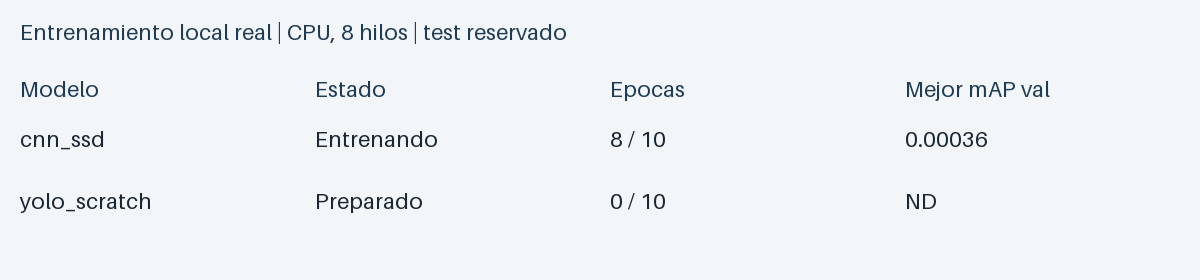

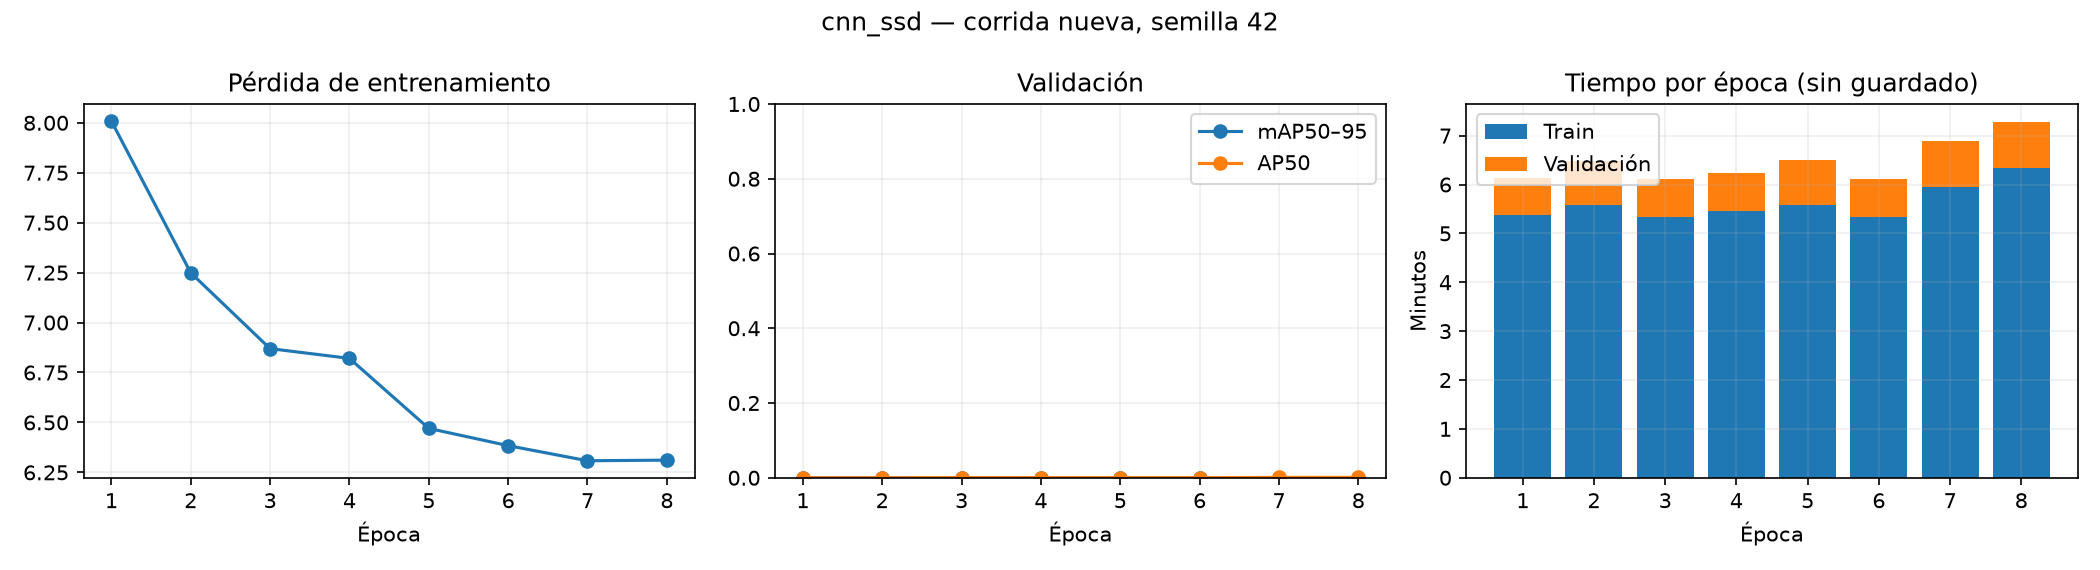

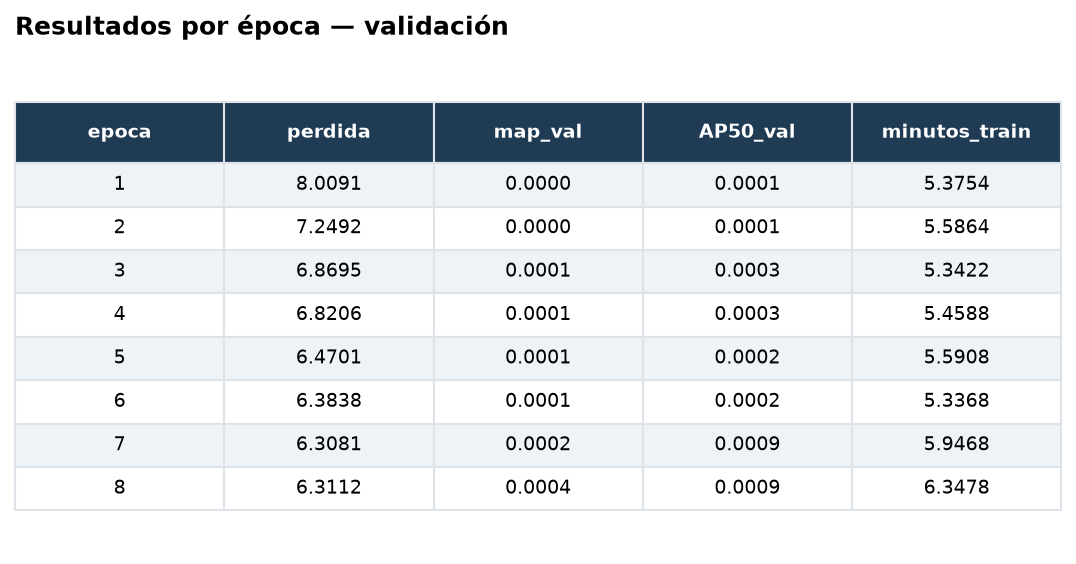

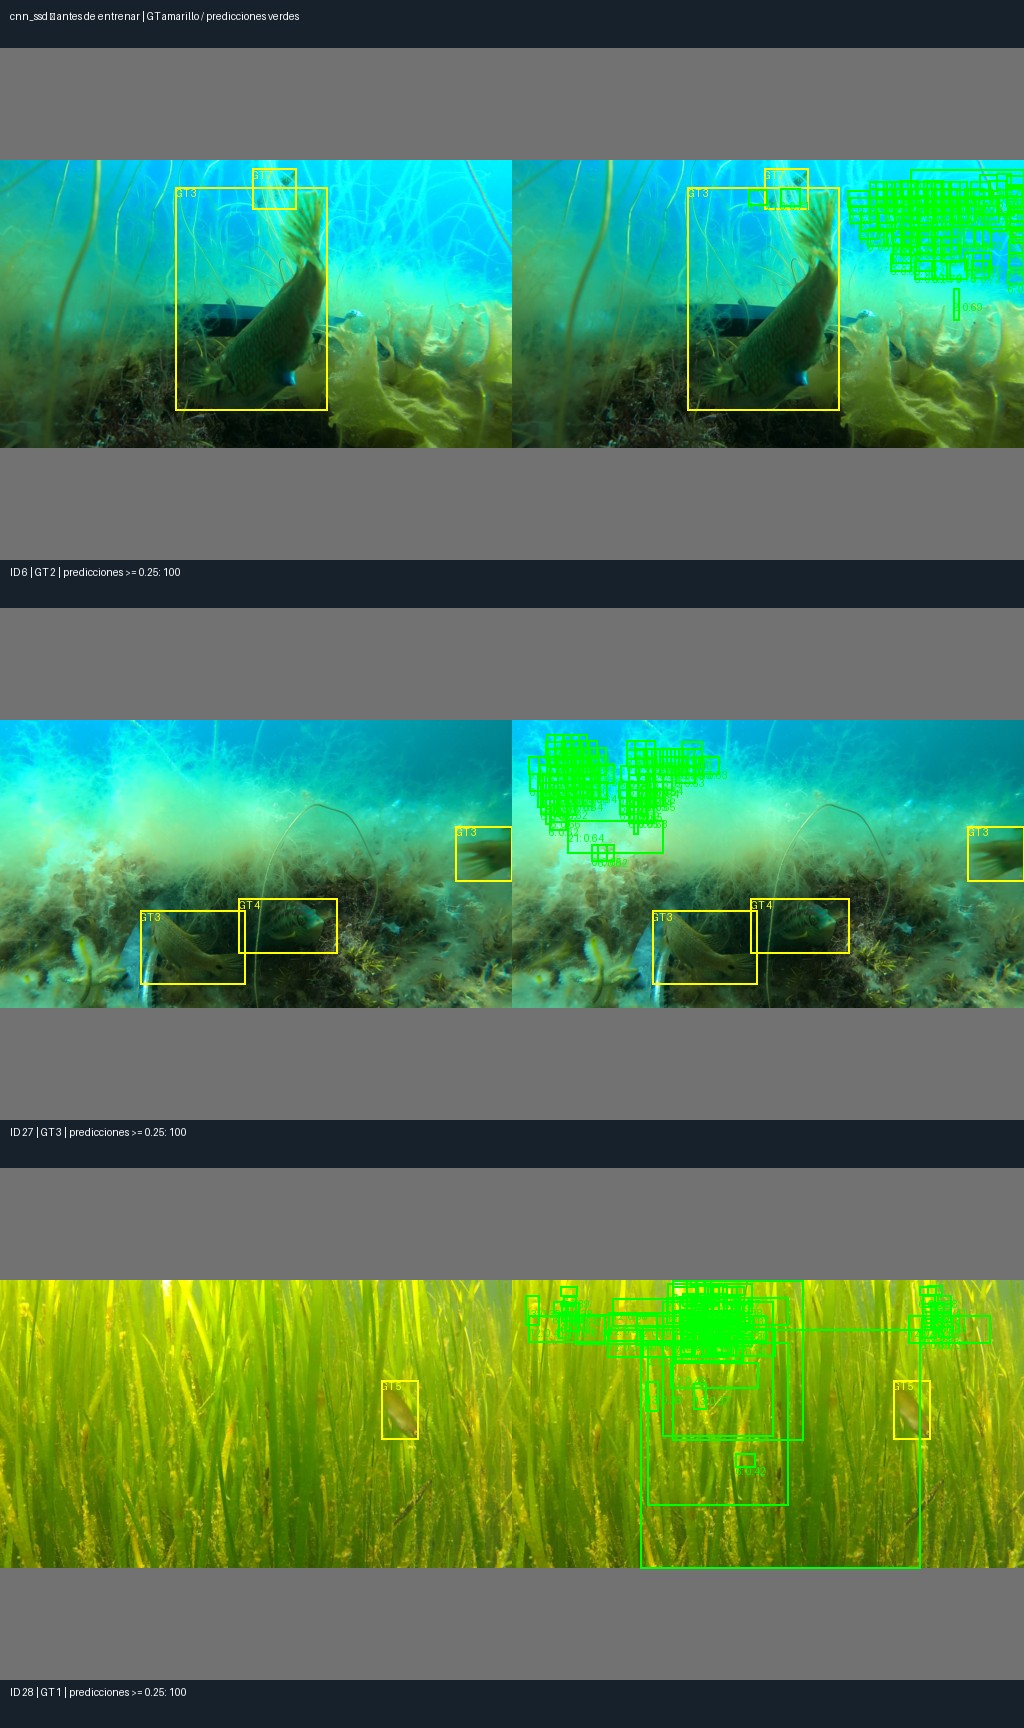

In [ ]:
if EJECUTAR_ENTRENAMIENTO_LOCAL:
    entrenar_local_cpu(
        MODELOS_LOCALES,
        reporte_auditoria,
        manifiesto,
        estadisticas_train,
        RAIZ_ESTUDIO,
        hilos=HILOS_CPU,
    )
display(
    Image.open(
        ver_avance_local(
            RAIZ_ESTUDIO, reporte_auditoria, manifiesto, estadisticas_train
        )
    )
)
for nombre in MODELOS_LOCALES:
    fuente = RAIZ_ESTUDIO / "parte1_nueva/experimentos" / nombre
    trabajo = ruta_legado(RAIZ_ESTUDIO, nombre)
    for imagen in (
        fuente / "curvas_nueva.png",
        fuente / "tabla_epocas.png",
        fuente / "antes.jpg",
        trabajo / "despues_mejor.jpg",
    ):
        if imagen.is_file():
            display(Image.open(imagen))
if PREPARAR_PARTE1_NUEVA or ENTRENAR_PARTE1_NUEVA:
    RUTA_APORTE_IGNACIO = preparar_parte1_nueva(
        reporte_auditoria, manifiesto, estadisticas_train, RAIZ_ESTUDIO
    )
    print("Corridas nuevas declaradas con entorno real:", RUTA_APORTE_IGNACIO)
if ENTRENAR_PARTE1_NUEVA:
    ejecutar_parte1_nueva(
        MODELOS_NUEVOS_PARTE1,
        reporte_auditoria,
        manifiesto,
        estadisticas_train,
        RAIZ_ESTUDIO,
    )
    for nombre in MODELOS_NUEVOS_PARTE1:
        fuente = RUTA_APORTE_IGNACIO / "experimentos" / nombre
        trabajo = ruta_legado(RAIZ_ESTUDIO, nombre)
        for imagen in (
            fuente / "curvas_nueva.png",
            fuente / "tabla_epocas.png",
            fuente / "antes.jpg",
            trabajo / "despues_mejor.jpg",
        ):
            if imagen.is_file():
                display(Image.open(imagen))
if IMPORTAR_CONTRATO_DATOS:
    importar_contrato_datos(
        RUTA_APORTE_IGNACIO,
        reporte_auditoria,
        manifiesto,
        estadisticas_train,
        RAIZ_ESTUDIO,
    )
    print("Contrato pequeño validado; los checkpoints pueden importarse después.")
if IMPORTAR_IGNACIO:
    importacion_ignacio = importar_aporte_ignacio(
        RUTA_APORTE_IGNACIO,
        reporte_auditoria,
        manifiesto,
        estadisticas_train,
        RAIZ_ESTUDIO,
    )
    print(
        {
            n: {k: r[k] for k in ("ultima_epoca", "mejor_epoca", "completo")}
            for n, r in importacion_ignacio.items()
        }
    )
else:
    print(
        "Importación desactivada. Se conservan los aportes ya importados, si existen."
    )

if REANUDAR_IGNACIO:
    continuacion_ignacio = reanudar_aporte_ignacio(
        MODELOS_LEGADO_A_REANUDAR,
        reporte_auditoria,
        manifiesto,
        estadisticas_train,
        RAIZ_ESTUDIO,
    )
    print({n: r["ultima_epoca"] for n, r in continuacion_ignacio.items()})
else:
    print(
        "Continuación histórica desactivada. No se ejecutan entrenamientos de Ignacio."
    )

pendientes_aportes = pendientes_integracion(RAIZ_ESTUDIO, RUTA_APORTE_IGNACIO)
display(
    Markdown(
        "**Pendientes de integración:**\n\n"
        + (
            "\n".join("- " + p for p in pendientes_aportes)
            or "Aportes disponibles; revisar evaluación final."
        )
    )
)
# Diagnóstico local: informa CUDA real sin afirmar que CPU haya aprobado las pruebas GPU.
comprobacion_gpu_actual = verificar_gpu_corridas(RAIZ_ESTUDIO, exigir=False)
display(
    Image.open(
        tabla_visual(
            [
                dict(
                    comprobacion="CUDA + backward + NMS",
                    resultado=comprobacion_gpu_actual["cuda"],
                ),
                dict(
                    comprobacion="Actualización AMP real",
                    resultado=comprobacion_gpu_actual["amp"],
                ),
                dict(
                    comprobacion="Dispositivo",
                    resultado=comprobacion_gpu_actual["dispositivo"],
                ),
            ],
            RAIZ_ESTUDIO / "evidencias/tabla_gpu.png",
            "Comprobación del entorno actual",
        )
    )
)

## 9. Perfil GPU, configuración definitiva y entrenamientos nativos

1. Importar el contrato pequeño de Ignacio en la sección anterior. No esperar los checkpoints grandes.
2. Activar `EJECUTAR_PERFIL_GPU`: mide cuatro fases completas (dos modelos COCO × frozen/finetune),
   con AMP, validación, métricas y guardado. No fija todavía el protocolo.
3. Revisar la tabla propuesta. Ajustar solo épocas, horas o criterios de parada en `CONFIGURACIONES_BASE`
   permite reutilizar el perfil. Otros cambios de recursos, datos, código o software exigen medir nuevamente.
4. Activar `CERRAR_PROTOCOLO` y ejecutar la celda de cierre. Desde ese momento conservar código,
   configuración y software. Los textos en Markdown y los interruptores pueden cambiar.
5. Crear una plantilla en `RAIZ_WORKER` para cada integrante. No escribir dos sesiones en el mismo worker.
   En las sesiones de entrenamiento usar `ROL_SESION = "worker"` y el nombre correspondiente;
   así sus informes y registros tampoco escriben en la carpeta central.
6. Activar el entrenamiento del modelo asignado. Las sesiones de dos horas guardan y pausan;
   para continuar hay que ejecutar la celda nuevamente. Copiar la carpeta recién cuando esté pausada o terminada.
7. El coordinador importa cada carpeta con el importador y mantiene el registro común.

El batch físico común nativo es 2 o 1, con acumulación hasta 8. El batch histórico sigue siendo 2.
YOLO COCO tiene un máximo de 20 épocas y Faster R-CNN de 15, con cinco congeladas, seis horas,
paciencia cinco desde la época diez. La tabla del perfil reduce el máximo si el tiempo no alcanza.
No se inicia un presupuesto que no permita al menos diez épocas y ambas fases.


### 9.1 Medir y revisar, antes de congelar

La propuesta usa `épocas = min(tope, congeladas + floor((0,9 × 3600 × horas − congeladas × segundos_frozen) / segundos_finetune))`.
Todas las duraciones están en segundos. La calibración incluye guardados conservadores y no conserva
sus pesos como resultado experimental. Si falta GPU o el contrato, esta etapa permanece pendiente.


In [ ]:
perfil_gpu = propuesta_configuraciones = None
if EJECUTAR_PERFIL_GPU:
    perfil_gpu = perfilar_estudio(CONFIGURACIONES_BASE, *CONTEXTO_EVALUACION)
elif (RAIZ_ESTUDIO / "recursos.json").is_file():
    perfil_gpu = leer_json(RAIZ_ESTUDIO / "recursos.json")
if perfil_gpu is not None:
    propuesta_configuraciones, tabla_presupuesto = proponer_configuraciones(
        CONFIGURACIONES_BASE, perfil_gpu
    )
    display(tabla_presupuesto)
else:
    print("Perfil GPU pendiente: no se congela ni se inicia ninguna corrida.")

### 9.2 Cerrar y distribuir la plantilla

Revisar primero la tabla anterior. Esta celda exige el perfil compatible y no recalibra.
Cada integrante recibe el mismo notebook, protocolo, recursos y contrato de datos,
pero sus checkpoints se escriben en una carpeta propia. Al abrir la sesión asignada,
usar `ROL_SESION = "worker"`. Consolidar preferentemente corridas terminadas;
el importador no reemplaza una copia central por una versión posterior diferente.


In [ ]:
if CERRAR_PROTOCOLO:
    CONFIGURACIONES = cerrar_protocolo_estudio(
        CONFIGURACIONES_BASE, *CONTEXTO_EVALUACION
    )
    print("Protocolo cerrado:", RAIZ_ESTUDIO / "protocolo_estudio.json")
if CREAR_PLANTILLA_WORKER:
    print(
        "Worker preparado:",
        copiar_plantilla_worker(
            RAIZ_ESTUDIO, RAIZ_WORKER, reporte_auditoria, manifiesto, estadisticas_train
        ),
    )

In [ ]:
# Entrenar siempre en un worker independiente; conserva la plantilla y el mismo notebook.
if EJECUTAR_ENTRENAMIENTOS:
    if RUTA_PERSISTENTE is None:
        raise RuntimeError("Define RUTA_PERSISTENTE disponible en el entorno CUDA")
    CONFIGURACIONES = preparar_estudio(
        CONFIGURACIONES_BASE,
        reporte_auditoria,
        manifiesto,
        estadisticas_train,
        PESOS_DIR,
        RAIZ_WORKER,
    )
    ejecutar_modelos(
        CONFIGURACIONES,
        MODELOS_A_EJECUTAR,
        reporte_auditoria,
        manifiesto,
        estadisticas_train,
        PESOS_DIR,
        RAIZ_WORKER,
        limite_sesion_horas=LIMITE_SESION_HORAS,
    )
    print("Al pausar, vuelve a ejecutar esta celda para retomar; no se reinicia sola.")

# Solo el coordinador consolida. No editar ni volver a entrenar una carpeta ya importada.
if IMPORTAR_CORRIDAS_NATIVAS:
    if not RUTAS_WORKERS_A_IMPORTAR:
        raise ValueError("Indica las carpetas worker a consolidar")
    for worker in RUTAS_WORKERS_A_IMPORTAR:
        for nombre, cfg in CONFIGURACIONES.items():
            if (
                cfg.get("origen") != "ignacio_v1"
                and (Path(worker) / "entrenamientos" / cfg["etiqueta"]).is_dir()
            ):
                print(
                    importar_corrida_nativa(
                        worker,
                        nombre,
                        reporte_auditoria,
                        manifiesto,
                        estadisticas_train,
                        RAIZ_ESTUDIO,
                    )
                )
registro_modelos = actualizar_registro_integrado(
    RAIZ_ESTUDIO, reporte_auditoria, manifiesto, estadisticas_train
)
reportes_principales = cargar_reportes(
    CONFIGURACIONES, RAIZ_ESTUDIO, reporte_auditoria, manifiesto, estadisticas_train
)
if reportes_principales:
    for grafico in graficar_entrenamientos(
        CONFIGURACIONES, RAIZ_ESTUDIO, reportes_principales
    ):
        display(Image.open(grafico))
    display(Markdown(analisis_entrenamientos(reportes_principales)))
else:
    print(
        "Pendiente: consolidar los entrenamientos principales; los pilotos no los reemplazan."
    )

display(
    Image.open(
        tablero_corridas(
            CONFIGURACIONES,
            RAIZ_ESTUDIO,
            reporte_auditoria,
            manifiesto,
            estadisticas_train,
        )
    )
)

## 10. Cerrar validación y comparar en test

Se exigen los cuatro entrenamientos. Primero se reproduce la validación de Ignacio con
batch 2; después todos usan batch 1 y coordenadas originales. Checkpoints, umbrales y
ganador se fijan con validación antes del test integrado. Si la exportación registra test
consultado anteriormente, debe declararse esa limitación.

Se generan P/R/F1, AP50, mAP50–95, soporte y errores por clase, ocho ejemplos y latencia
en una misma GPU. Los regímenes y alcances de tiempo difieren; no es una ablación causal
del preentrenamiento. Una semilla permite comparación descriptiva, no significancia estadística.


In [ ]:
cierre_principal = comparacion_principal = latencia_principal = None
if EJECUTAR_COMPARACION:
    cierre_principal = cerrar_configuraciones(
        CONFIGURACIONES, *CONTEXTO_EVALUACION, dispositivo="cuda"
    )
    comparacion_principal = evaluar_comparacion(
        cierre_principal, *CONTEXTO_EVALUACION, dispositivo="cuda"
    )
    display(
        exportar_metricas_tamano(comparacion_principal, RAIZ_ESTUDIO / "comparacion")
    )
    latencia_principal = medir_comparacion(
        cierre_principal, *CONTEXTO_EVALUACION, dispositivo="cuda"
    )
    display(
        Image.open(
            graficar_comparacion(comparacion_principal, RAIZ_ESTUDIO / "comparacion")
        )
    )
    texto_comparacion, graficos_extra = completar_comparacion(
        cierre_principal,
        comparacion_principal,
        reporte_auditoria,
        manifiesto,
        latencia_principal,
        RAIZ_ESTUDIO,
    )
    for grafico in graficos_extra:
        display(Image.open(grafico))
    display(Markdown(texto_comparacion))
else:
    print("Comparación pendiente o desactivada; esta celda no consulta test.")
if comparacion_principal is not None:
    filas_metricas = leer_json(RAIZ_ESTUDIO / "comparacion/tabla_comparativa.json")
    display(
        Image.open(
            tabla_visual(
                filas_metricas,
                RAIZ_ESTUDIO / "comparacion/tabla_metricas.png",
                "Comparación común en test",
                [
                    "modelo",
                    "map_50_95",
                    "ap_50",
                    "precision",
                    "recall",
                    "f1",
                    "epocas",
                    "horas",
                ],
            )
        )
    )
    for nombre in comparacion_principal:
        display(Image.open(RAIZ_ESTUDIO / f"comparacion/{nombre}_ejemplos.jpg"))

## 11. Robustez y análisis sustentado

Mismos pesos, IDs, cajas y umbral: limpio más seis degradaciones (luz, desenfoque y ruido,
dos intensidades cada una), sin recalibrar. El modelo principal es el ganador de validación.
Si otro lidera test, su análisis queda separado. Las caídas, soportes y ejemplos pareados
permiten sustentar hipótesis sin atribuir mecanismos que las métricas no demuestran.


In [ ]:
robustez_principal = robustez_secundaria = None
if EJECUTAR_ROBUSTEZ:
    cierre_principal = cierre_principal or leer_json(
        RAIZ_ESTUDIO / "comparacion/configuraciones_cerradas.json"
    )
    comparacion_principal = comparacion_principal or {
        n: leer_json(RAIZ_ESTUDIO / f"comparacion/{n}_test.json")
        for n in cierre_principal["modelos"]
    }
    for nombre in modelos_robustez(cierre_principal, comparacion_principal):
        resumen = evaluar_robustez(
            cierre_principal, *CONTEXTO_EVALUACION, dispositivo="cuda", modelo=nombre
        )
        if nombre == cierre_principal["ganador_validacion"]:
            robustez_principal = resumen
        else:
            robustez_secundaria = resumen
        display(
            Image.open(
                ruta_robustez(RAIZ_ESTUDIO, cierre_principal, nombre)
                / "sensibilidad.png"
            )
        )
        display(Markdown(analisis_robustez(resumen)))
else:
    print(
        "Robustez pendiente o desactivada; requiere comparación limpia y cierre verificado."
    )
if robustez_principal is not None:
    carpeta = ruta_robustez(
        RAIZ_ESTUDIO, cierre_principal, robustez_principal["modelo"]
    )
    display(
        Image.open(
            tabla_visual(
                robustez_principal["condiciones"],
                carpeta / "tabla_robustez.png",
                "Robustez: mismos pesos y umbral",
                [
                    "condicion",
                    "map_50_95",
                    "ap_50",
                    "f1",
                    "caida_puntos",
                    "caida_relativa",
                ],
            )
        )
    )
    for condicion in condiciones_robustez()[1:]:
        display(Image.open(carpeta / f"{nombre_condicion(condicion)}_ejemplos.jpg"))

## 12. Reproducción, rúbrica y paquete técnico

La reproducción recalcula val/test en un proceso nuevo desde este archivo y los checkpoints.
La matriz indica evidencia disponible y pendiente; no asigna nota. El ZIP requiere cuatro
corridas reales, pruebas CUDA y reproducción aprobadas, nombres y declaración completos.
Incluye fuentes, manifiestos, estadísticas activas, métricas e integridad; excluye el dataset
de 6 GB y la preparación de diapositivas/video.


In [ ]:
if EJECUTAR_REPRODUCCION:
    reproduccion_final = verificar_reproduccion(
        *CONTEXTO_EVALUACION, proyecto=BASE_DIR, dispositivo="cuda"
    )
    print("Reproducción en proceso nuevo:", reproduccion_final["passed"])
if (
    cierre_principal is None
    and (RAIZ_ESTUDIO / "comparacion/configuraciones_cerradas.json").is_file()
):
    cierre_principal = leer_json(
        RAIZ_ESTUDIO / "comparacion/configuraciones_cerradas.json"
    )
estado_cierre = auditar_cierre_tecnico(
    CONFIGURACIONES,
    reporte_auditoria,
    manifiesto,
    estadisticas_train,
    RAIZ_ESTUDIO,
    reporte_pruebas_nuevas,
    entorno,
    cierre_principal,
)
display(
    Markdown(
        "| Criterio | Máximo | Evidencia |\n|---|---:|---|\n"
        + "\n".join(
            f"| {r['id']}: {r['criterio']} | {r['puntos_maximos']} | {r['estado']} |"
            for r in estado_cierre["filas"]
        )
    )
)
print("Cierre técnico completo:", estado_cierre["cierre_tecnico_completo"])
print("Pruebas CUDA completas:", estado_cierre["pruebas_cuda_completas"])

In [ ]:
paquete_tecnico = None
if EJECUTAR_EMPAQUETADO:
    paquete_tecnico = preparar_paquete_tecnico(
        estado_cierre,
        CONFIGURACIONES,
        reporte_auditoria,
        manifiesto,
        RAIZ_ESTUDIO,
        BASE_DIR,
        INTEGRANTES,
        DECLARACION_IA,
        estadisticas=estadisticas_train,
    )
    print(json.dumps(paquete_tecnico, indent=2, ensure_ascii=False))
else:
    print(
        "Empaquetado final desactivado. Diapositivas y video se prepararán en otra etapa."
    )

## 13. Estado final y siguiente paso

El resumen diferencia implementación, diagnósticos y resultados reales. Los faltantes se
muestran explícitamente: importar lo que efectivamente completó Ignacio, terminar COCO,
evaluar, analizar y verificar en CUDA. Conservar el mismo código al repartir las corridas;
una modificación experimental exige otro estudio y sus propias identidades.


In [ ]:
# El resumen distingue resultados disponibles, pilotos reutilizados y verificación real de GPU.
estado = {
    "dataset_images": reporte_auditoria["summary"]["images"],
    "dataset_objects": reporte_auditoria["summary"]["objects"],
    "catalog_classes": NUM_CLASES,
    "audit_valid": reporte_auditoria["valid"],
    "partitions_verified": revisar_manifiesto(reporte_auditoria, manifiesto),
    "unit_tests_passed": pruebas_unitarias.wasSuccessful(),
    "integration_passed": reporte_smoke["passed"] if reporte_smoke else None,
    "real_pilots_available": list(reportes_piloto),
    "pilots_reused": {k: v.get("reused", False) for k, v in reportes_piloto.items()},
    "cnn_memorization_ap_improved": (
        memorizacion["ap_improved"] if memorizacion else None
    ),
    "device": DEVICE,
    "gpu_verified": entorno["gpu_test_passed"],
    "source_errors_recorded": len(auditoria_cruda["errors"]),
    "curation": {
        "recovered_labels": len(
            reporte_auditoria.get("curation", {}).get("recovered_labels", [])
        ),
        "quarantined_images": len(
            reporte_auditoria.get("curation", {}).get("excluded_images", [])
        ),
    },
    "warnings": reporte_auditoria["warnings"],
}
estado["partitions_fingerprint"] = manifiesto["partitions_fingerprint"]
guardar_json(REVISION / "estado.json", estado)
print(json.dumps(estado, indent=2, ensure_ascii=False))
if not entorno["gpu_test_passed"]:
    print("Pendiente: comprobar y repetir la integración en un equipo con CUDA.")

estado_etapas_3_5 = dict(
    implementacion="Disponible dentro de Tarea_2.ipynb",
    pruebas=reporte_pruebas_nuevas,
    cuda_verificada=bool(entorno["gpu_test_passed"]),
    entrenamientos_disponibles=list(reportes_principales),
    comparacion_ejecutada_en_esta_sesion=comparacion_principal is not None,
    robustez_ejecutada_en_esta_sesion=robustez_principal is not None,
    ruta_estudio=str(RAIZ_ESTUDIO),
    registro_modelos=str(RAIZ_ESTUDIO / "registro_modelos.json"),
    particiones=manifiesto["partitions_fingerprint"],
    cierre_tecnico_completo=estado_cierre["cierre_tecnico_completo"],
    evidencias_rubrica=str(RAIZ_ESTUDIO / "evidencias/estado_rubrica.json"),
    preparacion_audiovisual="Omitida por solicitud del usuario",
    pendientes=pendientes_integracion(RAIZ_ESTUDIO, RUTA_APORTE_IGNACIO),
)
guardar_json(RESULTADOS / "etapas_3_5/estado_implementacion.json", estado_etapas_3_5)
print(json.dumps(estado_etapas_3_5, indent=2, ensure_ascii=False))
# Preparación real pendiente: no confundir implementación ni fixtures con una GPU calibrada.
estado_fase1 = estado_correcciones_fase1(
    RAIZ_ESTUDIO,
    reporte_auditoria,
    manifiesto,
    estadisticas_train,
    CONFIGURACIONES_BASE,
)
guardar_json(RAIZ_ESTUDIO / "evidencias/estado_fase1.json", estado_fase1)
display(estado_fase1)

guardar_json(
    RAIZ_ESTUDIO / "evidencias/estado_fase2.json",
    dict(
        cuda_actual=comprobacion_gpu_actual["cuda"],
        amp_actual=comprobacion_gpu_actual["amp"],
        origen_parte1="corridas nuevas autorizadas; carpeta original perdida",
        modelos_registrados=list(reportes_principales),
        entrenamientos_principales_completos=all(
            registro_modelos["modelos"][n].get("completo", False) for n in KINDS
        ),
        codigo=huella_codigo_notebook(),
    ),
)

### Referencias y archivos que se conservan

Fundamento: contenidos de clases sobre convoluciones, gradiente/Adam, regularización,
train/val/test y transferencia; [FjordFish](https://zenodo.org/records/17950781),
[SSD](https://docs.pytorch.org/vision/stable/_modules/torchvision/models/detection/ssd.html),
[Faster R-CNN](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.fasterrcnn_resnet50_fpn.html),
[YOLO11](https://docs.ultralytics.com/models/yolo11/) y
[COCOeval](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py).

`data/extracted/` contiene los originales; `resultados_etapas_1_2/` conserva pesos, auditoría,
cachés y estudios. `.venv/`, `docs/`, los notebooks anteriores y el respaldo no son dependencias
del código. Las cuatro fuentes históricas están adjuntas como texto UTF-8 con SHA-256 en
`metadata.tarea2_legado`; `fuentes_legado_incluidas()` permite inspeccionarlas y la continuación
las materializa temporalmente. No se comprimen ni se oculta código activo dentro de cadenas.

**Validación de esta versión:** los casos aprobados, omitidos y el entorno se muestran en
las secciones de pruebas y en `evidencias/pruebas_fase1.json`. La calibración y el cierre se bloquean
si falta evidencia compatible. Las pruebas sintéticas y salidas de CPU no son resultados de entrenamiento.
El respaldo de esta intervención es `Tarea_2_respaldo_antes_fase1_20261103.ipynb`.

Las correcciones de fase 1 mantienen las fuentes históricas byte por byte en los metadatos.

Las nuevas corridas se identifican en `procedencia_corrida.json`, con fecha y motivo, sin atribuirles pesos anteriores.
